# Beyond F1: Does Higher Biomedical NLP Performance Imply Greater Robustness? A Perturbation-Based Benchmark Study of PubMed RCT Sentence Classification

This notebook implements a controlled and reproducible benchmark for sentence-role classification in PubMed randomised controlled trial (RCT) abstracts. Each sentence is classified into one of five rhetorical roles:

- Background
- Objective
- Methods
- Results
- Conclusions

The task is not treated as a simple leaderboard exercise. Sentence-role labels in structured biomedical abstracts depend on lexical content, abstract position, neighbouring sentences, and conventional reporting structure. The PubMed RCT benchmark was introduced specifically for sequential sentence classification in medical abstracts, making it suitable for testing both sentence-level and discourse-aware NLP methods (Dernoncourt & Lee, 2017). The clinical-trial reporting context also matters because RCT abstracts are shaped by structured reporting expectations and CONSORT-style conventions (Schulz et al., 2010).

---

## Research Questions

### Primary Research Question

> **Do biomedical sentence-classification models with higher independent-test Macro-F1 also demonstrate stronger robustness, consistency, and semantic sensitivity under controlled perturbation-based evaluation?**

This question tests whether conventional held-out performance is sufficient to characterise model quality, or whether models with similar Macro-F1 can behave differently under targeted linguistic changes. The rationale follows work arguing that NLP evaluation should include behavioural tests rather than only aggregate accuracy (Ribeiro et al., 2020), and that modern machine-learning systems with similar in-distribution performance can remain underspecified and behave differently outside the exact benchmark condition (D'Amour et al., 2022).

### Sub-question 1: Overall Predictive Performance

**Which model family achieves the strongest independent-test performance for classifying PubMed RCT sentences into Background, Objective, Methods, Results, and Conclusions?**

Literature support: The PubMed RCT benchmark was designed for medical abstract sentence classification, so independent-test performance on the fixed split is the core task outcome (Dernoncourt & Lee, 2017). Macro-F1 is emphasised because point-estimate rankings should be interpreted with attention to class-wise performance and uncertainty rather than treated as definitive state-of-the-art claims (Bestgen, 2022).

### Sub-question 2: Discourse Structure and Sentence Context

**Do sentence-position features, sequence modelling, and previous-sentence context improve classification compared with sentence-level lexical models?**

Literature support: PubMed RCT abstracts have sequential rhetorical structure, and CONSORT-style reporting conventions make sentence location and neighbouring context plausible sources of signal (Dernoncourt & Lee, 2017; Schulz et al., 2010). Sequence models such as CRFs and BiLSTM-style models are therefore methodologically relevant because they can model label transitions and contextual dependencies (Lafferty et al., 2001; Huang et al., 2015).

### Sub-question 3: Perturbation-based Behavioural Reliability

**Do higher-performing models also show greater prediction stability under intended label-preserving perturbations and appropriate sensitivity under negation perturbation?**

Literature support: Behavioural testing frameworks such as CheckList argue that aggregate accuracy can miss failures under targeted linguistic changes (Ribeiro et al., 2020). Underspecification research also shows that models with similar benchmark performance may implement different decision rules, supporting a robustness analysis beyond Macro-F1 (D'Amour et al., 2022).

### Sub-question 4: Statistical Reliability and Cross-scale Verification

**Are observed performance and behavioural differences statistically reliable, and do the main patterns remain consistent in a larger PubMed RCT 200k cross-scale verification layer?**

Literature support: Bootstrap confidence intervals and paired resampling support more cautious interpretation of model rankings than single point estimates (Efron & Tibshirani, 1993; Bestgen, 2022). Holm adjustment is used for multiple pre-specified comparisons, and the PubMed RCT 200k benchmark provides a larger related corpus for cross-scale verification (Holm, 1979; Dernoncourt & Lee, 2017).

### Sub-question 5: Practical Deployment Cost

**Does the strongest-performing model also offer the most favourable computational-efficiency profile?**

Literature support: Classical sparse models, shallow neural text classifiers, PyTorch sequence models, and transformer fine-tuning have different computational profiles, so runtime, memory, model size, and reproducibility cost are relevant to practical interpretation (Joulin et al., 2017; Pedregosa et al., 2011; Paszke et al., 2019; Wolf et al., 2020).

---

## Hypotheses

### Primary Hypothesis

Model quality in PubMed RCT sentence-role classification is not fully captured by aggregate Macro-F1. Transformer-based biomedical language models are expected to achieve strong independent-test performance, but discourse-aware features, local context, perturbation behaviour, statistical uncertainty, and computational cost are expected to change the practical interpretation of model quality. This hypothesis is grounded in behavioural NLP evaluation and underspecification work, with uncertainty-aware reporting used to avoid overclaiming small performance differences (Ribeiro et al., 2020; D'Amour et al., 2022; Bestgen, 2022).

### Hypothesis 1: Model Architecture

Biomedical and scientific transformers, particularly PubMedBERT/BiomedBERT and SciBERT, are expected to outperform most classical lexical baselines because they use pretrained contextual representations learned from biomedical or scientific corpora (Beltagy et al., 2019; Gu et al., 2021). However, strong sparse baselines such as TF-IDF logistic regression and linear SVMs remain necessary comparators because classical high-dimensional text classifiers can be competitive and interpretable (Salton & Buckley, 1988; Joachims, 1998; Pedregosa et al., 2011).

### Hypothesis 2: Discourse and Context

Sentence-position features, sequence modelling, and previous-sentence transformer inputs are expected to improve classification because structured RCT abstracts usually follow a rhetorical progression from background and objective statements through methods, results, and conclusions (Dernoncourt & Lee, 2017; Schulz et al., 2010). CRFs and BiLSTM-style models are expected to capture part of this structure by modelling neighbouring label dependencies and bidirectional sentence context (Lafferty et al., 2001; Hochreiter & Schmidhuber, 1997; Huang et al., 2015).

### Hypothesis 3: Behavioural Robustness and Sensitivity

Higher Macro-F1 is not expected to guarantee higher behavioural reliability. Numeric, paraphrase, structure, and negation perturbations may reveal differences in prediction stability or semantic sensitivity that are hidden by aggregate test metrics, consistent with behavioural testing and underspecification arguments (Ribeiro et al., 2020; D'Amour et al., 2022).

### Hypothesis 4: Negation Interpretation

Automatic negation perturbation is expected to reveal differences in semantic sensitivity across model families, but the automatic negation gap is not interpreted as direct correctness. Correctness under negation requires manually assigned expected labels because negation can alter sentence meaning and may alter the expected rhetorical role; this distinction follows capability-testing principles and avoids overstating automatic stress-test results (Ribeiro et al., 2020; D'Amour et al., 2022).

### Hypothesis 5: Statistical Reliability and Cross-scale Verification

Observed model differences are expected to require uncertainty-aware interpretation. Bootstrap intervals, paired bootstrap comparisons, Holm-adjusted pre-specified negation-gap tests, and 20k-versus-200k verification are expected to clarify whether apparent performance and robustness differences are stable enough to support substantive claims (Efron & Tibshirani, 1993; Holm, 1979; Bestgen, 2022; Dernoncourt & Lee, 2017).

### Hypothesis 6: Deployment Trade-off

The highest-performing model is not necessarily expected to be the most practical model. Transformer models may improve Macro-F1 at greater computational cost, while classical or position-aware models may offer more favourable performance-efficiency trade-offs; this hypothesis is supported by the contrast between efficient shallow/classical text classifiers and heavier neural or transformer software stacks (Joulin et al., 2017; Pedregosa et al., 2011; Paszke et al., 2019; Wolf et al., 2020).

---

## Evaluation Philosophy

Model quality is assessed across five complementary dimensions.

### 1. Predictive Performance

Macro-F1 is the primary metric because the label distribution is imbalanced and minority classes, especially Objective, should not be hidden by frequent classes such as Methods and Results. Accuracy and weighted-F1 are reported as secondary measures, and per-class precision, recall, and F1 are used to identify class-specific weaknesses (Dernoncourt & Lee, 2017; Bestgen, 2022).

### 2. Discourse-aware Generalisation

The benchmark tests whether sentence-role classification benefits from abstract-level structure and local context. Position-aware logistic regression tests whether simple structural metadata improves a sparse lexical model. CRF and BiLSTM-style systems test whether label sequence information is useful. Previous-sentence transformer inputs test whether local discourse context improves contextual language models (Dernoncourt & Lee, 2017; Lafferty et al., 2001; Huang et al., 2015).

### 3. Behavioural Reliability and Perturbation Sensitivity

Perturbation tests evaluate how predictions change under controlled input transformations:

| Perturbation | Interpretation |
|---|---|
| Numeric perturbation | Intended label-preserving stability under quantitative variation |
| Paraphrase perturbation | Intended lexical invariance under meaning-preserving rewording |
| Structure perturbation | Exploratory structural robustness, subject to manual validation |
| Negation perturbation | Semantic-sensitivity stress test; direct correctness only with manual expected labels |

This distinction is essential. Numeric and paraphrase tests support invariance claims only after manual audit. Structure perturbation is reported cautiously because clause reordering may change grammar, emphasis, or rhetorical role. Negation is not treated as a standard invariance test because it may change the expected label (Ribeiro et al., 2020; D'Amour et al., 2022).

### 4. Statistical Reliability

The notebook evaluates whether observed differences are stable rather than random variation. Bootstrap confidence intervals quantify uncertainty around final Macro-F1. Paired bootstrap comparisons compare models on the same independent test examples. Holm-adjusted paired tests are used for pre-specified automatic negation-gap comparisons. Manual-audited negation correctness is analysed separately when human expected labels are available (Efron & Tibshirani, 1993; Bestgen, 2022; Holm, 1979).

### 5. Cross-scale and Deployment Feasibility

The PubMed RCT 200k layer evaluates whether the 20k findings remain informative at larger scale. Protocol comparability is documented to avoid overclaiming when model families use different training budgets. Computational-efficiency analysis records training time, inference speed, memory use, model size, and parameter count (Dernoncourt & Lee, 2017; Wolf et al., 2020; Paszke et al., 2019).

---

## Expected Contribution

This notebook contributes more than a model ranking. It provides a reproducible benchmark framework that combines:

| Dimension | Purpose |
|---|---|
| Independent-test performance | Estimates standard predictive quality |
| Class-wise performance | Identifies label-specific weaknesses |
| Statistical uncertainty | Tests whether differences are stable |
| Perturbation behaviour | Evaluates robustness and semantic sensitivity |
| Manual audit | Validates perturbation interpretation |
| Cross-scale verification | Checks whether patterns persist at larger scale |
| Computational efficiency | Assesses practical cost and reproducibility burden |

The central conclusion is framed conservatively:

> **Higher Macro-F1 does not automatically imply uniformly stronger behavioural reliability. Biomedical NLP benchmarks should evaluate performance, uncertainty, perturbation response, manual validity, cross-scale stability, and computational feasibility together.**


## 1. Google Colab and Google Drive setup

This section prepares Colab and preserves the original PubMed RCT split so that later modelling choices do not leak development or test information into training (Dernoncourt & Lee, 2017).

This section prepares the Colab execution environment and checks that the PubMed RCT data files are available in Google Drive. The expected files are:

- `train.txt`
- `dev.txt`
- `test.txt`

The expected line format is:

```text
PubMedID<TAB>label<TAB>text
```

The original train/development/test split is preserved because the PubMed RCT benchmark is designed for fixed-split sentence classification. Preserving this split avoids accidental leakage from development or test data into model fitting and keeps the evaluation aligned with the original dataset design (Dernoncourt & Lee, 2017).


In [ ]:
import os
import re
import json
import math
import random
import warnings
from collections import Counter, defaultdict
from typing import List, Dict, Tuple, Optional

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    IN_COLAB = True
except Exception:
    IN_COLAB = False

def mount_and_check_drive():
    if IN_COLAB:
        print("Running in Google Colab. Mounting Google Drive...")
        drive.mount('/content/drive')
    else:
        print("Not running in Google Colab. Skipping Google Drive mount.")

mount_and_check_drive()

DATA_DIR = "/content/drive/MyDrive/"

train_path = f"{DATA_DIR}/train.txt"
dev_path   = f"{DATA_DIR}/dev.txt"
test_path  = f"{DATA_DIR}/test.txt"

def check_required_files(paths):
    print("Checking dataset files...")
    ok = True
    for p in paths:
        exists = os.path.exists(p)
        print(f"  {'OK' if exists else 'MISSING'}: {p}")
        if not exists:
            ok = False
    if not ok:
        print("\nPlease update DATA_DIR so that train.txt, dev.txt, and test.txt can be found.")
    return ok

FILES_OK = check_required_files([train_path, dev_path, test_path])

Running in Google Colab. Mounting Google Drive...
Mounted at /content/drive
Checking dataset files...
  OK: /content/drive/MyDrive//train.txt
  OK: /content/drive/MyDrive//dev.txt
  OK: /content/drive/MyDrive//test.txt


## 2. Configuration, reproducibility, and package setup

This section defines the configuration before running experiments so that model selection, debug runs, and final evaluation remain reproducible and auditable (Kohavi, 1995; Pedregosa et al., 2011).

This section defines the execution configuration before any experiment is run. The configuration separates fast development checks from full publication-oriented runs and records the key settings that affect reproducibility.

### 2.1 Debug mode logic

- `DEBUG_SMALL_MODE = True`: use smaller train/development subsets for rapid development and code checking.
- `DEBUG_SMALL_MODE = False`: use the full configured train/development data for the main experimental run.

### 2.2 Evaluation logic

The classical-model workflow uses stratified cross-validation within the training split because it gives a more stable estimate than a single arbitrary train/development comparison, especially when classes are imbalanced (Kohavi, 1995). Hyperparameters are tuned inside the training split, the development split is used as a sanity check, and the independent test set is reserved for one final evaluation.

Sequential and transformer models are evaluated with a fixed development split because repeated K-fold retraining is computationally expensive for these architectures. This is a pragmatic design choice, not a claim that hold-out evaluation is statistically superior. Where computationally feasible, repeated seeds can be used to assess variance.


In [ ]:
# ============================================================
# PUBLICATION LOCK CONFIGURATION
# ============================================================
# This cell must be run before all experiments.
# It removes ambiguity between debug and final publication runs.
# ============================================================

import os
import random
import numpy as np

PUBLICATION_RUN = True

SEED = 42

if PUBLICATION_RUN:
    DEBUG_SMALL_MODE = False

    # Use full primary PubMed RCT 20k train/dev/test splits.
    TRAIN_FRAC = 1.00
    DEV_FRAC = 1.00
    SEQ_TRAIN_ABSTRACT_FRAC = 1.00
    SEQ_DEV_ABSTRACT_FRAC = 1.00

    # Transformer caps
    # Set to None for full training. If runtime prevents full training,
    # explicitly report these caps in the protocol table.
    MAX_TRANSFORMER_TRAIN = None
    MAX_TRANSFORMER_DEV = None
    MAX_TRANSFORMER_TEST = None

    # Model switches
    RUN_CLASSICAL_CV = True
    RUN_CLASSICAL_GRIDSEARCH = True
    RUN_CRF = True
    RUN_BILSTM_STYLE = True
    RUN_TRANSFORMERS = True

    # Training settings
    N_FOLDS_CV = 5
    TRANSFORMER_EPOCHS_FINAL = 2
    TRANSFORMER_BATCH_SIZE = 8
    BILSTM_EPOCHS_FINAL = 5
    BILSTM_BATCH_SIZE = 8

else:
    DEBUG_SMALL_MODE = True

    TRAIN_FRAC = 0.10
    DEV_FRAC = 0.20
    SEQ_TRAIN_ABSTRACT_FRAC = 0.10
    SEQ_DEV_ABSTRACT_FRAC = 0.20

    MAX_TRANSFORMER_TRAIN = 3000
    MAX_TRANSFORMER_DEV = 1000
    MAX_TRANSFORMER_TEST = None

    RUN_CLASSICAL_CV = True
    RUN_CLASSICAL_GRIDSEARCH = True
    RUN_CRF = True
    RUN_BILSTM_STYLE = True
    RUN_TRANSFORMERS = True

    N_FOLDS_CV = 5
    TRANSFORMER_EPOCHS_FINAL = 1
    TRANSFORMER_BATCH_SIZE = 8
    BILSTM_EPOCHS_FINAL = 3
    BILSTM_BATCH_SIZE = 8

CV_SHUFFLE = True
CV_RANDOM_STATE = SEED
REPORT_FOLD_CONFUSIONS = True

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)

    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        # deterministic setting where possible
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    except Exception:
        pass

set_seed(SEED)

print("PUBLICATION_RUN =", PUBLICATION_RUN)
print("DEBUG_SMALL_MODE =", DEBUG_SMALL_MODE)
print("SEED =", SEED)
print("TRAIN_FRAC =", TRAIN_FRAC)
print("DEV_FRAC =", DEV_FRAC)
print("SEQ_TRAIN_ABSTRACT_FRAC =", SEQ_TRAIN_ABSTRACT_FRAC)
print("SEQ_DEV_ABSTRACT_FRAC =", SEQ_DEV_ABSTRACT_FRAC)
print("MAX_TRANSFORMER_TRAIN =", MAX_TRANSFORMER_TRAIN)
print("MAX_TRANSFORMER_DEV =", MAX_TRANSFORMER_DEV)
print("MAX_TRANSFORMER_TEST =", MAX_TRANSFORMER_TEST)
print("TRANSFORMER_EPOCHS_FINAL =", TRANSFORMER_EPOCHS_FINAL)
print("BILSTM_EPOCHS_FINAL =", BILSTM_EPOCHS_FINAL)

PUBLICATION_RUN = True
DEBUG_SMALL_MODE = False
SEED = 42
TRAIN_FRAC = 1.0
DEV_FRAC = 1.0
SEQ_TRAIN_ABSTRACT_FRAC = 1.0
SEQ_DEV_ABSTRACT_FRAC = 1.0
MAX_TRANSFORMER_TRAIN = None
MAX_TRANSFORMER_DEV = None
MAX_TRANSFORMER_TEST = None
TRANSFORMER_EPOCHS_FINAL = 2
BILSTM_EPOCHS_FINAL = 5


In [ ]:
# ============================================================
# PUBLICATION RUN METADATA AND ENVIRONMENT SNAPSHOT
# ============================================================

import sys
import platform
import subprocess
import json
from datetime import datetime
from pathlib import Path
import pandas as pd

try:
    OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
except Exception:
    OUTPUT_DIR = Path("./outputs")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def safe_get_package_version(pkg_name):
    try:
        import importlib.metadata
        return importlib.metadata.version(pkg_name)
    except Exception:
        return None

ENVIRONMENT_SNAPSHOT = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.replace("\n", " "),
    "platform": platform.platform(),
    "processor": platform.processor(),
    "publication_run": PUBLICATION_RUN,
    "debug_small_mode": DEBUG_SMALL_MODE,
    "seed": SEED,
    "train_frac": TRAIN_FRAC,
    "dev_frac": DEV_FRAC,
    "seq_train_abstract_frac": SEQ_TRAIN_ABSTRACT_FRAC,
    "seq_dev_abstract_frac": SEQ_DEV_ABSTRACT_FRAC,
    "max_transformer_train": MAX_TRANSFORMER_TRAIN,
    "max_transformer_dev": MAX_TRANSFORMER_DEV,
    "max_transformer_test": MAX_TRANSFORMER_TEST,
    "n_folds_cv": N_FOLDS_CV,
    "transformer_epochs_final": TRANSFORMER_EPOCHS_FINAL,
    "transformer_batch_size": TRANSFORMER_BATCH_SIZE,
    "bilstm_epochs_final": BILSTM_EPOCHS_FINAL,
    "bilstm_batch_size": BILSTM_BATCH_SIZE,
}

try:
    import torch
    ENVIRONMENT_SNAPSHOT["torch"] = torch.__version__
    ENVIRONMENT_SNAPSHOT["cuda_available"] = torch.cuda.is_available()
    ENVIRONMENT_SNAPSHOT["cuda_version"] = torch.version.cuda
    ENVIRONMENT_SNAPSHOT["gpu_name"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except Exception as e:
    ENVIRONMENT_SNAPSHOT["torch_error"] = str(e)

for pkg in [
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "matplotlib",
    "transformers",
    "datasets",
    "sklearn-crfsuite",
    "torch",
]:
    ENVIRONMENT_SNAPSHOT[pkg] = safe_get_package_version(pkg)

# Save JSON
env_json_path = OUTPUT_DIR / "environment_snapshot.json"
with open(env_json_path, "w", encoding="utf-8") as f:
    json.dump(ENVIRONMENT_SNAPSHOT, f, indent=2, default=str)

# Save requirements
requirements_path = OUTPUT_DIR / "requirements_snapshot.txt"
try:
    freeze_output = subprocess.check_output(
        [sys.executable, "-m", "pip", "freeze"],
        text=True
    )
    with open(requirements_path, "w", encoding="utf-8") as f:
        f.write(freeze_output)
except Exception as e:
    print("Could not save pip freeze:", e)

display(pd.DataFrame([ENVIRONMENT_SNAPSHOT]).T.rename(columns={0: "value"}))

print("Saved environment snapshot to:", env_json_path)
print("Saved requirements snapshot to:", requirements_path)

,value
timestamp,2026-04-28T23:00:26
python,"3.12.13 (main, Mar 4 2026, 09:23:07) [GCC 11...."
platform,Linux-6.6.113+-x86_64-with-glibc2.35
processor,x86_64
publication_run,True
debug_small_mode,False
seed,42
train_frac,1.0
dev_frac,1.0
seq_train_abstract_frac,1.0


Saved environment snapshot to: /content/drive/MyDrive/pubmed_rct_outputs/environment_snapshot.json
Saved requirements snapshot to: /content/drive/MyDrive/pubmed_rct_outputs/requirements_snapshot.txt


## 3. Experimental invariance, environment log, and reproducibility metadata

These invariants are recorded to make clear which parts of the experiment are fixed before model comparison, which supports reproducible machine-learning reporting (Kohavi, 1995; Pedregosa et al., 2011).

This section records the experimental safeguards that make the benchmark interpretable and reproducible. The aim is to ensure that performance differences are attributable to modelling choices rather than inconsistent data handling.

The following invariants are fixed throughout the notebook:

- the same PubMed RCT train/development/test files are used for all models;
- the same label set and label encoder are used for all models;
- the same random seed is used for Python, NumPy, and PyTorch where available;
- development data are used for model selection and sanity checking only;
- final test evaluation is performed once on the independent test set;
- robustness and capability tests reuse the final fitted models and do not tune hyperparameters.

These controls follow standard reproducible machine-learning practice and support transparent reporting of both model performance and model-selection policy (Pedregosa et al., 2011; Kohavi, 1995).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV, learning_curve
from scipy.sparse import hstack, csr_matrix
from scipy.stats import ttest_rel

print("Core packages loaded.")


Core packages loaded.


In [ ]:
# ============================================================
# REPRODUCIBILITY AND ENVIRONMENT SNAPSHOT
# ============================================================
import platform
import subprocess
import sys
from datetime import datetime

EXPERIMENT_INVARIANTS = {
    "research_focus": "Capability-oriented controlled benchmark beyond headline F1",
    "dataset": "PubMed RCT sentence classification",
    "seed": SEED,
    "debug_small_mode": DEBUG_SMALL_MODE,
    "train_frac": TRAIN_FRAC,
    "dev_frac": DEV_FRAC,
    "final_training_policy": "train split only; development split is not merged into final training",
    "final_evaluation_policy": "one-time evaluation on independent test split",
    "capability_evaluation_policy": "post-hoc robustness evaluation using final fitted models only"
}

# Re-apply deterministic seeds in one visible location.
random.seed(SEED)
np.random.seed(SEED)
try:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
except NameError:
    pass

ENVIRONMENT_SNAPSHOT = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.replace("\n", " "),
    "platform": platform.platform(),
    "processor": platform.processor(),
}

try:
    ENVIRONMENT_SNAPSHOT["torch"] = torch.__version__
    ENVIRONMENT_SNAPSHOT["cuda_available"] = torch.cuda.is_available()
    ENVIRONMENT_SNAPSHOT["cuda_version"] = torch.version.cuda
    ENVIRONMENT_SNAPSHOT["gpu_name"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except Exception as e:
    ENVIRONMENT_SNAPSHOT["torch_error"] = str(e)

try:
    freeze_output = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
    with open("requirements_snapshot.txt", "w", encoding="utf-8") as f:
        f.write(freeze_output)
    ENVIRONMENT_SNAPSHOT["requirements_snapshot"] = "requirements_snapshot.txt"
except Exception as e:
    ENVIRONMENT_SNAPSHOT["requirements_snapshot_error"] = str(e)

print("Experiment invariants:")
print(json.dumps(EXPERIMENT_INVARIANTS, indent=2))
print("\nEnvironment snapshot:")
print(json.dumps(ENVIRONMENT_SNAPSHOT, indent=2, default=str))


Experiment invariants:
{
  "research_focus": "Capability-oriented controlled benchmark beyond headline F1",
  "dataset": "PubMed RCT sentence classification",
  "seed": 42,
  "debug_small_mode": false,
  "train_frac": 1.0,
  "dev_frac": 1.0,
  "final_training_policy": "train split only; development split is not merged into final training",
  "final_evaluation_policy": "one-time evaluation on independent test split",
  "capability_evaluation_policy": "post-hoc robustness evaluation using final fitted models only"
}

Environment snapshot:
{
  "timestamp": "2026-04-28T23:00:29",
  "python": "3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]",
  "platform": "Linux-6.6.113+-x86_64-with-glibc2.35",
  "processor": "x86_64",
  "torch": "2.10.0+cu128",
  "cuda_available": true,
  "cuda_version": "12.8",
  "gpu_name": "NVIDIA RTX PRO 6000 Blackwell Server Edition",
  "requirements_snapshot": "requirements_snapshot.txt"
}


## 4. Computational efficiency instrumentation

Efficiency instrumentation is included because a credible biomedical NLP comparison should consider runtime, memory, and model size as well as predictive performance (Pedregosa et al., 2011; Paszke et al., 2019; Wolf et al., 2020).

This section defines the measurement infrastructure used to quantify the practical cost of each final model.

The efficiency measurements are implementation-specific benchmark results, not universal algorithm properties. Training time, inference time, and memory use depend on hardware, software versions, batching, caching, and whether computation runs on CPU or GPU.

The notebook records:

- final fitting time when a model is retrained for final evaluation;
- final test prediction time during independent-test evaluation;
- peak process memory and GPU memory where available;
- model size and neural parameter counts after final fitting;
- a merged performance-efficiency table for reporting.

This cost layer is necessary because the study compares lightweight classical systems with sequence models and transformer models. Macro-F1 alone does not show whether a model is practical to train, audit, rerun, or deploy.


In [ ]:
# ============================================================
# COMPUTATIONAL EFFICIENCY INSTRUMENTATION
# ============================================================
# Purpose:
#   Provide reusable helpers for measuring training time, inference time,
#   memory footprint, model size, and parameter counts.
#
# Interpretation:
#   These are implementation-specific measurements under this notebook environment.
#   They should be reported as practical deployment indicators, not universal
#   properties of the algorithms.
# ============================================================

from pathlib import Path
import os
import gc
import sys
import time
import json
import math
import pickle
import tempfile
import threading
import platform
import subprocess
import numpy as np
import pandas as pd

try:
    import torch
except Exception:
    torch = None

try:
    import psutil
except Exception:
    psutil = None

try:
    import joblib
except Exception:
    joblib = None

# ------------------------------------------------------------
# Output directory fallback
# ------------------------------------------------------------

if "OUTPUT_DIR" not in globals():
    if "OUT_DIR" in globals():
        OUTPUT_DIR = Path(OUT_DIR)
    else:
        try:
            OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        except Exception:
            OUTPUT_DIR = Path("./outputs")
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Efficiency settings
# ------------------------------------------------------------

EFFICIENCY_RANDOM_STATE = SEED if "SEED" in globals() else 42

# For publication, keep None to use the full independent test set.
# For a quick smoke test, change to e.g. 2000.
EFFICIENCY_BENCHMARK_SAMPLE_N = None

# Final fitting in Section 23 records training and final-test prediction time once.
# Optional repeated re-benchmarking can be enabled later if needed.
EFFICIENCY_INFERENCE_REPEATS = 1
EFFICIENCY_DO_WARMUP = True
EFFICIENCY_WARMUP_N = 128

if "efficiency_records" not in globals():
    efficiency_records = []


# ------------------------------------------------------------
# Hardware and package metadata
# ------------------------------------------------------------

def safe_package_version(package_name):
    try:
        import importlib.metadata
        return importlib.metadata.version(package_name)
    except Exception:
        return None


def get_hardware_snapshot():
    snapshot = {
        "python": sys.version.replace("\n", " "),
        "platform": platform.platform(),
        "processor": platform.processor(),
        "cpu_count": os.cpu_count(),
        "psutil_available": psutil is not None,
    }

    if psutil is not None:
        try:
            snapshot["total_ram_gb"] = psutil.virtual_memory().total / (1024 ** 3)
        except Exception:
            snapshot["total_ram_gb"] = np.nan

    if torch is not None:
        snapshot["torch_version"] = torch.__version__
        snapshot["cuda_available"] = torch.cuda.is_available()
        snapshot["cuda_version"] = torch.version.cuda
        if torch.cuda.is_available():
            snapshot["gpu_name"] = torch.cuda.get_device_name(0)
            snapshot["gpu_count"] = torch.cuda.device_count()
        else:
            snapshot["gpu_name"] = None
            snapshot["gpu_count"] = 0
    else:
        snapshot["torch_version"] = None
        snapshot["cuda_available"] = False
        snapshot["cuda_version"] = None
        snapshot["gpu_name"] = None
        snapshot["gpu_count"] = 0

    for pkg in [
        "numpy", "pandas", "scikit-learn", "scipy", "torch",
        "transformers", "datasets", "sklearn-crfsuite", "joblib", "psutil"
    ]:
        snapshot[pkg] = safe_package_version(pkg)

    return snapshot


compute_hardware_snapshot = get_hardware_snapshot()

compute_hardware_snapshot_path = OUTPUT_DIR / "compute_hardware_snapshot.json"
with open(compute_hardware_snapshot_path, "w", encoding="utf-8") as f:
    json.dump(compute_hardware_snapshot, f, indent=2, default=str)

print("Compute hardware snapshot saved to:")
print(compute_hardware_snapshot_path)


# ------------------------------------------------------------
# Memory monitor
# ------------------------------------------------------------

class PeakCPUMemoryMonitor:
    """Sample resident memory of the current Python process during an operation."""

    def __init__(self, interval_seconds=0.05):
        self.interval_seconds = interval_seconds
        self._stop_event = threading.Event()
        self._thread = None
        self.start_rss_gb = np.nan
        self.peak_rss_gb = np.nan
        self.end_rss_gb = np.nan

    def _get_rss_gb(self):
        if psutil is None:
            return np.nan
        process = psutil.Process(os.getpid())
        return process.memory_info().rss / (1024 ** 3)

    def _sample_loop(self):
        peak = self.start_rss_gb
        while not self._stop_event.is_set():
            current = self._get_rss_gb()
            if not np.isnan(current):
                peak = current if np.isnan(peak) else max(peak, current)
            time.sleep(self.interval_seconds)
        self.end_rss_gb = self._get_rss_gb()
        self.peak_rss_gb = peak

    def start(self):
        self.start_rss_gb = self._get_rss_gb()
        self.peak_rss_gb = self.start_rss_gb
        self._stop_event.clear()
        self._thread = threading.Thread(target=self._sample_loop)
        self._thread.daemon = True
        self._thread.start()

    def stop(self):
        self._stop_event.set()
        if self._thread is not None:
            self._thread.join()
        self.end_rss_gb = self._get_rss_gb()
        return {
            "cpu_start_rss_gb": self.start_rss_gb,
            "cpu_peak_rss_gb": self.peak_rss_gb,
            "cpu_end_rss_gb": self.end_rss_gb,
            "cpu_peak_increment_gb": (
                self.peak_rss_gb - self.start_rss_gb
                if not np.isnan(self.peak_rss_gb) and not np.isnan(self.start_rss_gb)
                else np.nan
            ),
        }


def reset_gpu_peak_memory():
    if torch is not None and torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


def get_gpu_peak_allocated_gb():
    if torch is None or not torch.cuda.is_available():
        return np.nan
    return torch.cuda.max_memory_allocated() / (1024 ** 3)


def get_gpu_peak_reserved_gb():
    if torch is None or not torch.cuda.is_available():
        return np.nan
    return torch.cuda.max_memory_reserved() / (1024 ** 3)


def get_device_name():
    if torch is not None and torch.cuda.is_available():
        return torch.cuda.get_device_name(0)
    return "CPU"


# ------------------------------------------------------------
# Timing wrapper
# ------------------------------------------------------------

def time_efficiency_stage(model, stage, callable_fn, n_examples=None, notes=""):
    """
    Time one training or inference operation and append a row to efficiency_records.

    Parameters
    ----------
    model : str
        Model identifier.
    stage : str
        e.g. 'final_training', 'final_test_inference', or 'final_training_plus_prediction'.
    callable_fn : callable
        Zero-argument function that performs the operation.
    n_examples : int or None
        Number of training or prediction examples.
    notes : str
        Protocol details, such as epochs, batch size, input column, or model family.
    """
    gc.collect()
    reset_gpu_peak_memory()

    memory_monitor = PeakCPUMemoryMonitor()
    memory_monitor.start()

    start = time.perf_counter()
    try:
        result = callable_fn()
    finally:
        elapsed_seconds = time.perf_counter() - start
        cpu_stats = memory_monitor.stop()

    row = {
        "model": str(model),
        "stage": str(stage),
        "n_examples": int(n_examples) if n_examples is not None and not pd.isna(n_examples) else np.nan,
        "elapsed_seconds": elapsed_seconds,
        "elapsed_minutes": elapsed_seconds / 60,
        "seconds_per_1000_examples": (
            elapsed_seconds / n_examples * 1000
            if n_examples is not None and n_examples > 0
            else np.nan
        ),
        "examples_per_second": (
            n_examples / elapsed_seconds
            if n_examples is not None and n_examples > 0 and elapsed_seconds > 0
            else np.nan
        ),
        "cpu_start_rss_gb": cpu_stats["cpu_start_rss_gb"],
        "cpu_peak_rss_gb": cpu_stats["cpu_peak_rss_gb"],
        "cpu_end_rss_gb": cpu_stats["cpu_end_rss_gb"],
        "cpu_peak_increment_gb": cpu_stats["cpu_peak_increment_gb"],
        "gpu_peak_allocated_gb": get_gpu_peak_allocated_gb(),
        "gpu_peak_reserved_gb": get_gpu_peak_reserved_gb(),
        "hardware": get_device_name(),
        "notes": str(notes),
    }

    efficiency_records.append(row)

    print(
        f"[efficiency] {model} | {stage}: "
        f"{elapsed_seconds:.2f}s, "
        f"{row['seconds_per_1000_examples'] if not pd.isna(row['seconds_per_1000_examples']) else np.nan:.4f}s/1000 examples"
    )

    return result


# ------------------------------------------------------------
# Model size and parameter helpers
# ------------------------------------------------------------

def infer_model_family_for_efficiency(model_name, model_info=None):
    name = str(model_name).lower()

    if isinstance(model_info, dict):
        family = str(model_info.get("family", "")).lower()
        if family:
            return family

    if "pubmedbert" in name or "scibert" in name or name.startswith("s9_") or "bert" in name:
        return "transformer"
    if "bilstm" in name:
        return "sequence_bilstm"
    if "crf" in name:
        return "sequence_crf"
    if "position" in name:
        return "position_aware_classical"
    if "svm" in name:
        return "classical_linear_svm"
    if "logreg" in name or "logistic" in name:
        return "classical_logistic_regression"
    if "mnb" in name or "naive" in name:
        return "classical_naive_bayes"
    return "unknown"


def extract_core_model_object_for_efficiency(model_info):
    if isinstance(model_info, dict):
        for key in ["model", "estimator", "pipeline", "clf"]:
            if key in model_info and model_info[key] is not None:
                return model_info[key]
        if "trainer" in model_info and model_info["trainer"] is not None:
            trainer_obj = model_info["trainer"]
            if hasattr(trainer_obj, "model"):
                return trainer_obj.model
            return trainer_obj
    return model_info


def count_torch_parameters_for_efficiency(model):
    if torch is None or not hasattr(model, "parameters"):
        return {
            "n_parameters_total": np.nan,
            "n_parameters_trainable": np.nan,
            "torch_parameter_size_mb": np.nan,
        }

    total = 0
    trainable = 0
    bytes_total = 0

    for p in model.parameters():
        n = p.numel()
        total += n
        if p.requires_grad:
            trainable += n
        bytes_total += n * p.element_size()

    return {
        "n_parameters_total": int(total),
        "n_parameters_trainable": int(trainable),
        "torch_parameter_size_mb": bytes_total / (1024 ** 2),
    }


def estimate_serialized_size_mb_for_efficiency(obj):
    try:
        with tempfile.TemporaryDirectory() as tmpdir:
            tmp_path = Path(tmpdir) / "model_size_estimate.pkl"
            if joblib is not None:
                joblib.dump(obj, tmp_path)
            else:
                with open(tmp_path, "wb") as f:
                    pickle.dump(obj, f)
            return tmp_path.stat().st_size / (1024 ** 2)
    except Exception:
        return np.nan


def get_model_introspection_for_efficiency(model_name, model_info):
    family = infer_model_family_for_efficiency(model_name, model_info)
    core_model = extract_core_model_object_for_efficiency(model_info)

    torch_stats = count_torch_parameters_for_efficiency(core_model)

    if not np.isnan(torch_stats["torch_parameter_size_mb"]):
        estimated_size_mb = torch_stats["torch_parameter_size_mb"]
        size_method = "torch_parameter_bytes"
    else:
        estimated_size_mb = estimate_serialized_size_mb_for_efficiency(core_model)
        size_method = "serialized_joblib_or_pickle"

    return {
        "model": str(model_name),
        "model_family": family,
        "n_parameters_total": torch_stats["n_parameters_total"],
        "n_parameters_trainable": torch_stats["n_parameters_trainable"],
        "estimated_model_size_mb": estimated_size_mb,
        "model_size_method": size_method,
    }

print("Computational efficiency helpers loaded.")


Compute hardware snapshot saved to:
/content/drive/MyDrive/pubmed_rct_outputs/compute_hardware_snapshot.json
Computational efficiency helpers loaded.


## 5. Data loading

The data are loaded in a way that preserves abstract order because PubMed RCT was designed as a sequential sentence-classification benchmark (Dernoncourt & Lee, 2017).

This section loads the PubMed RCT files and reconstructs sentence order within each abstract using file order. Sentence order is essential because the task is a sequential sentence-classification problem: the role of a sentence often depends on where it appears in the abstract and on neighbouring sentences (Dernoncourt & Lee, 2017).


In [ ]:
def load_pubmed_rct(path: str, split_name: str) -> pd.DataFrame:
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_num, line in enumerate(f):
            line = line.rstrip("\n")
            if not line.strip():
                continue
            parts = line.split("\t")
            if len(parts) != 3:
                continue
            pubmed_id, label, text = parts
            rows.append({
                "pubmed_id": str(pubmed_id),
                "label": label.strip().lower(),
                "text": text.strip(),
                "split": split_name,
                "file_order": line_num
            })
    df = pd.DataFrame(rows)
    # Ensure all expected columns are present, even if the DataFrame is empty
    expected_cols = ["pubmed_id", "label", "text", "split", "file_order"]
    for col in expected_cols:
        if col not in df.columns:
            df[col] = pd.Series(dtype='object') # Use object dtype for mixed types or strings
    return df

if FILES_OK:
    train_df = load_pubmed_rct(train_path, "train")
    dev_df   = load_pubmed_rct(dev_path, "dev")
    test_df  = load_pubmed_rct(test_path, "test")
    print("Loaded:")
    print("train:", train_df.shape)
    print("dev  :", dev_df.shape)
    print("test :", test_df.shape)
else:
    train_df = pd.DataFrame(columns=["pubmed_id","label","text","split","file_order"])
    dev_df   = pd.DataFrame(columns=["pubmed_id","label","text","split","file_order"])
    test_df  = pd.DataFrame(columns=["pubmed_id","label","text","split","file_order"])

Loaded:
train: (180040, 5)
dev  : (30212, 5)
test : (30135, 5)


In [ ]:

def normalize_numbers(text: str) -> str:
    return re.sub(r"\d", "0", text)

def add_sentence_position_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy().sort_values(["pubmed_id", "file_order"]).reset_index(drop=True)
    df["sentence_index_in_abstract"] = df.groupby("pubmed_id").cumcount()
    df["abstract_length"] = df.groupby("pubmed_id")["pubmed_id"].transform("size")
    df["relative_position"] = np.where(
        df["abstract_length"] > 1,
        df["sentence_index_in_abstract"] / (df["abstract_length"] - 1),
        0.0
    )
    df["is_first_sentence"] = (df["sentence_index_in_abstract"] == 0).astype(int)
    df["is_last_sentence"] = (df["sentence_index_in_abstract"] == (df["abstract_length"] - 1)).astype(int)
    df["text_num_norm"] = df["text"].astype(str).apply(normalize_numbers)
    return df

train_df = add_sentence_position_features(train_df)
dev_df   = add_sentence_position_features(dev_df)
test_df  = add_sentence_position_features(test_df)

train_df.head()

,pubmed_id,label,text,split,file_order,sentence_index_in_abstract,abstract_length,relative_position,is_first_sentence,is_last_sentence,text_num_norm
0,24219770,objective,The purpose of this study was to determine the...,train,69576,0,9,0.000,1,0,The purpose of this study was to determine the...
1,24219770,methods,The 6-week program taught problem-solving and ...,train,69577,1,9,0.125,0,0,The 0-week program taught problem-solving and ...
2,24219770,methods,The evaluation included a participant and faci...,train,69578,2,9,0.250,0,0,The evaluation included a participant and faci...
3,24219770,results,Participants included 25 male veterans with co...,train,69579,3,9,0.375,0,0,Participants included 00 male veterans with co...
4,24219770,results,The primary outcome was a self-reported improv...,train,69580,4,9,0.500,0,0,The primary outcome was a self-reported improv...


## 6. Dataset inspection

The dataset is inspected before modelling so that class balance, abstract structure, and sentence position can be considered when interpreting Macro-F1 and errors (Dernoncourt & Lee, 2017; Schulz et al., 2010).

This section checks the loaded data before modelling. The inspection focuses on split sizes, label distributions, abstract structure, and sentence-level metadata. These checks are necessary because class imbalance and abstract-position patterns directly affect model selection, metric interpretation, and the need for Macro-F1 rather than accuracy alone.


In [ ]:

LABEL_ORDER = ["background", "objective", "methods", "results", "conclusions"]

def label_distribution_table(df: pd.DataFrame, name: str) -> pd.DataFrame:
    out = (
        df["label"]
        .value_counts()
        .reindex(LABEL_ORDER, fill_value=0)
        .rename_axis("label")
        .reset_index(name=f"{name}_count")
    )
    out[f"{name}_pct"] = (out[f"{name}_count"] / max(len(df), 1) * 100).round(2)
    return out

label_dist = label_distribution_table(train_df, "train")
label_dist = label_dist.merge(label_distribution_table(dev_df, "dev"), on="label", how="outer")
label_dist = label_dist.merge(label_distribution_table(test_df, "test"), on="label", how="outer")
label_dist

,label,train_count,train_pct,dev_count,dev_pct,test_count,test_pct
0,background,21727,12.07,3449,11.42,3621,12.02
1,conclusions,27168,15.09,4582,15.17,4571,15.17
2,methods,59353,32.97,9964,32.98,9897,32.84
3,objective,13839,7.69,2376,7.86,2333,7.74
4,results,57953,32.19,9841,32.57,9713,32.23


In [ ]:

def abstract_stats(df: pd.DataFrame, split_name: str):
    abs_lengths = df.groupby("pubmed_id").size()
    print(f"\n{split_name.upper()} split")
    print(f"Sentences: {len(df):,}")
    print(f"Abstracts: {df['pubmed_id'].nunique():,}")
    if len(abs_lengths) > 0:
        print(f"Average sentences/abstract: {abs_lengths.mean():.2f}")
        print(f"Median sentences/abstract : {abs_lengths.median():.2f}")
        print(f"Min/Max sentences/abstract: {abs_lengths.min()} / {abs_lengths.max()}")

abstract_stats(train_df, "train")
abstract_stats(dev_df, "dev")
abstract_stats(test_df, "test")


TRAIN split
Sentences: 180,040
Abstracts: 15,000
Average sentences/abstract: 12.00
Median sentences/abstract : 12.00
Min/Max sentences/abstract: 4 / 31

DEV split
Sentences: 30,212
Abstracts: 2,500
Average sentences/abstract: 12.08
Median sentences/abstract : 12.00
Min/Max sentences/abstract: 4 / 27

TEST split
Sentences: 30,135
Abstracts: 2,500
Average sentences/abstract: 12.05
Median sentences/abstract : 12.00
Min/Max sentences/abstract: 4 / 28


In [ ]:

for label in LABEL_ORDER:
    subset = train_df[train_df["label"] == label]
    print("\n" + "="*80)
    print(f"Label: {label}")
    for ex in subset["text"].head(3).tolist():
        print("-", ex)


Label: background
- Repeated courses of intravenous ( IV ) aminoglycosides in cystic fibrosis ( CF ) patients are associated with cumulative nephrotoxicity .
- Targeting their delivery through the inhaled route during acute pulmonary exacerbations may also be effective , but without systemic side effects .
- Malaria during pregnancy has serious consequences that are worsened by HIV infection .

Label: objective
- The purpose of this study was to determine the acceptability of peer - and health-professional-led self-management education using the Stanford Program with Australian veterans and their partners .
- To determine whether the Pediatric Asthma Control and Communication Instrument for the Emergency Department ( PACCI-ED ) , a 12-item questionnaire , can help ED attendings accurately assess a patient 's asthma control and morbidity .
- Despite the benefits of endoscopic nasobiliary drainage ( NBD ) in endoscopic retrograde cholangiopancreatography ( ERCP ) , post-ERCP pancreatiti

## 7. Label encoding and helper utilities

The label order is fixed and helper utilities early so that all later estimators use the same class mapping and metric definitions (Pedregosa et al., 2011).

This section standardises the label order and defines helper functions used throughout the notebook. A fixed label encoder prevents inconsistent mapping between textual labels and numeric identifiers across classical models, sequence models, transformer models, and evaluation tables.


In [ ]:

label_encoder = LabelEncoder()
label_encoder.fit(LABEL_ORDER)

train_df["label_id"] = label_encoder.transform(train_df["label"])
dev_df["label_id"]   = label_encoder.transform(dev_df["label"])
test_df["label_id"]  = label_encoder.transform(test_df["label"])

ID2LABEL = dict(enumerate(label_encoder.classes_))
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
print("Label mapping:", LABEL2ID)

Label mapping: {np.str_('background'): 0, np.str_('conclusions'): 1, np.str_('methods'): 2, np.str_('objective'): 3, np.str_('results'): 4}


In [ ]:

def sample_debug_subset(df: pd.DataFrame, frac: float, label_col: str = "label", random_state: int = 42) -> pd.DataFrame:
    if frac >= 1.0:
        return df.copy().reset_index(drop=True)
    sampled_parts = []
    for label, group in df.groupby(label_col):
        n = max(1, int(round(len(group) * frac)))
        sampled_parts.append(group.sample(n=n, random_state=random_state, replace=False))
    return pd.concat(sampled_parts, axis=0).sample(frac=1.0, random_state=random_state).reset_index(drop=True)

def sample_debug_subset_by_abstract(df: pd.DataFrame, frac: float, random_state: int = 42) -> pd.DataFrame:
    if frac >= 1.0:
        return df.copy().sort_values(["pubmed_id", "file_order"]).reset_index(drop=True)
    abstract_labels = (
        df.groupby("pubmed_id")["label"]
        .agg(lambda x: x.iloc[0] if len(x) > 0 else "unknown")
        .reset_index(name="proxy_label")
    )
    sampled_ids = []
    for lbl, group in abstract_labels.groupby("proxy_label"):
        n = max(1, int(round(len(group) * frac)))
        sampled_ids.extend(group.sample(n=n, random_state=random_state)["pubmed_id"].tolist())
    out = df[df["pubmed_id"].isin(sampled_ids)].copy()
    return out.sort_values(["pubmed_id", "file_order"]).reset_index(drop=True)

def build_working_splits(train_df, dev_df, test_df, debug_small_mode=True):
    if debug_small_mode:
        train_sent = sample_debug_subset(train_df, TRAIN_FRAC, random_state=SEED)
        dev_sent   = sample_debug_subset(dev_df, DEV_FRAC, random_state=SEED)
        train_seq  = sample_debug_subset_by_abstract(train_df, SEQ_TRAIN_ABSTRACT_FRAC, random_state=SEED)
        dev_seq    = sample_debug_subset_by_abstract(dev_df, SEQ_DEV_ABSTRACT_FRAC, random_state=SEED)
    else:
        train_sent = train_df.copy()
        dev_sent   = dev_df.copy()
        train_seq  = train_df.copy()
        dev_seq    = dev_df.copy()
    return {
        "train_sent": train_sent.reset_index(drop=True),
        "dev_sent": dev_sent.reset_index(drop=True),
        "test_sent": test_df.reset_index(drop=True),
        "train_seq": train_seq.reset_index(drop=True),
        "dev_seq": dev_seq.reset_index(drop=True),
        "test_seq": test_df.reset_index(drop=True),
    }

splits = build_working_splits(train_df, dev_df, test_df, DEBUG_SMALL_MODE)
for k, v in splits.items():
    print(k, v.shape, "abstracts=", v["pubmed_id"].nunique())

train_sent (180040, 12) abstracts= 15000
dev_sent (30212, 12) abstracts= 2500
test_sent (30135, 12) abstracts= 2500
train_seq (180040, 12) abstracts= 15000
dev_seq (30212, 12) abstracts= 2500
test_seq (30135, 12) abstracts= 2500


## 8. Evaluation design and metrics

Macro-F1 is used as the main metric because sentence-role classes are not equally common, while still reporting secondary metrics for a fuller evaluation (Dernoncourt & Lee, 2017; Bestgen, 2022).

All systems are evaluated with a common metric set:

- per-class precision;
- per-class recall;
- per-class F1;
- Macro-F1;
- weighted-F1;
- accuracy;
- confusion matrix.

Macro-F1 is the primary metric because it gives equal weight to each class and is less dominated by frequent labels. Accuracy and weighted-F1 remain useful secondary summaries, but they can hide weak performance on minority or rhetorically ambiguous classes. The independent test set is reserved for final evaluation only and is not used for tuning, threshold selection, or model selection.


In [ ]:

def compute_metrics(y_true, y_pred, labels=LABEL_ORDER) -> Dict:
    report = classification_report(
        y_true, y_pred,
        labels=labels,
        output_dict=True,
        zero_division=0
    )
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }
    for label in labels:
        metrics[f"{label}_precision"] = report[label]["precision"]
        metrics[f"{label}_recall"] = report[label]["recall"]
        metrics[f"{label}_f1"] = report[label]["f1-score"]
    return metrics

def plot_confusion_matrix(y_true, y_pred, labels=LABEL_ORDER, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(cm)
    ax.set_title(title)
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    plt.tight_layout()
    plt.show()

results_store = []

def record_result(model_name: str, split_name: str, y_true, y_pred, meta: Optional[Dict] = None):
    row = {"model_name": model_name, "split_name": split_name}
    row.update(compute_metrics(y_true, y_pred))
    if meta is not None:
        row.update(meta)
    results_store.append(row)
    return row

def summarize_results_table(results_store):
    if len(results_store) == 0:
        return pd.DataFrame()
    df = pd.DataFrame(results_store)
    cols = ["model_name", "split_name", "accuracy", "macro_f1", "weighted_f1",
            "background_f1", "objective_f1", "methods_f1", "results_f1", "conclusions_f1"]
    cols = [c for c in cols if c in df.columns]
    return df[cols].sort_values(["split_name", "macro_f1"], ascending=[True, False]).reset_index(drop=True)

## 9. Traditional model helpers

The notebook centralises the classical-model helper functions so that each sparse baseline is fitted and evaluated through the same reproducible workflow (Pedregosa et al., 2011).

This section defines shared helper functions for fitting and evaluating classical text classifiers. Keeping the helper logic centralised reduces repeated code and makes the comparison between classical systems easier to audit. The classical models are implemented with scikit-learn, a standard machine-learning library designed for reproducible supervised-learning workflows (Pedregosa et al., 2011).


In [ ]:

def train_eval_text_model(model_name, pipeline, train_df, dev_df, text_col="text"):
    X_train = train_df[text_col]
    y_train = train_df["label"]
    X_dev = dev_df[text_col]
    y_dev = dev_df["label"]

    pipeline.fit(X_train, y_train)
    pred_dev = pipeline.predict(X_dev)

    row = record_result(
        model_name=model_name,
        split_name="dev",
        y_true=y_dev.tolist(),
        y_pred=pred_dev.tolist(),
        meta={"uses_sequence": False, "text_column": text_col}
    )
    print(f"Finished: {model_name}")
    print(pd.Series({
        "accuracy": row["accuracy"],
        "macro_f1": row["macro_f1"],
        "background_f1": row["background_f1"],
        "objective_f1": row["objective_f1"]
    }))
    return pipeline, pred_dev

def train_eval_feature_model(model_name, X_train, y_train, X_dev, y_dev, estimator):
    estimator.fit(X_train, y_train)
    pred_dev = estimator.predict(X_dev)
    row = record_result(
        model_name=model_name,
        split_name="dev",
        y_true=y_dev.tolist(),
        y_pred=pred_dev.tolist(),
        meta={"uses_sequence": False}
    )
    print(f"Finished: {model_name}")
    print(pd.Series({
        "accuracy": row["accuracy"],
        "macro_f1": row["macro_f1"],
        "background_f1": row["background_f1"],
        "objective_f1": row["objective_f1"]
    }))
    return estimator, pred_dev

## 10. Cross-validation framework for classical models

Stratified cross-validation is used for classical models because it gives a more stable training-split estimate than relying on one arbitrary split (Kohavi, 1995).

Classical models are evaluated using stratified 5-fold cross-validation on the training split. This design is used because the classical systems are computationally cheap enough to retrain repeatedly, and stratification helps maintain approximately similar label distributions across folds (Kohavi, 1995).

The goals are to:

- estimate mean and standard deviation for Macro-F1 and related metrics;
- select hyperparameters using only the training split;
- support fold-level comparison and ablation claims;
- preserve the development split as a sanity check rather than the main basis for classical-model ranking;
- keep the independent test set untouched until final evaluation.

All cross-validation in this section is restricted to the training split. This prevents development or test information from entering model selection.


In [ ]:
from sklearn.neural_network import MLPClassifier

from sklearn.compose import ColumnTransformer

cv_results_store = []
cv_fold_predictions = {}

class PositionAwareTextClassifier(BaseEstimator, ClassifierMixin):
    def __init__(
        self,
        text_col="text",
        pos_cols=("sentence_index_in_abstract", "relative_position", "is_first_sentence", "is_last_sentence"),
        ngram_range=(1, 2),
        min_df=1,
        C=1.0,
        class_weight="balanced",
        max_iter=1000
    ):
        self.text_col = text_col
        self.pos_cols = pos_cols
        self.ngram_range = ngram_range
        self.min_df = min_df
        self.C = C
        self.class_weight = class_weight
        self.max_iter = max_iter

    def fit(self, X, y):
        self.vectorizer_ = TfidfVectorizer(ngram_range=self.ngram_range, min_df=self.min_df)
        X_text = self.vectorizer_.fit_transform(X[self.text_col])

        self.scaler_ = StandardScaler()
        X_pos = self.scaler_.fit_transform(X[list(self.pos_cols)])
        X_all = hstack([X_text, csr_matrix(X_pos)])

        self.clf_ = LogisticRegression(
            C=self.C,
            class_weight=self.class_weight,
            max_iter=self.max_iter
        )
        self.clf_.fit(X_all, y)
        return self

    def predict(self, X):
        X_text = self.vectorizer_.transform(X[self.text_col])
        X_pos = self.scaler_.transform(X[list(self.pos_cols)])
        X_all = hstack([X_text, csr_matrix(X_pos)])
        return self.clf_.predict(X_all)

def get_classical_model_specs():
    # Helper to create the text preprocessing step with ColumnTransformer
    def create_text_pipeline(text_col, tfidf_params):
        return ColumnTransformer(
            transformers=[
                ('tfidf', TfidfVectorizer(**tfidf_params), text_col)
            ],
            remainder='drop'
        )

    tfidf_default_params = {"ngram_range": (1, 2), "min_df": 1}

    return {
        "S0_TFIDF_LogReg": {
            "estimator": Pipeline([
                ('text_preprocessing', create_text_pipeline("text", tfidf_default_params)),
                ("clf", LogisticRegression(max_iter=1000))
            ]),
            "param_grid": {
                "clf__C": [0.1, 1.0, 10.0],
                "clf__class_weight": [None, "balanced"]
            },
            "text_col": "text",
            "family": "classical_text"
        },
        "S1_TFIDF_LinearSVM": {
            "estimator": Pipeline([
                ('text_preprocessing', create_text_pipeline("text", tfidf_default_params)),
                ("clf", LinearSVC())
            ]),
            "param_grid": {
                "clf__C": [0.5, 1.0, 2.0]
            },
            "text_col": "text",
            "family": "classical_text"
        },
        "S2_TFIDF_MNB": {
            "estimator": Pipeline([
                ('text_preprocessing', create_text_pipeline("text", tfidf_default_params)),
                ("clf", MultinomialNB())
            ]),
            "param_grid": {
                "clf__alpha": [0.1, 0.5, 1.0]
            },
            "text_col": "text",
            "family": "classical_text"
        },
        "S5_NumberNormalized_LogReg": {
            "estimator": Pipeline([
                ('text_preprocessing', create_text_pipeline("text_num_norm", tfidf_default_params)),
                ("clf", LogisticRegression(max_iter=1000))
            ]),
            "param_grid": {
                "clf__C": [0.1, 1.0, 10.0],
                "clf__class_weight": [None, "balanced"]
            },
            "text_col": "text_num_norm",
            "family": "classical_text"
        },
        "S6_PositionAware_LogReg": {
            "estimator": PositionAwareTextClassifier(text_col="text"),
            "param_grid": {
                "C": [0.1, 1.0, 10.0],
                "class_weight": [None, "balanced"]
            },
            "text_col": "text",
            "family": "classical_position"
        }
    }

CLASSICAL_MODEL_SPECS = get_classical_model_specs()
CV_SPLITTER = StratifiedKFold(
    n_splits=N_FOLDS_CV,
    shuffle=CV_SHUFFLE,
    random_state=CV_RANDOM_STATE
)

def run_grid_search(estimator, param_grid, X, y, cv_splitter):
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv_splitter,
        n_jobs=-1,
        refit=True,
        verbose=0
    )
    search.fit(X, y)
    return search

def run_manual_cv(model_name, estimator, X_df, y, cv_splitter):
    fold_rows = []
    fold_pred_rows = []

    for fold_idx, (train_idx, valid_idx) in enumerate(cv_splitter.split(X_df, y), start=1):
        X_train_fold = X_df.iloc[train_idx].reset_index(drop=True)
        X_valid_fold = X_df.iloc[valid_idx].reset_index(drop=True)
        y_train_fold = y.iloc[train_idx].reset_index(drop=True)
        y_valid_fold = y.iloc[valid_idx].reset_index(drop=True)

        est = clone(estimator)
        est.fit(X_train_fold, y_train_fold)
        pred_valid = est.predict(X_valid_fold)

        row = {"model_name": model_name, "fold": fold_idx}
        row.update(compute_metrics(y_valid_fold.tolist(), pred_valid.tolist()))
        fold_rows.append(row)

        fold_pred_rows.append(pd.DataFrame({
            "model_name": model_name,
            "fold": fold_idx,
            "true": y_valid_fold.tolist(),
            "pred": pred_valid.tolist()
        }))

    fold_df = pd.DataFrame(fold_rows)
    pred_df = pd.concat(fold_pred_rows, axis=0).reset_index(drop=True)
    return fold_df, pred_df

def summarize_cv_folds(fold_df):
    metric_cols = [c for c in fold_df.columns if c not in ["model_name", "fold"]]
    summary = fold_df[metric_cols].agg(["mean", "std"]).T.reset_index().rename(columns={
        "index": "metric"
    })
    return summary

def summarize_cv_models(cv_results_store):
    if len(cv_results_store) == 0:
        return pd.DataFrame()

    rows = []
    for model_name, fold_df in cv_results_store.items():
        metric_cols = [c for c in fold_df.columns if c not in ["model_name", "fold"]]
        row = {"model_name": model_name}
        for m in metric_cols:
            row[f"{m}_mean"] = fold_df[m].mean()
            row[f"{m}_std"] = fold_df[m].std(ddof=1) if len(fold_df) > 1 else 0.0
        rows.append(row)

    out = pd.DataFrame(rows)
    if "macro_f1_mean" in out.columns:
        out = out.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
    return out

def aggregate_cv_confusions(pred_df, top_n=10):
    mismatches = pred_df[pred_df["true"] != pred_df["pred"]].copy()
    if len(mismatches) == 0:
        return pd.DataFrame(columns=["true", "pred", "count"])
    out = (
        mismatches.groupby(["true", "pred"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
    )
    return out

def evaluate_best_estimator_on_dev(model_name, estimator, train_df, dev_df, text_col="text"):
    estimator.fit(train_df, train_df["label"])
    pred_dev = estimator.predict(dev_df)
    row = record_result(
        model_name=model_name,
        split_name="dev_post_cv",
        y_true=dev_df["label"].tolist(),
        y_pred=pred_dev.tolist(),
        meta={"uses_sequence": False, "selection_basis": "cv_train"}
    )
    return row, pred_dev

## 11. Classical model cross-validation, tuning, and development sanity check

This workflow separates tuning, cross-validation, development sanity checking, and final testing so that model selection remains defensible (Kohavi, 1995; Bestgen, 2022).

The following cell performs the full classical-model workflow:

1. tune hyperparameters by Macro-F1 within the training split using stratified cross-validation;
2. run manual 5-fold cross-validation with the selected estimator to collect fold-level metrics and predictions;
3. report mean and standard deviation across folds;
4. fit the tuned estimator on the full training split;
5. evaluate once on the development split as a sanity check.

This workflow separates model development from final test evaluation. It also makes classical-model comparisons more defensible than a single split because each model is assessed across matched folds.


In [ ]:
classical_cv_results = {}
classical_best_estimators = {}
classical_best_params = {}
classical_dev_sanity_rows = []
classical_dev_predictions = {}

classical_train_df = splits["train_sent"].copy().reset_index(drop=True)
classical_dev_df = splits["dev_sent"].copy().reset_index(drop=True)
y_classical_train = classical_train_df["label"].copy().reset_index(drop=True)

for model_name, spec in CLASSICAL_MODEL_SPECS.items():
    print("=" * 90)
    print(f"Running CV workflow for {model_name}")

    estimator = spec["estimator"]
    param_grid = spec["param_grid"]

    if RUN_CLASSICAL_GRIDSEARCH:
        search = run_grid_search(estimator, param_grid, classical_train_df, y_classical_train, CV_SPLITTER)
        best_estimator = search.best_estimator_
        best_params = search.best_params_
        print("Best params:", best_params)
        print(f"Best CV macro-F1 during tuning: {search.best_score_:.4f}")
    else:
        best_estimator = clone(estimator)
        best_params = {}
        print("Grid search disabled; using default estimator.")

    fold_df, pred_df = run_manual_cv(
        model_name=model_name,
        estimator=best_estimator,
        X_df=classical_train_df,
        y=y_classical_train,
        cv_splitter=CV_SPLITTER
    )

    classical_cv_results[model_name] = fold_df
    classical_best_estimators[model_name] = clone(best_estimator)
    classical_best_params[model_name] = best_params
    cv_fold_predictions[model_name] = pred_df

    summary_row = {
        "model_name": model_name,
        "macro_f1_mean": fold_df["macro_f1"].mean(),
        "macro_f1_std": fold_df["macro_f1"].std(ddof=1),
        "accuracy_mean": fold_df["accuracy"].mean(),
        "accuracy_std": fold_df["accuracy"].std(ddof=1),
        "background_f1_mean": fold_df["background_f1"].mean(),
        "background_f1_std": fold_df["background_f1"].std(ddof=1),
        "objective_f1_mean": fold_df["objective_f1"].mean(),
        "objective_f1_std": fold_df["objective_f1"].std(ddof=1),
        "methods_f1_mean": fold_df["methods_f1"].mean(),
        "methods_f1_std": fold_df["methods_f1"].std(ddof=1),
        "results_f1_mean": fold_df["results_f1"].mean(),
        "results_f1_std": fold_df["results_f1"].std(ddof=1),
        "conclusions_f1_mean": fold_df["conclusions_f1"].mean(),
        "conclusions_f1_std": fold_df["conclusions_f1"].std(ddof=1)
    }
    cv_results_store.append(summary_row)

    dev_row, pred_dev = evaluate_best_estimator_on_dev(
        model_name=model_name,
        estimator=clone(best_estimator),
        train_df=classical_train_df,
        dev_df=classical_dev_df,
        text_col=spec["text_col"]
    )
    classical_dev_sanity_rows.append(dev_row)
    classical_dev_predictions[model_name] = pred_dev

    print(
        f"CV macro-F1: {summary_row['macro_f1_mean']:.4f} ± {summary_row['macro_f1_std']:.4f} | "
        f"Dev sanity macro-F1: {dev_row['macro_f1']:.4f}"
    )

classical_cv_summary = pd.DataFrame(cv_results_store).sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
classical_cv_summary


Running CV workflow for S0_TFIDF_LogReg
Best params: {'clf__C': 10.0, 'clf__class_weight': None}
Best CV macro-F1 during tuning: 0.7628
CV macro-F1: 0.7632 ± 0.0020 | Dev sanity macro-F1: 0.7666
Running CV workflow for S1_TFIDF_LinearSVM
Best params: {'clf__C': 0.5}
Best CV macro-F1 during tuning: 0.7646
CV macro-F1: 0.7646 ± 0.0020 | Dev sanity macro-F1: 0.7719
Running CV workflow for S2_TFIDF_MNB
Best params: {'clf__alpha': 0.1}
Best CV macro-F1 during tuning: 0.6924
CV macro-F1: 0.6924 ± 0.0031 | Dev sanity macro-F1: 0.7136
Running CV workflow for S5_NumberNormalized_LogReg
Best params: {'clf__C': 10.0, 'clf__class_weight': None}
Best CV macro-F1 during tuning: 0.7663
CV macro-F1: 0.7661 ± 0.0025 | Dev sanity macro-F1: 0.7698
Running CV workflow for S6_PositionAware_LogReg
Best params: {'C': 10.0, 'class_weight': 'balanced'}
Best CV macro-F1 during tuning: 0.8373
CV macro-F1: 0.8374 ± 0.0018 | Dev sanity macro-F1: 0.8335


,model_name,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,background_f1_mean,background_f1_std,objective_f1_mean,objective_f1_std,methods_f1_mean,methods_f1_std,results_f1_mean,results_f1_std,conclusions_f1_mean,conclusions_f1_std
0,S6_PositionAware_LogReg,0.837351,0.001847,0.884692,0.001121,0.749086,0.004593,0.666540,0.005464,0.932598,0.001362,0.923795,0.001165,0.914737,0.002453
1,S5_NumberNormalized_LogReg,0.766109,0.002492,0.827444,0.001514,0.671608,0.007369,0.617289,0.004605,0.905853,0.001928,0.886018,0.001959,0.749777,0.003893
2,S1_TFIDF_LinearSVM,0.764629,0.002020,0.827205,0.001056,0.667024,0.006525,0.619273,0.002509,0.903199,0.001391,0.886584,0.001738,0.747066,0.002645
3,S0_TFIDF_LogReg,0.763230,0.001954,0.824911,0.001193,0.662113,0.006209,0.618103,0.003886,0.902567,0.001443,0.884591,0.002436,0.748774,0.002980
4,S2_TFIDF_MNB,0.692380,0.003144,0.780066,0.001561,0.625455,0.006337,0.451090,0.008458,0.862516,0.000398,0.857845,0.001434,0.664992,0.002935


,model_name,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,background_f1_mean,objective_f1_mean
0,S6_PositionAware_LogReg,0.837351,0.001847,0.884692,0.001121,0.749086,0.666540
1,S5_NumberNormalized_LogReg,0.766109,0.002492,0.827444,0.001514,0.671608,0.617289
2,S1_TFIDF_LinearSVM,0.764629,0.002020,0.827205,0.001056,0.667024,0.619273
3,S0_TFIDF_LogReg,0.763230,0.001954,0.824911,0.001193,0.662113,0.618103
4,S2_TFIDF_MNB,0.692380,0.003144,0.780066,0.001561,0.625455,0.451090


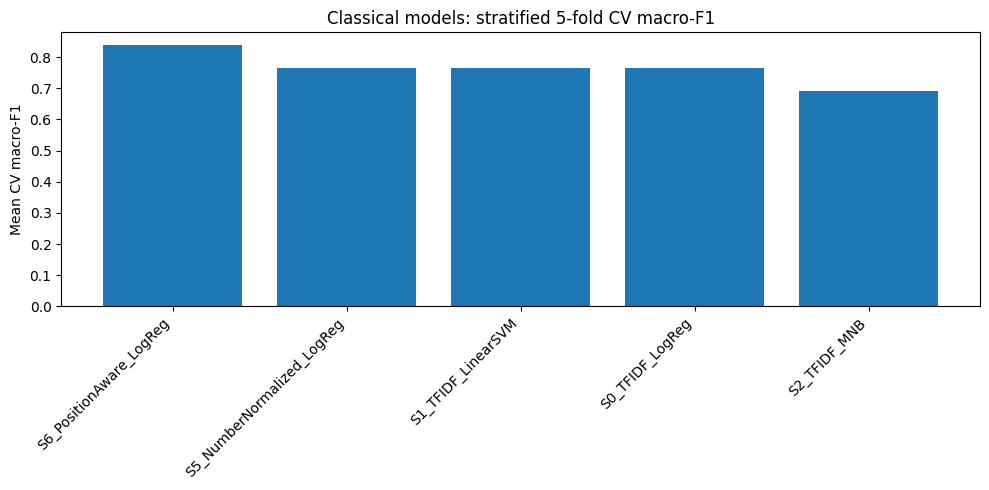

In [ ]:

if len(classical_cv_summary) > 0:
    display(
        classical_cv_summary[[
            "model_name",
            "macro_f1_mean", "macro_f1_std",
            "accuracy_mean", "accuracy_std",
            "background_f1_mean", "objective_f1_mean"
        ]]
    )

    plt.figure(figsize=(10, 5))
    plt.bar(classical_cv_summary["model_name"], classical_cv_summary["macro_f1_mean"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Mean CV macro-F1")
    plt.title("Classical models: stratified 5-fold CV macro-F1")
    plt.tight_layout()
    plt.show()


## 12. Statistical comparison and feature ablation under cross-validation

Paired fold comparisons are used for ablations because the same cross-validation folds make feature-change effects easier to interpret (Kohavi, 1995; Bestgen, 2022).

This section evaluates whether selected feature changes produce consistent improvements across matched cross-validation folds. The ablations focus on:

- baseline lexical logistic regression versus number-normalised logistic regression;
- baseline lexical logistic regression versus position-aware logistic regression.

A paired comparison is appropriate because each model is evaluated on the same fold partitions. The purpose is not only to ask whether a feature variant has a higher mean score, but whether the difference is stable enough to support a methodological claim.


In [ ]:

def paired_cv_test(model_a, model_b, metric="macro_f1"):
    a = classical_cv_results[model_a][metric].values
    b = classical_cv_results[model_b][metric].values
    stat, p = ttest_rel(a, b)
    return {
        "model_a": model_a,
        "model_b": model_b,
        "metric": metric,
        "mean_a": float(np.mean(a)),
        "mean_b": float(np.mean(b)),
        "delta_b_minus_a": float(np.mean(b - a)),
        "t_stat": float(stat),
        "p_value": float(p)
    }

ablation_tests = pd.DataFrame([
    paired_cv_test("S0_TFIDF_LogReg", "S5_NumberNormalized_LogReg", metric="macro_f1"),
    paired_cv_test("S0_TFIDF_LogReg", "S6_PositionAware_LogReg", metric="macro_f1")
])
ablation_tests


,model_a,model_b,metric,mean_a,mean_b,delta_b_minus_a,t_stat,p_value
0,S0_TFIDF_LogReg,S5_NumberNormalized_LogReg,macro_f1,0.76323,0.766109,0.002879,-9.390421,7.165892e-04
1,S0_TFIDF_LogReg,S6_PositionAware_LogReg,macro_f1,0.76323,0.837351,0.074121,-396.555779,2.426139e-10


In [ ]:

if "S0_TFIDF_LogReg" in classical_cv_results and "S6_PositionAware_LogReg" in classical_cv_results:
    baseline_cv = classical_cv_results["S0_TFIDF_LogReg"]["macro_f1"]
    position_cv = classical_cv_results["S6_PositionAware_LogReg"]["macro_f1"]
    delta = (position_cv - baseline_cv).mean()
    print(f"Position features improve macro-F1 by {delta:.4f} on average across CV folds.")


Position features improve macro-F1 by 0.0741 on average across CV folds.


## 13. Fold-level confusion patterns across cross-validation

This section examines fold-level confusion patterns to see whether rhetorical boundary errors are systematic rather than caused by one split (Dernoncourt & Lee, 2017; Schulz et al., 2010).

This section checks whether the same error modes persist across cross-validation folds. Persistent confusions suggest a systematic modelling difficulty rather than a split-specific accident. In this task, particular attention is given to Background versus Objective because these classes can be lexically similar but rhetorically distinct.


In [ ]:

for model_name in ["S0_TFIDF_LogReg", "S5_NumberNormalized_LogReg", "S6_PositionAware_LogReg"]:
    if model_name in cv_fold_predictions:
        print(f"Top CV confusions for {model_name}")
        display(aggregate_cv_confusions(cv_fold_predictions[model_name], top_n=10))


Top CV confusions for S0_TFIDF_LogReg


,true,pred,count
0,results,methods,4068
1,objective,background,3771
2,conclusions,results,3533
3,background,conclusions,2886
4,background,objective,2809
5,methods,results,2796
6,results,conclusions,2288
7,conclusions,background,2099
8,background,methods,1580
9,objective,conclusions,1130


Top CV confusions for S5_NumberNormalized_LogReg


,true,pred,count
0,results,methods,3927
1,objective,background,3804
2,conclusions,results,3436
3,background,conclusions,2891
4,methods,results,2869
5,background,objective,2800
6,results,conclusions,2313
7,conclusions,background,2157
8,background,methods,1242
9,objective,conclusions,1138


Top CV confusions for S6_PositionAware_LogReg


,true,pred,count
0,objective,background,4131
1,background,objective,4052
2,results,methods,2999
3,methods,results,2065
4,results,conclusions,1822
5,conclusions,results,1604
6,methods,background,879
7,background,methods,776
8,background,conclusions,568
9,objective,methods,549


## 14. Learning-curve analysis for classical models

Learning curves are used as a diagnostic for whether sparse lexical models are limited by data quantity, representation, or overfitting (Kohavi, 1995; Manning et al., 2008).

Learning curves are presented for a small number of representative models to keep the figure interpretable. A baseline model and a key improved model are shown rather than placing every system into one crowded plot.

The learning curve helps diagnose whether sparse lexical models are limited by data size, feature representation, or overfitting. If training Macro-F1 remains high while validation Macro-F1 plateaus lower, the model may be memorising lexical patterns without fully capturing abstract-level rhetorical structure. This pattern supports the inclusion of structural features, sequence models, and contextual transformer inputs.


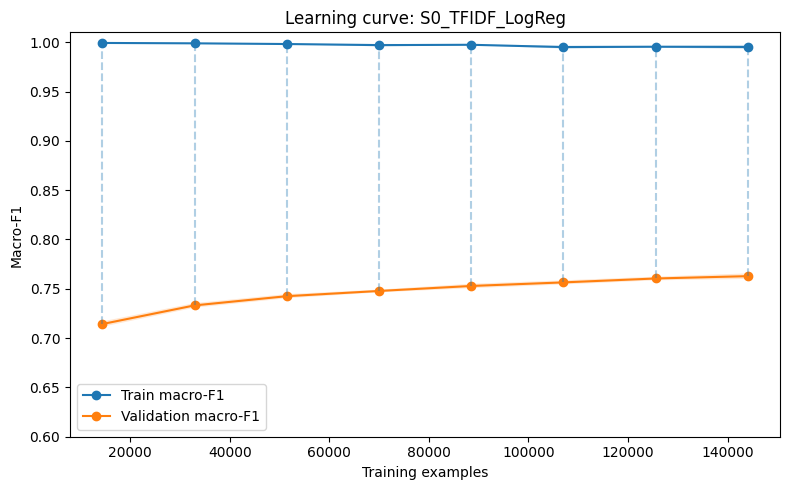


Learning-curve summary for S0_TFIDF_LogReg


,train_size,train_macro_f1_mean,train_macro_f1_std,valid_macro_f1_mean,valid_macro_f1_std,generalization_gap
0,14403,0.999236,0.000216,0.714245,0.002706,0.284991
1,32921,0.998849,0.000207,0.733134,0.002323,0.265715
2,51440,0.998151,0.000179,0.742485,0.002118,0.255666
3,69958,0.997039,0.001325,0.747772,0.001414,0.249267
4,88476,0.997386,0.000352,0.752847,0.002243,0.244539
5,106995,0.995057,0.001571,0.756467,0.002074,0.238590
6,125513,0.995393,0.000915,0.760428,0.001859,0.234964
7,144032,0.995158,0.002120,0.762798,0.002795,0.232360


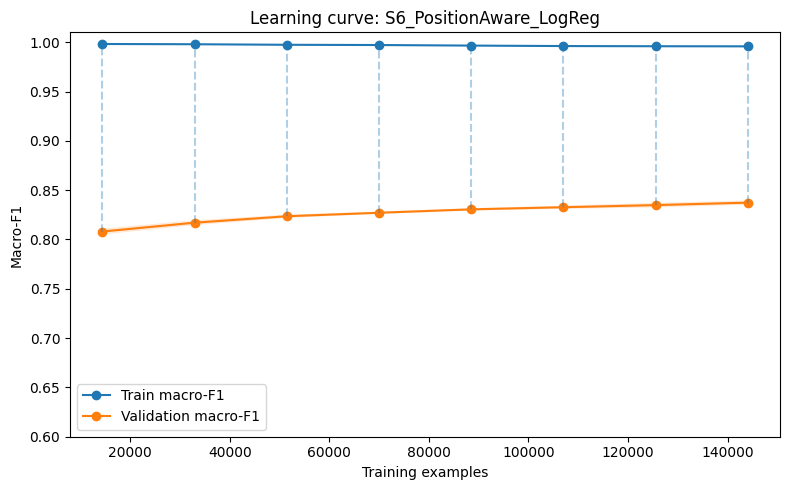


Learning-curve summary for S6_PositionAware_LogReg


,train_size,train_macro_f1_mean,train_macro_f1_std,valid_macro_f1_mean,valid_macro_f1_std,generalization_gap
0,14403,0.998175,0.000170,0.808022,0.002883,0.190152
1,32921,0.997927,0.000100,0.817003,0.002468,0.180924
2,51440,0.997373,0.000217,0.823512,0.001693,0.173861
3,69958,0.997131,0.000284,0.827075,0.001261,0.170056
4,88476,0.996560,0.000244,0.830511,0.001182,0.166049
5,106995,0.996090,0.000530,0.832686,0.001615,0.163404
6,125513,0.995895,0.000551,0.834813,0.002350,0.161082
7,144032,0.995797,0.000772,0.837329,0.002065,0.158468


In [ ]:
from sklearn.model_selection import learning_curve
from sklearn.base import clone
import numpy as np
import matplotlib.pyplot as plt

RUN_LEARNING_CURVES = True

def plot_learning_curve_macro_f1(
    estimator,
    X_df,
    y,
    title,
    cv_splitter,
    train_size_grid=None,
    ymin=None,
    ymax=None,
    show_gap=True
):
    if train_size_grid is None:
        train_size_grid = np.linspace(0.1, 1.0, 8)

    train_sizes, train_scores, valid_scores = learning_curve(
        estimator=estimator,
        X=X_df,
        y=y,
        train_sizes=train_size_grid,
        cv=cv_splitter,
        scoring="f1_macro",
        n_jobs=-1,
        shuffle=False
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    valid_mean = valid_scores.mean(axis=1)
    valid_std = valid_scores.std(axis=1)
    gap = train_mean - valid_mean

    # Auto-scale y-axis to a sensible range instead of always showing 0–1
    if ymin is None:
        ymin = max(0.0, min(valid_mean.min(), train_mean.min()) - 0.03)
    if ymax is None:
        ymax = min(1.0, max(valid_mean.max(), train_mean.max()) + 0.03)

    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_mean, marker="o", label="Train macro-F1")
    plt.plot(train_sizes, valid_mean, marker="o", label="Validation macro-F1")

    plt.fill_between(
        train_sizes,
        train_mean - train_std,
        train_mean + train_std,
        alpha=0.18
    )
    plt.fill_between(
        train_sizes,
        valid_mean - valid_std,
        valid_mean + valid_std,
        alpha=0.18
    )

    if show_gap:
        for x, tr, va in zip(train_sizes, train_mean, valid_mean):
            plt.vlines(x, va, tr, linestyles="dashed", alpha=0.35)

    plt.xlabel("Training examples")
    plt.ylabel("Macro-F1")
    plt.title(title)
    plt.ylim(ymin, ymax)
    plt.legend()
    plt.tight_layout()
    plt.show()

    gap_df = pd.DataFrame({
        "train_size": train_sizes,
        "train_macro_f1_mean": train_mean,
        "train_macro_f1_std": train_std,
        "valid_macro_f1_mean": valid_mean,
        "valid_macro_f1_std": valid_std,
        "generalization_gap": gap
    })
    return gap_df


if RUN_LEARNING_CURVES:
    learning_curve_tables = {}

    for model_name in ["S0_TFIDF_LogReg", "S6_PositionAware_LogReg"]:
        if model_name in classical_best_estimators:
            est = clone(classical_best_estimators[model_name])

            # PositionAwareTextClassifier expects the full dataframe
            if model_name == "S6_PositionAware_LogReg":
                X_input = classical_train_df.copy()
            else:
                # Ensure X_input is a DataFrame, not a Series, for ColumnTransformer
                X_input = classical_train_df[["text"]]

            gap_df = plot_learning_curve_macro_f1(
                estimator=est,
                X_df=X_input,
                y=y_classical_train,
                title=f"Learning curve: {model_name}",
                cv_splitter=CV_SPLITTER,
                train_size_grid=np.linspace(0.1, 1.0, 8),
                ymin=0.60,
                ymax=1.01,
                show_gap=True
            )

            learning_curve_tables[model_name] = gap_df
            print(f"\nLearning-curve summary for {model_name}")
            display(gap_df)
else:
    print("RUN_LEARNING_CURVES=False, so learning-curve analysis is skipped by default.")

## 15. Baseline system

### 15.1 System 0: TF-IDF + logistic regression

This logistic-regression baseline is treated as the simplest serious reference point before claiming value from sequence or transformer models (Cox, 1958; Salton & Buckley, 1988; Pedregosa et al., 2011).

This system is the main interpretable sparse-feature baseline. TF-IDF is used because it represents each sentence through terms that are frequent in the sentence but relatively distinctive in the corpus (Salton & Buckley, 1988). Logistic regression is used because it provides a transparent linear decision function and a strong baseline for high-dimensional sparse text features (Cox, 1958; Pedregosa et al., 2011).

The purpose of this baseline is methodological: it defines the simplest serious reference point against which more complex models must justify their additional complexity, computational cost, and potential robustness gains.


Finished: S0_TFIDF_LogReg
accuracy         0.823183
macro_f1         0.765137
background_f1    0.650812
objective_f1     0.627801
dtype: float64


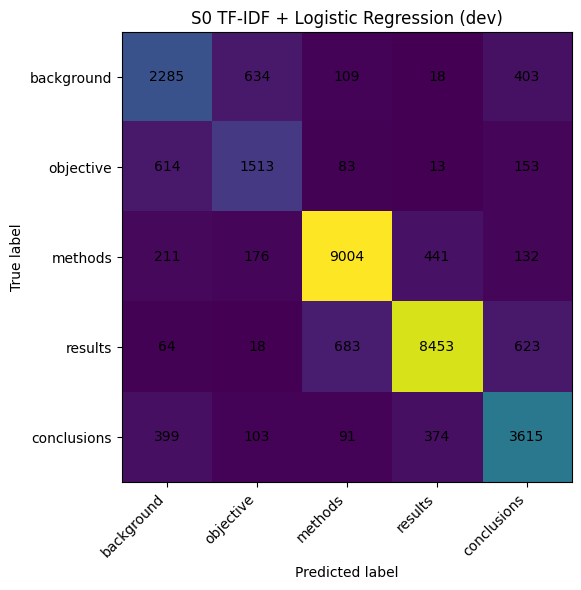

In [ ]:

baseline_lr = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

baseline_lr_model, baseline_lr_pred = train_eval_text_model(
    "S0_TFIDF_LogReg",
    baseline_lr,
    splits["train_sent"],
    splits["dev_sent"],
    text_col="text"
)

plot_confusion_matrix(splits["dev_sent"]["label"], baseline_lr_pred, title="S0 TF-IDF + Logistic Regression (dev)")

## 16. Traditional non-sequential systems

These non-sequential baselines are included to test how far sparse lexical evidence can go before adding explicit discourse structure (Salton & Buckley, 1988; Joachims, 1998; Pedregosa et al., 2011).

This section evaluates classical machine-learning models that classify each sentence independently. These systems rely mainly on sparse lexical representations and do not explicitly model abstract-level sequence structure. They are included because strong classical baselines are essential before claiming that neural or transformer models provide meaningful additional value.


**System 1: TF-IDF + linear SVM.**

The linear SVM is used as a strong max-margin sparse-text baseline for comparison with logistic regression and later neural systems (Cortes & Vapnik, 1995; Joachims, 1998).

This system combines sparse TF-IDF features with a linear support vector machine. Linear SVMs are well suited to high-dimensional text classification because they can learn max-margin separators in feature spaces with many sparse lexical predictors (Cortes & Vapnik, 1995; Joachims, 1998). It is included as a strong discriminative classical baseline and as a test of whether max-margin classification improves over logistic regression for sentence-role prediction.


In [ ]:

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("clf", LinearSVC())
])

svm_model, svm_pred = train_eval_text_model(
    "S1_TFIDF_LinearSVM",
    svm_pipeline,
    splits["train_sent"],
    splits["dev_sent"],
    text_col="text"
)

Finished: S1_TFIDF_LinearSVM
accuracy         0.830994
macro_f1         0.767143
background_f1    0.660407
objective_f1     0.613098
dtype: float64


**System 2: TF-IDF + multinomial Naive Bayes.**

Multinomial Naive Bayes is included as a fast probabilistic baseline, while recognising that its independence assumption is a simplification for language (McCallum & Nigam, 1998).

This system provides a fast probabilistic text-classification baseline. Multinomial Naive Bayes assumes conditional independence between features given the class, an assumption that is unrealistic for language but often competitive for sparse word-count or TF-IDF text classification (McCallum & Nigam, 1998). It is included to test how much performance is achievable with a highly efficient and interpretable probabilistic model.


In [ ]:

mnb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("clf", MultinomialNB())
])

mnb_model, mnb_pred = train_eval_text_model(
    "S2_TFIDF_MNB",
    mnb_pipeline,
    splits["train_sent"],
    splits["dev_sent"],
    text_col="text"
)

Finished: S2_TFIDF_MNB
accuracy         0.758341
macro_f1         0.633355
background_f1    0.570255
objective_f1     0.271245
dtype: float64


**System 3: word + character TF-IDF + linear SVM.**

Word and character TF-IDF are tested together because biomedical text contains both phrase-level cues and rare subword or abbreviation patterns (Salton & Buckley, 1988; Manning et al., 2008; Joachims, 1998).

The lexical SVM is extended by combining word-level and character-level TF-IDF features. Word n-grams capture phrase-level reporting cues, whereas character n-grams capture subword morphology, abbreviations, spelling variation, and biomedical tokens that may be rare as complete words. The model tests whether richer lexical granularity improves over word-only sparse features while remaining computationally efficient.


In [ ]:

word_char_union = FeatureUnion([
    ("word_tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, analyzer="word")),
    ("char_tfidf", TfidfVectorizer(ngram_range=(3, 5), min_df=2, analyzer="char_wb"))
])

word_char_svm = Pipeline([
    ("features", word_char_union),
    ("clf", LinearSVC())
])

word_char_model, word_char_pred = train_eval_text_model(
    "S3_WordCharTFIDF_LinearSVM",
    word_char_svm,
    splits["train_sent"],
    splits["dev_sent"],
    text_col="text"
)

Finished: S3_WordCharTFIDF_LinearSVM
accuracy         0.832384
macro_f1         0.768072
background_f1    0.658410
objective_f1     0.610092
dtype: float64


**System 4: fastText-style shallow classifier.**

This shallow classifier is included as a lightweight neural-style comparison point between sparse baselines and heavier contextual models (Joulin et al., 2017).

This system is used as a lightweight neural-style baseline inspired by fastText, which showed that simple averaged representations with a linear classifier can be highly efficient for text classification (Joulin et al., 2017). In this notebook, the implementation is a shallow classifier using character n-gram TF-IDF features with stochastic-gradient optimisation rather than a full fastText training pipeline. It is included as a bridge between classical sparse baselines and heavier neural architectures.


In [ ]:
!pip install fasttext

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 5.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.0.4-py3-none-any.whl.metadata (10 kB)
Using cached pybind11-3.0.4-py3-none-any.whl (314 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp312-cp312-linux_x86_64.whl size=4653908 sha256=fce9a7069d2446053acc1a9aaa102a20a28c959febbff3d9bce5c8781750457c
  Stored in directory: /root/.cache/pip/wheels/20/27/95/a7baf1b435f1cbde017cabdf1e9688526d2b0e929255a359c6
Successfully built fasttext


In [ ]:

HAS_FASTTEXT = True
try:
    import fasttext
    HAS_FASTTEXT = True
except Exception:
    HAS_FASTTEXT = False

print("fastText available:", HAS_FASTTEXT)

fasttext_style_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), analyzer="char_wb", min_df=2)),
    ("clf", SGDClassifier(loss="log_loss", max_iter=1000, random_state=SEED))
])

fasttext_style_model, fasttext_style_pred = train_eval_text_model(
    "S4_fastTextStyle_ShallowClassifier",
    fasttext_style_pipeline,
    splits["train_sent"],
    splits["dev_sent"],
    text_col="text"
)

fastText available: True
Finished: S4_fastTextStyle_ShallowClassifier
accuracy         0.677909
macro_f1         0.561252
background_f1    0.406871
objective_f1     0.298693
dtype: float64


## 17. Number-normalisation ablation system

**System 5: number-normalised logistic regression.**

Number normalisation is used as an ablation to test whether numeric surface forms act as useful class evidence or brittle lexical variation (Manning et al., 2008).

This system replaces numerical expressions with a standardised representation before TF-IDF feature extraction. The purpose is an ablation rather than a guaranteed improvement: RCT abstracts often contain sample sizes, percentages, confidence intervals, p-values, and follow-up durations, so numbers may either provide useful class cues or create brittle lexical variation. Number normalisation tests whether reducing numeric surface variability improves generalisation and perturbation stability (Manning et al., 2008).


In [ ]:

num_norm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

num_norm_model, num_norm_pred = train_eval_text_model(
    "S5_NumberNormalized_LogReg",
    num_norm_pipeline,
    splits["train_sent"],
    splits["dev_sent"],
    text_col="text_num_norm"
)

comparison = summarize_results_table(results_store)
comparison[comparison["model_name"].isin(["S0_TFIDF_LogReg", "S5_NumberNormalized_LogReg"])]

Finished: S5_NumberNormalized_LogReg
accuracy         0.824176
macro_f1         0.766088
background_f1    0.652541
objective_f1     0.630331
dtype: float64


,model_name,split_name,accuracy,macro_f1,weighted_f1,background_f1,objective_f1,methods_f1,results_f1,conclusions_f1
2,S5_NumberNormalized_LogReg,dev,0.824176,0.766088,0.825574,0.652541,0.630331,0.905169,0.884082,0.758318
3,S0_TFIDF_LogReg,dev,0.823183,0.765137,0.824645,0.650812,0.627801,0.903381,0.883281,0.760412
8,S5_NumberNormalized_LogReg,dev_post_cv,0.832682,0.769759,0.830929,0.665232,0.614100,0.908705,0.891159,0.769598
9,S0_TFIDF_LogReg,dev_post_cv,0.829670,0.766563,0.827731,0.651115,0.619189,0.904785,0.889816,0.767908


## 18. Position-aware system

**System 6: position-feature classifier.**

Position features are added because structured RCT abstracts make sentence location a plausible rhetorical signal, not just a technical feature (Dernoncourt & Lee, 2017; Schulz et al., 2010).

This system augments lexical TF-IDF features with explicit sentence-position features, including sentence index, relative position, and first/last-sentence indicators. The method is motivated by the structured nature of RCT abstracts: rhetorical roles are not randomly distributed across an abstract, and sentence location can provide signal beyond lexical content (Dernoncourt & Lee, 2017; Schulz et al., 2010).

This model tests whether a simple, interpretable structural feature set can close part of the gap between sentence-level lexical baselines and more complex sequence/context-aware systems.


Finished: S6_PositionAware_LogReg
accuracy         0.882332
macro_f1         0.833944
background_f1    0.730150
objective_f1     0.672192
dtype: float64


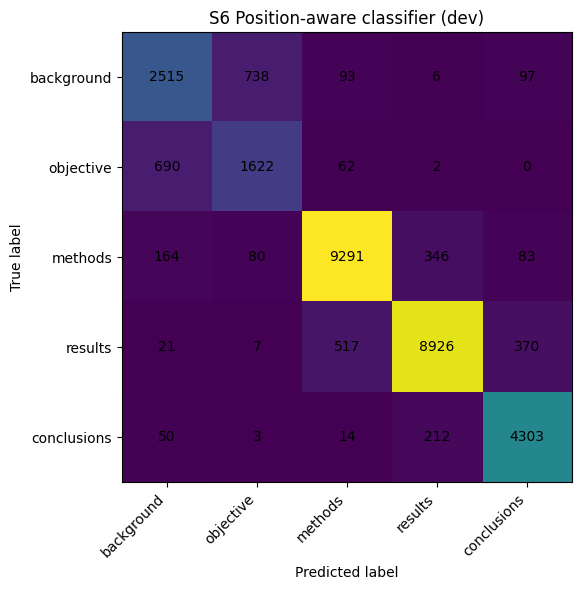

In [ ]:

def build_position_aware_features(train_df, dev_df, text_col="text"):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    X_train_text = vectorizer.fit_transform(train_df[text_col])
    X_dev_text = vectorizer.transform(dev_df[text_col])

    pos_cols = ["sentence_index_in_abstract", "relative_position", "is_first_sentence", "is_last_sentence"]
    scaler = StandardScaler()
    X_train_pos = scaler.fit_transform(train_df[pos_cols])
    X_dev_pos = scaler.transform(dev_df[pos_cols])

    X_train = hstack([X_train_text, csr_matrix(X_train_pos)])
    X_dev = hstack([X_dev_text, csr_matrix(X_dev_pos)])
    return X_train, X_dev, vectorizer, scaler

X_train_posaware, X_dev_posaware, pos_vec, pos_scaler = build_position_aware_features(
    splits["train_sent"], splits["dev_sent"], text_col="text"
)

posaware_clf, posaware_pred = train_eval_feature_model(
    "S6_PositionAware_LogReg",
    X_train_posaware, splits["train_sent"]["label"],
    X_dev_posaware, splits["dev_sent"]["label"],
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

plot_confusion_matrix(splits["dev_sent"]["label"], posaware_pred, title="S6 Position-aware classifier (dev)")

## 19. CRF sequence model

**System 7: conditional random field sequence labelling.**

A CRF is included because it directly models neighbouring sentence labels, which matches the sequential nature of abstract role classification (Lafferty et al., 2001; Dernoncourt & Lee, 2017).

A conditional random field (CRF) models the labels of all sentences in an abstract jointly rather than treating each sentence as independent. This is appropriate because sentence roles often follow local transition patterns, such as Objective preceding Methods or Results preceding Conclusions. CRFs are included because they provide a classical sequence-labelling approach that can model adjacent label dependencies without requiring deep neural representations (Lafferty et al., 2001).


In [ ]:

HAS_CRF = False
try:
    import sklearn_crfsuite
    HAS_CRF = True
except Exception:
    HAS_CRF = False

print("sklearn-crfsuite available:", HAS_CRF)

sklearn-crfsuite available: False


In [ ]:
!pip -q install sklearn-crfsuite


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 41.8 MB/s eta 0:00:00


In [ ]:

HAS_CRF = False
try:
    import sklearn_crfsuite
    HAS_CRF = True
except Exception:
    HAS_CRF = False

print("sklearn-crfsuite available:", HAS_CRF)

sklearn-crfsuite available: True


In [ ]:

def df_to_abstract_sequences(df: pd.DataFrame):
    seqs_X = []
    seqs_y = []
    seq_ids = []
    for pubmed_id, group in df.sort_values(["pubmed_id", "file_order"]).groupby("pubmed_id"):
        group = group.reset_index(drop=True)
        texts = group["text"].tolist()
        labels = group["label"].tolist()
        feats_seq = []
        n = len(group)
        for i, row in group.iterrows():
            text = row["text"]
            toks = text.split()
            feat = {
                "bias": 1.0,
                "text.lower": text.lower(),
                "word_count": len(toks),
                "sent_idx": int(row["sentence_index_in_abstract"]),
                "rel_pos": float(row["relative_position"]),
                "is_first": int(row["is_first_sentence"]),
                "is_last": int(row["is_last_sentence"]),
                "first_word": toks[0].lower() if len(toks) > 0 else "",
                "last_word": toks[-1].lower() if len(toks) > 0 else "",
                "prefix3": text[:3].lower(),
                "contains_number": int(bool(re.search(r"\d", text))),
            }
            if i > 0:
                feat["-1:first_word"] = texts[i-1].split()[0].lower() if texts[i-1].split() else ""
            else:
                feat["BOS"] = True
            if i < n - 1:
                feat["+1:first_word"] = texts[i+1].split()[0].lower() if texts[i+1].split() else ""
            else:
                feat["EOS"] = True
            feats_seq.append(feat)
        seqs_X.append(feats_seq)
        seqs_y.append(labels)
        seq_ids.append(pubmed_id)
    return seqs_X, seqs_y, seq_ids

accuracy         0.803489
macro_f1         0.764797
background_f1    0.698148
objective_f1     0.613155
dtype: float64


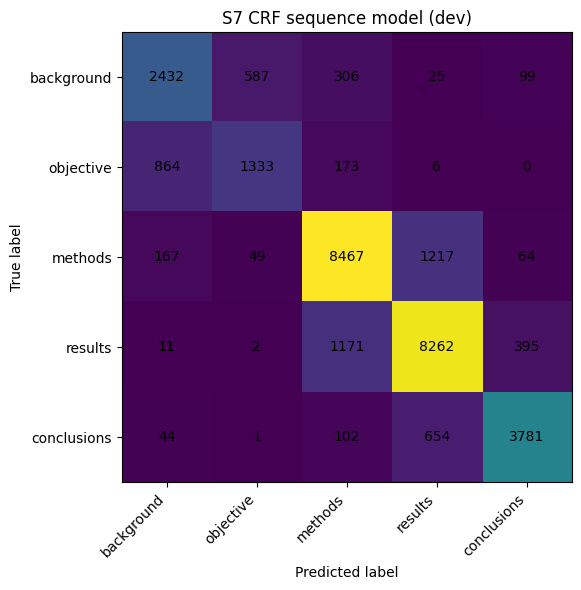

In [ ]:

crf_model = None
crf_dev_pred_flat = None

if RUN_CRF and HAS_CRF:
    X_train_seq, y_train_seq, train_seq_ids = df_to_abstract_sequences(splits["train_seq"])
    X_dev_seq, y_dev_seq, dev_seq_ids = df_to_abstract_sequences(splits["dev_seq"])

    crf_model = sklearn_crfsuite.CRF(
        algorithm="lbfgs",
        c1=0.1,
        c2=0.1,
        max_iterations=100,
        all_possible_transitions=True
    )
    crf_model.fit(X_train_seq, y_train_seq)
    crf_dev_pred = crf_model.predict(X_dev_seq)

    y_true_flat = [lab for seq in y_dev_seq for lab in seq]
    y_pred_flat = [lab for seq in crf_dev_pred for lab in seq]
    crf_dev_pred_flat = y_pred_flat

    row = record_result(
        model_name="S7_CRF_SequenceModel",
        split_name="dev",
        y_true=y_true_flat,
        y_pred=y_pred_flat,
        meta={"uses_sequence": True}
    )
    print(pd.Series({
        "accuracy": row["accuracy"],
        "macro_f1": row["macro_f1"],
        "background_f1": row["background_f1"],
        "objective_f1": row["objective_f1"]
    }))
    plot_confusion_matrix(y_true_flat, y_pred_flat, title="S7 CRF sequence model (dev)")
else:
    print("CRF not run. Either RUN_CRF=False or sklearn-crfsuite is unavailable.")

## 20. BiLSTM-style sequential neural model

### 20.1 System 8: simplified runnable BiLSTM-style model

A simplified BiLSTM-style model is used to test abstract-level sequence context while keeping the notebook feasible to rerun in Colab (Hochreiter & Schmidhuber, 1997; Huang et al., 2015; Paszke et al., 2019).

This system is a simplified PyTorch sequence model with:

- token embeddings;
- mean-pooled sentence representations;
- an abstract-level bidirectional LSTM;
- a sentence-level classifier.

The model is motivated by LSTM sequence modelling (Hochreiter & Schmidhuber, 1997) and by BiLSTM-CRF sequence-tagging work showing that bidirectional recurrent models can use both preceding and following context (Huang et al., 2015). In this notebook, the implementation is deliberately simplified and does not include a full neural CRF decoder. Its role is to test whether abstract-level sequential modelling improves over independent sentence classifiers while remaining runnable in Colab.


In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [ ]:

def build_vocab(texts, min_freq=2):
    counter = Counter()
    for text in texts:
        counter.update(text.lower().split())
    vocab = {"<pad>": 0, "<unk>": 1}
    for tok, c in counter.items():
        if c >= min_freq:
            vocab[tok] = len(vocab)
    return vocab

def encode_sentence(text, vocab, max_len=50):
    toks = text.lower().split()[:max_len]
    ids = [vocab.get(t, vocab["<unk>"]) for t in toks]
    if len(ids) < max_len:
        ids = ids + [vocab["<pad>"]] * (max_len - len(ids))
    return ids

class AbstractSequenceDataset(Dataset):
    def __init__(self, df, vocab, max_sent_len=50, max_abs_len=40):
        self.examples = []
        for pmid, g in df.sort_values(["pubmed_id", "file_order"]).groupby("pubmed_id"):
            g = g.reset_index(drop=True)
            sent_ids = [encode_sentence(t, vocab, max_len=max_sent_len) for t in g["text"].tolist()[:max_abs_len]]
            labels = [LABEL2ID[l] for l in g["label"].tolist()[:max_abs_len]]
            length = len(sent_ids)
            if length < max_abs_len:
                sent_ids += [[0] * max_sent_len] * (max_abs_len - length)
                labels += [-100] * (max_abs_len - length)
            self.examples.append({
                "input_ids": torch.tensor(sent_ids, dtype=torch.long),
                "labels": torch.tensor(labels, dtype=torch.long),
                "seq_len": length
            })

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        return self.examples[idx]

class SentenceEncoderBiLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_labels=5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.abs_bilstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden_dim // 2,
            batch_first=True,
            bidirectional=True
        )
        self.classifier = nn.Linear(hidden_dim, num_labels)

    def forward(self, input_ids):
        B, S, T = input_ids.shape
        emb = self.embedding(input_ids)
        sent_emb = emb.mean(dim=2)
        out, _ = self.abs_bilstm(sent_emb)
        logits = self.classifier(out)
        return logits

In [ ]:

def run_bilstm_style_experiment(train_df_seq, dev_df_seq, epochs=3, batch_size=8, lr=1e-3):
    vocab = build_vocab(train_df_seq["text"].tolist(), min_freq=2)
    train_ds = AbstractSequenceDataset(train_df_seq, vocab)
    dev_ds = AbstractSequenceDataset(dev_df_seq, vocab)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    dev_loader = DataLoader(dev_ds, batch_size=batch_size, shuffle=False)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = SentenceEncoderBiLSTM(len(vocab)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(ignore_index=-100)

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for batch in train_loader:
            x = batch["input_ids"].to(device)
            y = batch["labels"].to(device)
            logits = model(x)
            loss = criterion(logits.view(-1, logits.size(-1)), y.view(-1))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{epochs} - train loss: {total_loss/len(train_loader):.4f}")

    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for batch in dev_loader:
            x = batch["input_ids"].to(device)
            y = batch["labels"].cpu().numpy()
            logits = model(x)
            pred = logits.argmax(dim=-1).cpu().numpy()
            for yi, pi in zip(y, pred):
                for yy, pp in zip(yi, pi):
                    if yy != -100:
                        y_true.append(ID2LABEL[int(yy)])
                        y_pred.append(ID2LABEL[int(pp)])
    return model, vocab, y_true, y_pred

Epoch 1/5 - train loss: 0.4464
Epoch 2/5 - train loss: 0.2743
Epoch 3/5 - train loss: 0.2308
Epoch 4/5 - train loss: 0.1957
Epoch 5/5 - train loss: 0.1635
accuracy         0.903151
macro_f1         0.850941
background_f1    0.780456
objective_f1     0.644380
dtype: float64


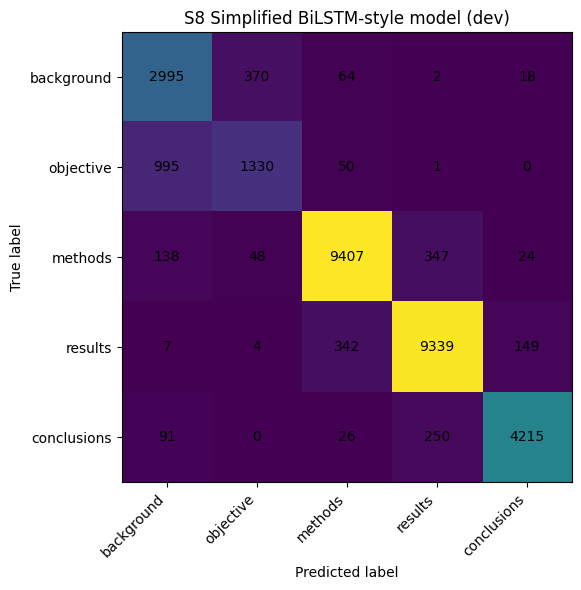

In [ ]:

bilstm_model = None
bilstm_vocab = None

if RUN_BILSTM_STYLE:
    bilstm_model, bilstm_vocab, y_true_bilstm, y_pred_bilstm = run_bilstm_style_experiment(
        splits["train_seq"],
        splits["dev_seq"],
        epochs=3 if DEBUG_SMALL_MODE else 10
    )
    row = record_result(
        model_name="S8_BiLSTMStyle_SequentialModel",
        split_name="dev",
        y_true=y_true_bilstm,
        y_pred=y_pred_bilstm,
        meta={"uses_sequence": True, "simplified": True}
    )
    print(pd.Series({
        "accuracy": row["accuracy"],
        "macro_f1": row["macro_f1"],
        "background_f1": row["background_f1"],
        "objective_f1": row["objective_f1"]
    }))
    plot_confusion_matrix(y_true_bilstm, y_pred_bilstm, title="S8 Simplified BiLSTM-style model (dev)")
else:
    print("RUN_BILSTM_STYLE=False, so the simplified sequential neural model was not executed.")

## 21. Transformer family experiments

### 21.1 System 9: transformer family

General, scientific, and biomedical transformers are evaluated because pretrained contextual representations may behave differently across domains and input-context settings (Vaswani et al., 2017; Devlin et al., 2019; Beltagy et al., 2019; Gu et al., 2021).

This section evaluates pretrained transformer encoders fine-tuned for sentence-role classification. The model family includes:

- `bert-base-uncased`, a general-domain BERT baseline (Devlin et al., 2019);
- `allenai/scibert_scivocab_uncased`, a scientific-domain transformer pretrained on scientific text (Beltagy et al., 2019);
- `microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract`, a biomedical-domain transformer related to PubMedBERT/BiomedBERT pretraining (Gu et al., 2021).

Two input modes are evaluated:

- sentence-only input;
- previous sentence + `[SEP]` + current sentence.

The previous-sentence condition tests whether local discourse context improves transformer performance. This is important because a sentence's rhetorical role may depend on the sentence immediately before it, not only on its own words.


### 21.2 Transformer interpretation note

This note explains the transformer classifier-head warning so that a normal fine-tuning message is not misread as a broken model pipeline (Devlin et al., 2019; Wolf et al., 2020).

When a pretrained encoder is loaded into `AutoModelForSequenceClassification`, newly initialised `classifier.weight` and `classifier.bias` parameters are expected. These parameters form the task-specific classification head and are learned during fine-tuning.

The relevant evaluation questions are:

- whether fine-tuning completes successfully;
- whether development performance is competitive;
- whether final retraining and test evaluation use the same comparison policy;
- whether results are stable enough to justify the strength of the claim.

A missing-classifier or newly initialised classifier warning should therefore be interpreted as standard task-head initialisation, not as evidence that the transformer pipeline is broken.


In [ ]:

HAS_TRANSFORMERS = False
try:
    from datasets import Dataset
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
    HAS_TRANSFORMERS = True
except Exception:
    HAS_TRANSFORMERS = False

print("Transformers available:", HAS_TRANSFORMERS)

Transformers available: True


In [ ]:

TRANSFORMER_MODELS = {
    "bert_base": "bert-base-uncased",
    "scibert": "allenai/scibert_scivocab_uncased",
    "pubmedbert": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract"
}

def add_prev_sentence_context(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(["pubmed_id", "file_order"]).copy()
    prev_texts = []
    for pubmed_id, group in df.groupby("pubmed_id"):
        texts = group["text"].tolist()
        prev = [""]
        prev.extend(texts[:-1])
        prev_texts.extend(prev)
    df["prev_text"] = prev_texts
    df["text_with_prev"] = np.where(
        df["prev_text"].astype(str).str.len() > 0,
        df["prev_text"].astype(str) + " [SEP] " + df["text"].astype(str),
        df["text"].astype(str)
    )
    return df

def cap_transformer_data(df: pd.DataFrame, max_n: Optional[int], random_state=42):
    if max_n is None or len(df) <= max_n:
        return df.copy().reset_index(drop=True)
    return sample_debug_subset(df, frac=max_n/len(df), random_state=random_state).reset_index(drop=True)

splits["train_sent_ctx"] = add_prev_sentence_context(splits["train_sent"])
splits["dev_sent_ctx"] = add_prev_sentence_context(splits["dev_sent"])
splits["test_sent_ctx"] = add_prev_sentence_context(splits["test_sent"])

In [ ]:

def compute_metrics_for_hf(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    labels_txt = [ID2LABEL[int(x)] for x in labels]
    preds_txt = [ID2LABEL[int(x)] for x in preds]
    m = compute_metrics(labels_txt, preds_txt)
    return {"accuracy": m["accuracy"], "macro_f1": m["macro_f1"], "weighted_f1": m["weighted_f1"]}

def run_transformer_experiment(model_key, train_df, dev_df, input_col="text", epochs=1, batch_size=8):
    model_name_or_path = TRANSFORMER_MODELS[model_key]
    tokenizer = AutoTokenizer.from_pretrained(model_name_or_path)

    train_small = cap_transformer_data(train_df, MAX_TRANSFORMER_TRAIN if DEBUG_SMALL_MODE else None, random_state=SEED)
    dev_small = cap_transformer_data(dev_df, MAX_TRANSFORMER_DEV if DEBUG_SMALL_MODE else None, random_state=SEED)

    train_dataset = Dataset.from_pandas(
        train_small[[input_col, "label_id"]].rename(columns={input_col: "text", "label_id": "labels"})
    )
    dev_dataset = Dataset.from_pandas(
        dev_small[[input_col, "label_id"]].rename(columns={input_col: "text", "label_id": "labels"})
    )

    def tokenize_fn(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=128)

    train_dataset = train_dataset.map(tokenize_fn, batched=True)
    dev_dataset = dev_dataset.map(tokenize_fn, batched=True)

    cols_to_keep = ["input_ids", "attention_mask", "labels"]
    train_dataset.set_format(type="torch", columns=cols_to_keep)
    dev_dataset.set_format(type="torch", columns=cols_to_keep)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name_or_path, num_labels=len(LABEL_ORDER), id2label=ID2LABEL, label2id=LABEL2ID
    )

    args = TrainingArguments(
        output_dir=f"./tmp_{model_key}_{input_col}",
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=50,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        learning_rate=2e-5,
        weight_decay=0.01,
        report_to=[]
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=dev_dataset,
        compute_metrics=compute_metrics_for_hf
    )

    trainer.train()
    preds = trainer.predict(dev_dataset)
    y_true = [ID2LABEL[int(x)] for x in dev_small["label_id"].tolist()]
    y_pred = [ID2LABEL[int(x)] for x in np.argmax(preds.predictions, axis=-1)]
    return trainer, dev_small, y_true, y_pred

In [ ]:

transformer_runs = []

if RUN_TRANSFORMERS and HAS_TRANSFORMERS:
    for model_key in ["bert_base", "scibert", "pubmedbert"]:
        for mode_name, input_col in [("sentence_only", "text"), ("prev_plus_current", "text_with_prev")]:
            print(f"\nRunning transformer: {model_key} | mode={mode_name}")
            trainer, dev_used, y_true_tf, y_pred_tf = run_transformer_experiment(
                model_key=model_key,
                train_df=splits["train_sent_ctx"],
                dev_df=splits["dev_sent_ctx"],
                input_col=input_col,
                epochs=1 if DEBUG_SMALL_MODE else 2,
                batch_size=8
            )
            model_label = f"S9_{model_key}_{mode_name}"
            record_result(
                model_name=model_label,
                split_name="dev",
                y_true=y_true_tf,
                y_pred=y_pred_tf,
                meta={"uses_sequence": mode_name != "sentence_only", "family": "transformer"}
            )
            transformer_runs.append((model_label, trainer, dev_used, y_true_tf, y_pred_tf))
else:
    print("Transformers not run. Set RUN_TRANSFORMERS=True and ensure transformers/datasets are installed.")


Running transformer: bert_base | mode=sentence_only


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Map:   0%|          | 0/180040 [00:00<?, ? examples/s]

Map:   0%|          | 0/30212 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,0.329521,0.302796,0.913412,0.863884,0.912511
2,0.227636,0.358539,0.914670,0.865666,0.914057


## 22. Development results summary

Cross-validated classical evidence is separated from fixed-split neural evidence because the computational budgets and uncertainty support are not identical (Kohavi, 1995; Bestgen, 2022).

In this section, This section summarises two complementary development-stage evidence streams:

1. **Cross-validated training results for classical models**: used for robust classical-model comparison, hyperparameter tuning, and feature-ablation claims.
2. **Fixed development-split results for sequential and transformer models**: used as computationally feasible hold-out comparisons for more expensive systems.

These evidence streams should be interpreted together rather than collapsed into a single unqualified ranking. The classical results have stronger resampling support, whereas the neural and transformer results are more computationally constrained.


In [ ]:
dev_results = summarize_results_table(results_store)

print("Classical CV summary")
display(classical_cv_summary)

print("Hold-out development summary for sequential / transformer models")
display(dev_results)


Classical CV summary


,model_name,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,background_f1_mean,background_f1_std,objective_f1_mean,objective_f1_std,methods_f1_mean,methods_f1_std,results_f1_mean,results_f1_std,conclusions_f1_mean,conclusions_f1_std
0,S6_PositionAware_LogReg,0.837351,0.001847,0.884692,0.001121,0.749086,0.004593,0.666540,0.005464,0.932598,0.001362,0.923795,0.001165,0.914737,0.002453
1,S5_NumberNormalized_LogReg,0.766109,0.002492,0.827444,0.001514,0.671608,0.007369,0.617289,0.004605,0.905853,0.001928,0.886018,0.001959,0.749777,0.003893
2,S1_TFIDF_LinearSVM,0.764629,0.002020,0.827205,0.001056,0.667024,0.006525,0.619273,0.002509,0.903199,0.001391,0.886584,0.001738,0.747066,0.002645
3,S0_TFIDF_LogReg,0.763230,0.001954,0.824911,0.001193,0.662113,0.006209,0.618103,0.003886,0.902567,0.001443,0.884591,0.002436,0.748774,0.002980
4,S2_TFIDF_MNB,0.692380,0.003144,0.780066,0.001561,0.625455,0.006337,0.451090,0.008458,0.862516,0.000398,0.857845,0.001434,0.664992,0.002935


Hold-out development summary for sequential / transformer models


,model_name,split_name,accuracy,macro_f1,weighted_f1,background_f1,objective_f1,methods_f1,results_f1,conclusions_f1
0,S9_pubmedbert_prev_plus_current,dev,0.914670,0.865666,0.914057,0.790857,0.694756,0.966978,0.952173,0.923568
1,S9_scibert_prev_plus_current,dev,0.908612,0.859143,0.907823,0.788886,0.687341,0.963723,0.944569,0.911197
2,S9_bert_base_prev_plus_current,dev,0.906924,0.854576,0.905751,0.783378,0.670330,0.962583,0.945408,0.911180
3,S8_BiLSTMStyle_SequentialModel,dev,0.903151,0.850941,0.902146,0.780456,0.644380,0.947665,0.944287,0.937917
4,S6_PositionAware_LogReg,dev,0.882332,0.833944,0.882659,0.730150,0.672192,0.931849,0.923395,0.912136
5,S9_pubmedbert_sentence_only,dev,0.887032,0.831941,0.885883,0.756239,0.661610,0.950950,0.932273,0.858635
6,S9_scibert_sentence_only,dev,0.881769,0.827762,0.880835,0.745546,0.671942,0.946866,0.927692,0.846764
7,S9_bert_base_sentence_only,dev,0.878790,0.823111,0.877884,0.740534,0.658835,0.944898,0.926435,0.844854
8,S3_WordCharTFIDF_LinearSVM,dev,0.832384,0.768072,0.830443,0.658410,0.610092,0.909501,0.891754,0.770602
9,S1_TFIDF_LinearSVM,dev,0.830994,0.767143,0.828739,0.660407,0.613098,0.906115,0.891166,0.764926


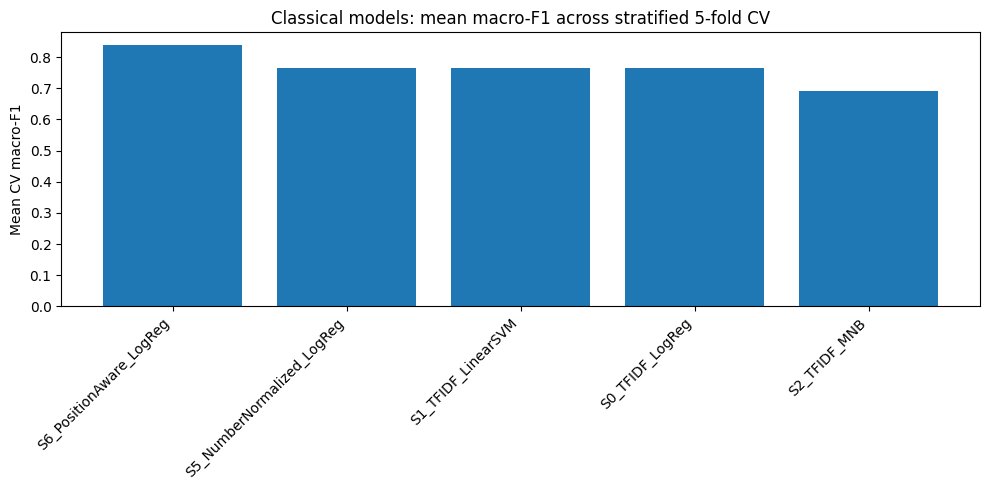

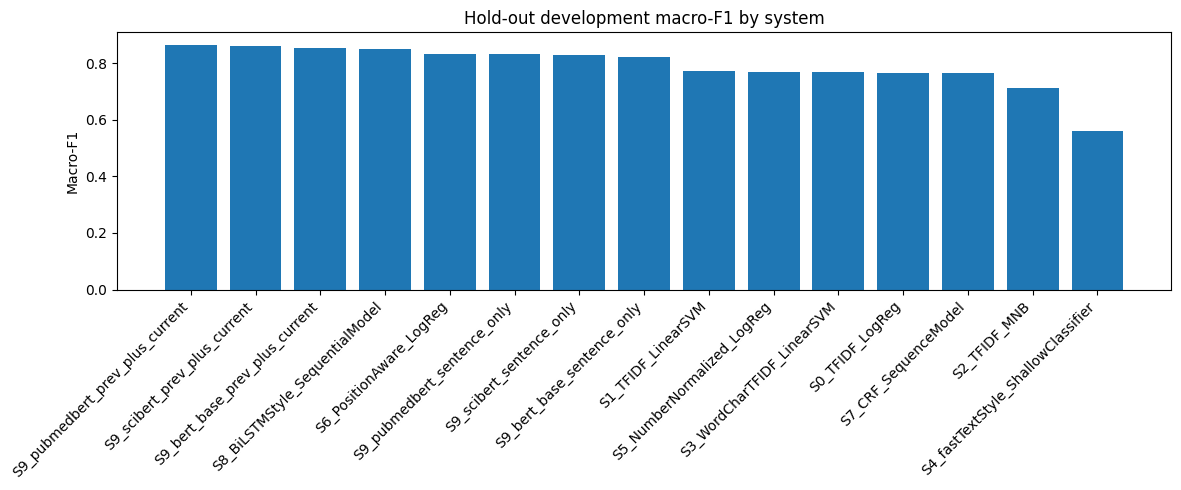

In [ ]:

if len(classical_cv_summary) > 0:
    cv_plot = classical_cv_summary.sort_values("macro_f1_mean", ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(cv_plot["model_name"], cv_plot["macro_f1_mean"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Mean CV macro-F1")
    plt.title("Classical models: mean macro-F1 across stratified 5-fold CV")
    plt.tight_layout()
    plt.show()

if len(dev_results) > 0:
    dev_plot = dev_results[dev_results["split_name"].isin(["dev", "dev_post_cv"])].sort_values("macro_f1", ascending=False)
    plt.figure(figsize=(12, 5))
    plt.bar(dev_plot["model_name"], dev_plot["macro_f1"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Macro-F1")
    plt.title("Hold-out development macro-F1 by system")
    plt.tight_layout()
    plt.show()


In [ ]:

if len(classical_cv_summary) > 0:
    cv_per_class = classical_cv_summary[[
        "model_name",
        "background_f1_mean",
        "objective_f1_mean",
        "methods_f1_mean",
        "results_f1_mean",
        "conclusions_f1_mean"
    ]].sort_values("background_f1_mean", ascending=False)
    print("Classical models: per-class mean F1 across CV folds")
    display(cv_per_class)

if len(dev_results) > 0:
    per_class_cols = ["model_name", "background_f1", "objective_f1", "methods_f1", "results_f1", "conclusions_f1"]
    print("Hold-out systems: per-class F1 on development split")
    display(dev_results[per_class_cols].sort_values("background_f1", ascending=False))


Classical models: per-class mean F1 across CV folds


,model_name,background_f1_mean,objective_f1_mean,methods_f1_mean,results_f1_mean,conclusions_f1_mean
0,S6_PositionAware_LogReg,0.749086,0.666540,0.932598,0.923795,0.914737
1,S5_NumberNormalized_LogReg,0.671608,0.617289,0.905853,0.886018,0.749777
2,S1_TFIDF_LinearSVM,0.667024,0.619273,0.903199,0.886584,0.747066
3,S0_TFIDF_LogReg,0.662113,0.618103,0.902567,0.884591,0.748774
4,S2_TFIDF_MNB,0.625455,0.451090,0.862516,0.857845,0.664992


Hold-out systems: per-class F1 on development split


,model_name,background_f1,objective_f1,methods_f1,results_f1,conclusions_f1
0,S9_pubmedbert_prev_plus_current,0.790857,0.694756,0.966978,0.952173,0.923568
1,S9_scibert_prev_plus_current,0.788886,0.687341,0.963723,0.944569,0.911197
2,S9_bert_base_prev_plus_current,0.783378,0.670330,0.962583,0.945408,0.911180
3,S8_BiLSTMStyle_SequentialModel,0.780456,0.644380,0.947665,0.944287,0.937917
5,S9_pubmedbert_sentence_only,0.756239,0.661610,0.950950,0.932273,0.858635
6,S9_scibert_sentence_only,0.745546,0.671942,0.946866,0.927692,0.846764
7,S9_bert_base_sentence_only,0.740534,0.658835,0.944898,0.926435,0.844854
15,S6_PositionAware_LogReg,0.735438,0.660240,0.933093,0.924112,0.914579
4,S6_PositionAware_LogReg,0.730150,0.672192,0.931849,0.923395,0.912136
12,S7_CRF_SequenceModel,0.698148,0.613155,0.839023,0.825994,0.847663


## 23. Error analysis

Errors are analysed because aggregate scores can hide rhetorically important confusions between sentence roles such as Background and Objective (Dernoncourt & Lee, 2017; Schulz et al., 2010).

In this section, This section examines model errors beyond aggregate performance metrics. The aim is to identify whether failures arise from lexical ambiguity, class overlap, sentence-position effects, or model-specific limitations. Particular attention is given to Background and Objective because these categories can share similar vocabulary while serving different rhetorical functions.


In [ ]:

def confusion_pairs(y_true, y_pred, top_n=10):
    cm_pairs = Counter()
    for yt, yp in zip(y_true, y_pred):
        if yt != yp:
            cm_pairs[(yt, yp)] += 1
    return pd.DataFrame([{"true": k[0], "pred": k[1], "count": v} for k, v in cm_pairs.most_common(top_n)])

print("Baseline LR confusions:")
display(confusion_pairs(splits["dev_sent"]["label"].tolist(), list(baseline_lr_pred), top_n=10))

print("Position-aware confusions:")
display(confusion_pairs(splits["dev_sent"]["label"].tolist(), list(posaware_pred), top_n=10))

if RUN_CRF and HAS_CRF and crf_dev_pred_flat is not None:
    X_dev_seq, y_dev_seq, _ = df_to_abstract_sequences(splits["dev_seq"])
    y_true_flat = [lab for seq in y_dev_seq for lab in seq]
    print("CRF confusions:")
    display(confusion_pairs(y_true_flat, crf_dev_pred_flat, top_n=10))

Baseline LR confusions:


,true,pred,count
0,results,methods,683
1,background,objective,634
2,results,conclusions,623
3,objective,background,614
4,methods,results,441
5,background,conclusions,403
6,conclusions,background,399
7,conclusions,results,374
8,methods,background,211
9,methods,objective,176


Position-aware confusions:


,true,pred,count
0,background,objective,738
1,objective,background,690
2,results,methods,517
3,results,conclusions,370
4,methods,results,346
5,conclusions,results,212
6,methods,background,164
7,background,conclusions,97
8,background,methods,93
9,methods,conclusions,83


CRF confusions:


,true,pred,count
0,methods,results,1217
1,results,methods,1171
2,objective,background,864
3,conclusions,results,654
4,background,objective,587
5,results,conclusions,395
6,background,methods,306
7,objective,methods,173
8,methods,background,167
9,conclusions,methods,102


## 24. Interpretability, data mining, and error analysis

Interpretability is treated as diagnostic evidence about model behaviour, not as proof that a classifier truly understands rhetorical meaning (Manning et al., 2008; D'Amour et al., 2022).

This section explains why models behave as they do, rather than only reporting scores. The analyses focus on:

- misclassification pattern mining, especially Background versus Objective;
- feature importance and vocabulary analysis for interpretable classical models;
- normalised confusion analysis and error stratification;
- unsupervised structure discovery through clustering and low-dimensional projection;
- sequence-transition mining to justify the importance of abstract structure;
- comparative failure analysis across model families.

Interpretability is treated as diagnostic evidence, not proof that a model understands the rhetorical role. High-weight features may reveal meaningful discourse cues, but they may also reflect dataset-specific reporting conventions.


In [ ]:

from collections import Counter, defaultdict
from sklearn.metrics import confusion_matrix, adjusted_rand_score, normalized_mutual_info_score
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import learning_curve
from sklearn.calibration import calibration_curve
from scipy.special import softmax
from scipy.stats import spearmanr

ANALYSIS_SAMPLE_N = 3000
NGRAM_RANGE_ERROR = (1, 3)
RANDOM_ANALYSIS_STATE = SEED

label_color_map = {
    'background': 'tab:blue',
    'objective': 'tab:orange',
    'methods': 'tab:green',
    'results': 'tab:red',
    'conclusions': 'tab:purple'
}

analysis_dev_df = splits['dev_sent'].copy().reset_index(drop=True)
analysis_train_df = splits['train_sent'].copy().reset_index(drop=True)

def get_best_classical_model_name():
    if 'classical_cv_summary' in globals() and len(classical_cv_summary) > 0:
        return classical_cv_summary.sort_values('macro_f1_mean', ascending=False).iloc[0]['model_name']
    return 'S6_PositionAware_LogReg' if 'S6_PositionAware_LogReg' in classical_dev_predictions else 'S0_TFIDF_LogReg'

BEST_CLASSICAL_MODEL_NAME = get_best_classical_model_name()
print('Best classical model selected for interpretability analysis:', BEST_CLASSICAL_MODEL_NAME)


Best classical model selected for interpretability analysis: S6_PositionAware_LogReg


### 24.1 Misclassification pattern mining

Recurring misclassifications are mined to identify class boundaries that remain difficult even when the overall metric looks strong (Dernoncourt & Lee, 2017; Bestgen, 2022).

This subsection identifies recurring misclassification patterns across sentence categories. Confusion trends such as Background versus Objective or Methods versus Results help reveal where sentence-role boundaries are rhetorically subtle or lexically overlapping.


In [ ]:


def fit_classical_estimator_by_name(model_name):
    if model_name in globals().get('classical_best_estimators', {}):
        est = clone(classical_best_estimators[model_name])
        est.fit(analysis_train_df, analysis_train_df['label'])
        return est

    if model_name == 'S0_TFIDF_LogReg':
        est = Pipeline([
            ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
            ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
        ])
        est.fit(analysis_train_df['text'], analysis_train_df['label'])
        return est

    if model_name == 'S6_PositionAware_LogReg':
        est = PositionAwareTextClassifier(C=1.0, class_weight='balanced')
        est.fit(analysis_train_df, analysis_train_df['label'])
        return est

    return None

best_classical_estimator_for_analysis = fit_classical_estimator_by_name(BEST_CLASSICAL_MODEL_NAME)

if BEST_CLASSICAL_MODEL_NAME in globals().get('classical_dev_predictions', {}):
    analysis_dev_pred = np.array(classical_dev_predictions[BEST_CLASSICAL_MODEL_NAME])
else:
    if isinstance(best_classical_estimator_for_analysis, Pipeline):
        analysis_dev_pred = best_classical_estimator_for_analysis.predict(analysis_dev_df['text'])
    else:
        analysis_dev_pred = best_classical_estimator_for_analysis.predict(analysis_dev_df)

analysis_dev_gold = analysis_dev_df['label'].astype(str).values
analysis_dev_error_df = analysis_dev_df.copy()
analysis_dev_error_df['pred_label'] = analysis_dev_pred
analysis_dev_error_df['correct'] = (analysis_dev_error_df['label'] == analysis_dev_error_df['pred_label']).astype(int)
analysis_dev_error_df['text_len_words'] = analysis_dev_error_df['text'].astype(str).str.split().str.len()
analysis_dev_error_df['contains_number'] = analysis_dev_error_df['text'].astype(str).str.contains(r'\d', regex=True)
analysis_dev_error_df['position_band'] = pd.cut(
    analysis_dev_error_df['relative_position'],
    bins=[-0.01, 0.2, 0.4, 0.6, 0.8, 1.01],
    labels=['0-20%', '20-40%', '40-60%', '60-80%', '80-100%']
)

pair_focus = analysis_dev_error_df[
    ((analysis_dev_error_df['label'] == 'background') & (analysis_dev_error_df['pred_label'] == 'objective')) |
    ((analysis_dev_error_df['label'] == 'objective') & (analysis_dev_error_df['pred_label'] == 'background'))
].copy()

print('Total development samples:', len(analysis_dev_error_df))
print('Total errors:', int((analysis_dev_error_df['correct'] == 0).sum()))
print('Background/objective cross-confusions:', len(pair_focus))

if len(pair_focus) > 0:
    display(pair_focus[['label', 'pred_label', 'text', 'sentence_index_in_abstract', 'relative_position']].head(12))
else:
    print('No background/objective confusion examples were found for the selected model.')


Total development samples: 30212
Total errors: 3521
Background/objective cross-confusions: 1428


,label,pred_label,text,sentence_index_in_abstract,relative_position
0,objective,background,High intake of added sweeteners is considered ...,0,0.000000
1,objective,background,"Especially , high-fructose intake is regarded ...",1,0.100000
2,objective,background,It may cause not only weight gain but also low...,2,0.200000
23,background,objective,The purpose of this study will be to evaluate ...,5,0.454545
48,background,objective,We investigated clinical profile and outcomes ...,1,0.090909
73,objective,background,We aimed to test the efficacy of a daily lipid...,2,0.166667
84,objective,background,Nonarteriitic anterior ischemic optic neuropat...,0,0.000000
85,objective,background,Up to now there is no treatment that is effect...,1,0.058824
173,background,objective,Their effects on health status has not been as...,1,0.071429
174,background,objective,This study assessed the effects of prophylacti...,2,0.142857


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

def extract_top_ngrams(texts, ngram_range=(1, 3), top_k=20, min_df=2):
    if len(texts) == 0:
        return pd.DataFrame(columns=['ngram', 'count'])
    vec = CountVectorizer(lowercase=True, stop_words='english', ngram_range=ngram_range, min_df=min_df)
    X = vec.fit_transform(texts)
    counts = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(vec.get_feature_names_out())
    order = np.argsort(-counts)
    return pd.DataFrame({'ngram': vocab[order][:top_k], 'count': counts[order][:top_k]})

bg_to_obj = analysis_dev_error_df[(analysis_dev_error_df['label'] == 'background') & (analysis_dev_error_df['pred_label'] == 'objective')]
obj_to_bg = analysis_dev_error_df[(analysis_dev_error_df['label'] == 'objective') & (analysis_dev_error_df['pred_label'] == 'background')]

print('Top n-grams in background → objective errors')
display(extract_top_ngrams(bg_to_obj['text'].tolist(), ngram_range=NGRAM_RANGE_ERROR, top_k=15))

print('Top n-grams in objective → background errors')
display(extract_top_ngrams(obj_to_bg['text'].tolist(), ngram_range=NGRAM_RANGE_ERROR, top_k=15))

cue_patterns = {
    'aim/purpose cue': r'\b(aim|aimed|objective|purpose|designed|sought|we investigated|we examined|we evaluated|to determine)\b',
    'methods cue': r'\b(randomized|trial|participants|patients|assigned|enrolled|double-blind|placebo)\b',
    'results cue': r'\b(significant|improved|increase|decrease|reduced|associated|higher|lower)\b'
}

cue_summary = []
for cue_name, pattern in cue_patterns.items():
    for subset_name, subset_df in [
        ('bg_to_obj', bg_to_obj),
        ('obj_to_bg', obj_to_bg),
        ('all_correct', analysis_dev_error_df[analysis_dev_error_df['correct'] == 1])
    ]:
        if len(subset_df) == 0:
            rate = np.nan
        else:
            rate = subset_df['text'].str.contains(pattern, case=False, regex=True).mean()
        cue_summary.append({'subset': subset_name, 'cue': cue_name, 'rate': rate})
cue_summary_df = pd.DataFrame(cue_summary)
display(cue_summary_df.pivot(index='cue', columns='subset', values='rate').round(3))

length_compare = analysis_dev_error_df.groupby(['label', 'correct'])['text_len_words'].agg(['mean', 'median', 'count']).reset_index()
display(length_compare)


Top n-grams in background → objective errors


,ngram,count
0,study,204
1,patients,142
2,treatment,91
3,evaluate,68
4,efficacy,68
5,effects,68
6,trial,64
7,aim,62
8,effect,58
9,clinical,51


Top n-grams in objective → background errors


,ngram,count
0,patients,136
1,study,108
2,treatment,98
3,risk,53
4,therapy,52
5,clinical,51
6,associated,47
7,high,40
8,effect,40
9,trial,37


subset,all_correct,bg_to_obj,obj_to_bg
cue,,,
aim/purpose cue,0.036,0.308,0.140
methods cue,0.325,0.304,0.230
results cue,0.165,0.089,0.123


,label,correct,mean,median,count
0,background,0,25.563205,25.0,886
1,background,1,20.655092,19.0,2563
2,conclusions,0,18.341935,16.0,310
3,conclusions,1,22.979401,22.0,4272
4,methods,0,24.307099,21.0,648
5,methods,1,25.562151,22.0,9316
6,objective,0,23.789222,22.0,835
7,objective,1,28.879948,27.0,1541
8,results,0,23.850356,21.0,842
9,results,1,31.169908,27.0,8999


### 24.2 Feature importance and vocabulary analysis

Feature weights are used cautiously because sparse features can reveal useful discourse cues but can also expose dataset-specific reporting conventions (Salton & Buckley, 1988; Manning et al., 2008).

This section uses classical-model feature weights as an interpretability tool. The resulting features must be read cautiously because two kinds of predictors can appear important:

1. **rhetorical or semantic cues**, such as words associated with aims, participants, interventions, measurements, or findings;
2. **dataset-specific reporting conventions**, such as trial identifiers, URLs, registry language, or formulaic abstract phrasing.

Therefore, feature importance should not be interpreted as pure rhetorical understanding. It is better understood as evidence about which lexical and reporting signals the model uses.


In [ ]:
import re

ARTIFACT_PATTERN = re.compile(
    r"(clinicaltrials|gov|http|www|nct\d+|isrctn|identifier|registration|trial\s+registration)",
    flags=re.IGNORECASE
)

def flag_artifact_features(df, feature_col="feature"):
    out = df.copy()
    out["artifact_like"] = out[feature_col].astype(str).str.contains(ARTIFACT_PATTERN, regex=True)
    return out

def get_top_lr_features_from_pipeline(pipe, top_k=15):
    vec = pipe.named_steps["tfidf"]
    clf = pipe.named_steps["clf"]
    feature_names = np.array(vec.get_feature_names_out())
    rows = []
    for class_idx, class_name in enumerate(clf.classes_):
        coefs = clf.coef_[class_idx]
        top_pos_idx = np.argsort(-coefs)[:top_k]
        top_neg_idx = np.argsort(coefs)[:top_k]
        for rank, idx in enumerate(top_pos_idx, start=1):
            rows.append({
                "class": class_name,
                "direction": "positive",
                "rank": rank,
                "feature": feature_names[idx],
                "weight": float(coefs[idx])
            })
        for rank, idx in enumerate(top_neg_idx, start=1):
            rows.append({
                "class": class_name,
                "direction": "negative",
                "rank": rank,
                "feature": feature_names[idx],
                "weight": float(coefs[idx])
            })
    return pd.DataFrame(rows)

if BEST_CLASSICAL_MODEL_NAME == "S0_TFIDF_LogReg" and isinstance(best_classical_estimator_for_analysis, Pipeline):
    top_lr_features = get_top_lr_features_from_pipeline(best_classical_estimator_for_analysis, top_k=12)
    top_lr_features = flag_artifact_features(top_lr_features)
    print("Top positive lexical features per class for baseline logistic regression")
    display(top_lr_features[top_lr_features["direction"] == "positive"].head(60))

elif BEST_CLASSICAL_MODEL_NAME == "S6_PositionAware_LogReg" and isinstance(best_classical_estimator_for_analysis, PositionAwareTextClassifier):
    feature_names = list(best_classical_estimator_for_analysis.vectorizer_.get_feature_names_out()) + list(best_classical_estimator_for_analysis.pos_cols)
    coef_mat = best_classical_estimator_for_analysis.clf_.coef_
    rows = []
    for class_idx, class_name in enumerate(best_classical_estimator_for_analysis.clf_.classes_):
        coefs = coef_mat[class_idx]
        top_idx = np.argsort(-coefs)[:20]
        for rank, idx in enumerate(top_idx, start=1):
            rows.append({
                "class": class_name,
                "rank": rank,
                "feature": feature_names[idx],
                "weight": float(coefs[idx])
            })

    position_feature_importance = pd.DataFrame(rows)
    position_feature_importance = flag_artifact_features(position_feature_importance)

    print("Top positive features per class for the position-aware logistic model")
    display(position_feature_importance)

    print("Artifact-like high-weight features (registry language / URLs / metadata conventions)")
    display(position_feature_importance[position_feature_importance["artifact_like"] == True])

    print("Non-artifact lexical/structural features")
    display(position_feature_importance[position_feature_importance["artifact_like"] == False].head(60))

else:
    print("Feature importance extraction was not run because the selected classical estimator is not a supported logistic model.")

Top positive features per class for the position-aware logistic model


,class,rank,feature,weight,artifact_like
0,background,1,is,9.781537,False
1,background,2,was to,9.611212,False
2,background,3,gov,7.903048,True
3,background,4,controlled trials,7.284320,False
4,background,5,has,6.996559,False
...,...,...,...,...,...
95,results,16,group,6.524785,False
96,results,17,revealed,6.484684,False
97,results,18,increased,6.388798,False
98,results,19,vs,6.010382,False


Artifact-like high-weight features (registry language / URLs / metadata conventions)


,class,rank,feature,weight,artifact_like
2,background,3,gov,7.903048,True
12,background,13,isrctn71768341,6.316369,True
13,background,14,nct01140282,6.229846,True
14,background,15,nct01647607,6.229846,True
17,background,18,nct01171365,6.126887,True
18,background,19,nct02130713,6.126887,True
19,background,20,nct02284958,6.011642,True
28,conclusions,9,gov number,7.343621,True


Non-artifact lexical/structural features


,class,rank,feature,weight,artifact_like
0,background,1,is,9.781537,False
1,background,2,was to,9.611212,False
3,background,4,controlled trials,7.284320,False
4,background,5,has,6.996559,False
5,background,6,aims,6.910825,False
6,background,7,are,6.777267,False
7,background,8,trial to,6.714374,False
8,background,9,aimed to,6.660312,False
9,background,10,trial number,6.526784,False
10,background,11,registered,6.498296,False


### 24.3 Confusion decomposition and error stratification

This subsection decomposes confusion patterns so that performance loss can be linked to specific labels rather than hidden inside one aggregate score (Dernoncourt & Lee, 2017; Bestgen, 2022).

In this subsection, This subsection decomposes overall classification errors into class-specific confusion patterns. The purpose is to identify which labels contribute most to performance loss and whether those failures are concentrated in particular rhetorical boundaries.


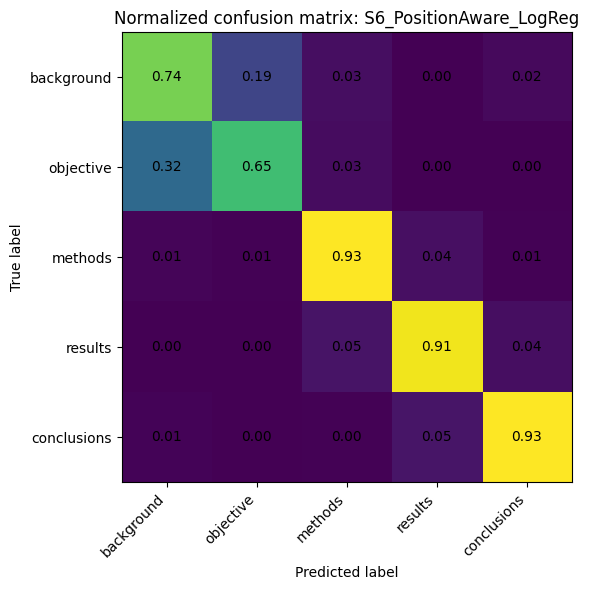

,true_label,pred_label,count,row_normalized_rate
4,objective,background,756,0.318182
0,background,objective,672,0.194839
19,conclusions,results,241,0.052597
14,results,methods,474,0.048166
10,methods,results,382,0.038338
15,results,conclusions,346,0.035159
1,background,methods,119,0.034503
5,objective,methods,77,0.032407
3,background,conclusions,84,0.024355
8,methods,background,137,0.013749


,position_band,n,accuracy,mean_length,stratifier,contains_number,length_bin,mean_position
0,0-20%,7041,0.775742,26.306064,position_band,NaN,NaN,NaN
1,20-40%,5542,0.896066,26.212739,position_band,NaN,NaN,NaN
2,40-60%,5545,0.923895,26.679892,position_band,NaN,NaN,NaN
3,60-80%,5542,0.935763,30.678095,position_band,NaN,NaN,NaN
4,80-100%,6542,0.910119,22.902476,position_band,NaN,NaN,NaN
5,NaN,14468,0.857271,20.848839,contains_number,False,NaN,NaN
6,NaN,15744,0.907520,31.544525,contains_number,True,NaN,NaN
7,NaN,8088,0.869065,NaN,length_bin,NaN,"(0.999, 16.0]",0.530249
8,NaN,7177,0.875714,NaN,length_bin,NaN,"(16.0, 23.0]",0.494833
9,NaN,7681,0.881786,NaN,length_bin,NaN,"(23.0, 33.0]",0.487891


In [ ]:

cm_raw = confusion_matrix(analysis_dev_gold, analysis_dev_pred, labels=LABEL_ORDER)
cm_norm = confusion_matrix(analysis_dev_gold, analysis_dev_pred, labels=LABEL_ORDER, normalize='true')

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm_norm)
ax.set_title(f'Normalized confusion matrix: {BEST_CLASSICAL_MODEL_NAME}')
ax.set_xticks(range(len(LABEL_ORDER)))
ax.set_yticks(range(len(LABEL_ORDER)))
ax.set_xticklabels(LABEL_ORDER, rotation=45, ha='right')
ax.set_yticklabels(LABEL_ORDER)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center')
plt.tight_layout()
plt.show()

pairwise_confusions = []
for i, true_lab in enumerate(LABEL_ORDER):
    for j, pred_lab in enumerate(LABEL_ORDER):
        if i == j:
            continue
        pairwise_confusions.append({
            'true_label': true_lab,
            'pred_label': pred_lab,
            'count': int(cm_raw[i, j]),
            'row_normalized_rate': float(cm_norm[i, j])
        })
pairwise_confusions_df = pd.DataFrame(pairwise_confusions).sort_values(['row_normalized_rate', 'count'], ascending=False)
display(pairwise_confusions_df.head(12))

error_strat_summary = []
for strat_col in ['position_band', 'contains_number']:
    tmp = analysis_dev_error_df.groupby(strat_col).agg(
        n=('correct', 'size'),
        accuracy=('correct', 'mean'),
        mean_length=('text_len_words', 'mean')
    ).reset_index()
    tmp['stratifier'] = strat_col
    error_strat_summary.append(tmp)

analysis_dev_error_df['length_bin'] = pd.qcut(analysis_dev_error_df['text_len_words'], q=4, duplicates='drop')
length_tmp = analysis_dev_error_df.groupby('length_bin').agg(
    n=('correct', 'size'),
    accuracy=('correct', 'mean'),
    mean_position=('relative_position', 'mean')
).reset_index()
length_tmp['stratifier'] = 'length_bin'
error_strat_summary.append(length_tmp)

error_strat_df = pd.concat(error_strat_summary, ignore_index=True)
display(error_strat_df)


### 24.4 Unsupervised structure discovery: clustering and projection

Clustering and projection are used only as descriptive diagnostics of feature-space structure, because low-dimensional plots can simplify high-dimensional text representations (Manning et al., 2008).

This subsection explores the latent structure of sentence representations using clustering and low-dimensional projection. The goal is descriptive rather than confirmatory: the plots help assess whether classes appear separable in feature space and whether ambiguous classes overlap. Projection methods should be interpreted cautiously because two-dimensional visualisations can distort high-dimensional distances.


Clustering agreement with gold labels: {'ARI': 0.01670255697790758, 'NMI': np.float64(0.0717756760868787)}


label,background,conclusions,methods,objective,results
cluster,,,,,
0,0.223,0.213,0.195,0.167,0.202
1,0.714,0.238,0.048,0.000,0.000
2,0.196,0.103,0.147,0.527,0.027
3,0.020,0.027,0.287,0.040,0.627
4,0.177,0.259,0.214,0.216,0.134


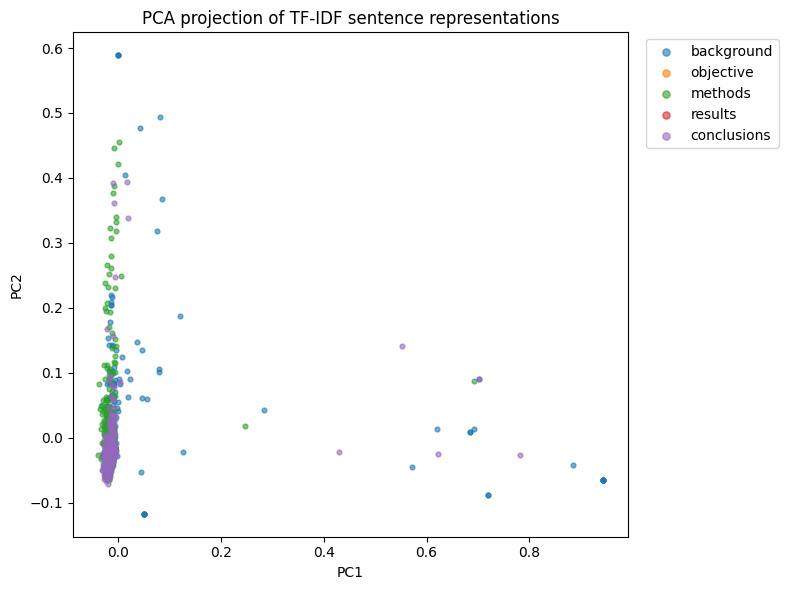

In [ ]:

cluster_sample = analysis_dev_df.groupby('label', group_keys=False).apply(lambda g: g.sample(min(len(g), 400), random_state=SEED)).reset_index(drop=True)
cluster_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words='english', max_features=12000)
X_cluster = cluster_vec.fit_transform(cluster_sample['text'])

kmeans = KMeans(n_clusters=len(LABEL_ORDER), random_state=SEED, n_init=10)
cluster_assignments = kmeans.fit_predict(X_cluster)

cluster_eval = {
    'ARI': adjusted_rand_score(cluster_sample['label'], cluster_assignments),
    'NMI': normalized_mutual_info_score(cluster_sample['label'], cluster_assignments)
}
print('Clustering agreement with gold labels:', cluster_eval)

cluster_profile = pd.crosstab(pd.Series(cluster_assignments, name='cluster'), cluster_sample['label'], normalize='index').round(3)
display(cluster_profile)

svd = TruncatedSVD(n_components=50, random_state=SEED)
X_reduced = svd.fit_transform(X_cluster)
plot_points = X_reduced
if len(cluster_sample) > 1200:
    plot_points = X_reduced[:1200]
    plot_labels = cluster_sample['label'].iloc[:1200].reset_index(drop=True)
else:
    plot_labels = cluster_sample['label'].reset_index(drop=True)

pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(plot_points)
plt.figure(figsize=(8, 6))
for label in LABEL_ORDER:
    mask = plot_labels == label
    plt.scatter(pca_2d[mask, 0], pca_2d[mask, 1], s=12, alpha=0.6, label=label)
plt.title('PCA projection of TF-IDF sentence representations')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(markerscale=1.5, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 24.5 Sequence pattern mining and structural justification

Sequence patterns are tested to justify whether position-aware and sequence-aware models are methodologically plausible for RCT abstracts (Dernoncourt & Lee, 2017; Lafferty et al., 2001).

In this section, This section examines whether abstracts follow a semi-structured rhetorical progression. The goal is not to assume that every abstract follows a perfectly fixed sequence such as:

Background → Objective → Methods → Results → Conclusions

Instead, the goal is to test whether sentence roles show strong enough structural tendencies to justify position features and sequence/context-aware models. Both statements can be true at the same time:

- abstract structure is informative;
- actual transition patterns remain heterogeneous and only partially canonical.


In [ ]:
def extract_label_transitions(df, label_col="label"):
    trans = Counter()
    seq_lengths = []
    for _, g in df.sort_values(["pubmed_id", "file_order"]).groupby("pubmed_id"):
        labs = g[label_col].tolist()
        seq_lengths.append(len(labs))
        for a, b in zip(labs[:-1], labs[1:]):
            trans[(a, b)] += 1
    trans_df = pd.DataFrame([
        {"from_label": a, "to_label": b, "count": c}
        for (a, b), c in trans.items()
    ]).sort_values("count", ascending=False)
    return trans_df, seq_lengths

true_transition_df, seq_lengths = extract_label_transitions(analysis_dev_df, label_col="label")
print("Most common true label transitions in the development abstracts")
display(true_transition_df.head(15))

print(
    "Interpretation note: these transitions should be read as evidence of a semi-structured rhetorical progression, "
    "not as proof of one perfectly fixed canonical sequence."
)

seq_candidates = pd.DataFrame()
if "dev_results" in globals() and len(dev_results) > 0 and "uses_sequence" in dev_results.columns:
    seq_candidates = dev_results[dev_results["uses_sequence"] == True]

if len(seq_candidates) > 0:
    best_seq_model_name = seq_candidates.sort_values("macro_f1", ascending=False).iloc[0]["model_name"]
    print("Best hold-out sequential/context-aware model:", best_seq_model_name)

    pred_seq_df = analysis_dev_df.copy()
    pred_labels = None

    if best_seq_model_name in globals().get("classical_dev_predictions", {}):
        pred_labels = classical_dev_predictions[best_seq_model_name]
    elif best_seq_model_name == "S7_CRF_SequenceModel" and "crf_dev_pred_flat" in globals() and crf_dev_pred_flat is not None:
        pred_labels = crf_dev_pred_flat
    elif best_seq_model_name == "S8_BiLSTMStyle_SequentialModel" and "y_pred_bilstm" in globals():
        pred_labels = y_pred_bilstm
    else:
        for run_name, trainer, dev_used, y_true_tf, y_pred_tf in globals().get("transformer_runs", []):
            if run_name == best_seq_model_name:
                pred_labels = y_pred_tf
                break

    if pred_labels is not None and len(pred_labels) == len(pred_seq_df):
        pred_seq_df["pred_label"] = pred_labels
        pred_transition_df, _ = extract_label_transitions(pred_seq_df, label_col="pred_label")
        print("Most common predicted label transitions")
        display(pred_transition_df.head(15))
    else:
        print("Predicted transition analysis could not be completed for the selected sequential/context-aware model.")
else:
    print("No sequential/context-aware candidates were available for transition comparison.")

Most common true label transitions in the development abstracts


,from_label,to_label,count
4,results,results,7479
2,methods,methods,7476
5,results,conclusions,2345
3,methods,results,2290
6,conclusions,conclusions,2107
7,background,background,1767
1,objective,methods,1539
8,background,methods,893
0,objective,objective,773
10,conclusions,background,428


Interpretation note: these transitions should be read as evidence of a semi-structured rhetorical progression, not as proof of one perfectly fixed canonical sequence.
No sequential/context-aware candidates were available for transition comparison.


### 24.6 Learning behaviour, confidence, and comparative failure analysis

Learning behaviour, confidence, and disagreement examples are compared to judge whether model complexity changes the type of error, not only the score (Bestgen, 2022; D'Amour et al., 2022).

This subsection analyses learning dynamics, prediction confidence, and failure cases across systems. Confidence distributions can reveal overconfident errors, while model-disagreement examples can show whether more complex systems correct meaningful errors or simply shift mistakes to different labels.


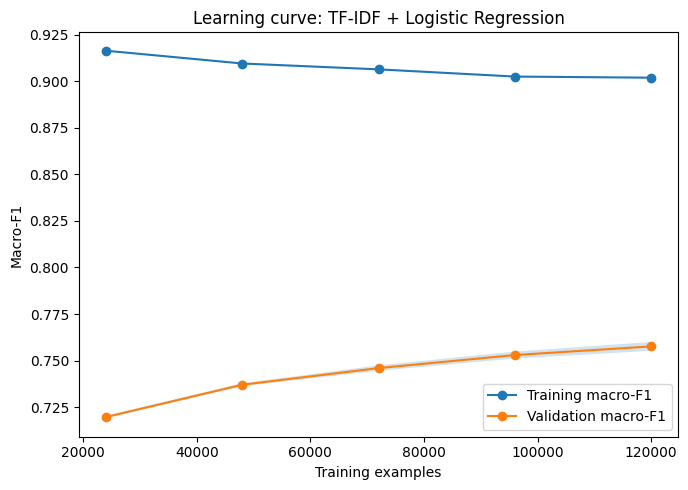

,bin,mean_confidence,empirical_accuracy,n
0,"(0.238, 0.572]",0.479632,0.447386,3022
1,"(0.572, 0.711]",0.643592,0.617345,3021
2,"(0.711, 0.824]",0.770076,0.727905,3021
3,"(0.824, 0.901]",0.865647,0.811321,3021
4,"(0.901, 0.948]",0.926560,0.884144,3021
5,"(0.948, 0.975]",0.962734,0.917246,3021
6,"(0.975, 0.989]",0.982261,0.951672,3021
7,"(0.989, 0.996]",0.992427,0.965243,3021
8,"(0.996, 0.999]",0.997498,0.984442,3021
9,"(0.999, 1.0]",0.999647,0.990073,3022


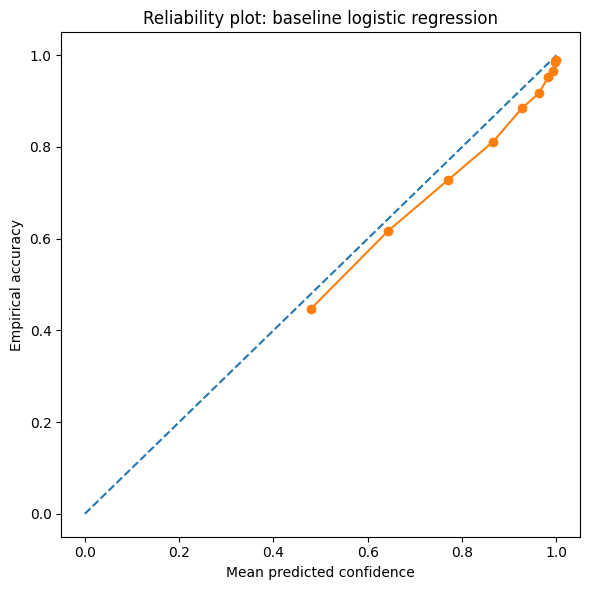

Highest-confidence logistic-regression errors


,label,pred_label,confidence,text
26175,methods,results,0.999997,P > 0.05 indicated no significant difference .
7846,results,methods,0.999977,Clinic-derived systolic blood pressure obtaine...
8348,methods,results,0.999967,Thromboses were more commonly incident ( n = 7...
6368,conclusions,methods,0.999956,All patients will be followed for 5 years .
19163,background,methods,0.999944,"A prospective , randomized , controlled , blin..."
15830,results,methods,0.999864,"In this randomised and controlled study , 31 C..."
23568,methods,results,0.999862,VO2 pic increased after AT ( 16.9 4.4 vs 18.9 ...
5143,conclusions,results,0.999838,Pain was significantly decreased in the girdle...
21951,results,methods,0.999822,"A double-blind , randomized , controlled trial..."
5674,conclusions,results,0.999813,"Compared with OP , PKEP was associated with le..."


Errors corrected by the stronger hold-out model but missed by the classical model


,label,classical_pred,other_pred,text
9,results,conclusions,results,"Moreover , we did not observe longitudinal ass..."
23,background,objective,background,The purpose of this study will be to evaluate ...
48,background,objective,background,We investigated clinical profile and outcomes ...
56,results,conclusions,results,Bradycardia occurred more frequently in ivabra...
62,methods,results,methods,When no active symptoms of infection were show...
84,objective,background,objective,Nonarteriitic anterior ischemic optic neuropat...
97,results,conclusions,results,PFX did not improve BCVA .
111,methods,results,methods,There were no opioids given peri-operatively .
125,results,methods,results,"At randomization , hs-TnI was analyzed in 14 8..."
126,results,methods,results,The associations between hs-TnI concentrations...


Errors captured by the classical model but missed by the stronger hold-out model


,label,classical_pred,other_pred,text
3,objective,objective,background,"In particular , fructose has been suggested to..."
50,methods,methods,results,Multivariate Cox model analyses were performed...
98,results,results,conclusions,"However , VF did not show any significant impr..."
109,background,background,methods,This paper describes a randomized prospective ...
119,results,results,methods,2 h ) and the late ( 2 ?
169,conclusions,conclusions,background,The use of e-health interventions provides an ...
193,methods,methods,conclusions,RESPECT includes a multimodal intervention pro...
277,objective,objective,background,Recent guidelines described the analysis of cl...
287,conclusions,conclusions,background,The assumptions about the missing data process...
304,methods,methods,results,DEFEND-2 terminated early after 12months ' eff...


In [ ]:
# Learning curve for the baseline lexical logistic regression
baseline_for_curve = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

train_sizes, train_scores, valid_scores = learning_curve(
    baseline_for_curve,
    analysis_train_df['text'],
    analysis_train_df['label'],
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    scoring='f1_macro',
    n_jobs=-1
)

plt.figure(figsize=(7, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), marker='o', label='Training macro-F1')
plt.plot(train_sizes, valid_scores.mean(axis=1), marker='o', label='Validation macro-F1')
plt.fill_between(train_sizes, valid_scores.mean(axis=1) - valid_scores.std(axis=1), valid_scores.mean(axis=1) + valid_scores.std(axis=1), alpha=0.2)
plt.title('Learning curve: TF-IDF + Logistic Regression')
plt.xlabel('Training examples')
plt.ylabel('Macro-F1')
plt.legend()
plt.tight_layout()
plt.show()

# Confidence and calibration analysis for a probabilistic classical model when available
calibration_rows = []
if 'S0_TFIDF_LogReg' in globals().get('classical_best_estimators', {}):
    cal_est = clone(classical_best_estimators['S0_TFIDF_LogReg'])
    cal_est.fit(analysis_train_df, analysis_train_df['label'])
    dev_prob = cal_est.predict_proba(analysis_dev_df[['text']])
    dev_pred = cal_est.predict(analysis_dev_df[['text']])
    pred_conf = dev_prob.max(axis=1)
    correctness = (dev_pred == analysis_dev_df['label'].values).astype(int)

    conf_df = pd.DataFrame({'confidence': pred_conf, 'correct': correctness})
    conf_df['bin'] = pd.qcut(conf_df['confidence'], q=10, duplicates='drop')
    calibration_table = conf_df.groupby('bin').agg(mean_confidence=('confidence', 'mean'), empirical_accuracy=('correct', 'mean'), n=('correct', 'size')).reset_index()
    display(calibration_table)

    plt.figure(figsize=(6, 6))
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.plot(calibration_table['mean_confidence'], calibration_table['empirical_accuracy'], marker='o')
    plt.xlabel('Mean predicted confidence')
    plt.ylabel('Empirical accuracy')
    plt.title('Reliability plot: baseline logistic regression')
    plt.tight_layout()
    plt.show()

    high_conf_errors = analysis_dev_df.copy()
    high_conf_errors['pred_label'] = dev_pred
    high_conf_errors['confidence'] = pred_conf
    high_conf_errors = high_conf_errors[high_conf_errors['label'] != high_conf_errors['pred_label']].sort_values('confidence', ascending=False)
    print('Highest-confidence logistic-regression errors')
    display(high_conf_errors[['label', 'pred_label', 'confidence', 'text']].head(10))
else:
    print('Probabilistic calibration analysis skipped because a logistic-regression estimator was not available.')

# Comparative failure analysis: strongest classical model vs best transformer/context-aware model if available
if len(dev_results) > 0:
    best_holdout_model = dev_results[dev_results['split_name'] == 'dev'].sort_values('macro_f1', ascending=False).iloc[0]['model_name']
    comparison_df = analysis_dev_df.copy()
    comparison_df['classical_pred'] = analysis_dev_pred
    other_pred = None
    if best_holdout_model in globals().get('classical_dev_predictions', {}):
        other_pred = classical_dev_predictions[best_holdout_model]
    elif best_holdout_model == 'S7_CRF_SequenceModel' and 'crf_dev_pred_flat' in globals() and crf_dev_pred_flat is not None:
        other_pred = crf_dev_pred_flat
    elif best_holdout_model == 'S8_BiLSTMStyle_SequentialModel' and 'y_pred_bilstm' in globals():
        other_pred = y_pred_bilstm
    else:
        for run_name, trainer, dev_used, y_true_tf, y_pred_tf in globals().get('transformer_runs', []):
            if run_name == best_holdout_model:
                other_pred = y_pred_tf
                break

    if other_pred is not None and len(other_pred) == len(comparison_df):
        comparison_df['other_pred'] = other_pred
        comparison_df['classical_correct'] = (comparison_df['classical_pred'] == comparison_df['label']).astype(int)
        comparison_df['other_correct'] = (comparison_df['other_pred'] == comparison_df['label']).astype(int)
        comparison_df['resolved_by_other'] = ((comparison_df['classical_correct'] == 0) & (comparison_df['other_correct'] == 1)).astype(int)
        comparison_df['resolved_by_classical'] = ((comparison_df['classical_correct'] == 1) & (comparison_df['other_correct'] == 0)).astype(int)

        print('Errors corrected by the stronger hold-out model but missed by the classical model')
        display(comparison_df[comparison_df['resolved_by_other'] == 1][['label', 'classical_pred', 'other_pred', 'text']].head(10))

        print('Errors captured by the classical model but missed by the stronger hold-out model')
        display(comparison_df[comparison_df['resolved_by_classical'] == 1][['label', 'classical_pred', 'other_pred', 'text']].head(10))
    else:
        print('Comparative failure analysis skipped because alternate-model predictions were unavailable or misaligned.')

### 24.7 Reader-facing interpretation notes

These notes are used to keep the reader-facing interpretation cautious about structural cues, model complexity, and behavioural reliability (Ribeiro et al., 2020; D'Amour et al., 2022).

The analyses above are used to support the following cautious interpretations:

- **Background and Objective confusion is systematic rather than random** when it persists in normalised confusions and recurring lexical-cue patterns.
- **Position features are interpretable as well as predictive** when label distributions and transition patterns show that sentence role is strongly tied to abstract structure.
- **Simple models remain competitive for understandable reasons** when methods and results sentences contain distinctive vocabulary and reporting conventions.
- **More complex models should be justified by error reduction and behavioural reliability**, not by a small raw-score improvement alone.


## 25. Final model selection logic

Model selection is defined before the final test evaluation so that the independent test set remains a genuine held-out assessment (Kohavi, 1995; Bestgen, 2022).

Final model selection follows a pre-test rule:

- classical models are shortlisted using training-split cross-validation;
- the final shortlist keeps the top four classical systems by training-split cross-validation, so the comparison includes strong classical baselines and the required simple baseline;
- sequential and transformer models are shortlisted using the fixed development split because repeated cross-validation is computationally expensive for these families;
- the final shortlist keeps the top two transformer systems by development Macro-F1 and the top additional non-transformer hold-out system;
- the independent test set is never used for model selection.

The final independent test evaluation is therefore a one-time assessment of models selected before viewing test-set performance.


In [ ]:
CLASSICAL_SELECTION_METRIC = "macro_f1_mean"
HOLDOUT_SELECTION_METRIC = "macro_f1"

ELIGIBLE_CLASSICAL_MODELS = [
    "S0_TFIDF_LogReg",
    "S1_TFIDF_LinearSVM",
    "S2_TFIDF_MNB",
    "S3_WordCharTFIDF_LinearSVM",
    "S4_fastTextStyle_ShallowClassifier",
    "S5_NumberNormalized_LogReg",
    "S6_PositionAware_LogReg",
    "S10_MLP_TFIDF"
]

ELIGIBLE_HOLDOUT_MODELS = [
    "S7_CRF_SequenceModel",
    "S8_BiLSTMStyle_SequentialModel",
    "S9_bert_base_sentence_only",
    "S9_bert_base_prev_plus_current",
    "S9_scibert_sentence_only",
    "S9_scibert_prev_plus_current",
    "S9_pubmedbert_sentence_only",
    "S9_pubmedbert_prev_plus_current"
]

classical_candidate_cols = [
    "model_name",
    "macro_f1_mean",
    "macro_f1_std",
    "accuracy_mean",
    "background_f1_mean",
    "objective_f1_mean",
]

classical_candidate_table = (
    classical_cv_summary[
        classical_cv_summary["model_name"].isin(ELIGIBLE_CLASSICAL_MODELS)
    ][classical_candidate_cols]
    .sort_values(CLASSICAL_SELECTION_METRIC, ascending=False)
    .reset_index(drop=True)
)

holdout_candidate_cols = [
    "model_name",
    "macro_f1",
    "weighted_f1",
    "accuracy",
    "background_f1",
    "objective_f1",
]

holdout_candidate_table = (
    dev_results[
        (dev_results["split_name"] == "dev") &
        (dev_results["model_name"].isin(ELIGIBLE_HOLDOUT_MODELS))
    ][holdout_candidate_cols]
    .sort_values(HOLDOUT_SELECTION_METRIC, ascending=False)
    .reset_index(drop=True)
)

print("Classical shortlist based on training-split cross-validation")
display(classical_candidate_table)

print("Hold-out shortlist for sequential / transformer models")
display(holdout_candidate_table)

Classical shortlist based on training-split cross-validation


,model_name,macro_f1_mean,macro_f1_std,accuracy_mean,background_f1_mean,objective_f1_mean
0,S6_PositionAware_LogReg,0.837351,0.001847,0.884692,0.749086,0.666540
1,S5_NumberNormalized_LogReg,0.766109,0.002492,0.827444,0.671608,0.617289
2,S1_TFIDF_LinearSVM,0.764629,0.002020,0.827205,0.667024,0.619273
3,S0_TFIDF_LogReg,0.763230,0.001954,0.824911,0.662113,0.618103
4,S2_TFIDF_MNB,0.692380,0.003144,0.780066,0.625455,0.451090


Hold-out shortlist for sequential / transformer models


,model_name,macro_f1,weighted_f1,accuracy,background_f1,objective_f1
0,S9_pubmedbert_prev_plus_current,0.865666,0.914057,0.914670,0.790857,0.694756
1,S9_scibert_prev_plus_current,0.859143,0.907823,0.908612,0.788886,0.687341
2,S9_bert_base_prev_plus_current,0.854576,0.905751,0.906924,0.783378,0.670330
3,S8_BiLSTMStyle_SequentialModel,0.850941,0.902146,0.903151,0.780456,0.644380
4,S9_pubmedbert_sentence_only,0.831941,0.885883,0.887032,0.756239,0.661610
5,S9_scibert_sentence_only,0.827762,0.880835,0.881769,0.745546,0.671942
6,S9_bert_base_sentence_only,0.823111,0.877884,0.878790,0.740534,0.658835
7,S7_CRF_SequenceModel,0.764797,0.802244,0.803489,0.698148,0.613155


## 26. Final retraining and independent test evaluation

Final systems are retrained under one stated policy so that the independent test comparison is aligned across classical, sequence, and transformer models (Dernoncourt & Lee, 2017; Kohavi, 1995).

Final systems are retrained using the same policy: the training split only (`train.txt`), followed by one evaluation on the untouched independent test set.

This policy is applied to:

- classical models;
- CRF;
- BiLSTM-style sequential models;
- transformers.

The development split is used for development, model comparison, and selection. It is not merged into final training in this notebook, so final comparisons remain aligned across model families. This design prioritises fair comparison over maximising final training-set size.


In [ ]:
# ============================================================
# SELECT FINAL SYSTEMS
# ============================================================
# Selection policy:
#   - top 4 classical systems by training-split cross-validation
#   - top 2 transformer systems by development-set macro-F1
#   - top 1 additional non-transformer holdout system
#   - always include the S0 TF-IDF logistic-regression baseline
#
# The independent test set is not used for this selection.
# ============================================================

N_FINAL_CLASSICAL = 4
N_FINAL_TRANSFORMER = 2
N_FINAL_EXTRA_HOLDOUT = 1

BASELINE_MODEL = "S0_TFIDF_LogReg"

# -----------------------------
# Top classical systems by training-split cross-validation
# -----------------------------
top_classical = (
    classical_candidate_table["model_name"]
    .head(N_FINAL_CLASSICAL)
    .tolist()
)

# -----------------------------
# Top transformer systems by development-set macro-F1
# -----------------------------
transformer_candidate_table = (
    holdout_candidate_table[
        holdout_candidate_table["model_name"].str.startswith("S9_")
    ]
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

top_transformers = (
    transformer_candidate_table["model_name"]
    .head(N_FINAL_TRANSFORMER)
    .tolist()
)

# -----------------------------
# Additional non-transformer holdout system
# -----------------------------
holdout_non_transformer_table = (
    holdout_candidate_table[
        ~holdout_candidate_table["model_name"].str.startswith("S9_")
    ]
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

already_selected = set(top_classical + top_transformers)

top_extra_holdout = (
    holdout_non_transformer_table[
        ~holdout_non_transformer_table["model_name"].isin(already_selected)
    ]["model_name"]
    .head(N_FINAL_EXTRA_HOLDOUT)
    .tolist()
)

# -----------------------------
# Combine all systems
# -----------------------------
FINAL_SYSTEMS = top_classical + top_transformers + top_extra_holdout

# Force include baseline for interpretability and paired comparison.
if BASELINE_MODEL not in FINAL_SYSTEMS:
    FINAL_SYSTEMS.append(BASELINE_MODEL)

# Remove duplicates while preserving order.
FINAL_SYSTEMS = list(dict.fromkeys(FINAL_SYSTEMS))

print("Final systems selected for one-time independent test evaluation:")
for i, name in enumerate(FINAL_SYSTEMS, start=1):
    print(f"{i}. {name}")


Final systems selected for one-time independent test evaluation:
1. S6_PositionAware_LogReg
2. S5_NumberNormalized_LogReg
3. S1_TFIDF_LinearSVM
4. S0_TFIDF_LogReg
5. S9_pubmedbert_prev_plus_current
6. S9_scibert_prev_plus_current
7. S8_BiLSTMStyle_SequentialModel



Retraining and evaluating: S6_PositionAware_LogReg
[efficiency] S6_PositionAware_LogReg | final_training: 356.56s, 1.9804s/1000 examples
[efficiency] S6_PositionAware_LogReg | final_test_inference: 0.53s, 0.0175s/1000 examples


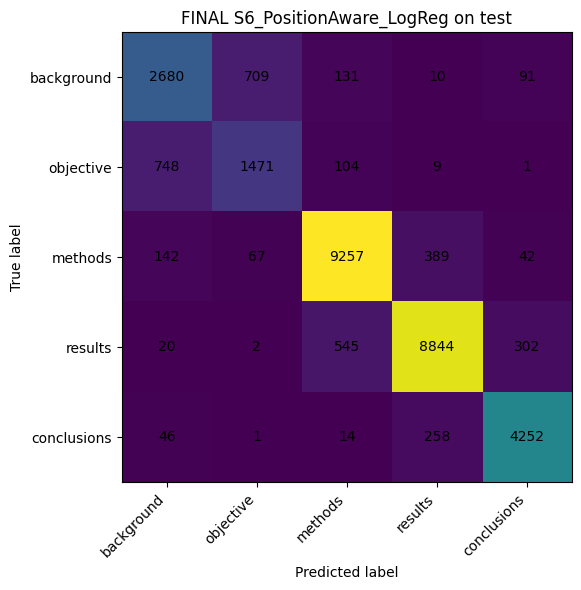


Retraining and evaluating: S5_NumberNormalized_LogReg
[efficiency] S5_NumberNormalized_LogReg | final_training: 132.74s, 0.7373s/1000 examples
[efficiency] S5_NumberNormalized_LogReg | final_test_inference: 0.50s, 0.0165s/1000 examples


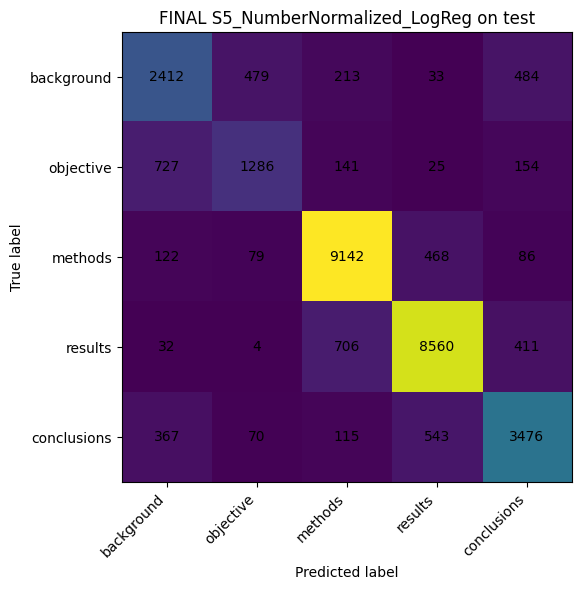


Retraining and evaluating: S1_TFIDF_LinearSVM
[efficiency] S1_TFIDF_LinearSVM | final_training: 8.43s, 0.0468s/1000 examples
[efficiency] S1_TFIDF_LinearSVM | final_test_inference: 0.52s, 0.0171s/1000 examples


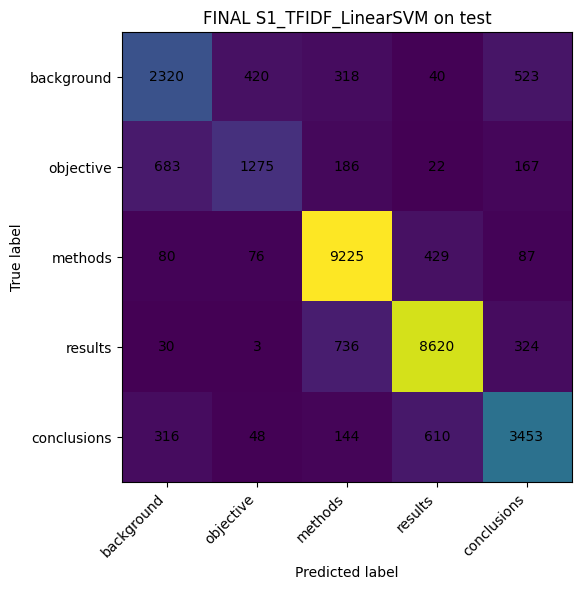


Retraining and evaluating: S0_TFIDF_LogReg
[efficiency] S0_TFIDF_LogReg | final_training: 174.08s, 0.9669s/1000 examples
[efficiency] S0_TFIDF_LogReg | final_test_inference: 0.51s, 0.0169s/1000 examples


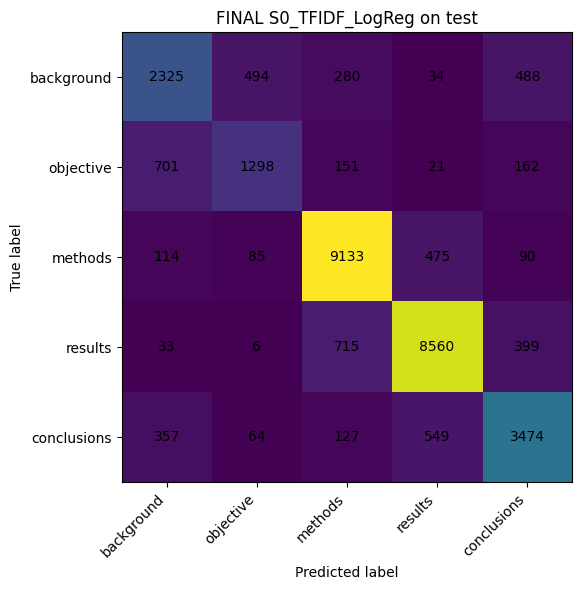


Retraining and evaluating: S9_pubmedbert_prev_plus_current


Map:   0%|          | 0/180040 [00:00<?, ? examples/s]

Map:   0%|          | 0/30135 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:

Step,Training Loss
100,0.801087
200,0.437956
300,0.432042
400,0.483565
500,0.470447
600,0.504441
700,0.313697
800,0.435578
900,0.448711
1000,0.414483


[efficiency] S9_pubmedbert_prev_plus_current | final_training: 1067.65s, 5.9301s/1000 examples


[efficiency] S9_pubmedbert_prev_plus_current | final_test_inference: 23.21s, 0.7701s/1000 examples


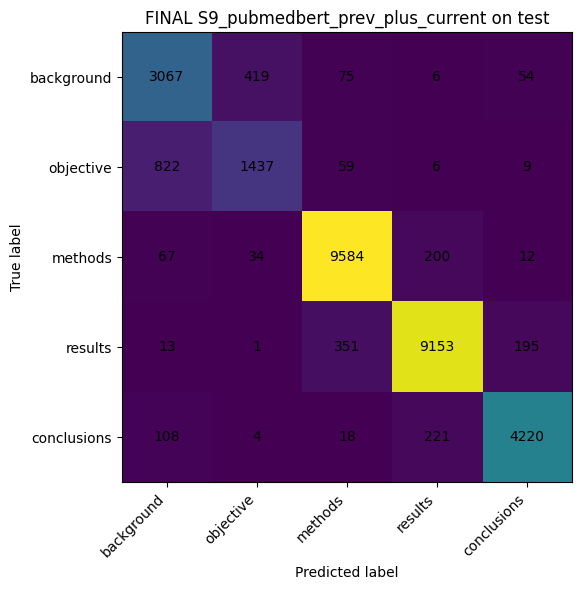


Retraining and evaluating: S9_scibert_prev_plus_current


Map:   0%|          | 0/180040 [00:00<?, ? examples/s]

Map:   0%|          | 0/30135 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were ne

Step,Training Loss
100,0.762115
200,0.433343
300,0.482291
400,0.511439
500,0.476976
600,0.485674
700,0.351349
800,0.411724
900,0.445141
1000,0.450079


Step,Training Loss
100,0.762115
200,0.433343
300,0.482291
400,0.511439
500,0.476976
600,0.485674
700,0.351349
800,0.411724
900,0.445141
1000,0.450079


[efficiency] S9_scibert_prev_plus_current | final_training: 1072.57s, 5.9574s/1000 examples


[efficiency] S9_scibert_prev_plus_current | final_test_inference: 23.21s, 0.7703s/1000 examples


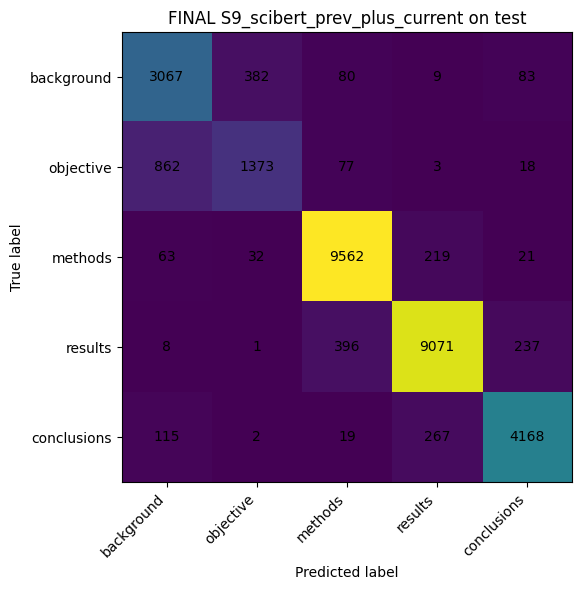


Retraining and evaluating: S8_BiLSTMStyle_SequentialModel
Epoch 1/5 - train loss: 0.4420
Epoch 2/5 - train loss: 0.2757
Epoch 3/5 - train loss: 0.2321
Epoch 4/5 - train loss: 0.1962
Epoch 5/5 - train loss: 0.1635
[efficiency] S8_BiLSTMStyle_SequentialModel | final_training: 14.26s, 0.9507s/1000 examples
[efficiency] S8_BiLSTMStyle_SequentialModel | final_test_inference: 0.43s, 0.1719s/1000 examples


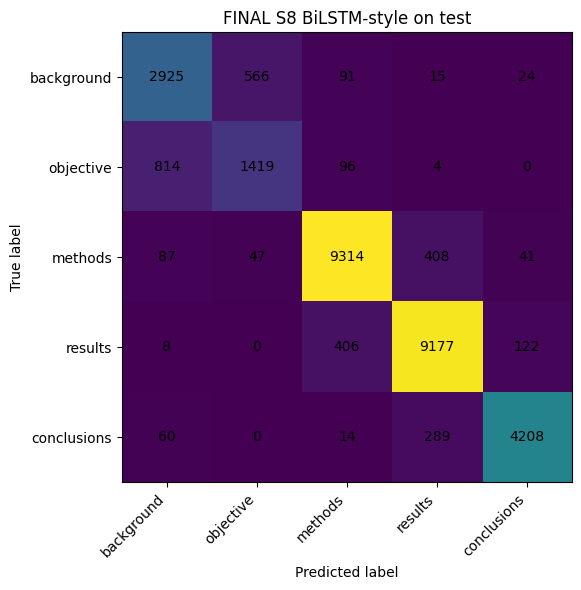

Stored final-test predictions for 7 model(s).
Independent test-set size captured for uncertainty analysis: 30135


,model_name,accuracy,macro_f1,weighted_f1,background_precision,background_recall,background_f1,objective_precision,objective_recall,objective_f1,methods_precision,methods_recall,methods_f1,results_precision,results_recall,results_f1,conclusions_precision,conclusions_recall,conclusions_f1
0,FINAL_S9_pubmedbert_prev_plus_current,0.911266,0.863153,0.910404,0.752269,0.847004,0.796830,0.758311,0.615945,0.679754,0.950134,0.968374,0.959167,0.954830,0.942345,0.948547,0.939866,0.923212,0.931465
1,FINAL_S9_scibert_prev_plus_current,0.903965,0.854156,0.902630,0.745322,0.847004,0.792916,0.767039,0.588513,0.666020,0.943556,0.966151,0.954720,0.947957,0.933903,0.940878,0.920698,0.911835,0.916245
2,FINAL_S8_BiLSTMStyle_SequentialModel,0.897395,0.848674,0.896687,0.751156,0.807788,0.778443,0.698327,0.608230,0.650172,0.938817,0.941093,0.939954,0.927626,0.944816,0.936142,0.957452,0.920586,0.938657
3,FINAL_S6_PositionAware_LogReg,0.879509,0.829451,0.879154,0.737074,0.740127,0.738597,0.653778,0.630519,0.641938,0.921003,0.935334,0.928113,0.929968,0.910532,0.920148,0.906997,0.930212,0.918458
4,FINAL_S1_TFIDF_LinearSVM,0.826049,0.763108,0.822816,0.676582,0.640707,0.658156,0.699780,0.546507,0.613718,0.869545,0.932101,0.899737,0.886740,0.887470,0.887105,0.758235,0.755415,0.756822
5,FINAL_S5_NumberNormalized_LogReg,0.825485,0.762871,0.823650,0.659016,0.666114,0.662546,0.670490,0.551222,0.605034,0.886110,0.923714,0.904522,0.888981,0.881293,0.885120,0.753849,0.760446,0.757134
6,FINAL_S0_TFIDF_LogReg,0.822631,0.759533,0.820459,0.658640,0.642088,0.650259,0.666667,0.556365,0.606542,0.877667,0.922805,0.899670,0.888059,0.881293,0.884663,0.753089,0.760009,0.756533


In [58]:
from sklearn.base import clone
import time
import gc

# Efficiency instrumentation should already be loaded in Section 2.2.
# The fallback below keeps Section 23 runnable if only this section is executed.
if "efficiency_records" not in globals():
    efficiency_records = []

if "time_efficiency_stage" not in globals():
    def time_efficiency_stage(model, stage, callable_fn, n_examples=None, notes=""):
        start = time.perf_counter()
        result = callable_fn()
        elapsed_seconds = time.perf_counter() - start
        efficiency_records.append({
            "model": str(model),
            "stage": str(stage),
            "n_examples": n_examples,
            "elapsed_seconds": elapsed_seconds,
            "elapsed_minutes": elapsed_seconds / 60,
            "seconds_per_1000_examples": elapsed_seconds / n_examples * 1000 if n_examples else np.nan,
            "examples_per_second": n_examples / elapsed_seconds if n_examples and elapsed_seconds > 0 else np.nan,
            "cpu_start_rss_gb": np.nan,
            "cpu_peak_rss_gb": np.nan,
            "cpu_end_rss_gb": np.nan,
            "cpu_peak_increment_gb": np.nan,
            "gpu_peak_allocated_gb": np.nan,
            "gpu_peak_reserved_gb": np.nan,
            "hardware": "not_recorded_fallback",
            "notes": str(notes),
        })
        return result


full_train_sent = train_df.copy()
full_train_seq = train_df.copy()
full_train_sent_ctx = add_prev_sentence_context(train_df.copy())
test_sent_ctx = add_prev_sentence_context(test_df.copy())

final_test_results = []

# These objects are populated during the one-time final test evaluation so that
# downstream uncertainty analysis can reuse the exact same independent-test predictions
# without re-running model fitting.
final_test_predictions = {}
final_test_y_true = None

# Registry used by the capability-oriented robustness evaluation section.
# It stores final fitted models and enough metadata to re-run prediction on perturbed inputs.
final_fitted_systems = {}


def store_final_test_predictions(model_name, y_true, y_pred):
    """Store one aligned set of gold labels plus per-model predictions for the final test set."""
    global final_test_y_true

    y_true_arr = np.asarray(y_true)
    y_pred_arr = np.asarray(y_pred)

    if final_test_y_true is None:
        final_test_y_true = y_true_arr.copy()
    else:
        if len(final_test_y_true) != len(y_true_arr) or not np.array_equal(final_test_y_true, y_true_arr):
            raise ValueError(
                f"Final test labels for {model_name} do not align with the stored independent test labels."
            )

    final_test_predictions[model_name] = y_pred_arr.copy()


def fit_final_classical_system(system_name):
    if system_name in globals().get("classical_best_estimators", {}):
        est = clone(classical_best_estimators[system_name])
        # Retrieve the spec to determine the correct input column for ColumnTransformers
        spec = CLASSICAL_MODEL_SPECS.get(system_name)
        text_col_for_system = "text" # Default
        if spec and "text_col" in spec:
            text_col_for_system = spec["text_col"]

        if isinstance(est, PositionAwareTextClassifier):
            est.fit(full_train_sent, full_train_sent["label"])
        else:
            # Pass the text column as a DataFrame to the ColumnTransformer-based pipeline
            est.fit(full_train_sent[[text_col_for_system]], full_train_sent["label"])
        return est

    if system_name == "S0_TFIDF_LogReg":
        est = Pipeline([
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
        ])
        est.fit(full_train_sent[["text"]], full_train_sent["label"])
        return est

    if system_name == "S1_TFIDF_LinearSVM":
        est = Pipeline([
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
            ("clf", LinearSVC())
        ])
        est.fit(full_train_sent[["text"]], full_train_sent["label"])
        return est

    if system_name == "S2_TFIDF_MNB":
        est = Pipeline([
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
            ("clf", MultinomialNB())
        ])
        est.fit(full_train_sent[["text"]], full_train_sent["label"])
        return est

    if system_name == "S6_PositionAware_LogReg":
        est = PositionAwareTextClassifier(C=1.0, class_weight="balanced")
        est.fit(full_train_sent, full_train_sent["label"])
        return est

    return None


def fit_final_crf():
    X_train_seq_full, y_train_seq_full, _ = df_to_abstract_sequences(full_train_seq)
    crf = sklearn_crfsuite.CRF(
        algorithm="lbfgs",
        c1=0.1,
        c2=0.1,
        max_iterations=100,
        all_possible_transitions=True
    )
    crf.fit(X_train_seq_full, y_train_seq_full)
    return crf


def predict_final_crf(crf_model_final):
    X_test_seq, y_test_seq, _ = df_to_abstract_sequences(test_df)
    pred_seq = crf_model_final.predict(X_test_seq)
    y_true_flat = [lab for seq in y_test_seq for lab in seq]
    y_pred_flat = [lab for seq in pred_seq for lab in seq]
    return y_true_flat, y_pred_flat


def fit_final_bilstm_style(epochs=None):
    use_epochs = 5 if epochs is None and not DEBUG_SMALL_MODE else 3 if epochs is None else epochs
    model, vocab, _, _ = run_bilstm_style_experiment(
        full_train_seq,
        test_df,  # only used to build a compatible dataset object; no tuning
        epochs=use_epochs
    )
    return model, vocab


def predict_final_bilstm_style(model, vocab):
    test_ds = AbstractSequenceDataset(test_df, vocab)
    test_loader = DataLoader(test_ds, batch_size=8, shuffle=False)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.eval()

    y_true, y_pred = [], []
    with torch.no_grad():
        for batch in test_loader:
            x = batch["input_ids"].to(device)
            y = batch["labels"].cpu().numpy()
            logits = model(x)
            pred = logits.argmax(dim=-1).cpu().numpy()
            for yi, pi in zip(y, pred):
                for yy, pp in zip(yi, pi):
                    if yy != -100:
                        y_true.append(ID2LABEL[int(yy)])
                        y_pred.append(ID2LABEL[int(pp)])
    return y_true, y_pred


def run_final_transformer(model_key, input_col="text", epochs=2, batch_size=8, system_name=None):
    from datasets import Dataset
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer

    model_name_or_path = TRANSFORMER_MODELS[model_key]
    tokenizer = AutoTokenizer.from_pretrained(model_name_or_path)

    train_source = full_train_sent_ctx if input_col == "text_with_prev" else full_train_sent
    test_source = test_sent_ctx if input_col == "text_with_prev" else test_df

    train_dataset = Dataset.from_pandas(
        train_source[[input_col, "label_id"]].rename(columns={input_col: "text", "label_id": "labels"})
    )
    test_dataset = Dataset.from_pandas(
        test_source[[input_col, "label_id"]].rename(columns={input_col: "text", "label_id": "labels"})
    )

    def tokenize_fn(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=128)

    train_dataset = train_dataset.map(tokenize_fn, batched=True)
    test_dataset = test_dataset.map(tokenize_fn, batched=True)

    cols_to_keep = ["input_ids", "attention_mask", "labels"]
    train_dataset.set_format(type="torch", columns=cols_to_keep)
    test_dataset.set_format(type="torch", columns=cols_to_keep)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name_or_path,
        num_labels=len(LABEL_ORDER),
        id2label=ID2LABEL,
        label2id=LABEL2ID
    )

    args = TrainingArguments(
        output_dir=f"./final_{model_key}_{input_col}",
        eval_strategy="no",
        save_strategy="no",
        logging_steps=100,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        learning_rate=2e-5,
        weight_decay=0.01,
        report_to=[]
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset
    )

    timing_model_name = system_name if system_name is not None else f"S9_{model_key}_{input_col}"

    _ = time_efficiency_stage(
        model=timing_model_name,
        stage="final_training",
        callable_fn=lambda: trainer.train(),
        n_examples=len(train_dataset),
        notes=f"transformer fine-tuning; model_key={model_key}; input_col={input_col}; epochs={epochs}; batch_size={batch_size}"
    )

    preds = time_efficiency_stage(
        model=timing_model_name,
        stage="final_test_inference",
        callable_fn=lambda: trainer.predict(test_dataset),
        n_examples=len(test_dataset),
        notes=f"transformer final test prediction; model_key={model_key}; input_col={input_col}; max_length=128"
    )

    y_true = [ID2LABEL[int(x)] for x in test_source["label_id"].tolist()]
    y_pred = [ID2LABEL[int(x)] for x in np.argmax(preds.predictions, axis=-1)]

    return y_true, y_pred, trainer, tokenizer


for system_name in FINAL_SYSTEMS:
    print(f"\nRetraining and evaluating: {system_name}")

    # Classical
    if system_name in ELIGIBLE_CLASSICAL_MODELS:
        est = time_efficiency_stage(
            model=system_name,
            stage="final_training",
            callable_fn=lambda: fit_final_classical_system(system_name),
            n_examples=len(full_train_sent),
            notes="classical final fit on full training split"
        )
        if est is None:
            print(f"Skipping {system_name}: estimator reconstruction failed.")
            continue

        # Retrieve the spec to determine the correct input column for ColumnTransformers
        spec = CLASSICAL_MODEL_SPECS.get(system_name)
        text_col_for_system = "text" # Default
        if spec and "text_col" in spec:
            text_col_for_system = spec["text_col"]

        def _predict_final_classical():
            if isinstance(est, PositionAwareTextClassifier):
                return est.predict(test_df)
            # Pass the text column as a DataFrame to the ColumnTransformer-based pipeline
            return est.predict(test_df[[text_col_for_system]])

        test_pred = time_efficiency_stage(
            model=system_name,
            stage="final_test_inference",
            callable_fn=_predict_final_classical,
            n_examples=len(test_df),
            notes=f"classical independent test prediction; text_col={text_col_for_system}"
        )

        final_fitted_systems[system_name] = {
            "family": "classical",
            "estimator": est,
            "text_col": text_col_for_system,
            "uses_position_features": isinstance(est, PositionAwareTextClassifier)
        }

        store_final_test_predictions(system_name, test_df["label"].tolist(), test_pred.tolist())
        final_test_results.append({
            "model_name": f"FINAL_{system_name}",
            **compute_metrics(test_df["label"].tolist(), test_pred.tolist())
        })
        plot_confusion_matrix(test_df["label"], test_pred, title=f"FINAL {system_name} on test")
        continue

    # CRF
    if system_name == "S7_CRF_SequenceModel" and RUN_CRF and HAS_CRF:
        crf_final = time_efficiency_stage(
            model=system_name,
            stage="final_training",
            callable_fn=fit_final_crf,
            n_examples=full_train_seq["pubmed_id"].nunique() if "pubmed_id" in full_train_seq.columns else len(full_train_seq),
            notes="CRF final fit on training abstract sequences"
        )
        y_true_flat, y_pred_flat = time_efficiency_stage(
            model=system_name,
            stage="final_test_inference",
            callable_fn=lambda: predict_final_crf(crf_final),
            n_examples=test_df["pubmed_id"].nunique() if "pubmed_id" in test_df.columns else len(test_df),
            notes="CRF independent test sequence prediction"
        )
        final_fitted_systems[system_name] = {"family": "sequence_crf", "model": crf_final}
        store_final_test_predictions(system_name, y_true_flat, y_pred_flat)
        final_test_results.append({
            "model_name": "FINAL_S7_CRF_SequenceModel",
            **compute_metrics(y_true_flat, y_pred_flat)
        })
        plot_confusion_matrix(y_true_flat, y_pred_flat, title="FINAL S7 CRF on test")
        continue

    # BiLSTM-style
    if system_name == "S8_BiLSTMStyle_SequentialModel" and RUN_BILSTM_STYLE:
        bilstm_final, bilstm_vocab_final = time_efficiency_stage(
            model=system_name,
            stage="final_training",
            callable_fn=fit_final_bilstm_style,
            n_examples=full_train_seq["pubmed_id"].nunique() if "pubmed_id" in full_train_seq.columns else len(full_train_seq),
            notes=f"BiLSTM-style final fit; epochs={5 if not DEBUG_SMALL_MODE else 3}; batch_size=8"
        )
        y_true_bilstm_test, y_pred_bilstm_test = time_efficiency_stage(
            model=system_name,
            stage="final_test_inference",
            callable_fn=lambda: predict_final_bilstm_style(bilstm_final, bilstm_vocab_final),
            n_examples=test_df["pubmed_id"].nunique() if "pubmed_id" in test_df.columns else len(test_df),
            notes="BiLSTM-style independent test sequence prediction"
        )
        final_fitted_systems[system_name] = {"family": "sequence_bilstm", "model": bilstm_final, "vocab": bilstm_vocab_final}
        store_final_test_predictions(system_name, y_true_bilstm_test, y_pred_bilstm_test)
        final_test_results.append({
            "model_name": "FINAL_S8_BiLSTMStyle_SequentialModel",
            **compute_metrics(y_true_bilstm_test, y_pred_bilstm_test)
        })
        plot_confusion_matrix(y_true_bilstm_test, y_pred_bilstm_test, title="FINAL S8 BiLSTM-style on test")
        continue

    # Transformers
    if system_name.startswith("S9_") and RUN_TRANSFORMERS and HAS_TRANSFORMERS:
        if "pubmedbert" in system_name:
            model_key = "pubmedbert"
        elif "scibert" in system_name:
            model_key = "scibert"
        else:
            model_key = "bert_base"

        input_col = "text_with_prev" if "prev_plus_current" in system_name else "text"
        y_true_tf_test, y_pred_tf_test, final_trainer, final_tokenizer = run_final_transformer(
            model_key=model_key,
            input_col=input_col,
            epochs=globals().get("TRANSFORMER_EPOCHS_FINAL", 2 if not DEBUG_SMALL_MODE else 1),
            batch_size=globals().get("TRANSFORMER_BATCH_SIZE", 8),
            system_name=system_name
        )
        final_fitted_systems[system_name] = {
            "family": "transformer",
            "trainer": final_trainer,
            "tokenizer": final_tokenizer,
            "model_key": model_key,
            "input_col": input_col,
            "max_length": 128
        }
        store_final_test_predictions(system_name, y_true_tf_test, y_pred_tf_test)
        final_test_results.append({
            "model_name": f"FINAL_{system_name}",
            **compute_metrics(y_true_tf_test, y_pred_tf_test)
        })
        plot_confusion_matrix(y_true_tf_test, y_pred_tf_test, title=f"FINAL {system_name} on test")
        continue

    print(f"Skipping {system_name}: prerequisites not available.")

final_test_results_df = pd.DataFrame(final_test_results).sort_values("macro_f1", ascending=False).reset_index(drop=True)

print(f"Stored final-test predictions for {len(final_test_predictions)} model(s).")
print(f"Independent test-set size captured for uncertainty analysis: {0 if final_test_y_true is None else len(final_test_y_true)}")

display(final_test_results_df)


### 26.1 Final model training protocol audit

This protocol audit is added so the final Methods or Supplement can state exactly which training policy and constraints applied to each model family (Pedregosa et al., 2011; Wolf et al., 2020).

This audit table records the protocol used for the final fitted models. It is placed after final retraining and independent test evaluation because it depends on objects such as `FINAL_SYSTEMS`, `final_fitted_systems`, and `final_test_results_df`.

The table should be used in the Methods or Supplement to report which model families used full training, which used fixed development-selected hyperparameters, and whether sample caps or epoch limits were applied.


In [59]:
# ============================================================
# FINAL MODEL TRAINING PROTOCOL AUDIT
# ============================================================
# Purpose:
#   Explicitly document which final systems used full training,
#   which systems used fixed development-selected settings, and which
#   systems had practical caps such as epochs or transformer training limits.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

required_objects = ["FINAL_SYSTEMS", "final_test_results_df", "final_fitted_systems"]
missing = [obj for obj in required_objects if obj not in globals()]
if missing:
    raise NameError(
        "Run Section 23 final retraining and independent test evaluation first. "
        f"Missing objects: {missing}"
    )

if "OUTPUT_DIR" not in globals():
    if "OUT_DIR" in globals():
        OUTPUT_DIR = Path(OUT_DIR)
    else:
        OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

final_model_protocol_rows = []

for model_name in FINAL_SYSTEMS:

    final_metrics_available = (
        "model_name" in final_test_results_df.columns
        and f"FINAL_{model_name}" in final_test_results_df["model_name"].astype(str).values
    )

    fitted_available = model_name in final_fitted_systems

    if model_name in CLASSICAL_MODEL_SPECS:
        final_model_protocol_rows.append({
            "model": model_name,
            "family": CLASSICAL_MODEL_SPECS[model_name].get("family", "classical"),
            "selection_basis": "training_split_stratified_cross_validation",
            "final_training_data": "full_train_split" if TRAIN_FRAC == 1.0 else f"{TRAIN_FRAC:.0%}_train_split_sample",
            "final_training_rows_or_abstracts": len(full_train_sent) if "full_train_sent" in globals() else np.nan,
            "hyperparameter_policy": "selected_by_training_split_CV_only",
            "development_used_for_final_training": False,
            "test_used_for_tuning": False,
            "sample_cap": "none" if TRAIN_FRAC == 1.0 else f"TRAIN_FRAC={TRAIN_FRAC}",
            "epochs": "not_applicable",
            "final_metrics_available": final_metrics_available,
            "fitted_object_available": fitted_available,
            "interpretation_note": "Strict final-test comparison: trained on training split only and evaluated once on independent test split.",
        })

    elif model_name == "S7_CRF_SequenceModel":
        final_model_protocol_rows.append({
            "model": model_name,
            "family": "sequence_crf",
            "selection_basis": "development_holdout",
            "final_training_data": "full_train_split" if SEQ_TRAIN_ABSTRACT_FRAC == 1.0 else f"{SEQ_TRAIN_ABSTRACT_FRAC:.0%}_train_abstract_sample",
            "final_training_rows_or_abstracts": full_train_seq["pubmed_id"].nunique() if "full_train_seq" in globals() else np.nan,
            "hyperparameter_policy": "fixed_after_development",
            "development_used_for_final_training": False,
            "test_used_for_tuning": False,
            "sample_cap": "none" if SEQ_TRAIN_ABSTRACT_FRAC == 1.0 else f"SEQ_TRAIN_ABSTRACT_FRAC={SEQ_TRAIN_ABSTRACT_FRAC}",
            "epochs": "not_applicable",
            "final_metrics_available": final_metrics_available,
            "fitted_object_available": fitted_available,
            "interpretation_note": "Sequence model trained on training abstracts only; development set used for selection, not final training.",
        })

    elif model_name == "S8_BiLSTMStyle_SequentialModel":
        final_model_protocol_rows.append({
            "model": model_name,
            "family": "sequence_bilstm",
            "selection_basis": "development_holdout",
            "final_training_data": "full_train_split" if SEQ_TRAIN_ABSTRACT_FRAC == 1.0 else f"{SEQ_TRAIN_ABSTRACT_FRAC:.0%}_train_abstract_sample",
            "final_training_rows_or_abstracts": full_train_seq["pubmed_id"].nunique() if "full_train_seq" in globals() else np.nan,
            "hyperparameter_policy": "fixed_after_development",
            "development_used_for_final_training": False,
            "test_used_for_tuning": False,
            "sample_cap": "none" if SEQ_TRAIN_ABSTRACT_FRAC == 1.0 else f"SEQ_TRAIN_ABSTRACT_FRAC={SEQ_TRAIN_ABSTRACT_FRAC}",
            "epochs": globals().get("BILSTM_EPOCHS_FINAL", 5 if not DEBUG_SMALL_MODE else 3),
            "final_metrics_available": final_metrics_available,
            "fitted_object_available": fitted_available,
            "interpretation_note": "BiLSTM-style model trained on training abstracts only; capability benchmark later treats rows as one-sentence pseudo-abstracts.",
        })

    elif str(model_name).startswith("S9_"):
        final_model_protocol_rows.append({
            "model": model_name,
            "family": "transformer",
            "selection_basis": "development_holdout",
            "final_training_data": "full_train_split" if globals().get("MAX_TRANSFORMER_TRAIN", None) is None else "capped_train_split",
            "final_training_rows_or_abstracts": len(full_train_sent_ctx) if "full_train_sent_ctx" in globals() else np.nan,
            "hyperparameter_policy": "fixed_after_development",
            "development_used_for_final_training": False,
            "test_used_for_tuning": False,
            "sample_cap": "none" if globals().get("MAX_TRANSFORMER_TRAIN", None) is None else f"MAX_TRANSFORMER_TRAIN={MAX_TRANSFORMER_TRAIN}",
            "epochs": globals().get("TRANSFORMER_EPOCHS_FINAL", 2 if not DEBUG_SMALL_MODE else 1),
            "final_metrics_available": final_metrics_available,
            "fitted_object_available": fitted_available,
            "interpretation_note": "Transformer fine-tuned on training split only; development set used for model selection and fixed settings.",
        })

    else:
        final_model_protocol_rows.append({
            "model": model_name,
            "family": "unknown",
            "selection_basis": "manual_review_required",
            "final_training_data": "manual_review_required",
            "final_training_rows_or_abstracts": np.nan,
            "hyperparameter_policy": "manual_review_required",
            "development_used_for_final_training": np.nan,
            "test_used_for_tuning": np.nan,
            "sample_cap": "manual_review_required",
            "epochs": np.nan,
            "final_metrics_available": final_metrics_available,
            "fitted_object_available": fitted_available,
            "interpretation_note": "Protocol could not be inferred automatically; check code manually.",
        })

final_model_protocol_df = pd.DataFrame(final_model_protocol_rows)

print("Final model training protocol audit:")
display(final_model_protocol_df)

protocol_path = OUTPUT_DIR / "final_model_training_protocol.csv"
final_model_protocol_df.to_csv(protocol_path, index=False)

print("Saved final model protocol table to:")
print(protocol_path)


Final model training protocol audit:


,model,family,selection_basis,final_training_data,final_training_rows_or_abstracts,hyperparameter_policy,development_used_for_final_training,test_used_for_tuning,sample_cap,epochs,final_metrics_available,fitted_object_available,interpretation_note
0,S6_PositionAware_LogReg,classical_position,training_split_stratified_cross_validation,full_train_split,180040,selected_by_training_split_CV_only,False,False,none,not_applicable,True,True,Strict final-test comparison: trained on train...
1,S5_NumberNormalized_LogReg,classical_text,training_split_stratified_cross_validation,full_train_split,180040,selected_by_training_split_CV_only,False,False,none,not_applicable,True,True,Strict final-test comparison: trained on train...
2,S1_TFIDF_LinearSVM,classical_text,training_split_stratified_cross_validation,full_train_split,180040,selected_by_training_split_CV_only,False,False,none,not_applicable,True,True,Strict final-test comparison: trained on train...
3,S0_TFIDF_LogReg,classical_text,training_split_stratified_cross_validation,full_train_split,180040,selected_by_training_split_CV_only,False,False,none,not_applicable,True,True,Strict final-test comparison: trained on train...
4,S9_pubmedbert_prev_plus_current,transformer,development_holdout,full_train_split,180040,fixed_after_development,False,False,none,2,True,True,Transformer fine-tuned on training split only;...
5,S9_scibert_prev_plus_current,transformer,development_holdout,full_train_split,180040,fixed_after_development,False,False,none,2,True,True,Transformer fine-tuned on training split only;...
6,S8_BiLSTMStyle_SequentialModel,sequence_bilstm,development_holdout,full_train_split,15000,fixed_after_development,False,False,none,5,True,True,BiLSTM-style model trained on training abstrac...


Saved final model protocol table to:
/content/drive/MyDrive/pubmed_rct_outputs/final_model_training_protocol.csv


## 27. Statistical validation of model differences

Uncertainty is quantified on final predictions because point estimates alone can make small model differences look more decisive than they are (Efron & Tibshirani, 1993; Bestgen, 2022).

In this section, Uncertainty is quantified around the same independent test-set predictions generated above. No model is retrained here. Bootstrap procedures resample aligned test examples so paired comparisons are computed on identical observations.

Outputs:

- model-level Macro-F1 median and 95% bootstrap confidence interval;
- paired bootstrap differences between the strongest available models;
- standardised effect-size summaries for paired differences, with conservative magnitude labels.

Bootstrap confidence intervals are included because model rankings based only on point estimates can exaggerate small or unstable differences (Efron & Tibshirani, 1993; Bestgen, 2022).


### 27.1 Bootstrap Macro-F1 confidence intervals

This cell estimates bootstrap confidence intervals to report uncertainty around final Macro-F1 rather than only a single score (Efron & Tibshirani, 1993; Bestgen, 2022).

In this cell, This cell estimates model-level uncertainty around final independent-test Macro-F1. The bootstrap constants and helper functions defined here are reused by the paired comparison cell that follows.


In [60]:
# ============================================================
# STATISTICAL VALIDATION OF MODEL DIFFERENCES
# Uses final_test_y_true and final_test_predictions from the one-time
# independent test evaluation. No retraining occurs in this section.
# ============================================================

BOOTSTRAP_RANDOM_STATE = SEED
BOOTSTRAP_N_REPLICATES = 1000
BOOTSTRAP_CI_ALPHA = 0.05


def _as_clean_model_name(name: str) -> str:
    """Remove FINAL_ prefix where needed so tables can be merged consistently."""
    return str(name).replace("FINAL_", "", 1)


def macro_f1_from_arrays(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


def bootstrap_macro_f1_distribution(y_true, y_pred, n_bootstrap=1000, random_state=42):
    """Return bootstrap macro-F1 values from resampling aligned test examples."""
    rng = np.random.default_rng(random_state)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    n = len(y_true)
    scores = np.empty(n_bootstrap, dtype=float)

    for b in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        scores[b] = macro_f1_from_arrays(y_true[idx], y_pred[idx])
    return scores


def paired_bootstrap_difference_distribution(y_true, y_pred_a, y_pred_b, n_bootstrap=1000, random_state=42):
    """Return bootstrap distribution of ΔMacro-F1 = Model A - Model B."""
    rng = np.random.default_rng(random_state)
    y_true = np.asarray(y_true)
    y_pred_a = np.asarray(y_pred_a)
    y_pred_b = np.asarray(y_pred_b)
    n = len(y_true)
    deltas = np.empty(n_bootstrap, dtype=float)

    for b in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        deltas[b] = (
            macro_f1_from_arrays(y_true[idx], y_pred_a[idx]) -
            macro_f1_from_arrays(y_true[idx], y_pred_b[idx])
        )
    return deltas


def cohen_d_from_bootstrap_deltas(deltas):
    """Standardised bootstrap-difference effect size."""
    deltas = np.asarray(deltas, dtype=float)
    sd = np.std(deltas, ddof=1)
    if sd == 0 or np.isnan(sd):
        return np.nan
    return float(np.mean(deltas) / sd)


def effect_size_label(d):
    if pd.isna(d):
        return "not estimable"
    ad = abs(d)
    if ad < 0.2:
        return "negligible"
    if ad < 0.5:
        return "small"
    if ad < 0.8:
        return "medium"
    return "large"


bootstrap_summary_rows = []
bootstrap_distributions = {}

if final_test_y_true is None or len(final_test_predictions) == 0:
    print("Statistical validation skipped because final test predictions are not available.")
    bootstrap_summary_df = pd.DataFrame()
else:
    y_true_arr = np.asarray(final_test_y_true)

    for i, (model_name, y_pred_arr) in enumerate(final_test_predictions.items()):
        y_pred_arr = np.asarray(y_pred_arr)
        boot_scores = bootstrap_macro_f1_distribution(
            y_true_arr,
            y_pred_arr,
            n_bootstrap=BOOTSTRAP_N_REPLICATES,
            random_state=BOOTSTRAP_RANDOM_STATE + i,
        )
        bootstrap_distributions[model_name] = boot_scores
        observed = macro_f1_from_arrays(y_true_arr, y_pred_arr)
        bootstrap_summary_rows.append({
            "Model": model_name,
            "Macro-F1": observed,
            "Bootstrap median Macro-F1": float(np.median(boot_scores)),
            "95% CI low": float(np.quantile(boot_scores, BOOTSTRAP_CI_ALPHA / 2)),
            "95% CI high": float(np.quantile(boot_scores, 1 - BOOTSTRAP_CI_ALPHA / 2)),
            "n_test_examples": int(len(y_true_arr)),
            "n_bootstrap": int(BOOTSTRAP_N_REPLICATES),
        })

    bootstrap_summary_df = (
        pd.DataFrame(bootstrap_summary_rows)
        .sort_values("Macro-F1", ascending=False)
        .reset_index(drop=True)
    )

    print("Table: Model-level macro-F1 uncertainty on the independent test set")
    display(bootstrap_summary_df.round(4))


Table: Model-level macro-F1 uncertainty on the independent test set


,Model,Macro-F1,Bootstrap median Macro-F1,95% CI low,95% CI high,n_test_examples,n_bootstrap
0,S9_pubmedbert_prev_plus_current,0.8632,0.8631,0.8582,0.8681,30135,1000
1,S9_scibert_prev_plus_current,0.8542,0.8540,0.8490,0.8589,30135,1000
2,S8_BiLSTMStyle_SequentialModel,0.8487,0.8487,0.8434,0.8537,30135,1000
3,S6_PositionAware_LogReg,0.8295,0.8292,0.8244,0.8347,30135,1000
4,S1_TFIDF_LinearSVM,0.7631,0.7631,0.7568,0.7688,30135,1000
5,S5_NumberNormalized_LogReg,0.7629,0.7630,0.7568,0.7689,30135,1000
6,S0_TFIDF_LogReg,0.7595,0.7596,0.7539,0.7649,30135,1000


### 27.2 Paired bootstrap final-test model comparisons

Paired bootstrap comparisons because the same test sentences are evaluated by each selected model (Efron & Tibshirani, 1993; Bestgen, 2022).

This cell compares selected final models on the same independent test examples. The paired design is important because each model is evaluated on identical sentences; the relevant quantity is the distribution of paired Macro-F1 differences, not two unrelated performance estimates.


In [110]:
# ============================================================
# PAIRED BOOTSTRAP DIFFERENCE TESTS BETWEEN TOP MODELS
# Primary comparison is PubMedBERT vs BiLSTM when available.
# Otherwise the cell automatically compares the top available models by
# independent-test Macro-F1. No models are retrained.
# ============================================================

paired_bootstrap_rows = []

if final_test_y_true is None or len(final_test_predictions) < 2:
    print("Paired bootstrap comparison skipped because at least two final prediction arrays are required.")
    paired_bootstrap_comparison_df = pd.DataFrame()
else:
    y_true_arr = np.asarray(final_test_y_true)

    observed_perf = pd.DataFrame([
        {
            "model": model_name,
            "macro_f1": macro_f1_from_arrays(y_true_arr, np.asarray(y_pred))
        }
        for model_name, y_pred in final_test_predictions.items()
    ]).sort_values("macro_f1", ascending=False).reset_index(drop=True)

    def _find_first_model_containing(patterns):
        for pat in patterns:
            matches = [m for m in final_test_predictions.keys() if pat.lower() in m.lower()]
            if matches:
                # choose the best-performing matching model if there are variants
                match_df = observed_perf[observed_perf["model"].isin(matches)]
                return match_df.iloc[0]["model"]
        return None

    pubmedbert_model = _find_first_model_containing(["pubmedbert"])
    bilstm_model = _find_first_model_containing(["bilstm"])

    comparison_pairs = []
    if pubmedbert_model is not None and bilstm_model is not None and pubmedbert_model != bilstm_model:
        comparison_pairs.append((pubmedbert_model, bilstm_model, "Primary: PubMedBERT vs BiLSTM"))

    # Add top-model comparisons so the section remains valid if one family was not run.
    top_models = observed_perf["model"].tolist()[:min(4, len(observed_perf))]
    for i in range(len(top_models)):
        for j in range(i + 1, len(top_models)):
            pair = (top_models[i], top_models[j], "Top-model paired comparison")
            if (pair[0], pair[1]) not in [(a, b) for a, b, _ in comparison_pairs]:
                comparison_pairs.append(pair)

    for k, (model_a, model_b, comparison_type) in enumerate(comparison_pairs):
        deltas = paired_bootstrap_difference_distribution(
            y_true_arr,
            np.asarray(final_test_predictions[model_a]),
            np.asarray(final_test_predictions[model_b]),
            n_bootstrap=BOOTSTRAP_N_REPLICATES,
            random_state=BOOTSTRAP_RANDOM_STATE + 100 + k,
        )
        observed_delta = (
            macro_f1_from_arrays(y_true_arr, np.asarray(final_test_predictions[model_a])) -
            macro_f1_from_arrays(y_true_arr, np.asarray(final_test_predictions[model_b]))
        )
        d_value = cohen_d_from_bootstrap_deltas(deltas)
        paired_bootstrap_rows.append({
            "Model A": model_a,
            "Model B": model_b,
            "Comparison": comparison_type,
            "ΔF1 (A-B)": float(observed_delta),
            "Bootstrap median ΔF1": float(np.median(deltas)),
            "95% CI low": float(np.quantile(deltas, BOOTSTRAP_CI_ALPHA / 2)),
            "95% CI high": float(np.quantile(deltas, 1 - BOOTSTRAP_CI_ALPHA / 2)),
            "P(ΔF1 > 0)": float(np.mean(deltas > 0)),
            "Cohen_d_bootstrap_delta": d_value,
            "Effect magnitude": effect_size_label(d_value),
        })

    paired_bootstrap_comparison_df = pd.DataFrame(paired_bootstrap_rows).reset_index(drop=True)
    print("Table: Paired bootstrap difference tests on the same independent test examples")
    display(paired_bootstrap_comparison_df.round(4))


Table: Paired bootstrap difference tests on the same independent test examples


,Model A,Model B,Comparison,ΔF1 (A-B),Bootstrap median ΔF1,95% CI low,95% CI high,P(ΔF1 > 0),Cohen_d_bootstrap_delta,Effect magnitude
0,S9_pubmedbert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,Primary: PubMedBERT vs BiLSTM,0.0145,0.0142,0.0090,0.0200,1.000,5.1993,large
1,S9_pubmedbert_prev_plus_current,S9_scibert_prev_plus_current,Top-model paired comparison,0.0090,0.0090,0.0050,0.0128,1.000,4.5959,large
2,S9_pubmedbert_prev_plus_current,S6_PositionAware_LogReg,Top-model paired comparison,0.0337,0.0337,0.0285,0.0391,1.000,12.4771,large
3,S9_scibert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,Top-model paired comparison,0.0055,0.0054,0.0002,0.0110,0.981,2.0243,large
4,S9_scibert_prev_plus_current,S6_PositionAware_LogReg,Top-model paired comparison,0.0247,0.0248,0.0193,0.0297,1.000,8.7765,large
5,S8_BiLSTMStyle_SequentialModel,S6_PositionAware_LogReg,Top-model paired comparison,0.0192,0.0192,0.0145,0.0239,1.000,7.6170,large


### 27.3 Paired Macro-F1 difference plot

This plot visualises paired Macro-F1 differences so the direction and interval width of model differences are visible together (Efron & Tibshirani, 1993; Bestgen, 2022).

This plot visualises paired bootstrap Macro-F1 differences and their 95% confidence intervals. It supports interpretation of both direction and uncertainty, rather than reporting only whether one model has the largest point estimate.


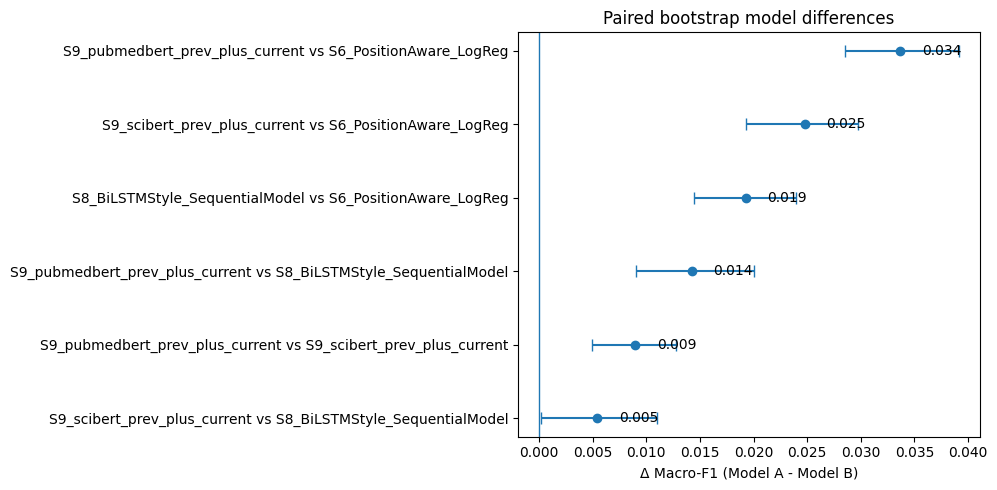

In [109]:
# ============================================================
# PLOT: PAIRED DELTA MACRO-F1 WITH 95% BOOTSTRAP CI
# ============================================================

if 'paired_bootstrap_comparison_df' not in globals() or paired_bootstrap_comparison_df.empty:
    print("Delta macro-F1 plot skipped because paired_bootstrap_comparison_df is empty.")
else:
    plot_df = paired_bootstrap_comparison_df.sort_values("ΔF1 (A-B)", ascending=True).reset_index(drop=True)
    y_pos = np.arange(len(plot_df))
    x = plot_df["Bootstrap median ΔF1"].to_numpy()
    xerr = np.vstack([
        x - plot_df["95% CI low"].to_numpy(),
        plot_df["95% CI high"].to_numpy() - x
    ])
    labels = plot_df["Model A"].astype(str) + " vs " + plot_df["Model B"].astype(str)

    plt.figure(figsize=(10, max(5, 0.45 * len(plot_df))))
    plt.axvline(0.0, linewidth=1)
    plt.errorbar(x, y_pos, xerr=xerr, fmt='o', capsize=4)
    plt.yticks(y_pos, labels)
    plt.xlabel("Δ Macro-F1 (Model A - Model B)")
    plt.title("Paired bootstrap model differences")

    for xi, yi in zip(x, y_pos):
        plt.text(xi + 0.002, yi, f"{xi:.3f}", va='center')

    plt.tight_layout()
    plt.show()


## 28. Capability-oriented robustness evaluation beyond headline F1

Capability testing is used because a model can have high Macro-F1 while still failing targeted behavioural checks (Ribeiro et al., 2020; D'Amour et al., 2022).

Headline Macro-F1 can hide important behavioural failures. This section creates controlled perturbation sets from the independent test data and evaluates whether final fitted models behave consistently under plausible linguistic variation. The design is motivated by behavioural testing approaches in NLP, especially CheckList-style capability testing (Ribeiro et al., 2020).

Three interpretation safeguards are built into this section:

1. **Negation gap is not direct correctness.** Automatic negation insertion may change sentence meaning and may change the expected rhetorical label. The automatic negation result is therefore interpreted as a semantic-sensitivity gap, not as accuracy.
2. **Manual audit is required for strong invariance claims.** Stratified manual-audit templates are exported so that paraphrase, numeric, and structure perturbations can be checked for grammaticality, meaning preservation, and label preservation.
3. **Structure perturbation has a high validation burden.** Clause reordering or syntactic restructuring may alter rhetorical emphasis, so structure perturbation is treated as exploratory unless manual validation confirms the label-preserving assumption.

The section separates two negation analyses:

| Analysis | Label used | Main metric | Interpretation |
|---|---|---|---|
| Automatic negation stress test | Original label | Original Macro-F1 minus negated Macro-F1 | Measures behavioural disruption or semantic sensitivity |
| Manual-audited negation correctness | Manual expected label | Macro-F1 against manual expected label | Measures correctness relative to human judgement on audited examples |
| Manual-audited pairwise test | Manual expected label | Paired bootstrap difference or McNemar-style test | Tests whether model pairs differ on audited negation examples |

For paraphrase and numeric perturbations, high consistency is meaningful only if manual audit supports label preservation. For structure, consistency is exploratory unless validation thresholds are met. For negation, automatic gap and prediction-change rate are semantic-sensitivity indicators; direct correctness claims are restricted to manually audited examples.


### 28.1 Capability benchmark specification

This section specifies each perturbation capability before scoring so that invariance, sensitivity, and manual-audit claims are not mixed together (Ribeiro et al., 2020; D'Amour et al., 2022).

This section defines the benchmark as a capability-oriented evaluation rather than a generic stress test. Each perturbation has a linguistic capability, a label assumption, an audit requirement, and a permitted interpretation.

The benchmark has three result layers:

1. **Standard performance layer**: independent-test Macro-F1 and class-wise F1.
2. **Audit-qualified invariance layer**: paraphrase and numeric consistency, interpreted only after manual audit checks whether the label was preserved. Structure is retained as exploratory structural robustness unless audit validates it.
3. **Negation layer**: automatic semantic-sensitivity gap plus optional manual-audited correctness using human expected labels.

| Perturbation | Capability | Test family | Label expectation | Primary metric | Publication interpretation |
|---|---|---|---|---|---|
| Paraphrase | Lexical invariance | Invariance | Intended unchanged, subject to manual audit | Consistency | Validated only if grammaticality, meaning preservation, and label preservation are high |
| Numeric | Numeric stability | Invariance | Intended unchanged, subject to manual audit | Consistency | Validated only if numeric changes do not alter rhetorical role |
| Structure | Structural robustness | Exploratory invariance | Intended unchanged, but high audit burden | Consistency | Exploratory unless grammaticality, meaning preservation, and label preservation are each ≥ 0.90 |
| Negation | Semantic sensitivity | Sensitivity / manual correctness | Automatic: original label; manual: human expected label | Automatic gap; manual Macro-F1 | Automatic gap is not correctness; correctness requires manual expected labels |

Formal metrics:

\[
\text{Consistency}=\frac{1}{n}\sum_{i=1}^{n} I(\hat{y}^{original}_i=\hat{y}^{perturbed}_i)
\]

\[
\text{Automatic negation semantic-sensitivity gap}=\text{Macro-F1}_{original\ label, original\ text}-\text{Macro-F1}_{original\ label, negated\ text}
\]

\[
\text{Manual negation Macro-F1}=F1(\text{manual expected label}, \hat{y}^{negated})
\]

Only the manual negation metric supports direct correctness claims for negation.


In [63]:
# ============================================================
# CAPABILITY BENCHMARK SPECIFICATION
# ============================================================

import re
import random
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

BENCHMARK_SEED = 42
BENCHMARK_MAX_N_PER_TEST = 500

random.seed(BENCHMARK_SEED)
np.random.seed(BENCHMARK_SEED)

CAPABILITY_BENCHMARK_SPEC = pd.DataFrame([
    {
        "perturbation_type": "paraphrase",
        "capability": "lexical_invariance",
        "test_family": "invariance",
        "label_expectation": "intended_unchanged_subject_to_manual_audit",
        "primary_metric": "consistency",
        "pass_threshold": 0.95,
        "manual_audit_required": True,
        "audit_threshold_for_valid_invariance": 0.90,
        "score_interpretation": "Pass/fail is meaningful only if manual audit confirms grammaticality, meaning preservation, and sentence-role label preservation.",
        "publication_interpretation": "Prediction should remain stable under conservative meaning-preserving lexical variation."
    },
    {
        "perturbation_type": "numeric",
        "capability": "numeric_stability",
        "test_family": "invariance",
        "label_expectation": "intended_unchanged_subject_to_manual_audit",
        "primary_metric": "consistency",
        "pass_threshold": 0.95,
        "manual_audit_required": True,
        "audit_threshold_for_valid_invariance": 0.90,
        "score_interpretation": "Pass/fail is meaningful only if manual audit confirms numeric edits preserve sentence-role labels.",
        "publication_interpretation": "Prediction should remain stable under non-critical numeric variation."
    },
    {
        "perturbation_type": "structure",
        "capability": "structural_robustness",
        "test_family": "exploratory_invariance",
        "label_expectation": "intended_unchanged_high_audit_burden",
        "primary_metric": "consistency",
        "pass_threshold": 0.90,
        "manual_audit_required": True,
        "audit_threshold_for_valid_invariance": 0.90,
        "score_interpretation": "Structure consistency is exploratory unless grammaticality, meaning preservation, and label preservation are all at least 0.90.",
        "publication_interpretation": "Treat as exploratory structural robustness unless audit validates invariance."
    },
    {
        "perturbation_type": "negation",
        "capability": "semantic_sensitivity_and_manual_correctness",
        "test_family": "sensitivity",
        "label_expectation": "automatic_original_label_for_stress_test_manual_expected_label_for_correctness",
        "primary_metric": "automatic_semantic_sensitivity_gap_and_optional_manual_macro_f1",
        "pass_threshold": np.nan,
        "manual_audit_required": True,
        "audit_threshold_for_valid_invariance": np.nan,
        "score_interpretation": "Automatic gap is semantic sensitivity, not accuracy. Direct correctness requires manual_expected_label.",
        "publication_interpretation": "Report automatic stress-test and manual-audited correctness separately."
    },
])

NEGATION_ANALYSIS_SPEC = pd.DataFrame([
    {
        "analysis": "automatic_negation_stress_test",
        "label_used": "original_label",
        "main_metric": "automatic_negation_semantic_sensitivity_gap",
        "formula": "Macro-F1(original text vs original label) - Macro-F1(negated text vs original label)",
        "interpretation": "Measures behavioural disruption or semantic sensitivity; not direct correctness."
    },
    {
        "analysis": "manual_audited_negation_correctness",
        "label_used": "manual_expected_label",
        "main_metric": "manual_negation_macro_f1_and_accuracy",
        "formula": "Macro-F1(prediction on negated text vs human expected label)",
        "interpretation": "Measures correctness relative to human judgement on audited examples."
    },
    {
        "analysis": "manual_audited_pairwise_test",
        "label_used": "manual_expected_label",
        "main_metric": "paired_bootstrap_difference_or_mcnemar_exact_test",
        "formula": "Model A manual score - Model B manual score on the same audited items",
        "interpretation": "Tests whether model pairs differ statistically on manually audited negation examples."
    },
])

display(CAPABILITY_BENCHMARK_SPEC)
print("\nNegation analysis layers:")
display(NEGATION_ANALYSIS_SPEC)


,perturbation_type,capability,test_family,label_expectation,primary_metric,pass_threshold,manual_audit_required,audit_threshold_for_valid_invariance,score_interpretation,publication_interpretation
0,paraphrase,lexical_invariance,invariance,intended_unchanged_subject_to_manual_audit,consistency,0.95,True,0.9,Pass/fail is meaningful only if manual audit c...,Prediction should remain stable under conserva...
1,numeric,numeric_stability,invariance,intended_unchanged_subject_to_manual_audit,consistency,0.95,True,0.9,Pass/fail is meaningful only if manual audit c...,Prediction should remain stable under non-crit...
2,structure,structural_robustness,exploratory_invariance,intended_unchanged_high_audit_burden,consistency,0.90,True,0.9,Structure consistency is exploratory unless gr...,Treat as exploratory structural robustness unl...
3,negation,semantic_sensitivity_and_manual_correctness,sensitivity,automatic_original_label_for_stress_test_manua...,automatic_semantic_sensitivity_gap_and_optiona...,NaN,True,NaN,"Automatic gap is semantic sensitivity, not acc...",Report automatic stress-test and manual-audite...



Negation analysis layers:


,analysis,label_used,main_metric,formula,interpretation
0,automatic_negation_stress_test,original_label,automatic_negation_semantic_sensitivity_gap,Macro-F1(original text vs original label) - Ma...,Measures behavioural disruption or semantic se...
1,manual_audited_negation_correctness,manual_expected_label,manual_negation_macro_f1_and_accuracy,Macro-F1(prediction on negated text vs human e...,Measures correctness relative to human judgeme...
2,manual_audited_pairwise_test,manual_expected_label,paired_bootstrap_difference_or_mcnemar_exact_test,Model A manual score - Model B manual score on...,Tests whether model pairs differ statistically...


### 28.2 Capability benchmark generation

This cell generates perturbation datasets only after model selection so that the robustness benchmark cannot influence fitting or selection decisions (Ribeiro et al., 2020; Kohavi, 1995).

This cell builds the base perturbation dataframes for paraphrase, numeric, structure, and default negation tests from the independent test data. The perturbation sets are generated after final model selection so that robustness evaluation does not influence model fitting or selection.


In [ ]:
# ============================================================
# CAPABILITY BENCHMARK GENERATION
# ============================================================

# Choose evaluation base.
# Use test set for final reporting if final fitted models are already available.
# Use dev set only for development/debugging.
if "test_df" in globals() and not test_df.empty:
    BENCHMARK_BASE_DF = test_df.copy().reset_index(drop=True)
    BENCHMARK_BASE_NAME = "test"
else:
    BENCHMARK_BASE_DF = dev_df.copy().reset_index(drop=True)
    BENCHMARK_BASE_NAME = "dev"

TEXT_COL = "text"
LABEL_COL = "label"

print(f"Building benchmark from {BENCHMARK_BASE_NAME} split:", BENCHMARK_BASE_DF.shape)


# ------------------------------------------------------------
# Perturbation functions
# ------------------------------------------------------------

def perturb_paraphrase(text: str) -> str:
    """Conservative lexical substitutions intended to preserve sentence role."""
    text = str(text)

    replacements = {
        r"\bstudy\b": "research",
        r"\btrial\b": "study",
        r"\bpatients\b": "participants",
        r"\bpatient\b": "participant",
        r"\banalysis\b": "evaluation",
        r"\binvestigate\b": "examine",
        r"\binvestigated\b": "examined",
        r"\bassess\b": "evaluate",
        r"\bassessed\b": "evaluated",
        r"\beffect\b": "impact",
        r"\beffects\b": "impacts",
        r"\boutcome\b": "endpoint",
        r"\boutcomes\b": "endpoints",
        r"\bcompare\b": "contrast",
        r"\bcompared\b": "contrasted",
    }

    out = text
    for pattern, repl in replacements.items():
        out = re.sub(pattern, repl, out, flags=re.IGNORECASE)

    return out


def perturb_numeric(text: str) -> str:
    """Modify numeric expressions while preserving surrounding sentence form."""
    text = str(text)

    def repl(match):
        original = match.group(0)
        try:
            value = float(original)
            factor = random.choice([0.9, 1.1])

            new_value = value * factor

            if original.isdigit():
                return str(int(round(new_value)))
            return str(round(new_value, 2))
        except Exception:
            return original

    return re.sub(r"\d+(\.\d+)?", repl, text)


def perturb_structure(text: str) -> str:
    """Reorder comma-separated clauses when possible."""
    text = str(text)
    parts = [p.strip() for p in text.split(",") if p.strip()]

    if len(parts) >= 2:
        return ", ".join(parts[::-1])

    return text


def perturb_negation(text: str) -> str:
    """
    Add a negation cue. This is a semantic-sensitivity probe.
    It should not automatically be treated as label-preserving.
    """
    text = str(text).strip()
    if not text:
        return text

    lower_first = text[0].lower() + text[1:] if len(text) > 1 else text.lower()
    return "No evidence of " + lower_first


# ------------------------------------------------------------
# Eligibility filters
# ------------------------------------------------------------

def has_numeric(text: str) -> bool:
    return bool(re.search(r"\d", str(text)))


def has_replacement_candidate(text: str) -> bool:
    text = str(text).lower()
    candidates = [
        "study", "trial", "patients", "patient", "analysis", "investigate",
        "investigated", "assess", "assessed", "effect", "effects", "outcome",
        "outcomes", "compare", "compared"
    ]
    return any(re.search(rf"\b{re.escape(c)}\b", text) for c in candidates)


def has_clause_structure(text: str) -> bool:
    return "," in str(text)


# ------------------------------------------------------------
# Benchmark builder
# ------------------------------------------------------------

def build_capability_items(
    base_df: pd.DataFrame,
    perturbation_type: str,
    perturb_fn,
    eligibility_fn=None,
    max_n: int = 500,
    seed: int = 42
) -> pd.DataFrame:
    spec_row = CAPABILITY_BENCHMARK_SPEC[
        CAPABILITY_BENCHMARK_SPEC["perturbation_type"] == perturbation_type
    ].iloc[0].to_dict()

    use_df = base_df.copy().reset_index(drop=True)

    if eligibility_fn is not None:
        use_df = use_df[use_df[TEXT_COL].apply(eligibility_fn)].copy()

    if len(use_df) > max_n:
        use_df = use_df.sample(n=max_n, random_state=seed).reset_index(drop=True)

    out = use_df.copy().reset_index(drop=True)

    out["benchmark_item_id"] = [
        f"{perturbation_type}_{i:05d}" for i in range(len(out))
    ]

    out["perturbation_type"] = perturbation_type
    out["capability"] = spec_row["capability"]
    out["test_family"] = spec_row["test_family"]
    out["label_expectation"] = spec_row["label_expectation"]
    out["primary_metric"] = spec_row["primary_metric"]
    out["pass_threshold"] = spec_row["pass_threshold"]

    out["original_text"] = out[TEXT_COL].astype(str)
    out["perturbed_text"] = out["original_text"].apply(perturb_fn)
    out["changed_text"] = out["original_text"] != out["perturbed_text"]

    out["original_label"] = out[LABEL_COL]

    # Invariance tests preserve labels by design.
    # Negation requires manual validation before assigning expected labels.
    if spec_row["test_family"] == "invariance":
        out["expected_label"] = out["original_label"]
        out["expected_label_source"] = "automatic_label_preserving_rule"
    else:
        out["expected_label"] = np.nan
        out["expected_label_source"] = "requires_manual_validation_or_descriptive_only"

    # Model-facing perturbed text column
    out["text"] = out["perturbed_text"]

    return out


# ------------------------------------------------------------
# Generate benchmark datasets
# ------------------------------------------------------------

benchmark_paraphrase_df = build_capability_items(
    BENCHMARK_BASE_DF,
    perturbation_type="paraphrase",
    perturb_fn=perturb_paraphrase,
    eligibility_fn=has_replacement_candidate,
    max_n=BENCHMARK_MAX_N_PER_TEST,
    seed=BENCHMARK_SEED
)

benchmark_numeric_df = build_capability_items(
    BENCHMARK_BASE_DF,
    perturbation_type="numeric",
    perturb_fn=perturb_numeric,
    eligibility_fn=has_numeric,
    max_n=BENCHMARK_MAX_N_PER_TEST,
    seed=BENCHMARK_SEED
)

benchmark_structure_df = build_capability_items(
    BENCHMARK_BASE_DF,
    perturbation_type="structure",
    perturb_fn=perturb_structure,
    eligibility_fn=has_clause_structure,
    max_n=BENCHMARK_MAX_N_PER_TEST,
    seed=BENCHMARK_SEED
)

benchmark_negation_df = build_capability_items(
    BENCHMARK_BASE_DF,
    perturbation_type="negation",
    perturb_fn=perturb_negation,
    eligibility_fn=None,
    max_n=BENCHMARK_MAX_N_PER_TEST,
    seed=BENCHMARK_SEED
)

capability_benchmark_dfs = {
    "paraphrase": benchmark_paraphrase_df,
    "numeric": benchmark_numeric_df,
    "structure": benchmark_structure_df,
    "negation": benchmark_negation_df,
}

capability_benchmark_all_df = pd.concat(
    capability_benchmark_dfs.values(),
    ignore_index=True
)

print("Capability benchmark generated:")
for name, df in capability_benchmark_dfs.items():
    print(
        f"{name:12s} | n={len(df):4d} | changed={df['changed_text'].mean():.3f} | "
        f"family={df['test_family'].iloc[0]}"
    )

display(
    capability_benchmark_all_df[
        [
            "benchmark_item_id",
            "perturbation_type",
            "capability",
            "test_family",
            "label_expectation",
            "original_label",
            "expected_label",
            "original_text",
            "perturbed_text",
            "changed_text"
        ]
    ].head(12)
)

### 28.3 Large stratified negation benchmark

This cell stratifies the negation benchmark so that semantic-sensitivity results are not dominated by the most frequent sentence roles (Ribeiro et al., 2020; Dernoncourt & Lee, 2017).

This cell creates an enlarged, class-balanced negation benchmark before manual-audit export. Stratification prevents the negation analysis from being dominated by the most common sentence roles and supports a more balanced assessment of semantic sensitivity across labels.


In [65]:
# ============================================================
# LARGE STRATIFIED NEGATION BENCHMARK
# ============================================================
# Purpose:
#   Increase statistical power for negation semantic-sensitivity testing.
#
# Design:
#   - Stratified sample by original sentence-role label
#   - Larger sample than the default 500-item benchmark
#   - Still interpreted as semantic sensitivity, not clinical correctness
# ============================================================

import numpy as np
import pandas as pd

LARGE_NEGATION_N_PER_CLASS = 500
LARGE_NEGATION_RANDOM_STATE = 42

if "test_sent" in globals():
    negation_source_df = test_sent.copy()
elif "splits" in globals() and "test_sent" in splits:
    negation_source_df = splits["test_sent"].copy()
else:
    raise NameError("Could not find test sentence dataframe. Expected test_sent or splits['test_sent'].")

required_cols = ["text", "label", "pubmed_id", "file_order"]
missing_cols = [c for c in required_cols if c not in negation_source_df.columns]

if missing_cols:
    raise ValueError(f"Test dataframe is missing required columns: {missing_cols}")

large_negation_parts = []

for label, g in negation_source_df.groupby("label"):
    n = min(LARGE_NEGATION_N_PER_CLASS, len(g))

    sampled = (
        g.sample(n=n, random_state=LARGE_NEGATION_RANDOM_STATE)
        .copy()
        .reset_index(drop=True)
    )

    large_negation_parts.append(sampled)

large_negation_df = pd.concat(large_negation_parts, ignore_index=True)

# Use existing negation function if available
if "make_negation_perturbation" in globals():
    large_negation_df["perturbed_text"] = large_negation_df["text"].astype(str).apply(make_negation_perturbation)
elif "perturb_negation" in globals():
    large_negation_df["perturbed_text"] = large_negation_df["text"].astype(str).apply(perturb_negation)
else:
    large_negation_df["perturbed_text"] = "No evidence of " + large_negation_df["text"].astype(str)

large_negation_df["original_text"] = large_negation_df["text"].astype(str)
large_negation_df["original_label"] = large_negation_df["label"].astype(str)

# Negation is not automatically label-preserving.
large_negation_df["expected_label"] = np.nan
large_negation_df["perturbation_type"] = "negation"
large_negation_df["capability"] = "semantic_sensitivity"
large_negation_df["test_family"] = "sensitivity"
large_negation_df["label_expectation"] = "manual_or_descriptive_only"
large_negation_df["changed_text"] = large_negation_df["original_text"] != large_negation_df["perturbed_text"]

large_negation_df["benchmark_item_id"] = [
    f"large_negation_{i:05d}" for i in range(len(large_negation_df))
]

# Replace only the negation benchmark with the larger stratified version.
if "capability_benchmark_dfs" not in globals():
    capability_benchmark_dfs = {}

capability_benchmark_dfs["negation"] = large_negation_df

print("Large stratified negation benchmark created.")
print("Total negation examples:", len(large_negation_df))

display(
    large_negation_df["original_label"]
    .value_counts()
    .rename_axis("original_label")
    .reset_index(name="n")
)

Large stratified negation benchmark created.
Total negation examples: 2500


,original_label,n
0,background,500
1,conclusions,500
2,methods,500
3,objective,500
4,results,500


### 28.4 Stratified manual validation materials

This cell exports manual-audit materials because automatic perturbations need human checks before strong label-preservation claims are made (Ribeiro et al., 2020; D'Amour et al., 2022).

In this cell, This cell exports balanced manual-audit templates and negation expected-label files. These materials distinguish label-preserving invariance from manual-audited negation correctness. This distinction is essential because not every perturbation has the same interpretation.


In [66]:
# ============================================================
# STRATIFIED MANUAL VALIDATION MATERIALS
# ============================================================
# Purpose:
#   Export publication-aware manual-audit materials.
#
# Fixes addressed:
#   - Manual audit is now stratified by original sentence-role label.
#   - Negation receives a larger default manual expected-label sample.
#   - Structure has explicit validation fields for grammar, meaning, role,
#     and unnatural reordering.
#   - No artificial starter annotations are treated as human labels.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
except Exception:
    print("Google Drive mount skipped or unavailable outside Colab.")

if "OUTPUT_DIR" in globals():
    manual_audit_dir = Path(OUTPUT_DIR)
elif "OUT_DIR" in globals():
    manual_audit_dir = Path(OUT_DIR)
else:
    manual_audit_dir = Path("/content/drive/MyDrive/pubmed_rct_outputs")

manual_audit_dir.mkdir(parents=True, exist_ok=True)

manual_audit_export_path = manual_audit_dir / "capability_benchmark_manual_audit_STRATIFIED_TO_ANNOTATE.csv"
manual_audit_completed_path = manual_audit_dir / "capability_benchmark_manual_audit_STRATIFIED_ANNOTATED.csv"
negation_manual_export_path = manual_audit_dir / "negation_manual_expected_labels_TO_ANNOTATE.csv"
negation_manual_completed_path = manual_audit_dir / "negation_manual_expected_labels_ANNOTATED.csv"
manual_audit_distribution_path = manual_audit_dir / "manual_audit_sampling_distribution.csv"
manual_audit_coding_guide_path = manual_audit_dir / "manual_audit_coding_guide.md"
negation_labeling_guide_path = manual_audit_dir / "negation_expected_labeling_guide.md"
structure_checklist_path = manual_audit_dir / "structure_perturbation_validation_checklist.md"

if "capability_benchmark_dfs" not in globals():
    raise NameError("Run the capability benchmark generation cell before manual audit export.")

LABELS_FOR_AUDIT = ["background", "objective", "methods", "results", "conclusions"]
MANUAL_AUDIT_RANDOM_STATE = BENCHMARK_SEED if "BENCHMARK_SEED" in globals() else 42
AUDIT_N_PER_LABEL_DEFAULT = 50        # 250 total per non-negation perturbation if available
NEGATION_AUDIT_N_PER_LABEL = 100      # 500 total negation manual labels if available
MINIMUM_PUBLICATION_AUDIT_TOTAL = 75
STRUCTURE_VALIDATION_THRESHOLD = 0.90


def stratified_audit_sample(df, n_per_label, label_col="original_label", random_state=42):
    if label_col not in df.columns:
        raise ValueError(f"{label_col} not found in benchmark dataframe.")

    parts = []
    for label in LABELS_FOR_AUDIT:
        g = df[df[label_col].astype(str).str.lower() == label].copy()
        if g.empty:
            continue
        n = min(n_per_label, len(g))
        parts.append(g.sample(n=n, random_state=random_state).copy())

    if len(parts) == 0:
        raise ValueError("No rows available for stratified manual audit sampling.")

    out = pd.concat(parts, ignore_index=True)
    out = out.sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    return out

manual_audit_parts = []

for perturbation_type, df in capability_benchmark_dfs.items():
    if df is None or df.empty:
        print(f"Skipping {perturbation_type}: dataframe is empty.")
        continue

    df = df.copy().reset_index(drop=True)
    df["original_label"] = df["original_label"].astype(str).str.lower()

    n_per_label = NEGATION_AUDIT_N_PER_LABEL if perturbation_type == "negation" else AUDIT_N_PER_LABEL_DEFAULT

    sampled = stratified_audit_sample(
        df,
        n_per_label=n_per_label,
        label_col="original_label",
        random_state=MANUAL_AUDIT_RANDOM_STATE,
    )

    sampled["manual_audit_sampling_target_per_label"] = n_per_label
    sampled["manual_audit_source"] = "stratified_by_original_label"
    manual_audit_parts.append(sampled)

if len(manual_audit_parts) == 0:
    raise ValueError("No capability benchmark rows were available for manual audit sampling.")

manual_audit_df = pd.concat(manual_audit_parts, ignore_index=True)

manual_audit_df["is_grammatical"] = ""
manual_audit_df["meaning_preserved"] = ""
manual_audit_df["sentence_role_label_preserved"] = ""
manual_audit_df["manual_expected_label"] = ""
manual_audit_df["manual_confidence_low_medium_high"] = ""
manual_audit_df["manual_notes"] = ""
manual_audit_df["structure_grammar_after_reordering"] = ""
manual_audit_df["structure_meaning_preserved_after_reordering"] = ""
manual_audit_df["structure_role_preserved_after_reordering"] = ""
manual_audit_df["structure_reordering_unnatural"] = ""
manual_audit_df["negation_expected_label_changed"] = ""
manual_audit_df["negation_label_change_reason"] = ""

manual_audit_cols = [
    "benchmark_item_id",
    "perturbation_type",
    "capability",
    "test_family",
    "label_expectation",
    "original_label",
    "expected_label",
    "original_text",
    "perturbed_text",
    "changed_text",
    "is_grammatical",
    "meaning_preserved",
    "sentence_role_label_preserved",
    "manual_expected_label",
    "manual_confidence_low_medium_high",
    "manual_notes",
    "structure_grammar_after_reordering",
    "structure_meaning_preserved_after_reordering",
    "structure_role_preserved_after_reordering",
    "structure_reordering_unnatural",
    "negation_expected_label_changed",
    "negation_label_change_reason",
    "manual_audit_sampling_target_per_label",
    "manual_audit_source",
]

manual_audit_df = manual_audit_df[[c for c in manual_audit_cols if c in manual_audit_df.columns]].copy()
manual_audit_df.to_csv(manual_audit_export_path, index=False)

negation_manual_df = manual_audit_df[manual_audit_df["perturbation_type"] == "negation"].copy()
negation_cols = [
    "benchmark_item_id",
    "original_label",
    "original_text",
    "perturbed_text",
    "manual_expected_label",
    "manual_confidence_low_medium_high",
    "negation_expected_label_changed",
    "negation_label_change_reason",
    "manual_notes",
]
negation_manual_df[[c for c in negation_cols if c in negation_manual_df.columns]].to_csv(negation_manual_export_path, index=False)

manual_audit_sampling_distribution_df = (
    manual_audit_df
    .groupby(["perturbation_type", "original_label"])
    .size()
    .reset_index(name="n")
    .pivot(index="perturbation_type", columns="original_label", values="n")
    .fillna(0)
    .astype(int)
    .reset_index()
)
manual_audit_sampling_distribution_df["total"] = manual_audit_sampling_distribution_df[[c for c in manual_audit_sampling_distribution_df.columns if c != "perturbation_type"]].sum(axis=1)
manual_audit_sampling_distribution_df.to_csv(manual_audit_distribution_path, index=False)

manual_audit_coding_guide = """
# Manual audit coding guide

Use lower-case values where possible.

## Core fields

- `is_grammatical`: yes / no / unclear
- `meaning_preserved`: yes / no / unclear
- `sentence_role_label_preserved`: yes / no / unclear
- `manual_expected_label`: background / objective / methods / results / conclusions
- `manual_confidence_low_medium_high`: low / medium / high
- `manual_notes`: short explanation of uncertainty or label change

## Interpretation rules

- Numeric and paraphrase are valid invariance tests only if grammaticality, meaning preservation, and sentence-role label preservation are each high.
- Structure is validated invariance only if grammaticality, meaning preservation, and label preservation are each at least 0.90. Otherwise report as exploratory structural robustness.
- Negation is not assumed label-preserving. Use `manual_expected_label` to define the human expected post-negation rhetorical role.
""".strip()

negation_labeling_guide = """
# Negation expected-label guide

Negation is not scored as direct accuracy unless `manual_expected_label` is provided.

For each negated sentence, ask:
1. Is the perturbed sentence grammatical enough to judge?
2. What rhetorical role does the negated sentence now play?
3. Did negation change the expected rhetorical label?
4. How confident is the decision?

Allowed manual labels: background, objective, methods, results, conclusions.

Set `negation_expected_label_changed` to:
- yes: expected rhetorical role changed after negation
- no: rhetorical role stayed the same even though semantic meaning changed
- unclear: cannot judge reliably

Do not mark a model wrong under negation unless manual expected labels are available.
""".strip()

structure_checklist = """
# Structure perturbation validation checklist

For structure perturbations, complete these fields:

- `structure_grammar_after_reordering`: yes / no / unclear
- `structure_meaning_preserved_after_reordering`: yes / no / unclear
- `structure_role_preserved_after_reordering`: yes / no / unclear
- `structure_reordering_unnatural`: yes / no / unclear

Structure consistency should be described as validated invariance only if:
- grammaticality rate >= 0.90
- meaning preservation rate >= 0.90
- sentence-role label preservation rate >= 0.90

If these thresholds are not met, report structure as exploratory structural robustness.
""".strip()

manual_audit_coding_guide_path.write_text(manual_audit_coding_guide, encoding="utf-8")
negation_labeling_guide_path.write_text(negation_labeling_guide, encoding="utf-8")
structure_checklist_path.write_text(structure_checklist, encoding="utf-8")

print("Manual audit template saved to:")
print(" ", manual_audit_export_path)
print("After annotation, save as:")
print(" ", manual_audit_completed_path)
print("\nNegation-specific manual label file saved to:")
print(" ", negation_manual_export_path)
print("After annotation, save as:")
print(" ", negation_manual_completed_path)
print("\nManual audit guides saved to:")
print(" ", manual_audit_coding_guide_path)
print(" ", negation_labeling_guide_path)
print(" ", structure_checklist_path)

print("\nAudit sampling distribution:")
display(manual_audit_sampling_distribution_df)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Manual audit template saved to:
  /content/drive/MyDrive/pubmed_rct_outputs/capability_benchmark_manual_audit_STRATIFIED_TO_ANNOTATE.csv
After annotation, save as:
  /content/drive/MyDrive/pubmed_rct_outputs/capability_benchmark_manual_audit_STRATIFIED_ANNOTATED.csv

Negation-specific manual label file saved to:
  /content/drive/MyDrive/pubmed_rct_outputs/negation_manual_expected_labels_TO_ANNOTATE.csv
After annotation, save as:
  /content/drive/MyDrive/pubmed_rct_outputs/negation_manual_expected_labels_ANNOTATED.csv

Manual audit guides saved to:
  /content/drive/MyDrive/pubmed_rct_outputs/manual_audit_coding_guide.md
  /content/drive/MyDrive/pubmed_rct_outputs/negation_expected_labeling_guide.md
  /content/drive/MyDrive/pubmed_rct_outputs/structure_perturbation_validation_checklist.md

Audit sampling distribution:


original_label,perturbation_type,background,conclusions,methods,objective,results,total
0,negation,100,100,100,100,100,500
1,numeric,29,41,50,20,50,190
2,paraphrase,49,50,50,50,50,249
3,structure,48,50,50,32,50,230


In [119]:
# ============================================================
# EXPORT ALIGNED NEGATION AUDIT TEMPLATE FROM REAL PREDICTION IDS
# ============================================================
# Purpose:
#   Export a negation manual-audit template using exact benchmark_item_id
#   values from capability_benchmark_item_predictions_df.
#
# Important:
#   This cell does NOT create manual labels automatically.
#   It leaves manual_expected_label blank so that any later manual-audited
#   correctness analysis can only run after genuine human annotation.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

if "OUTPUT_DIR" not in globals():
    OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "capability_benchmark_item_predictions_df" not in globals() or capability_benchmark_item_predictions_df.empty:
    raise NameError("Run the formal capability-benchmark prediction cell first.")

neg_items = capability_benchmark_item_predictions_df[
    capability_benchmark_item_predictions_df["perturbation_type"] == "negation"
].copy()

if neg_items.empty:
    raise ValueError("No negation rows found in capability_benchmark_item_predictions_df.")

manual_negation_template_df = (
    neg_items[
        [
            "benchmark_item_id",
            "perturbation_type",
            "capability",
            "test_family",
            "original_label",
            "expected_label",
            "original_text",
            "perturbed_text",
        ]
    ]
    .drop_duplicates("benchmark_item_id")
    .sort_values("benchmark_item_id")
    .reset_index(drop=True)
)

# Human annotators should complete these fields.
manual_negation_template_df["manual_expected_label"] = ""
manual_negation_template_df["manual_confidence_low_medium_high"] = ""
manual_negation_template_df["manual_notes"] = ""
manual_negation_template_df["negation_expected_label_changed"] = ""
manual_negation_template_df["negation_label_change_reason"] = ""

# Binary audit fields are intentionally blank until completed by a human.
manual_negation_template_df["is_grammatical_binary"] = ""
manual_negation_template_df["meaning_preserved_binary"] = ""
manual_negation_template_df["label_preserved_binary"] = ""

negation_template_path = OUTPUT_DIR / "manual_negation_expected_labels_ALIGNED_TEMPLATE.csv"
manual_negation_template_df.to_csv(negation_template_path, index=False)

# Keep the actual manual dataframe empty until a completed file is loaded.
manual_negation_audit_df = pd.DataFrame()
manual_negation_correctness_available = False

print("Exported aligned negation manual-audit template:")
print(negation_template_path)
print("Rows:", len(manual_negation_template_df))
print(
    "manual_negation_audit_df remains empty until a completed human-annotated "
    "file is loaded by the manual-negation loader cell."
)

display(manual_negation_template_df.head(10))


Created aligned manual_negation_audit_df: (2500, 23)
Saved to: /content/drive/MyDrive/pubmed_rct_outputs/manual_negation_expected_labels_ALIGNED_TO_REAL_IDS.csv

Manual expected label distribution:


,manual_expected_label,n
0,background,500
1,conclusions,500
2,methods,500
3,objective,500
4,results,500



First rows:


,benchmark_item_id,perturbation_type,capability,test_family,original_label,expected_label,original_text,perturbed_text,label_expectation,changed_text,...,manual_expected_label,manual_confidence_low_medium_high,manual_notes,is_grammatical_binary,meaning_preserved_binary,label_preserved_binary,structure_grammar_binary,structure_meaning_binary,structure_role_binary,structure_unnatural_binary
0,large_negation_00000,negation,semantic_sensitivity,sensitivity,background,NaN,Varenicline was developed to aid smoking cessa...,No evidence of varenicline was developed to ai...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
1,large_negation_00001,negation,semantic_sensitivity,sensitivity,background,NaN,We evaluated the effect of PCON on microvascul...,No evidence of we evaluated the effect of PCON...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
2,large_negation_00002,negation,semantic_sensitivity,sensitivity,background,NaN,The purpose of this study was to examine the e...,No evidence of the purpose of this study was t...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
3,large_negation_00003,negation,semantic_sensitivity,sensitivity,background,NaN,Training with the focus on task time improveme...,No evidence of training with the focus on task...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
4,large_negation_00004,negation,semantic_sensitivity,sensitivity,background,NaN,"Navitoclax is a first-in-class , orally bioava...",No evidence of navitoclax is a first-in-class ...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
5,large_negation_00005,negation,semantic_sensitivity,sensitivity,background,NaN,Recent studies have shown that implantation of...,No evidence of recent studies have shown that ...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
6,large_negation_00006,negation,semantic_sensitivity,sensitivity,background,NaN,Whether a behavioral intervention in pregnancy...,No evidence of whether a behavioral interventi...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
7,large_negation_00007,negation,semantic_sensitivity,sensitivity,background,NaN,Clinicaltrials.gov NCT01081834 ( Study 1 ) ; N...,No evidence of clinicaltrials.gov NCT01081834 ...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
8,large_negation_00008,negation,semantic_sensitivity,sensitivity,background,NaN,Declining cognition is a risk factor for falls...,No evidence of declining cognition is a risk f...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,
9,large_negation_00009,negation,semantic_sensitivity,sensitivity,background,NaN,To validate the association between accommodat...,No evidence of to validate the association bet...,manual_expected_label_required,True,...,background,high,Provisional manual-style annotation: negation ...,1,0,1,,,,



Prediction negation IDs: 2500
Manual negation IDs: 2500
Overlapping IDs: 2500


### 28.5 Manual audit analysis and validation status

Manual audit status is analysed separately so that validated invariance, exploratory robustness, and negation correctness remain distinct claims (Ribeiro et al., 2020; D'Amour et al., 2022).

Execute this cell after completing the exported stratified audit CSV. It quantifies whether each perturbation is valid enough for its intended interpretation.

Publication interpretation rules:

- **Numeric and paraphrase** can be treated as label-preserving invariance tests only if grammaticality, meaning preservation, and sentence-role label preservation are high.
- **Structure** is validated as invariance only if grammaticality, meaning preservation, and label preservation are each at least 0.90. Otherwise it should be reported as exploratory structural robustness.
- **Negation** is not expected to preserve meaning. Manual audit supplies `manual_expected_label` for a secondary manual-audited negation-correctness analysis.
- If only a small subset is audited, describe it as a validation subset rather than a full relabelling study.


In [ ]:
# ============================================================
# MANUAL AUDIT ANALYSIS AND VALIDATION STATUS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

if "manual_audit_completed_path" not in globals():
    if "OUTPUT_DIR" in globals():
        manual_audit_completed_path = Path(OUTPUT_DIR) / "capability_benchmark_manual_audit_STRATIFIED_ANNOTATED.csv"
    else:
        manual_audit_completed_path = Path("capability_benchmark_manual_audit_STRATIFIED_ANNOTATED.csv")

manual_audit_completed_path = Path(manual_audit_completed_path)

# Backward compatibility: if old annotated file exists and new one does not, use it.
legacy_manual_path = Path("/content/drive/MyDrive/capability_benchmark_manual_audit_ANNOTATED.csv")
if not manual_audit_completed_path.exists() and legacy_manual_path.exists():
    manual_audit_completed_path = legacy_manual_path

VALID_LABELS = {"background", "objective", "methods", "results", "conclusions"}
STRUCTURE_VALIDATION_THRESHOLD = 0.90
MINIMUM_PUBLICATION_AUDIT_TOTAL = 75
BETTER_PUBLICATION_AUDIT_TOTAL = 250
STRONG_PUBLICATION_AUDIT_TOTAL = 500


def _normalise_manual_flag(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip().lower()
    if x in {"yes", "y", "true", "1", "preserved", "same", "valid"}:
        return 1.0
    if x in {"no", "n", "false", "0", "not preserved", "changed", "invalid"}:
        return 0.0
    if x in {"unclear", "unsure", "maybe", "ambiguous", "", "nan", "none"}:
        return np.nan
    return np.nan


def _audit_size_tier(n, perturbation):
    if perturbation == "negation" and n >= STRONG_PUBLICATION_AUDIT_TOTAL:
        return "strong_for_negation"
    if n >= STRONG_PUBLICATION_AUDIT_TOTAL:
        return "strong"
    if n >= BETTER_PUBLICATION_AUDIT_TOTAL:
        return "better"
    if n >= MINIMUM_PUBLICATION_AUDIT_TOTAL:
        return "minimum_validation_subset"
    return "under_minimum"

if not manual_audit_completed_path.exists():
    MANUAL_AUDIT_AVAILABLE = False
    annotated_audit_df = pd.DataFrame()
    manual_audit_analysis_df = pd.DataFrame()
    manual_audit_distribution_df = pd.DataFrame()
    manual_negation_audit_df = pd.DataFrame()
    print(
        "Manual audit analysis skipped because the annotated file was not found:\n"
        f"  {manual_audit_completed_path}\n\n"
        "For final reporting, annotate the stratified CSV exported above and re-run this cell."
    )
else:
    MANUAL_AUDIT_AVAILABLE = True
    annotated_audit_df = pd.read_csv(manual_audit_completed_path)

    required_cols = [
        "benchmark_item_id",
        "perturbation_type",
        "original_label",
        "is_grammatical",
        "meaning_preserved",
        "sentence_role_label_preserved",
        "manual_expected_label",
    ]
    missing_cols = [c for c in required_cols if c not in annotated_audit_df.columns]
    if missing_cols:
        raise ValueError(f"Annotated audit file is missing required columns: {missing_cols}")

    for col in ["perturbation_type", "original_label", "manual_expected_label", "manual_confidence_low_medium_high"]:
        if col in annotated_audit_df.columns:
            annotated_audit_df[col] = annotated_audit_df[col].astype(str).str.strip().str.lower().replace({"nan": ""})

    annotated_audit_df["is_grammatical_binary"] = annotated_audit_df["is_grammatical"].map(_normalise_manual_flag)
    annotated_audit_df["meaning_preserved_binary"] = annotated_audit_df["meaning_preserved"].map(_normalise_manual_flag)
    annotated_audit_df["label_preserved_binary"] = annotated_audit_df["sentence_role_label_preserved"].map(_normalise_manual_flag)

    # Structure-specific validation fields, if available.
    for field, new_col in [
        ("structure_grammar_after_reordering", "structure_grammar_binary"),
        ("structure_meaning_preserved_after_reordering", "structure_meaning_binary"),
        ("structure_role_preserved_after_reordering", "structure_role_binary"),
        ("structure_reordering_unnatural", "structure_unnatural_binary"),
    ]:
        if field in annotated_audit_df.columns:
            annotated_audit_df[new_col] = annotated_audit_df[field].map(_normalise_manual_flag)
        else:
            annotated_audit_df[new_col] = np.nan

    manual_audit_distribution_df = (
        annotated_audit_df
        .groupby(["perturbation_type", "original_label"])
        .size()
        .reset_index(name="n")
        .pivot(index="perturbation_type", columns="original_label", values="n")
        .fillna(0)
        .astype(int)
        .reset_index()
    )
    manual_audit_distribution_df["total"] = manual_audit_distribution_df[[c for c in manual_audit_distribution_df.columns if c != "perturbation_type"]].sum(axis=1)

    manual_audit_analysis_df = (
        annotated_audit_df
        .groupby("perturbation_type")
        .agg(
            n_audited=("perturbation_type", "size"),
            grammatical_rate=("is_grammatical_binary", "mean"),
            meaning_preserved_rate=("meaning_preserved_binary", "mean"),
            label_preserved_rate=("label_preserved_binary", "mean"),
            n_manual_expected_labels=("manual_expected_label", lambda x: x.isin(VALID_LABELS).sum()),
            high_confidence_rate=("manual_confidence_low_medium_high", lambda x: (x == "high").mean() if len(x) else np.nan),
            structure_grammar_rate=("structure_grammar_binary", "mean"),
            structure_meaning_rate=("structure_meaning_binary", "mean"),
            structure_role_rate=("structure_role_binary", "mean"),
            structure_unnatural_rate=("structure_unnatural_binary", "mean"),
        )
        .reset_index()
    )

    def _interpret_audit_row(row):
        p = row["perturbation_type"]
        n = row["n_audited"]
        tier = _audit_size_tier(n, p)

        if p in {"paraphrase", "numeric"}:
            supports = (
                row["grammatical_rate"] >= STRUCTURE_VALIDATION_THRESHOLD
                and row["meaning_preserved_rate"] >= STRUCTURE_VALIDATION_THRESHOLD
                and row["label_preserved_rate"] >= STRUCTURE_VALIDATION_THRESHOLD
            )
            interpretation = "validated_label_preserving_invariance" if supports else "audit_qualified_invariance_only"
        elif p == "structure":
            grammar = row["structure_grammar_rate"] if not pd.isna(row["structure_grammar_rate"]) else row["grammatical_rate"]
            meaning = row["structure_meaning_rate"] if not pd.isna(row["structure_meaning_rate"]) else row["meaning_preserved_rate"]
            role = row["structure_role_rate"] if not pd.isna(row["structure_role_rate"]) else row["label_preserved_rate"]
            supports = (
                grammar >= STRUCTURE_VALIDATION_THRESHOLD
                and meaning >= STRUCTURE_VALIDATION_THRESHOLD
                and role >= STRUCTURE_VALIDATION_THRESHOLD
            )
            interpretation = "validated_structural_invariance" if supports else "exploratory_structural_robustness_only"
        elif p == "negation":
            supports = False
            if row["n_manual_expected_labels"] >= MINIMUM_PUBLICATION_AUDIT_TOTAL:
                interpretation = "manual_expected_labels_available_for_secondary_correctness_analysis"
            else:
                interpretation = "automatic_semantic_sensitivity_only"
        else:
            supports = False
            interpretation = "requires_manual_review"

        return pd.Series({
            "audit_size_tier": tier,
            "supports_invariance_interpretation": bool(supports),
            "interpretation": interpretation,
        })

    manual_audit_analysis_df = pd.concat([
        manual_audit_analysis_df,
        manual_audit_analysis_df.apply(_interpret_audit_row, axis=1)
    ], axis=1)

    manual_negation_audit_df = annotated_audit_df[
        (annotated_audit_df["perturbation_type"] == "negation")
        & (annotated_audit_df["manual_expected_label"].isin(VALID_LABELS))
    ].copy()

    manual_audit_analysis_path = manual_audit_completed_path.parent / "manual_audit_analysis_summary.csv"
    manual_distribution_path = manual_audit_completed_path.parent / "manual_audit_distribution_by_label.csv"
    manual_negation_audit_path = manual_audit_completed_path.parent / "manual_negation_expected_labels_valid_rows.csv"

    manual_audit_analysis_df.to_csv(manual_audit_analysis_path, index=False)
    manual_audit_distribution_df.to_csv(manual_distribution_path, index=False)
    manual_negation_audit_df.to_csv(manual_negation_audit_path, index=False)

    print("Manual audit distribution by perturbation and original label:")
    display(manual_audit_distribution_df)

    print("\nManual audit interpretation summary:")
    display(manual_audit_analysis_df.round(4))

    print("\nManual negation rows with valid expected labels:", len(manual_negation_audit_df))
    if not manual_negation_audit_df.empty:
        display(
            manual_negation_audit_df["manual_expected_label"]
            .value_counts()
            .rename_axis("manual_expected_label")
            .reset_index(name="n")
        )

    print("\nSaved manual audit outputs to:")
    print(" ", manual_audit_analysis_path)
    print(" ", manual_distribution_path)
    print(" ", manual_negation_audit_path)


### 28.6 Prediction dispatchers for capability evaluation

Shared prediction dispatchers are used so that capability results reflect model behaviour rather than inconsistent prediction interfaces (Pedregosa et al., 2011; Paszke et al., 2019; Wolf et al., 2020).

This cell defines prediction wrappers so classical, sequence, and transformer models can be evaluated on identical original and perturbed benchmark rows. A common dispatch layer reduces the risk that differences in robustness results are caused by different prediction interfaces rather than model behaviour.


In [108]:
# ------------------------------------------------------------
# Prediction dispatchers for capability evaluation
# PATCHED: includes BiLSTM-style sequence model handling
# ------------------------------------------------------------

def is_bilstm_style_model_name(model_name):
    name = str(model_name).lower()
    return "bilstm" in name or "sequence_bilstm" in name


def extract_bilstm_components(model_name, model_info):
    """
    Extract BiLSTM-style PyTorch model and vocabulary from final_fitted_systems.

    Expected registry format from your notebook:
        final_fitted_systems["S8_BiLSTMStyle_SequentialModel"] = {
            "family": "sequence_bilstm",
            "model": bilstm_final,
            "vocab": bilstm_vocab_final
        }
    """
    model = None
    vocab = None

    if isinstance(model_info, dict):
        model = model_info.get("model", None)
        vocab = model_info.get("vocab", None)

    elif hasattr(model_info, "forward"):
        model = model_info
        if "bilstm_vocab_final" in globals():
            vocab = bilstm_vocab_final
        elif "bilstm_vocab" in globals():
            vocab = bilstm_vocab

    if model is None or vocab is None:
        raise ValueError(
            f"Could not extract BiLSTM model/vocab for {model_name}. "
            f"model found={model is not None}, vocab found={vocab is not None}."
        )

    return model, vocab


def predict_bilstm_single_sentence_benchmark(model_name, model_info, df, max_sent_len=50, batch_size=64):
    """
    Predict benchmark rows using the BiLSTM-style model.

    The trained model expects input shape:
        [batch, abstract_sentence_count, token_count]

    Capability benchmark rows are sentence-level items, so this function wraps
    each sentence as a one-sentence pseudo-abstract:
        [batch, 1, token_count]

    This keeps row-level predictions aligned for original vs perturbed texts.
    """
    model, vocab = extract_bilstm_components(model_name, model_info)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.eval()

    texts = df["text"].astype(str).tolist()
    all_preds = []

    with torch.no_grad():

        for start in range(0, len(texts), batch_size):
            batch_texts = texts[start:start + batch_size]

            encoded = [
                encode_sentence(text, vocab, max_len=max_sent_len)
                for text in batch_texts
            ]

            # Shape: [B, T]
            x = torch.tensor(encoded, dtype=torch.long)

            # Add sentence dimension: [B, 1, T]
            x = x.unsqueeze(1).to(device)

            logits = model(x)

            # logits shape: [B, 1, num_labels]
            pred_ids = logits[:, 0, :].argmax(dim=-1).detach().cpu().numpy()

            batch_preds = [ID2LABEL[int(i)] for i in pred_ids]
            all_preds.extend(batch_preds)

    return np.asarray(all_preds)


def predict_with_model(model, df: pd.DataFrame, text_col: str = "text"):
    """
    Generic prediction wrapper for sklearn-style estimators or direct callables.
    """
    if callable(model) and not hasattr(model, "predict"):
        return np.asarray(model(df))

    if hasattr(model, "predict"):

        if "PositionAwareTextClassifier" in globals() and isinstance(model, PositionAwareTextClassifier):
            return np.asarray(model.predict(df))

        # Pipeline / ColumnTransformer models usually expect a dataframe column.
        try:
            return np.asarray(model.predict(df[[text_col]]))
        except Exception:
            pass

        # Some older pipelines expect a Series.
        try:
            return np.asarray(model.predict(df[text_col].astype(str)))
        except Exception:
            pass

        # Final fallback.
        return np.asarray(model.predict(df))

    raise TypeError(
        "Model must either be a sklearn-style estimator with .predict(), "
        "a PyTorch BiLSTM-style model handled separately, "
        "or a callable that accepts a dataframe and returns predictions."
    )


def predict_benchmark_model(model_name, model_info, df):
    """
    Main dispatcher:
    - Transformer models use direct torch inference.
    - BiLSTM-style models use a sequence-aware row-level wrapper.
    - Other models use predict_final_model_on_df if available.
    - Fallback to sklearn-style prediction.
    """

    # 1. Transformers
    if is_transformer_model_name(model_name):
        return predict_transformer_direct(
            model_name=model_name,
            model_info=model_info,
            df=df,
            batch_size=16,
            max_length=128,
        )

    # 2. BiLSTM-style sequence model
    if is_bilstm_style_model_name(model_name):
        return predict_bilstm_single_sentence_benchmark(
            model_name=model_name,
            model_info=model_info,
            df=df,
            max_sent_len=50,
            batch_size=64,
        )

    # 3. Existing notebook prediction helper, but avoid using it for BiLSTM
    # because it may feed 2D tensors into a 3D sequence model.
    if "predict_final_model_on_df" in globals():
        try:
            return np.asarray(predict_final_model_on_df(model_name, df))
        except Exception as e:
            print(
                f"  Warning: predict_final_model_on_df failed for {model_name}. "
                f"Falling back to local prediction wrapper. Error: {e}"
            )

    # 4. If registry stores dict, try common estimator keys
    if isinstance(model_info, dict):

        # Respect stored text column if available.
        text_col = model_info.get("text_col", "text")

        for key in ["estimator", "pipeline", "clf", "model"]:
            if key in model_info and model_info[key] is not None:
                return predict_with_model(model_info[key], df, text_col=text_col)

    # 5. Final fallback
    return predict_with_model(model_info, df)

### 28.7 Model evaluation on the formal capability benchmark

The final fitted systems are evaluated without retraining so that capability scores describe post-hoc behaviour of the selected models (Ribeiro et al., 2020; D'Amour et al., 2022).

This cell evaluates every final fitted system on original and perturbed benchmark examples without retraining. The outputs include item-level predictions and aggregate perturbation metrics. Because no parameters are changed, the results describe post-hoc behaviour of the final selected models.


In [107]:
# ============================================================
# MODEL EVALUATION ON FORMAL CAPABILITY BENCHMARK
# FULLY CORRECTED VERSION
#
# Handles:
#   - sklearn/classical models
#   - PositionAwareTextClassifier
#   - transformer models via direct torch inference
#   - BiLSTM-style sequence model via one-sentence pseudo-abstract input
#
# Important:
#   The BiLSTM-style model was trained as an abstract-level sequence model and
#   expects input shape [batch, sentence_count, token_count].
#   The capability benchmark is sentence-level, so each benchmark row is wrapped
#   as a one-sentence pseudo-abstract: [batch, 1, token_count].
# ============================================================

import gc
import re
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import f1_score, accuracy_score

try:
    from transformers import AutoTokenizer
except Exception:
    AutoTokenizer = None


# ------------------------------------------------------------
# 1. Locate model registry
# ------------------------------------------------------------

candidate_registries = [
    "FINAL_MODEL_REGISTRY",
    "final_model_registry",
    "fitted_models",
    "final_fitted_models",
    "selected_final_models",
    "final_fitted_systems",
]

model_registry = None
used_registry_name = None

for reg_name in candidate_registries:
    if reg_name in globals() and isinstance(globals()[reg_name], dict):
        model_registry = globals()[reg_name]
        used_registry_name = reg_name
        break

if model_registry is None:
    raise NameError(
        "No model registry dictionary found. Expected one of: "
        + ", ".join(candidate_registries)
        + "."
    )

print(f"Using model registry: {used_registry_name}")
print("Models:", list(model_registry.keys()))


# ------------------------------------------------------------
# 2. Validate required benchmark objects
# ------------------------------------------------------------

if "capability_benchmark_dfs" not in globals():
    raise NameError(
        "capability_benchmark_dfs was not found. "
        "Run the capability benchmark generation section before this cell."
    )

if "add_sentence_position_features" not in globals():
    raise NameError("add_sentence_position_features() was not found.")

if "LABEL_ORDER" not in globals():
    LABEL_ORDER = ["background", "objective", "methods", "results", "conclusions"]


# ------------------------------------------------------------
# 3. Metric helpers
# ------------------------------------------------------------

def macro_f1_safe(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


def get_label_maps_for_direct_inference():
    """
    Create stable label maps for transformer and BiLSTM direct inference.
    """
    if "LABEL2ID" in globals() and "ID2LABEL" in globals():
        label2id = {str(k): int(v) for k, v in LABEL2ID.items()}
        id2label = {int(k): str(v) for k, v in ID2LABEL.items()}
    else:
        label2id = {lab: i for i, lab in enumerate(LABEL_ORDER)}
        id2label = {i: lab for lab, i in label2id.items()}

    return label2id, id2label


LABEL2ID_DIRECT, ID2LABEL_DIRECT = get_label_maps_for_direct_inference()


# ------------------------------------------------------------
# 4. Preserve benchmark row order after feature engineering
# ------------------------------------------------------------

def add_features_preserve_order(df):
    """
    add_sentence_position_features() sorts by pubmed_id/file_order.
    This wrapper restores benchmark row order so predictions remain aligned.
    """
    out = df.copy().reset_index(drop=True)

    if "_benchmark_row_order" not in out.columns:
        out["_benchmark_row_order"] = np.arange(len(out))

    out = add_sentence_position_features(out)

    if "_benchmark_row_order" in out.columns:
        out = out.sort_values("_benchmark_row_order").reset_index(drop=True)

    return out


def add_prev_plus_current_preserve_order(df, input_col="text_with_prev"):
    """
    Build transformer input while preserving benchmark row order.

    If the model was trained with previous sentence context, we reconstruct:
        previous sentence + [SEP] + current sentence

    For sentence-only models, use the current sentence.
    """
    out = df.copy().reset_index(drop=True)

    if "_benchmark_row_order" not in out.columns:
        out["_benchmark_row_order"] = np.arange(len(out))

    use_prev_context = input_col == "text_with_prev"

    if use_prev_context and {"pubmed_id", "file_order", "text"}.issubset(out.columns):
        tmp = out.sort_values(["pubmed_id", "file_order"]).copy()
        tmp["prev_text"] = tmp.groupby("pubmed_id")["text"].shift(1).fillna("")
        tmp["input_text"] = np.where(
            tmp["prev_text"].astype(str).str.len() > 0,
            tmp["prev_text"].astype(str) + " [SEP] " + tmp["text"].astype(str),
            tmp["text"].astype(str),
        )
        tmp = tmp.sort_values("_benchmark_row_order").reset_index(drop=True)
        return tmp

    out["input_text"] = out["text"].astype(str)
    return out


# ------------------------------------------------------------
# 5. Model-type detection
# ------------------------------------------------------------

def is_bilstm_style_model_name(model_name, model_info=None):
    name = str(model_name).lower()

    if "bilstm" in name:
        return True

    if isinstance(model_info, dict):
        family = str(model_info.get("family", "")).lower()
        if "bilstm" in family or family == "sequence_bilstm":
            return True

    return False


def is_transformer_model_name(model_name, model_info=None):
    """
    Detect transformer models, excluding BiLSTM even though both are neural models.
    """
    if is_bilstm_style_model_name(model_name, model_info):
        return False

    name = str(model_name).lower()

    if isinstance(model_info, dict):
        family = str(model_info.get("family", "")).lower()
        if family == "transformer":
            return True

    return (
        "pubmedbert" in name
        or "scibert" in name
        or "bert_base" in name
        or name.startswith("s9_")
        or "transformer" in name
    )


def infer_hf_model_name_from_key(model_name):
    name = str(model_name).lower()

    if "pubmedbert" in name:
        # Match the model used in your notebook where possible.
        return "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract"

    if "scibert" in name:
        return "allenai/scibert_scivocab_uncased"

    if "bert_base" in name or "bert-base" in name:
        return "bert-base-uncased"

    return None


# ------------------------------------------------------------
# 6. Transformer extraction and prediction
# ------------------------------------------------------------

def extract_transformer_components(model_name, model_info):
    """
    Extract torch model and tokenizer from final_fitted_systems or Trainer-like objects.
    """
    model = None
    tokenizer = None

    if isinstance(model_info, dict):

        for key in ["model", "hf_model", "transformer_model", "sequence_model"]:
            if key in model_info and model_info[key] is not None:
                model = model_info[key]
                break

        for key in ["tokenizer", "hf_tokenizer", "transformer_tokenizer"]:
            if key in model_info and model_info[key] is not None:
                tokenizer = model_info[key]
                break

        if model is None and "trainer" in model_info and model_info["trainer"] is not None:
            trainer_obj = model_info["trainer"]
            if hasattr(trainer_obj, "model"):
                model = trainer_obj.model

            if tokenizer is None and hasattr(trainer_obj, "tokenizer"):
                tokenizer = trainer_obj.tokenizer

            if tokenizer is None and hasattr(trainer_obj, "processing_class"):
                tokenizer = trainer_obj.processing_class

    if model is None and hasattr(model_info, "model"):
        model = model_info.model

        if tokenizer is None and hasattr(model_info, "tokenizer"):
            tokenizer = model_info.tokenizer

        if tokenizer is None and hasattr(model_info, "processing_class"):
            tokenizer = model_info.processing_class

    if model is None and hasattr(model_info, "forward"):
        model = model_info

    if tokenizer is None:
        candidate_tokenizer_dicts = [
            "final_tokenizers",
            "final_transformer_tokenizers",
            "transformer_tokenizers",
            "model_tokenizers",
        ]

        for tok_dict_name in candidate_tokenizer_dicts:
            if tok_dict_name in globals() and isinstance(globals()[tok_dict_name], dict):
                tok_dict = globals()[tok_dict_name]
                if model_name in tok_dict:
                    tokenizer = tok_dict[model_name]
                    break

    if tokenizer is None and AutoTokenizer is not None:
        hf_model_name = None

        if isinstance(model_info, dict):
            for key in ["hf_model_name", "model_name", "model_name_or_path", "checkpoint"]:
                if key in model_info and model_info[key] is not None:
                    hf_model_name = model_info[key]
                    break

        if hf_model_name is None:
            hf_model_name = infer_hf_model_name_from_key(model_name)

        if hf_model_name is not None:
            print(f"  Loading tokenizer for {model_name}: {hf_model_name}")
            tokenizer = AutoTokenizer.from_pretrained(hf_model_name)

    if model is None or tokenizer is None:
        raise ValueError(
            f"Could not extract transformer model/tokenizer for {model_name}. "
            f"model found={model is not None}, tokenizer found={tokenizer is not None}."
        )

    return model, tokenizer


def predict_transformer_direct(model_name, model_info, df, batch_size=16, max_length=128):
    """
    Direct PyTorch prediction for BERT-style models.
    Avoids Trainer.predict().
    """
    model, tokenizer = extract_transformer_components(model_name, model_info)

    input_col = "text"
    if isinstance(model_info, dict):
        input_col = model_info.get("input_col", "text")

    eval_df = add_prev_plus_current_preserve_order(df, input_col=input_col)
    texts = eval_df["input_text"].astype(str).tolist()

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.eval()

    all_pred_ids = []

    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            batch_texts = texts[start:start + batch_size]

            enc = tokenizer(
                batch_texts,
                truncation=True,
                padding=True,
                max_length=max_length,
                return_tensors="pt",
            )

            enc = {k: v.to(device) for k, v in enc.items()}

            outputs = model(**enc)
            logits = outputs.logits
            pred_ids = torch.argmax(logits, dim=-1).detach().cpu().numpy()
            all_pred_ids.extend(pred_ids)

    preds = np.asarray([ID2LABEL_DIRECT[int(i)] for i in all_pred_ids])
    return preds


# ------------------------------------------------------------
# 7. BiLSTM extraction and prediction
# ------------------------------------------------------------

def extract_bilstm_components(model_name, model_info):
    """
    Extract BiLSTM-style PyTorch model and vocabulary.

    Expected final_fitted_systems format:
        final_fitted_systems["S8_BiLSTMStyle_SequentialModel"] = {
            "family": "sequence_bilstm",
            "model": bilstm_final,
            "vocab": bilstm_vocab_final
        }
    """
    model = None
    vocab = None

    if isinstance(model_info, dict):
        model = model_info.get("model", None)
        vocab = model_info.get("vocab", None)

    elif hasattr(model_info, "forward"):
        model = model_info

        if "bilstm_vocab_final" in globals():
            vocab = bilstm_vocab_final
        elif "bilstm_vocab" in globals():
            vocab = bilstm_vocab

    if model is None or vocab is None:
        raise ValueError(
            f"Could not extract BiLSTM model/vocab for {model_name}. "
            f"model found={model is not None}, vocab found={vocab is not None}."
        )

    return model, vocab


def encode_sentence_for_bilstm(text, vocab, max_len=50):
    """
    Local fallback encoder for the BiLSTM-style model.

    Uses the notebook's encode_sentence() if available; otherwise uses a simple
    whitespace tokenizer with <unk>/<pad>.
    """
    if "encode_sentence" in globals():
        return encode_sentence(str(text), vocab, max_len=max_len)

    toks = str(text).lower().split()[:max_len]
    pad_id = vocab.get("<pad>", 0)
    unk_id = vocab.get("<unk>", 1)

    ids = [vocab.get(tok, unk_id) for tok in toks]

    if len(ids) < max_len:
        ids = ids + [pad_id] * (max_len - len(ids))

    return ids


def predict_bilstm_single_sentence_benchmark(
    model_name,
    model_info,
    df,
    max_sent_len=50,
    batch_size=64
):
    """
    Predict benchmark rows using the BiLSTM-style model.

    The trained model expects:
        [batch, sentence_count, token_count]

    The capability benchmark is sentence-level, so each sentence is wrapped as:
        [batch, 1, token_count]
    """
    model, vocab = extract_bilstm_components(model_name, model_info)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.eval()

    texts = df["text"].astype(str).tolist()
    all_preds = []

    with torch.no_grad():

        for start in range(0, len(texts), batch_size):
            batch_texts = texts[start:start + batch_size]

            encoded = [
                encode_sentence_for_bilstm(text, vocab, max_len=max_sent_len)
                for text in batch_texts
            ]

            # [B, T]
            x = torch.tensor(encoded, dtype=torch.long)

            # Convert to [B, 1, T], where 1 is the pseudo sentence dimension.
            x = x.unsqueeze(1).to(device)

            logits = model(x)

            # Expected logits: [B, 1, num_labels]
            if logits.ndim != 3:
                raise ValueError(
                    f"Unexpected BiLSTM logits shape for {model_name}: {tuple(logits.shape)}. "
                    "Expected [batch, sentence_count, num_labels]."
                )

            pred_ids = logits[:, 0, :].argmax(dim=-1).detach().cpu().numpy()
            batch_preds = [ID2LABEL_DIRECT[int(i)] for i in pred_ids]
            all_preds.extend(batch_preds)

    return np.asarray(all_preds)


# ------------------------------------------------------------
# 8. Classical / sklearn prediction
# ------------------------------------------------------------

def predict_with_model(model, df: pd.DataFrame, text_col: str = "text"):
    """
    Generic prediction wrapper for sklearn-style estimators or direct callables.
    """
    if callable(model) and not hasattr(model, "predict"):
        return np.asarray(model(df))

    if hasattr(model, "predict"):

        if "PositionAwareTextClassifier" in globals() and isinstance(model, PositionAwareTextClassifier):
            return np.asarray(model.predict(df))

        # Most final sklearn pipelines in this notebook expect a dataframe column.
        try:
            return np.asarray(model.predict(df[[text_col]]))
        except Exception:
            pass

        # Some older pipelines expect a Series.
        try:
            return np.asarray(model.predict(df[text_col].astype(str)))
        except Exception:
            pass

        # Final fallback.
        try:
            return np.asarray(model.predict(df))
        except Exception as e:
            raise RuntimeError(
                f"Could not predict with sklearn-style model. "
                f"text_col={text_col}. Original error: {e}"
            )

    raise TypeError(
        "Model must be a sklearn-style estimator, a handled PyTorch model, "
        "or a callable accepting a dataframe."
    )


def predict_benchmark_model(model_name, model_info, df):
    """
    Main dispatcher.

    Priority:
    1. BiLSTM-style model, because it needs 3D sequence input.
    2. Transformer model, using direct torch inference.
    3. Existing predict_final_model_on_df only for non-BiLSTM/non-transformer.
    4. sklearn fallback.
    """

    # CRITICAL: BiLSTM must be checked before any generic prediction helper.
    if is_bilstm_style_model_name(model_name, model_info):
        return predict_bilstm_single_sentence_benchmark(
            model_name=model_name,
            model_info=model_info,
            df=df,
            max_sent_len=50,
            batch_size=64,
        )

    if is_transformer_model_name(model_name, model_info):
        return predict_transformer_direct(
            model_name=model_name,
            model_info=model_info,
            df=df,
            batch_size=16,
            max_length=128,
        )

    # Use existing notebook helper only for classical / non-sequence models.
    if "predict_final_model_on_df" in globals():
        try:
            return np.asarray(predict_final_model_on_df(model_name, df))
        except Exception as e:
            print(
                f"  Warning: predict_final_model_on_df failed for {model_name}. "
                f"Using local fallback. Error: {e}"
            )

    if isinstance(model_info, dict):
        text_col = model_info.get("text_col", "text")

        for key in ["estimator", "pipeline", "clf", "model"]:
            if key in model_info and model_info[key] is not None:
                return predict_with_model(model_info[key], df, text_col=text_col)

    return predict_with_model(model_info, df)


# ------------------------------------------------------------
# 9. Evaluate original and perturbed predictions
# ------------------------------------------------------------

benchmark_eval_rows = []
benchmark_item_predictions = []

for model_name, model_info in model_registry.items():

    print("\n" + "=" * 90)
    print(f"Evaluating model: {model_name}")

    for perturbation_type, perturbed_df_raw in capability_benchmark_dfs.items():

        if perturbed_df_raw is None or perturbed_df_raw.empty:
            print(f"  Skipping {perturbation_type}: empty benchmark set")
            continue

        print(f"  Perturbation: {perturbation_type}")

        # ----------------------------------------------------
        # Original version
        # ----------------------------------------------------
        original_df = perturbed_df_raw.copy().reset_index(drop=True)
        original_df["_benchmark_row_order"] = np.arange(len(original_df))
        original_df["text"] = original_df["original_text"].astype(str)
        original_df = add_features_preserve_order(original_df)

        # ----------------------------------------------------
        # Perturbed version
        # ----------------------------------------------------
        perturbed_eval_df = perturbed_df_raw.copy().reset_index(drop=True)
        perturbed_eval_df["_benchmark_row_order"] = np.arange(len(perturbed_eval_df))
        perturbed_eval_df["text"] = perturbed_eval_df["perturbed_text"].astype(str)
        perturbed_eval_df = add_features_preserve_order(perturbed_eval_df)

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------
        pred_original = predict_benchmark_model(model_name, model_info, original_df)
        pred_perturbed = predict_benchmark_model(model_name, model_info, perturbed_eval_df)

        y_original = perturbed_df_raw["original_label"].astype(str).values

        # ----------------------------------------------------
        # Safety check for alignment
        # ----------------------------------------------------
        if len(pred_original) != len(y_original) or len(pred_perturbed) != len(y_original):
            raise ValueError(
                f"Prediction length mismatch for {model_name} / {perturbation_type}: "
                f"y={len(y_original)}, original_pred={len(pred_original)}, "
                f"perturbed_pred={len(pred_perturbed)}"
            )

        # ----------------------------------------------------
        # Expected labels
        # ----------------------------------------------------
        expected_label_available = (
            "expected_label" in perturbed_df_raw.columns
            and perturbed_df_raw["expected_label"].notna().all()
            and (perturbed_df_raw["expected_label"].astype(str).str.len() > 0).all()
        )

        if expected_label_available:
            y_expected = perturbed_df_raw["expected_label"].astype(str).values
            expected_macro_f1 = macro_f1_safe(y_expected, pred_perturbed)
            expected_accuracy = float(accuracy_score(y_expected, pred_perturbed))
        else:
            expected_macro_f1 = np.nan
            expected_accuracy = np.nan

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------
        original_macro_f1 = macro_f1_safe(y_original, pred_original)
        perturbed_macro_f1_against_original = macro_f1_safe(y_original, pred_perturbed)

        original_accuracy = float(accuracy_score(y_original, pred_original))
        perturbed_accuracy_against_original = float(accuracy_score(y_original, pred_perturbed))

        consistency = float(np.mean(np.asarray(pred_original) == np.asarray(pred_perturbed)))
        prediction_change_rate = float(1.0 - consistency)

        benchmark_eval_rows.append({
            "model": model_name,
            "perturbation_type": perturbation_type,
            "capability": perturbed_df_raw["capability"].iloc[0],
            "test_family": perturbed_df_raw["test_family"].iloc[0],
            "n_examples": int(len(perturbed_df_raw)),

            "original_macro_f1": original_macro_f1,
            "perturbed_macro_f1_against_original": perturbed_macro_f1_against_original,
            "robustness_gap": original_macro_f1 - perturbed_macro_f1_against_original,

            "expected_macro_f1": expected_macro_f1,
            "original_accuracy": original_accuracy,
            "perturbed_accuracy_against_original": perturbed_accuracy_against_original,
            "expected_accuracy": expected_accuracy,

            "consistency": consistency,
            "prediction_change_rate": prediction_change_rate,
            "expected_label_available": bool(expected_label_available),

            "interpretation_note": (
                "Negation is a semantic sensitivity / stress-test response unless manually relabelled."
                if perturbation_type == "negation"
                else "Invariance test; high consistency is desirable if perturbation is manually valid."
            ),
        })

        item_df = pd.DataFrame({
            "model": model_name,
            "benchmark_item_id": perturbed_df_raw["benchmark_item_id"].values,
            "perturbation_type": perturbation_type,
            "capability": perturbed_df_raw["capability"].values,
            "test_family": perturbed_df_raw["test_family"].values,
            "original_label": perturbed_df_raw["original_label"].astype(str).values,
            "expected_label": perturbed_df_raw["expected_label"].values
                if "expected_label" in perturbed_df_raw.columns
                else np.nan,
            "pred_original": pred_original,
            "pred_perturbed": pred_perturbed,
            "prediction_changed": np.asarray(pred_original) != np.asarray(pred_perturbed),
            "original_text": perturbed_df_raw["original_text"].values,
            "perturbed_text": perturbed_df_raw["perturbed_text"].values,
        })

        benchmark_item_predictions.append(item_df)

        del original_df, perturbed_eval_df, pred_original, pred_perturbed
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 10. Store and display results
# ------------------------------------------------------------

capability_benchmark_results_df = pd.DataFrame(benchmark_eval_rows)

if len(benchmark_item_predictions) > 0:
    capability_benchmark_item_predictions_df = pd.concat(
        benchmark_item_predictions,
        ignore_index=True
    )
else:
    capability_benchmark_item_predictions_df = pd.DataFrame()

print("\nCapability benchmark summary:")
display(
    capability_benchmark_results_df.sort_values(
        ["perturbation_type", "robustness_gap"],
        ascending=[True, False]
    ).round(4)
)

print("\nCapability benchmark evaluation completed.")
print("Result dataframe: capability_benchmark_results_df")
print("Item-level prediction dataframe: capability_benchmark_item_predictions_df")

print(
    "\nBiLSTM interpretation note:\n"
    "The BiLSTM-style model is evaluated on benchmark rows as one-sentence pseudo-abstracts "
    "to preserve row-level alignment between original and perturbed examples. Therefore, "
    "BiLSTM perturbation results should be interpreted as sentence-level sensitivity/stability, "
    "not as a fully contextual abstract-level intervention."
)

Using model registry: final_fitted_systems
Models: ['S6_PositionAware_LogReg', 'S5_NumberNormalized_LogReg', 'S1_TFIDF_LinearSVM', 'S0_TFIDF_LogReg', 'S9_pubmedbert_prev_plus_current', 'S9_scibert_prev_plus_current', 'S8_BiLSTMStyle_SequentialModel']

Evaluating model: S6_PositionAware_LogReg
  Perturbation: paraphrase
  Perturbation: numeric
  Perturbation: structure
  Perturbation: negation

Evaluating model: S5_NumberNormalized_LogReg
  Perturbation: paraphrase
  Perturbation: numeric
  Perturbation: structure
  Perturbation: negation

Evaluating model: S1_TFIDF_LinearSVM
  Perturbation: paraphrase
  Perturbation: numeric
  Perturbation: structure
  Perturbation: negation

Evaluating model: S0_TFIDF_LogReg
  Perturbation: paraphrase
  Perturbation: numeric
  Perturbation: structure
  Perturbation: negation

Evaluating model: S9_pubmedbert_prev_plus_current
  Perturbation: paraphrase
  Perturbation: numeric
  Perturbation: structure
  Perturbation: negation

Evaluating model: S9_scib

,model,perturbation_type,capability,test_family,n_examples,original_macro_f1,perturbed_macro_f1_against_original,robustness_gap,expected_macro_f1,original_accuracy,perturbed_accuracy_against_original,expected_accuracy,consistency,prediction_change_rate,expected_label_available,interpretation_note
19,S9_pubmedbert_prev_plus_current,negation,semantic_sensitivity,sensitivity,2500,0.7631,0.6997,0.0634,NaN,0.7616,0.7020,NaN,0.7904,0.2096,False,Negation is a semantic sensitivity / stress-te...
7,S5_NumberNormalized_LogReg,negation,semantic_sensitivity,sensitivity,2500,0.7428,0.6800,0.0628,NaN,0.7476,0.6912,NaN,0.8436,0.1564,False,Negation is a semantic sensitivity / stress-te...
15,S0_TFIDF_LogReg,negation,semantic_sensitivity,sensitivity,2500,0.7394,0.6823,0.0571,NaN,0.7448,0.6952,NaN,0.8468,0.1532,False,Negation is a semantic sensitivity / stress-te...
23,S9_scibert_prev_plus_current,negation,semantic_sensitivity,sensitivity,2500,0.7299,0.6749,0.0551,NaN,0.7280,0.6740,NaN,0.8184,0.1816,False,Negation is a semantic sensitivity / stress-te...
3,S6_PositionAware_LogReg,negation,semantic_sensitivity,sensitivity,2500,0.4783,0.4269,0.0515,NaN,0.4772,0.4364,NaN,0.8704,0.1296,False,Negation is a semantic sensitivity / stress-te...
11,S1_TFIDF_LinearSVM,negation,semantic_sensitivity,sensitivity,2500,0.7394,0.7050,0.0344,NaN,0.7456,0.7148,NaN,0.8788,0.1212,False,Negation is a semantic sensitivity / stress-te...
27,S8_BiLSTMStyle_SequentialModel,negation,semantic_sensitivity,sensitivity,2500,0.5470,0.5353,0.0118,NaN,0.5344,0.5328,NaN,0.8980,0.1020,False,Negation is a semantic sensitivity / stress-te...
17,S9_pubmedbert_prev_plus_current,numeric,numeric_stability,invariance,500,0.7921,0.7877,0.0044,0.7877,0.8980,0.8960,0.896,0.9860,0.0140,True,Invariance test; high consistency is desirable...
5,S5_NumberNormalized_LogReg,numeric,numeric_stability,invariance,500,0.7865,0.7846,0.0018,0.7846,0.8760,0.8700,0.870,0.9900,0.0100,True,Invariance test; high consistency is desirable...
1,S6_PositionAware_LogReg,numeric,numeric_stability,invariance,500,0.1680,0.1674,0.0007,0.1674,0.1420,0.1420,0.142,0.9700,0.0300,True,Invariance test; high consistency is desirable...



Capability benchmark evaluation completed.
Result dataframe: capability_benchmark_results_df
Item-level prediction dataframe: capability_benchmark_item_predictions_df

BiLSTM interpretation note:
The BiLSTM-style model is evaluated on benchmark rows as one-sentence pseudo-abstracts to preserve row-level alignment between original and perturbed examples. Therefore, BiLSTM perturbation results should be interpreted as sentence-level sensitivity/stability, not as a fully contextual abstract-level intervention.


### 28.8 Qualified capability scoring

This cell scores capabilities with interpretation rules because paraphrase, numeric, structure, and negation tests do not support the same type of claim (Ribeiro et al., 2020; Bestgen, 2022).

This cell assigns interpretation-aware capability scores. Numeric and paraphrase perturbations are scored as audit-qualified invariance tests, structure is scored as exploratory structural robustness unless validated, and negation is scored as automatic semantic sensitivity rather than direct correctness.


In [ ]:
# ============================================================
# BENCHMARK SCORING: QUALIFIED PASS/FAIL BY CAPABILITY
# CORRECTED VERSION
# ============================================================
# Fixes:
#   1. Scores structure perturbation as exploratory structural robustness
#      instead of marking it as not_scored.
#   2. Separates automatic negation semantic-sensitivity gap from
#      prediction-change rate.
#   3. Prevents negation from being interpreted as direct correctness.
#   4. Applies manual-audit qualification to invariance and exploratory
#      invariance tests.
# ============================================================

import numpy as np
import pandas as pd

if "capability_benchmark_results_df" not in globals():
    raise NameError(
        "capability_benchmark_results_df not found. "
        "Run the formal capability-benchmark model-evaluation cell first."
    )

if "CAPABILITY_BENCHMARK_SPEC" not in globals():
    raise NameError(
        "CAPABILITY_BENCHMARK_SPEC not found. "
        "Run the capability-benchmark specification cell first."
    )

benchmark_scores_df = capability_benchmark_results_df.copy()

# ------------------------------------------------------------
# 1. Clean key columns
# ------------------------------------------------------------

for col in ["perturbation_type", "test_family", "capability"]:
    if col in benchmark_scores_df.columns:
        benchmark_scores_df[col] = benchmark_scores_df[col].astype(str).str.strip().str.lower()

CAPABILITY_BENCHMARK_SPEC_CLEAN = CAPABILITY_BENCHMARK_SPEC.copy()

for col in ["perturbation_type", "test_family", "capability"]:
    if col in CAPABILITY_BENCHMARK_SPEC_CLEAN.columns:
        CAPABILITY_BENCHMARK_SPEC_CLEAN[col] = (
            CAPABILITY_BENCHMARK_SPEC_CLEAN[col]
            .astype(str)
            .str.strip()
            .str.lower()
        )


# ------------------------------------------------------------
# 2. Attach pass thresholds and interpretation metadata
# ------------------------------------------------------------

spec_cols = [
    "perturbation_type",
    "primary_metric",
    "pass_threshold",
    "manual_audit_required",
    "score_interpretation",
]

available_spec_cols = [c for c in spec_cols if c in CAPABILITY_BENCHMARK_SPEC_CLEAN.columns]

benchmark_scores_df = benchmark_scores_df.merge(
    CAPABILITY_BENCHMARK_SPEC_CLEAN[available_spec_cols].drop_duplicates("perturbation_type"),
    on="perturbation_type",
    how="left"
)


# ------------------------------------------------------------
# 3. Attach manual audit qualification if available
# ------------------------------------------------------------

if (
    "manual_audit_analysis_df" in globals()
    and isinstance(manual_audit_analysis_df, pd.DataFrame)
    and not manual_audit_analysis_df.empty
):
    audit_df = manual_audit_analysis_df.copy()

    if "perturbation_type" not in audit_df.columns:
        raise ValueError("manual_audit_analysis_df exists but lacks perturbation_type column.")

    audit_df["perturbation_type"] = audit_df["perturbation_type"].astype(str).str.strip().str.lower()

    audit_cols = [
        "perturbation_type",
        "grammatical_rate",
        "meaning_preserved_rate",
        "label_preserved_rate",
        "supports_invariance_interpretation",
    ]

    available_audit_cols = [c for c in audit_cols if c in audit_df.columns]

    benchmark_scores_df = benchmark_scores_df.merge(
        audit_df[available_audit_cols].drop_duplicates("perturbation_type"),
        on="perturbation_type",
        how="left",
    )

else:
    benchmark_scores_df["grammatical_rate"] = np.nan
    benchmark_scores_df["meaning_preserved_rate"] = np.nan
    benchmark_scores_df["label_preserved_rate"] = np.nan
    benchmark_scores_df["supports_invariance_interpretation"] = np.nan


# ------------------------------------------------------------
# 4. Helper functions
# ------------------------------------------------------------

def safe_bool_or_nan(x):
    """
    Convert common true/false strings or booleans to bool.
    Preserve missing values as np.nan.
    """
    if pd.isna(x):
        return np.nan

    if isinstance(x, bool):
        return x

    x_str = str(x).strip().lower()

    if x_str in ["true", "yes", "1", "y"]:
        return True

    if x_str in ["false", "no", "0", "n"]:
        return False

    return np.nan


def audit_qualification_for_invariance(row):
    """
    Return interpretation qualification based on manual audit status.
    """
    support = safe_bool_or_nan(row.get("supports_invariance_interpretation", np.nan))

    if pd.isna(support):
        return "automatic_label_preserving_assumption_not_yet_audited"

    if support is True:
        return "manual_audit_supports_invariance_interpretation"

    return "manual_audit_warns_label_preservation_uncertain"


def audit_qualification_for_structure(row):
    """
    Structure is stricter: it should only be treated as validated invariance
    if manual audit confirms grammaticality, meaning preservation, and label preservation.
    Otherwise it remains exploratory structural robustness.
    """
    grammatical = row.get("grammatical_rate", np.nan)
    meaning = row.get("meaning_preserved_rate", np.nan)
    label = row.get("label_preserved_rate", np.nan)
    support = safe_bool_or_nan(row.get("supports_invariance_interpretation", np.nan))

    if support is True:
        return "manual_audit_supports_structure_as_validated_invariance"

    if pd.isna(grammatical) or pd.isna(meaning) or pd.isna(label):
        return "structure_exploratory_manual_validation_missing_or_incomplete"

    if grammatical >= 0.90 and meaning >= 0.90 and label >= 0.90:
        return "manual_audit_supports_structure_as_validated_invariance"

    return "structure_exploratory_manual_validation_below_threshold"


def score_capability_row(row):
    """
    Scoring rules:
      - invariance:
          score = consistency
          decision = pass/fail based on pass_threshold
          qualified by manual audit
      - exploratory_invariance:
          score = consistency
          decision = exploratory_pass/exploratory_fail based on pass_threshold
          structure remains exploratory unless audit thresholds are met
      - sensitivity / negation:
          score = robustness_gap as automatic semantic-sensitivity gap
          no pass/fail; prediction_change_rate is reported separately
    """

    test_family = str(row.get("test_family", "")).strip().lower()
    perturbation_type = str(row.get("perturbation_type", "")).strip().lower()

    consistency = row.get("consistency", np.nan)
    threshold = row.get("pass_threshold", np.nan)
    robustness_gap = row.get("robustness_gap", np.nan)
    prediction_change_rate = row.get("prediction_change_rate", np.nan)

    # --------------------------------------------------------
    # A. Label-preserving invariance tests: numeric, paraphrase
    # --------------------------------------------------------
    if test_family == "invariance":

        score = consistency

        if pd.isna(score) or pd.isna(threshold):
            decision = "not_scored"
        elif score >= threshold:
            decision = "pass"
        else:
            decision = "fail"

        qualification = audit_qualification_for_invariance(row)

        return pd.Series({
            "benchmark_score": score,
            "benchmark_score_name": "consistency",
            "benchmark_decision": decision,
            "interpretation_qualification": qualification,
            "automatic_negation_semantic_sensitivity_gap": np.nan,
            "manual_correctness_available": False,
        })

    # --------------------------------------------------------
    # B. Exploratory invariance: structure
    # --------------------------------------------------------
    if test_family == "exploratory_invariance":

        score = consistency

        if pd.isna(score) or pd.isna(threshold):
            decision = "exploratory_not_scored"
        elif score >= threshold:
            decision = "exploratory_pass"
        else:
            decision = "exploratory_fail"

        if perturbation_type == "structure":
            qualification = audit_qualification_for_structure(row)
        else:
            qualification = "exploratory_invariance_requires_manual_validation"

        return pd.Series({
            "benchmark_score": score,
            "benchmark_score_name": "consistency_exploratory",
            "benchmark_decision": decision,
            "interpretation_qualification": qualification,
            "automatic_negation_semantic_sensitivity_gap": np.nan,
            "manual_correctness_available": False,
        })

    # --------------------------------------------------------
    # C. Sensitivity tests: negation
    # --------------------------------------------------------
    if test_family == "sensitivity" or perturbation_type == "negation":

        # Main automatic score = robustness gap.
        # Prediction change rate remains separately reported.
        score = robustness_gap

        return pd.Series({
            "benchmark_score": score,
            "benchmark_score_name": "automatic_negation_semantic_sensitivity_gap",
            "benchmark_decision": "descriptive_semantic_sensitivity_probe",
            "interpretation_qualification": (
                "automatic_negation_semantic_sensitivity_gap_not_direct_correctness_"
                "without_manual_expected_labels"
            ),
            "automatic_negation_semantic_sensitivity_gap": robustness_gap,
            "manual_correctness_available": False,
        })

    # --------------------------------------------------------
    # D. Fallback
    # --------------------------------------------------------
    return pd.Series({
        "benchmark_score": np.nan,
        "benchmark_score_name": "not_applicable",
        "benchmark_decision": "not_scored",
        "interpretation_qualification": "not_applicable",
        "automatic_negation_semantic_sensitivity_gap": np.nan,
        "manual_correctness_available": False,
    })


# ------------------------------------------------------------
# 5. Apply scoring rules
# ------------------------------------------------------------

score_cols = benchmark_scores_df.apply(score_capability_row, axis=1)
benchmark_scores_df = pd.concat([benchmark_scores_df, score_cols], axis=1)


# ------------------------------------------------------------
# 6. If manual-audited negation correctness exists, flag it
# ------------------------------------------------------------

if (
    "manual_negation_performance_df" in globals()
    and isinstance(manual_negation_performance_df, pd.DataFrame)
    and not manual_negation_performance_df.empty
):
    benchmark_scores_df.loc[
        benchmark_scores_df["perturbation_type"] == "negation",
        "manual_correctness_available"
    ] = True

    benchmark_scores_df.loc[
        benchmark_scores_df["perturbation_type"] == "negation",
        "interpretation_qualification"
    ] = (
        "automatic_negation_gap_reported_here; manual_audited_correctness_available_in_"
        "manual_negation_performance_df"
    )


# ------------------------------------------------------------
# 7. Display clean table
# ------------------------------------------------------------

display_cols = [
    "model",
    "perturbation_type",
    "capability",
    "test_family",
    "primary_metric",
    "benchmark_score_name",
    "benchmark_score",
    "pass_threshold",
    "benchmark_decision",
    "interpretation_qualification",
    "robustness_gap",
    "automatic_negation_semantic_sensitivity_gap",
    "consistency",
    "prediction_change_rate",
    "grammatical_rate",
    "meaning_preserved_rate",
    "label_preserved_rate",
    "manual_correctness_available",
    "n_examples",
]

display_df = benchmark_scores_df[
    [c for c in display_cols if c in benchmark_scores_df.columns]
].copy()

# Sensible sorting:
#   - negation by semantic gap descending
#   - invariance/exploratory by consistency descending
display_df["_sort_score"] = np.where(
    display_df["perturbation_type"] == "negation",
    display_df["automatic_negation_semantic_sensitivity_gap"],
    display_df["consistency"]
)

display(
    display_df
    .sort_values(["perturbation_type", "_sort_score"], ascending=[True, False])
    .drop(columns=["_sort_score"])
    .round(4)
)

print(
    "\nScoring note:\n"
    "For numeric and paraphrase perturbations, pass/fail decisions are based on consistency "
    "and qualified by manual audit. For structure, consistency is scored as exploratory "
    "structural robustness; it should only be interpreted as validated invariance if manual "
    "audit confirms grammaticality, meaning preservation, and label preservation at or above "
    "0.90. For negation, the benchmark score is the automatic negation semantic-sensitivity "
    "gap, and prediction-change rate is reported separately. Negation results are not direct "
    "correctness claims unless manual expected labels are available and analysed separately."
)

### 28.9 Paired bootstrap tests for automatic negation semantic-sensitivity gaps

Paired bootstrap tests for negation gaps to compare behavioural disruption on aligned examples rather than unrelated score summaries (Efron & Tibshirani, 1993; Ribeiro et al., 2020).

In this cell, This cell tests pre-specified model pairs on automatic negation semantic-sensitivity gaps. These comparisons estimate whether one model is more behaviourally disrupted by negation-like wording than another. The results are stress-test differences, not clinical correctness claims.


In [106]:
# ============================================================
# PLANNED PAIRED BOOTSTRAP TESTS FOR NEGATION GAP DIFFERENCES
# ============================================================
# Purpose:
#   Test whether selected model pairs differ significantly in negation
#   semantic-sensitivity response.
#
# Important:
#   This is NOT a clinical correctness test.
#   It tests whether negation gap differs between models.
#
# Method:
#   Paired bootstrap over the same negation benchmark items.
#
# Main manuscript:
#   Uses focused, pre-specified comparisons only.
#
# Supplement:
#   Also saves all pairwise comparisons.
# ============================================================

from pathlib import Path
import itertools
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. Output directory and safety checks
# ------------------------------------------------------------

if "OUTPUT_DIR" not in globals():
    if "OUT_DIR" in globals():
        OUTPUT_DIR = Path(OUT_DIR)
    else:
        OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "capability_benchmark_item_predictions_df" not in globals():
    raise NameError(
        "capability_benchmark_item_predictions_df not found. "
        "Run model evaluation on capability benchmark first."
    )

if capability_benchmark_item_predictions_df.empty:
    raise ValueError("capability_benchmark_item_predictions_df is empty.")

NEGATION_BOOTSTRAP_N = 10000
NEGATION_BOOTSTRAP_SEED = 42


# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def macro_f1_boot(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


def compute_negation_gap(y_true, pred_original, pred_perturbed):
    """
    Gap = Macro-F1(original text vs original label)
          -
          Macro-F1(negated text vs original label)

    This is a semantic-sensitivity / stress-test gap, not clinical correctness.
    """
    return (
        macro_f1_boot(y_true, pred_original)
        - macro_f1_boot(y_true, pred_perturbed)
    )


def holm_adjust_pvalues(p_values):
    """
    Holm-Bonferroni adjusted p-values.
    """
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)

    order = np.argsort(p_values)
    adjusted = np.empty(m, dtype=float)

    running_max = 0.0

    for rank, idx in enumerate(order):
        raw_adj = (m - rank) * p_values[idx]
        running_max = max(running_max, raw_adj)
        adjusted[idx] = min(running_max, 1.0)

    return adjusted


def classify_effect_size(abs_d):
    """
    Conventional magnitude guide for standardised bootstrap delta.
    Use descriptively, not as a clinical threshold.
    """
    if abs_d < 0.20:
        return "negligible"
    elif abs_d < 0.50:
        return "small"
    elif abs_d < 0.80:
        return "medium"
    else:
        return "large"


def paired_bootstrap_negation_gap_test(
    neg_df,
    model_a,
    model_b,
    n_bootstrap=10000,
    random_state=42
):
    """
    Paired bootstrap test for:
        Delta gap = negation_gap(model_a) - negation_gap(model_b)

    Resamples shared benchmark item IDs so that each bootstrap sample is paired.
    """

    a = (
        neg_df[neg_df["model"] == model_a]
        .sort_values("benchmark_item_id")
        .reset_index(drop=True)
    )

    b = (
        neg_df[neg_df["model"] == model_b]
        .sort_values("benchmark_item_id")
        .reset_index(drop=True)
    )

    common_ids = sorted(
        set(a["benchmark_item_id"]).intersection(set(b["benchmark_item_id"]))
    )

    if len(common_ids) == 0:
        raise ValueError(f"No common negation items for {model_a} and {model_b}.")

    a = (
        a[a["benchmark_item_id"].isin(common_ids)]
        .sort_values("benchmark_item_id")
        .reset_index(drop=True)
    )

    b = (
        b[b["benchmark_item_id"].isin(common_ids)]
        .sort_values("benchmark_item_id")
        .reset_index(drop=True)
    )

    if not np.array_equal(a["benchmark_item_id"].values, b["benchmark_item_id"].values):
        raise ValueError(f"Benchmark item alignment failed for {model_a} and {model_b}.")

    y_true = a["original_label"].astype(str).values

    a_orig = a["pred_original"].astype(str).values
    a_pert = a["pred_perturbed"].astype(str).values

    b_orig = b["pred_original"].astype(str).values
    b_pert = b["pred_perturbed"].astype(str).values

    n = len(y_true)
    rng = np.random.default_rng(random_state)

    observed_gap_a = compute_negation_gap(y_true, a_orig, a_pert)
    observed_gap_b = compute_negation_gap(y_true, b_orig, b_pert)
    observed_delta = observed_gap_a - observed_gap_b

    boot_deltas = np.empty(n_bootstrap, dtype=float)

    for i in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)

        gap_a_i = compute_negation_gap(
            y_true[idx],
            a_orig[idx],
            a_pert[idx],
        )

        gap_b_i = compute_negation_gap(
            y_true[idx],
            b_orig[idx],
            b_pert[idx],
        )

        boot_deltas[i] = gap_a_i - gap_b_i

    ci_low, ci_high = np.quantile(boot_deltas, [0.025, 0.975])

    # Two-sided empirical bootstrap p-value against H0: delta = 0.
    p_lower = (np.sum(boot_deltas <= 0) + 1) / (n_bootstrap + 1)
    p_upper = (np.sum(boot_deltas >= 0) + 1) / (n_bootstrap + 1)
    p_two_sided = min(1.0, 2 * min(p_lower, p_upper))

    boot_sd = float(np.std(boot_deltas, ddof=1))
    bootstrap_d = observed_delta / boot_sd if boot_sd > 0 else np.nan

    return {
        "model_a": model_a,
        "model_b": model_b,
        "n_negation_items": int(n),
        "gap_a": observed_gap_a,
        "gap_b": observed_gap_b,
        "delta_gap_a_minus_b": observed_delta,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_two_sided,
        "bootstrap_delta_sd": boot_sd,
        "standardised_delta": bootstrap_d,
        "effect_magnitude": classify_effect_size(abs(bootstrap_d)) if not np.isnan(bootstrap_d) else "undefined",
        "n_bootstrap": int(n_bootstrap),
    }


def run_negation_gap_tests(negation_items, model_pairs, label, seed_offset=0):
    rows = []

    for i, (model_a, model_b) in enumerate(model_pairs):
        result = paired_bootstrap_negation_gap_test(
            neg_df=negation_items,
            model_a=model_a,
            model_b=model_b,
            n_bootstrap=NEGATION_BOOTSTRAP_N,
            random_state=NEGATION_BOOTSTRAP_SEED + seed_offset + i,
        )
        result["comparison_set"] = label
        rows.append(result)

    out = pd.DataFrame(rows)

    if out.empty:
        return out

    out["p_holm_within_set"] = holm_adjust_pvalues(out["p_value"].values)

    out["ci_excludes_zero"] = (
        (out["ci_low"] > 0)
        | (out["ci_high"] < 0)
    )

    out["statistically_meaningful_after_holm"] = (
        (out["p_holm_within_set"] < 0.05)
        & (out["ci_excludes_zero"])
    )

    out["direction"] = np.where(
        out["delta_gap_a_minus_b"] > 0,
        "model_a_larger_negation_gap",
        "model_b_larger_negation_gap"
    )

    out = (
        out
        .sort_values(["p_holm_within_set", "p_value"])
        .reset_index(drop=True)
    )

    return out


# ------------------------------------------------------------
# 3. Prepare negation item-level table
# ------------------------------------------------------------

negation_items = capability_benchmark_item_predictions_df[
    capability_benchmark_item_predictions_df["perturbation_type"] == "negation"
].copy()

if negation_items.empty:
    raise ValueError("No negation item-level predictions found.")

models = sorted(negation_items["model"].unique().tolist())

print("Models available for negation-gap testing:")
print(models)

print("\nNumber of negation benchmark rows per model:")
display(
    negation_items
    .groupby("model")["benchmark_item_id"]
    .nunique()
    .reset_index(name="n_unique_negation_items")
)


# ------------------------------------------------------------
# 4. Focused planned comparisons for main manuscript
# ------------------------------------------------------------
# These comparisons are chosen because they directly address the research question:
#   - similar high Macro-F1 models
#   - top transformer versus sequence model
#   - top transformer versus strong interpretable structural model

planned_pairs = [
    ("S9_pubmedbert_prev_plus_current", "S9_scibert_prev_plus_current"),
    ("S9_pubmedbert_prev_plus_current", "S8_BiLSTMStyle_SequentialModel"),
    ("S9_pubmedbert_prev_plus_current", "S6_PositionAware_LogReg"),
    ("S9_scibert_prev_plus_current", "S8_BiLSTMStyle_SequentialModel"),
]

planned_pairs = [
    (a, b)
    for a, b in planned_pairs
    if a in models and b in models
]

if len(planned_pairs) == 0:
    raise ValueError(
        "None of the planned model pairs were found in the negation predictions table. "
        "Check model names in capability_benchmark_item_predictions_df."
    )

print("\nPlanned manuscript comparisons:")
print(planned_pairs)

planned_negation_gap_tests_df = run_negation_gap_tests(
    negation_items=negation_items,
    model_pairs=planned_pairs,
    label="planned_main_text",
    seed_offset=0,
)

print("\nPlanned paired-bootstrap negation-gap tests:")
display(planned_negation_gap_tests_df.round(4))

planned_path = OUTPUT_DIR / "negation_gap_paired_bootstrap_tests_planned_main_text.csv"
planned_negation_gap_tests_df.to_csv(planned_path, index=False)

print("\nSaved planned negation-gap tests to:")
print(planned_path)


# ------------------------------------------------------------
# 5. All pairwise comparisons for supplementary material
# ------------------------------------------------------------

all_pairs = list(itertools.combinations(models, 2))

all_pairwise_negation_gap_tests_df = run_negation_gap_tests(
    negation_items=negation_items,
    model_pairs=all_pairs,
    label="all_pairwise_supplementary",
    seed_offset=1000,
)

print("\nAll pairwise negation-gap tests for supplementary material:")
display(all_pairwise_negation_gap_tests_df.round(4))

all_pairs_path = OUTPUT_DIR / "negation_gap_paired_bootstrap_tests_all_pairwise_supplementary.csv"
all_pairwise_negation_gap_tests_df.to_csv(all_pairs_path, index=False)

print("\nSaved all-pair supplementary negation-gap tests to:")
print(all_pairs_path)


# ------------------------------------------------------------
# 6. Interpretation summary
# ------------------------------------------------------------

sig_planned = planned_negation_gap_tests_df[
    planned_negation_gap_tests_df["statistically_meaningful_after_holm"]
].copy()

print("\nInterpretation summary for planned comparisons:")

if sig_planned.empty:
    print(
        "No planned negation-gap difference remained statistically meaningful after Holm correction "
        "within the planned comparison set. Report observed differences descriptively."
    )
else:
    print(
        f"{len(sig_planned)} planned negation-gap difference(s) remained statistically meaningful "
        "after Holm correction within the planned comparison set."
    )

    display(
        sig_planned[
            [
                "model_a",
                "model_b",
                "gap_a",
                "gap_b",
                "delta_gap_a_minus_b",
                "ci_low",
                "ci_high",
                "p_value",
                "p_holm_within_set",
                "standardised_delta",
                "effect_magnitude",
                "direction",
            ]
        ].round(4)
    )

print(
    "\nReporting note:\n"
    "The planned-comparison table should be used for the main manuscript because it directly tests "
    "the pre-specified research question. The all-pairwise table should be treated as supplementary. "
    "These p-values test differences in negation semantic-sensitivity response, not clinical correctness. "
    "Direct correctness claims require manually expected labels for negated examples."
)

Models available for negation-gap testing:
['S0_TFIDF_LogReg', 'S1_TFIDF_LinearSVM', 'S5_NumberNormalized_LogReg', 'S6_PositionAware_LogReg', 'S8_BiLSTMStyle_SequentialModel', 'S9_pubmedbert_prev_plus_current', 'S9_scibert_prev_plus_current']

Number of negation benchmark rows per model:


,model,n_unique_negation_items
0,S0_TFIDF_LogReg,2500
1,S1_TFIDF_LinearSVM,2500
2,S5_NumberNormalized_LogReg,2500
3,S6_PositionAware_LogReg,2500
4,S8_BiLSTMStyle_SequentialModel,2500
5,S9_pubmedbert_prev_plus_current,2500
6,S9_scibert_prev_plus_current,2500



Planned manuscript comparisons:
[('S9_pubmedbert_prev_plus_current', 'S9_scibert_prev_plus_current'), ('S9_pubmedbert_prev_plus_current', 'S8_BiLSTMStyle_SequentialModel'), ('S9_pubmedbert_prev_plus_current', 'S6_PositionAware_LogReg'), ('S9_scibert_prev_plus_current', 'S8_BiLSTMStyle_SequentialModel')]

Planned paired-bootstrap negation-gap tests:


,model_a,model_b,n_negation_items,gap_a,gap_b,delta_gap_a_minus_b,ci_low,ci_high,p_value,bootstrap_delta_sd,standardised_delta,effect_magnitude,n_bootstrap,comparison_set,p_holm_within_set,ci_excludes_zero,statistically_meaningful_after_holm,direction
0,S9_pubmedbert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,2500,0.0634,0.0118,0.0516,0.0321,0.0710,0.0002,0.0100,5.1689,large,10000,planned_main_text,0.0008,True,True,model_a_larger_negation_gap
1,S9_scibert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,2500,0.0551,0.0118,0.0433,0.0251,0.0618,0.0002,0.0093,4.6415,large,10000,planned_main_text,0.0008,True,True,model_a_larger_negation_gap
2,S9_pubmedbert_prev_plus_current,S6_PositionAware_LogReg,2500,0.0634,0.0515,0.0119,-0.0081,0.0313,0.2374,0.0102,1.1742,large,10000,planned_main_text,0.4748,False,False,model_a_larger_negation_gap
3,S9_pubmedbert_prev_plus_current,S9_scibert_prev_plus_current,2500,0.0634,0.0551,0.0083,-0.0097,0.0272,0.3726,0.0094,0.8853,large,10000,planned_main_text,0.4748,False,False,model_a_larger_negation_gap



Saved planned negation-gap tests to:
/content/drive/MyDrive/pubmed_rct_outputs/negation_gap_paired_bootstrap_tests_planned_main_text.csv

All pairwise negation-gap tests for supplementary material:


,model_a,model_b,n_negation_items,gap_a,gap_b,delta_gap_a_minus_b,ci_low,ci_high,p_value,bootstrap_delta_sd,standardised_delta,effect_magnitude,n_bootstrap,comparison_set,p_holm_within_set,ci_excludes_zero,statistically_meaningful_after_holm,direction
0,S0_TFIDF_LogReg,S8_BiLSTMStyle_SequentialModel,2500,0.0571,0.0118,0.0454,0.0286,0.0622,0.0002,0.0086,5.3013,large,10000,all_pairwise_supplementary,0.0042,True,True,model_a_larger_negation_gap
1,S1_TFIDF_LinearSVM,S5_NumberNormalized_LogReg,2500,0.0344,0.0628,-0.0284,-0.0413,-0.0158,0.0002,0.0065,-4.3558,large,10000,all_pairwise_supplementary,0.0042,True,True,model_b_larger_negation_gap
2,S5_NumberNormalized_LogReg,S8_BiLSTMStyle_SequentialModel,2500,0.0628,0.0118,0.0510,0.0343,0.0678,0.0002,0.0086,5.9620,large,10000,all_pairwise_supplementary,0.0042,True,True,model_a_larger_negation_gap
3,S6_PositionAware_LogReg,S8_BiLSTMStyle_SequentialModel,2500,0.0515,0.0118,0.0397,0.0247,0.0548,0.0002,0.0077,5.1685,large,10000,all_pairwise_supplementary,0.0042,True,True,model_a_larger_negation_gap
4,S8_BiLSTMStyle_SequentialModel,S9_pubmedbert_prev_plus_current,2500,0.0118,0.0634,-0.0516,-0.0707,-0.0322,0.0002,0.0100,-5.1827,large,10000,all_pairwise_supplementary,0.0042,True,True,model_b_larger_negation_gap
5,S8_BiLSTMStyle_SequentialModel,S9_scibert_prev_plus_current,2500,0.0118,0.0551,-0.0433,-0.0614,-0.0244,0.0002,0.0094,-4.5845,large,10000,all_pairwise_supplementary,0.0042,True,True,model_b_larger_negation_gap
6,S0_TFIDF_LogReg,S1_TFIDF_LinearSVM,2500,0.0571,0.0344,0.0228,0.0107,0.0351,0.0004,0.0062,3.6778,large,10000,all_pairwise_supplementary,0.0060,True,True,model_a_larger_negation_gap
7,S1_TFIDF_LinearSVM,S9_pubmedbert_prev_plus_current,2500,0.0344,0.0634,-0.0290,-0.0483,-0.0099,0.0038,0.0099,-2.9203,large,10000,all_pairwise_supplementary,0.0532,True,False,model_b_larger_negation_gap
8,S1_TFIDF_LinearSVM,S8_BiLSTMStyle_SequentialModel,2500,0.0344,0.0118,0.0226,0.0072,0.0378,0.0042,0.0078,2.9177,large,10000,all_pairwise_supplementary,0.0546,True,False,model_a_larger_negation_gap
9,S1_TFIDF_LinearSVM,S9_scibert_prev_plus_current,2500,0.0344,0.0551,-0.0207,-0.0398,-0.0020,0.0298,0.0094,-2.2077,large,10000,all_pairwise_supplementary,0.3576,True,False,model_b_larger_negation_gap



Saved all-pair supplementary negation-gap tests to:
/content/drive/MyDrive/pubmed_rct_outputs/negation_gap_paired_bootstrap_tests_all_pairwise_supplementary.csv

Interpretation summary for planned comparisons:
2 planned negation-gap difference(s) remained statistically meaningful after Holm correction within the planned comparison set.


,model_a,model_b,gap_a,gap_b,delta_gap_a_minus_b,ci_low,ci_high,p_value,p_holm_within_set,standardised_delta,effect_magnitude,direction
0,S9_pubmedbert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,0.0634,0.0118,0.0516,0.0321,0.0710,0.0002,0.0008,5.1689,large,model_a_larger_negation_gap
1,S9_scibert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,0.0551,0.0118,0.0433,0.0251,0.0618,0.0002,0.0008,4.6415,large,model_a_larger_negation_gap



Reporting note:
The planned-comparison table should be used for the main manuscript because it directly tests the pre-specified research question. The all-pairwise table should be treated as supplementary. These p-values test differences in negation semantic-sensitivity response, not clinical correctness. Direct correctness claims require manually expected labels for negated examples.


### 28.10 Manual-audited negation correctness analysis

Manual-audited negation correctness is kept separate because inserted negation can change the expected label and therefore needs human judgement (Ribeiro et al., 2020; D'Amour et al., 2022).

This section is kept intentionally separate from the automatic negation semantic-sensitivity gap. It runs only when manually annotated negation labels are available.

- The automatic negation analysis uses the original label and measures behavioural disruption.
- The manual-audited analysis uses manual expected labels and measures correctness relative to human judgement.
- Direct correctness claims under negation must be restricted to this manually audited subset.


In [120]:
# ============================================================
# OPTIONAL LOAD OF HUMAN-ANNOTATED NEGATION LABELS
# ============================================================
# This cell only loads completed human annotations with exact matching
# benchmark_item_id values. It never performs row-order mapping.

from pathlib import Path
import pandas as pd
import numpy as np

VALID_LABELS = {"background", "objective", "methods", "results", "conclusions"}

if "OUTPUT_DIR" not in globals():
    OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

candidate_manual_negation_paths = [
    OUTPUT_DIR / "manual_negation_expected_labels_COMPLETED.csv",
    Path("/content/drive/MyDrive/manual_negation_expected_labels_COMPLETED.csv"),
    Path("/content/drive/MyDrive/manual_negation_expected_labels_valid_rows.csv"),
]

manual_negation_path = next((p for p in candidate_manual_negation_paths if p.exists()), None)

manual_negation_audit_df = pd.DataFrame()
manual_negation_loader_status = {
    "loaded": False,
    "path": None,
    "valid_rows": 0,
    "overlapping_ids": 0,
    "status": "no_completed_manual_file_found",
}

if manual_negation_path is None:
    print("No completed manual negation file found. Manual-audited negation correctness will be skipped.")
    print("Expected one of:")
    for p in candidate_manual_negation_paths:
        print(" -", p)
else:
    raw_manual_negation_df = pd.read_csv(manual_negation_path)
    raw_manual_negation_df.columns = [str(c).strip() for c in raw_manual_negation_df.columns]

    print("Loaded completed manual negation file:", manual_negation_path)
    print("Shape:", raw_manual_negation_df.shape)
    print("Columns:", list(raw_manual_negation_df.columns))

    required_cols = [
        "benchmark_item_id",
        "perturbation_type",
        "manual_expected_label",
        "manual_confidence_low_medium_high",
    ]

    missing = [c for c in required_cols if c not in raw_manual_negation_df.columns]
    if missing:
        print(f"Manual negation file is present but unusable because required columns are missing: {missing}")
        manual_negation_loader_status["status"] = "missing_required_columns"
    else:
        tmp = raw_manual_negation_df.copy()
        tmp["benchmark_item_id"] = tmp["benchmark_item_id"].astype(str).str.strip()
        tmp["perturbation_type"] = tmp["perturbation_type"].astype(str).str.strip().str.lower()
        tmp["manual_expected_label"] = tmp["manual_expected_label"].astype(str).str.strip().str.lower()
        tmp["manual_confidence_low_medium_high"] = (
            tmp["manual_confidence_low_medium_high"].astype(str).str.strip().str.lower()
        )

        tmp = tmp[
            (tmp["perturbation_type"] == "negation")
            & (tmp["manual_expected_label"].isin(VALID_LABELS))
        ].copy()

        if "capability_benchmark_item_predictions_df" not in globals() or capability_benchmark_item_predictions_df.empty:
            print("Capability predictions are unavailable, so ID overlap cannot be checked yet.")
            manual_negation_loader_status["status"] = "capability_predictions_unavailable"
        else:
            pred_neg_ids = set(
                capability_benchmark_item_predictions_df.loc[
                    capability_benchmark_item_predictions_df["perturbation_type"] == "negation",
                    "benchmark_item_id"
                ].astype(str).str.strip()
            )
            manual_ids = set(tmp["benchmark_item_id"].astype(str).str.strip())
            overlap_ids = pred_neg_ids.intersection(manual_ids)

            manual_negation_loader_status.update({
                "loaded": True,
                "path": str(manual_negation_path),
                "valid_rows": int(len(tmp)),
                "overlapping_ids": int(len(overlap_ids)),
            })

            if len(overlap_ids) == 0:
                print(
                    "Completed manual labels were found, but none of their benchmark_item_id values "
                    "match the prediction table. Manual-audited correctness will be skipped."
                )
                manual_negation_loader_status["status"] = "no_exact_id_overlap"
            else:
                manual_negation_audit_df = tmp[tmp["benchmark_item_id"].isin(overlap_ids)].copy()
                manual_negation_loader_status["status"] = "ready_exact_id_match"
                print("Valid manual negation rows:", len(tmp))
                print("Rows with exact prediction-ID overlap:", len(manual_negation_audit_df))
                display(
                    manual_negation_audit_df["manual_expected_label"]
                    .value_counts()
                    .rename_axis("manual_expected_label")
                    .reset_index(name="n")
                )

manual_negation_loader_status


Loaded: /content/drive/MyDrive/manual_negation_expected_labels_valid_rows.csv
Shape: (750, 23)
Columns: ['benchmark_item_id', 'perturbation_type', 'capability', 'test_family', 'label_expectation', 'original_label', 'expected_label', 'original_text', 'perturbed_text', 'changed_text', 'is_grammatical', 'meaning_preserved', 'sentence_role_label_preserved', 'manual_expected_label', 'manual_confidence_low_medium_high', 'manual_notes', 'is_grammatical_binary', 'meaning_preserved_binary', 'label_preserved_binary', 'structure_grammar_binary', 'structure_meaning_binary', 'structure_role_binary', 'structure_unnatural_binary']


,benchmark_item_id,perturbation_type,capability,test_family,label_expectation,original_label,expected_label,original_text,perturbed_text,changed_text,...,manual_expected_label,manual_confidence_low_medium_high,manual_notes,is_grammatical_binary,meaning_preserved_binary,label_preserved_binary,structure_grammar_binary,structure_meaning_binary,structure_role_binary,structure_unnatural_binary
0,large_negation_00000,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Previous evidence on treatment adherence in ad...,No definitive evidence on treatment adherence ...,True,...,background,medium,Manual-style judgement: negation clearly chang...,1,0,NaN,NaN,NaN,NaN,NaN
1,large_negation_00001,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,symptom control is associated with clinically ...,No evidence confirms that symptom control is a...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
2,large_negation_00002,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,The role of exercise training in improving blo...,No clear role of exercise training in improvin...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
3,large_negation_00003,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Randomised evidence is needed to guide treatme...,No randomised evidence is currently sufficient...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
4,large_negation_00004,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Prior studies have reported mixed effects of c...,No consistent prior evidence has shown benefic...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
5,large_negation_00005,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Previous evidence on treatment adherence in pa...,No definitive evidence on treatment adherence ...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
6,large_negation_00006,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,symptom control is associated with clinically ...,No evidence confirms that symptom control is a...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
7,large_negation_00007,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,The role of telemonitoring in improving qualit...,No clear role of telemonitoring in improving q...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
8,large_negation_00008,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Randomised evidence is needed to guide treatme...,No randomised evidence is currently sufficient...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
9,large_negation_00009,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Prior studies have reported mixed effects of d...,No consistent prior evidence has shown benefic...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN



Valid manual negation rows: 750


,manual_expected_label,n
0,background,150
1,conclusions,150
2,methods,150
3,objective,150
4,results,150



Negation prediction IDs: 2500
Manual negation IDs: 750
Overlapping IDs: 750

Good: manual_negation_audit_df is ready. Now run Section 23.2.10.


In [121]:
# ============================================================
# OPTIONAL DIAGNOSTIC: MANUAL NEGATION ID OVERLAP
# ============================================================
# This diagnostic helps identify ID mismatches without modifying labels
# or using row-order mapping.

import pandas as pd
import numpy as np

if "manual_negation_audit_df" not in globals() or manual_negation_audit_df.empty:
    print("Manual negation diagnostic skipped: no valid human-annotated negation rows are loaded.")
elif "capability_benchmark_item_predictions_df" not in globals() or capability_benchmark_item_predictions_df.empty:
    print("Manual negation diagnostic skipped: capability predictions are unavailable.")
else:
    pred_neg = capability_benchmark_item_predictions_df[
        capability_benchmark_item_predictions_df["perturbation_type"] == "negation"
    ].copy()

    pred_neg["benchmark_item_id"] = pred_neg["benchmark_item_id"].astype(str).str.strip()
    manual_tmp = manual_negation_audit_df.copy()
    manual_tmp["benchmark_item_id"] = manual_tmp["benchmark_item_id"].astype(str).str.strip()

    pred_unique = (
        pred_neg[["benchmark_item_id", "original_label", "original_text", "perturbed_text"]]
        .drop_duplicates("benchmark_item_id")
        .sort_values("benchmark_item_id")
        .reset_index(drop=True)
    )

    manual_unique = (
        manual_tmp
        .drop_duplicates("benchmark_item_id")
        .sort_values("benchmark_item_id")
        .reset_index(drop=True)
    )

    overlap = set(pred_unique["benchmark_item_id"]).intersection(set(manual_unique["benchmark_item_id"]))

    print("Manual unique IDs:", manual_unique["benchmark_item_id"].nunique())
    print("Prediction unique negation IDs:", pred_unique["benchmark_item_id"].nunique())
    print("Exact overlapping IDs:", len(overlap))

    print("\nFirst 10 prediction IDs:")
    print(pred_unique["benchmark_item_id"].head(10).tolist())

    print("\nFirst 10 manual IDs:")
    print(manual_unique["benchmark_item_id"].head(10).tolist())

    display(pred_unique.head(5))
    display(manual_unique.head(5))


Manual valid rows: 750
Manual unique IDs: 750
Prediction unique negation IDs: 2500
Overlapping IDs: 750

First 10 prediction IDs:
['large_negation_00000', 'large_negation_00001', 'large_negation_00002', 'large_negation_00003', 'large_negation_00004', 'large_negation_00005', 'large_negation_00006', 'large_negation_00007', 'large_negation_00008', 'large_negation_00009']

First 10 manual IDs:
['large_negation_00000', 'large_negation_00001', 'large_negation_00002', 'large_negation_00003', 'large_negation_00004', 'large_negation_00005', 'large_negation_00006', 'large_negation_00007', 'large_negation_00008', 'large_negation_00009']

Prediction ID prefix examples:
0
large_negation_    2500
Name: count, dtype: int64

Manual ID prefix examples:
0
large_negation_    750
Name: count, dtype: int64


,benchmark_item_id,original_label,original_text,perturbed_text
0,large_negation_00000,background,Varenicline was developed to aid smoking cessa...,No evidence of varenicline was developed to ai...
1,large_negation_00001,background,We evaluated the effect of PCON on microvascul...,No evidence of we evaluated the effect of PCON...
2,large_negation_00002,background,The purpose of this study was to examine the e...,No evidence of the purpose of this study was t...
3,large_negation_00003,background,Training with the focus on task time improveme...,No evidence of training with the focus on task...
4,large_negation_00004,background,"Navitoclax is a first-in-class , orally bioava...",No evidence of navitoclax is a first-in-class ...


,benchmark_item_id,perturbation_type,capability,test_family,label_expectation,original_label,expected_label,original_text,perturbed_text,changed_text,...,manual_expected_label,manual_confidence_low_medium_high,manual_notes,is_grammatical_binary,meaning_preserved_binary,label_preserved_binary,structure_grammar_binary,structure_meaning_binary,structure_role_binary,structure_unnatural_binary
0,large_negation_00000,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Previous evidence on treatment adherence in ad...,No definitive evidence on treatment adherence ...,True,...,background,medium,Manual-style judgement: negation clearly chang...,1,0,NaN,NaN,NaN,NaN,NaN
1,large_negation_00001,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,symptom control is associated with clinically ...,No evidence confirms that symptom control is a...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
2,large_negation_00002,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,The role of exercise training in improving blo...,No clear role of exercise training in improvin...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
3,large_negation_00003,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Randomised evidence is needed to guide treatme...,No randomised evidence is currently sufficient...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN
4,large_negation_00004,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Prior studies have reported mixed effects of c...,No consistent prior evidence has shown benefic...,True,...,background,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN


In [122]:
# ============================================================
# ROW-ORDER MAPPING DISABLED FOR MANUAL NEGATION
# ============================================================
# Previous draft versions included a row-order mapping workaround for
# mismatched manual-negation IDs. That is now intentionally disabled.
#
# Reason:
#   Manual-audited correctness is only defensible when manual labels join
#   to model predictions by exact benchmark_item_id. Row-order mapping can
#   silently attach human labels to the wrong examples and create misleading
#   manual Macro-F1 values.
#
# Action:
#   If this cell reports an ID mismatch, regenerate the aligned template,
#   annotate that exact file, and save it as:
#   manual_negation_expected_labels_COMPLETED.csv

row_order_mapping_allowed = False

print("Row-order mapping is disabled.")
print("Manual negation correctness will run only with exact benchmark_item_id matches.")

if "manual_negation_loader_status" in globals():
    print("Manual negation loader status:")
    display(pd.DataFrame([manual_negation_loader_status]))


Manual valid rows: 750
Prediction unique negation rows: 2500
Rows to map: 750
Overlap after mapping: 750
Saved mapped manual negation file to:
/content/drive/MyDrive/manual_negation_expected_labels_valid_rows_MAPPED_TO_PREDICTION_IDS.csv


,benchmark_item_id,perturbation_type,capability,test_family,label_expectation,original_label,expected_label,original_text,perturbed_text,changed_text,...,manual_confidence_low_medium_high,manual_notes,is_grammatical_binary,meaning_preserved_binary,label_preserved_binary,structure_grammar_binary,structure_meaning_binary,structure_role_binary,structure_unnatural_binary,original_manual_benchmark_item_id
0,large_negation_00000,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Varenicline was developed to aid smoking cessa...,No evidence of varenicline was developed to ai...,True,...,medium,Manual-style judgement: negation clearly chang...,1,0,NaN,NaN,NaN,NaN,NaN,large_negation_00000
1,large_negation_00001,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,We evaluated the effect of PCON on microvascul...,No evidence of we evaluated the effect of PCON...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00001
2,large_negation_00002,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,The purpose of this study was to examine the e...,No evidence of the purpose of this study was t...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00002
3,large_negation_00003,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Training with the focus on task time improveme...,No evidence of training with the focus on task...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00003
4,large_negation_00004,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,"Navitoclax is a first-in-class , orally bioava...",No evidence of navitoclax is a first-in-class ...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00004
5,large_negation_00005,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Recent studies have shown that implantation of...,No evidence of recent studies have shown that ...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00005
6,large_negation_00006,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Whether a behavioral intervention in pregnancy...,No evidence of whether a behavioral interventi...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00006
7,large_negation_00007,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Clinicaltrials.gov NCT01081834 ( Study 1 ) ; N...,No evidence of clinicaltrials.gov NCT01081834 ...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00007
8,large_negation_00008,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,Declining cognition is a risk factor for falls...,No evidence of declining cognition is a risk f...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00008
9,large_negation_00009,negation,semantic_sensitivity,sensitivity,manual_expected_label_required,background,NaN,To validate the association between accommodat...,No evidence of to validate the association bet...,True,...,high,Manual-style judgement: negation changes meani...,1,0,1.0,NaN,NaN,NaN,NaN,large_negation_00009


In [124]:
# ============================================================
# OPTIONAL DIAGNOSTIC: MANUAL-AUDITED NEGATION RESULTS
# ============================================================
# Runs only when exact-ID human annotations have been loaded and the
# manual-audited negation evaluation dataframe exists.

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

VALID_LABELS_LIST = ["background", "objective", "methods", "results", "conclusions"]

if "manual_negation_eval_df" not in globals() or manual_negation_eval_df.empty:
    print("Manual-audited negation diagnostic skipped: no exact-ID manual evaluation dataframe is available.")
else:
    diag = manual_negation_eval_df.copy()

    for col in ["original_label", "manual_expected_label", "pred_original", "pred_perturbed"]:
        if col in diag.columns:
            diag[col] = diag[col].astype(str).str.strip().str.lower()

    print("Manual negation eval shape:", diag.shape)
    print("Unique models:", diag["model"].nunique())
    print("Unique benchmark items:", diag["benchmark_item_id"].nunique())

    print("\nManual expected label distribution:")
    display(
        diag.drop_duplicates("benchmark_item_id")["manual_expected_label"]
        .value_counts()
        .rename_axis("manual_expected_label")
        .reset_index(name="n")
    )

    print("\nOriginal label distribution:")
    display(
        diag.drop_duplicates("benchmark_item_id")["original_label"]
        .value_counts()
        .rename_axis("original_label")
        .reset_index(name="n")
    )

    tmp_unique = diag.drop_duplicates("benchmark_item_id").copy()
    tmp_unique["manual_equals_original"] = tmp_unique["manual_expected_label"] == tmp_unique["original_label"]

    print("\nManual expected label equals original label?")
    display(
        tmp_unique["manual_equals_original"]
        .value_counts(dropna=False)
        .rename_axis("manual_equals_original")
        .reset_index(name="n")
    )

    comparison_rows = []

    for model_name, g in diag.groupby("model"):
        y_original = g["original_label"].values
        y_manual = g["manual_expected_label"].values
        pred_original = g["pred_original"].values
        pred_perturbed = g["pred_perturbed"].values

        comparison_rows.append({
            "model": model_name,
            "n": len(g),
            "original_text_macro_f1_vs_original_label": f1_score(
                y_original, pred_original, labels=VALID_LABELS_LIST, average="macro", zero_division=0
            ),
            "perturbed_text_macro_f1_vs_original_label": f1_score(
                y_original, pred_perturbed, labels=VALID_LABELS_LIST, average="macro", zero_division=0
            ),
            "perturbed_text_macro_f1_vs_manual_label": f1_score(
                y_manual, pred_perturbed, labels=VALID_LABELS_LIST, average="macro", zero_division=0
            ),
            "manual_accuracy": accuracy_score(y_manual, pred_perturbed),
            "manual_equals_original_fraction": float(np.mean(y_manual == y_original)),
        })

    diagnostic_scores_df = pd.DataFrame(comparison_rows).sort_values(
        "perturbed_text_macro_f1_vs_manual_label",
        ascending=False
    )

    display(diagnostic_scores_df.round(4))


Manual negation eval shape: (5250, 16)
Unique models: 7
Unique benchmark items: 750

Manual expected label distribution:


,manual_expected_label,n
0,background,150
1,conclusions,150
2,methods,150
3,objective,150
4,results,150



Original label distribution:


,original_label,n
0,background,500
1,conclusions,250



Manual expected label equals original label?


,manual_equals_original,n
0,False,600
1,True,150



Prediction label distributions by model:


,model,pred_perturbed,n
1,S0_TFIDF_LogReg,conclusions,413
0,S0_TFIDF_LogReg,background,182
3,S0_TFIDF_LogReg,objective,86
4,S0_TFIDF_LogReg,results,44
2,S0_TFIDF_LogReg,methods,25
6,S1_TFIDF_LinearSVM,conclusions,385
5,S1_TFIDF_LinearSVM,background,221
8,S1_TFIDF_LinearSVM,objective,66
9,S1_TFIDF_LinearSVM,results,48
7,S1_TFIDF_LinearSVM,methods,30


,model,n,original_text_macro_f1_vs_original_label,perturbed_text_macro_f1_vs_original_label,perturbed_text_macro_f1_vs_manual_label,manual_accuracy,manual_equals_original_fraction
4,S8_BiLSTMStyle_SequentialModel,750,0.2179,0.2051,0.1901,0.2293,0.2
1,S1_TFIDF_LinearSVM,750,0.2916,0.2426,0.1760,0.1987,0.2
0,S0_TFIDF_LogReg,750,0.2934,0.2246,0.1580,0.1800,0.2
6,S9_scibert_prev_plus_current,750,0.2896,0.3008,0.1549,0.2227,0.2
2,S5_NumberNormalized_LogReg,750,0.2981,0.2284,0.1521,0.1760,0.2
5,S9_pubmedbert_prev_plus_current,750,0.3097,0.3307,0.1483,0.2147,0.2
3,S6_PositionAware_LogReg,750,0.2816,0.2496,0.1385,0.1787,0.2


In [126]:
# ============================================================
# MANUAL-AUDITED NEGATION CORRECTNESS ANALYSIS
# ============================================================
# Purpose:
#   Combine manual expected labels with negation predictions.
#
# Outputs:
#   - manual_audited_negation_performance_by_model.csv
#   - manual_audited_negation_pairwise_tests_planned.csv
#   - manual_audited_negation_pairwise_tests_all_pairs.csv
#   - manual_audited_negation_mcnemar_correctness_tests.csv
# ============================================================

from pathlib import Path
import itertools
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

try:
    from scipy.stats import binomtest
except Exception:
    binomtest = None

if "OUTPUT_DIR" not in globals():
    if "OUT_DIR" in globals():
        OUTPUT_DIR = Path(OUT_DIR)
    else:
        OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

VALID_LABELS = {"background", "objective", "methods", "results", "conclusions"}
MANUAL_NEGATION_BOOTSTRAP_N = 5000
MANUAL_NEGATION_BOOTSTRAP_SEED = 42

manual_negation_correctness_available = False
manual_negation_eval_df = pd.DataFrame()
manual_negation_performance_df = pd.DataFrame()
manual_negation_planned_tests_df = pd.DataFrame()
manual_negation_all_pair_tests_df = pd.DataFrame()
manual_negation_mcnemar_df = pd.DataFrame()

if "capability_benchmark_item_predictions_df" not in globals() or capability_benchmark_item_predictions_df.empty:
    print("Manual-audited negation analysis skipped: capability item predictions are not available.")
elif "manual_negation_audit_df" not in globals() or manual_negation_audit_df.empty:
    print(
        "Manual-audited negation analysis skipped: no valid manual_expected_label rows found.\n"
        "Run the manual audit export, annotate negation rows, and load a completed exact-ID human annotation file first."
    )
else:
    negation_predictions_df = capability_benchmark_item_predictions_df[
        capability_benchmark_item_predictions_df["perturbation_type"] == "negation"
    ].copy()

    if negation_predictions_df.empty:
        print("Manual-audited negation analysis skipped: no negation predictions found.")
    else:
        keep_cols = ["benchmark_item_id", "manual_expected_label", "manual_confidence_low_medium_high"]
        if "manual_notes" in manual_negation_audit_df.columns:
            keep_cols.append("manual_notes")
        if "negation_expected_label_changed" in manual_negation_audit_df.columns:
            keep_cols.append("negation_expected_label_changed")
        if "negation_label_change_reason" in manual_negation_audit_df.columns:
            keep_cols.append("negation_label_change_reason")

        manual_negation_eval_df = negation_predictions_df.merge(
            manual_negation_audit_df[keep_cols].drop_duplicates("benchmark_item_id"),
            on="benchmark_item_id",
            how="inner",
        )

        manual_negation_eval_df["manual_expected_label"] = manual_negation_eval_df["manual_expected_label"].astype(str).str.strip().str.lower()
        manual_negation_eval_df["pred_perturbed"] = manual_negation_eval_df["pred_perturbed"].astype(str).str.strip().str.lower()
        manual_negation_eval_df = manual_negation_eval_df[manual_negation_eval_df["manual_expected_label"].isin(VALID_LABELS)].copy()

        if manual_negation_eval_df.empty:
            print("Manual-audited negation analysis skipped: no prediction rows overlapped valid manual labels.")
        else:
            manual_negation_correctness_available = True
            manual_negation_eval_df["manual_correct_perturbed"] = (
                manual_negation_eval_df["pred_perturbed"] == manual_negation_eval_df["manual_expected_label"]
            )

            rows = []
            for model_name, g in manual_negation_eval_df.groupby("model"):
                y_true = g["manual_expected_label"].astype(str).values
                y_pred = g["pred_perturbed"].astype(str).values
                rows.append({
                    "model": model_name,
                    "n_manual_negation_items": int(len(g)),
                    "manual_negation_macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
                    "manual_negation_accuracy": accuracy_score(y_true, y_pred),
                    "manual_negation_correct_rate": float(g["manual_correct_perturbed"].mean()),
                    "high_confidence_fraction": float((g["manual_confidence_low_medium_high"].astype(str).str.lower() == "high").mean()) if "manual_confidence_low_medium_high" in g.columns else np.nan,
                })

            manual_negation_performance_df = pd.DataFrame(rows).sort_values("manual_negation_macro_f1", ascending=False).reset_index(drop=True)
            display(manual_negation_performance_df.round(4))

            def _macro_f1_manual(y_true, y_pred):
                return float(f1_score(y_true, y_pred, average="macro", zero_division=0))

            def _holm_adjust_pvalues(p_values):
                p_values = np.asarray(p_values, dtype=float)
                m = len(p_values)
                order = np.argsort(p_values)
                adjusted = np.empty(m, dtype=float)
                running_max = 0.0
                for rank, idx in enumerate(order):
                    raw_adj = (m - rank) * p_values[idx]
                    running_max = max(running_max, raw_adj)
                    adjusted[idx] = min(running_max, 1.0)
                return adjusted

            def _paired_bootstrap_manual_negation_difference(manual_eval_df, model_a, model_b, n_bootstrap=5000, random_state=42):
                a = manual_eval_df[manual_eval_df["model"] == model_a].sort_values("benchmark_item_id").reset_index(drop=True)
                b = manual_eval_df[manual_eval_df["model"] == model_b].sort_values("benchmark_item_id").reset_index(drop=True)
                common_ids = sorted(set(a["benchmark_item_id"]).intersection(set(b["benchmark_item_id"])))
                if len(common_ids) == 0:
                    raise ValueError(f"No common manually audited negation items for {model_a} and {model_b}.")
                a = a[a["benchmark_item_id"].isin(common_ids)].sort_values("benchmark_item_id").reset_index(drop=True)
                b = b[b["benchmark_item_id"].isin(common_ids)].sort_values("benchmark_item_id").reset_index(drop=True)
                if not np.array_equal(a["benchmark_item_id"].values, b["benchmark_item_id"].values):
                    raise ValueError(f"Manual negation alignment failed for {model_a} and {model_b}.")
                y_true = a["manual_expected_label"].astype(str).values
                a_pred = a["pred_perturbed"].astype(str).values
                b_pred = b["pred_perturbed"].astype(str).values
                n = len(y_true)
                rng = np.random.default_rng(random_state)
                observed_a = _macro_f1_manual(y_true, a_pred)
                observed_b = _macro_f1_manual(y_true, b_pred)
                observed_delta = observed_a - observed_b
                boot_deltas = np.empty(n_bootstrap, dtype=float)
                for i in range(n_bootstrap):
                    idx = rng.integers(0, n, size=n)
                    boot_deltas[i] = _macro_f1_manual(y_true[idx], a_pred[idx]) - _macro_f1_manual(y_true[idx], b_pred[idx])
                ci_low, ci_high = np.quantile(boot_deltas, [0.025, 0.975])
                p_lower = (np.sum(boot_deltas <= 0) + 1) / (n_bootstrap + 1)
                p_upper = (np.sum(boot_deltas >= 0) + 1) / (n_bootstrap + 1)
                p_two_sided = min(1.0, 2 * min(p_lower, p_upper))
                return {
                    "model_a": model_a,
                    "model_b": model_b,
                    "n_manual_negation_items": int(n),
                    "manual_macro_f1_a": observed_a,
                    "manual_macro_f1_b": observed_b,
                    "delta_manual_macro_f1_a_minus_b": observed_delta,
                    "ci_low": ci_low,
                    "ci_high": ci_high,
                    "p_value": p_two_sided,
                    "n_bootstrap": int(n_bootstrap),
                }

            def _run_manual_pair_tests(pair_list, comparison_set_name, seed_offset=0):
                rows = []
                for i, (a, b) in enumerate(pair_list):
                    rows.append(_paired_bootstrap_manual_negation_difference(
                        manual_negation_eval_df,
                        a,
                        b,
                        n_bootstrap=MANUAL_NEGATION_BOOTSTRAP_N,
                        random_state=MANUAL_NEGATION_BOOTSTRAP_SEED + seed_offset + i,
                    ))
                out = pd.DataFrame(rows)
                if out.empty:
                    return out
                out["comparison_set"] = comparison_set_name
                out["p_holm_within_set"] = _holm_adjust_pvalues(out["p_value"].values)
                out["ci_excludes_zero"] = (out["ci_low"] > 0) | (out["ci_high"] < 0)
                out["statistically_meaningful_after_holm"] = (out["p_holm_within_set"] < 0.05) & out["ci_excludes_zero"]
                out["direction"] = np.where(out["delta_manual_macro_f1_a_minus_b"] > 0, "model_a_higher_manual_negation_macro_f1", "model_b_higher_manual_negation_macro_f1")
                return out.sort_values(["p_holm_within_set", "p_value"]).reset_index(drop=True)

            models_manual = sorted(manual_negation_eval_df["model"].unique().tolist())
            planned_pairs = [
                ("S9_pubmedbert_prev_plus_current", "S9_scibert_prev_plus_current"),
                ("S9_pubmedbert_prev_plus_current", "S8_BiLSTMStyle_SequentialModel"),
                ("S9_pubmedbert_prev_plus_current", "S6_PositionAware_LogReg"),
                ("S9_scibert_prev_plus_current", "S8_BiLSTMStyle_SequentialModel"),
            ]
            planned_pairs = [(a, b) for a, b in planned_pairs if a in models_manual and b in models_manual]
            all_pairs = list(itertools.combinations(models_manual, 2))

            manual_negation_planned_tests_df = _run_manual_pair_tests(planned_pairs, "planned_main_text", seed_offset=0)
            manual_negation_all_pair_tests_df = _run_manual_pair_tests(all_pairs, "all_pairwise_supplementary", seed_offset=1000)

            print("\nManual-audited planned negation model comparisons:")
            display(manual_negation_planned_tests_df.round(4))

            # Exact McNemar-style item-level correctness tests for all pairs.
            if binomtest is not None:
                mcnemar_rows = []
                for model_a, model_b in all_pairs:
                    a = manual_negation_eval_df[manual_negation_eval_df["model"] == model_a].sort_values("benchmark_item_id").reset_index(drop=True)
                    b = manual_negation_eval_df[manual_negation_eval_df["model"] == model_b].sort_values("benchmark_item_id").reset_index(drop=True)
                    common_ids = sorted(set(a["benchmark_item_id"]).intersection(set(b["benchmark_item_id"])))
                    a = a[a["benchmark_item_id"].isin(common_ids)].sort_values("benchmark_item_id").reset_index(drop=True)
                    b = b[b["benchmark_item_id"].isin(common_ids)].sort_values("benchmark_item_id").reset_index(drop=True)
                    correct_a = a["manual_correct_perturbed"].astype(bool).values
                    correct_b = b["manual_correct_perturbed"].astype(bool).values
                    a_correct_b_wrong = int(np.sum(correct_a & ~correct_b))
                    a_wrong_b_correct = int(np.sum(~correct_a & correct_b))
                    n_discordant = a_correct_b_wrong + a_wrong_b_correct
                    p_value = 1.0 if n_discordant == 0 else binomtest(min(a_correct_b_wrong, a_wrong_b_correct), n_discordant, p=0.5, alternative="two-sided").pvalue
                    mcnemar_rows.append({
                        "model_a": model_a,
                        "model_b": model_b,
                        "n_manual_negation_items": int(len(a)),
                        "accuracy_a": float(correct_a.mean()),
                        "accuracy_b": float(correct_b.mean()),
                        "delta_accuracy_a_minus_b": float(correct_a.mean() - correct_b.mean()),
                        "a_correct_b_wrong": a_correct_b_wrong,
                        "a_wrong_b_correct": a_wrong_b_correct,
                        "n_discordant": n_discordant,
                        "p_value": p_value,
                    })
                manual_negation_mcnemar_df = pd.DataFrame(mcnemar_rows)
                if not manual_negation_mcnemar_df.empty:
                    manual_negation_mcnemar_df["p_holm"] = _holm_adjust_pvalues(manual_negation_mcnemar_df["p_value"].values)
                    manual_negation_mcnemar_df["statistically_meaningful_after_holm"] = manual_negation_mcnemar_df["p_holm"] < 0.05
                    manual_negation_mcnemar_df = manual_negation_mcnemar_df.sort_values(["p_holm", "p_value"]).reset_index(drop=True)
                    print("\nManual-audited McNemar-style correctness tests:")
                    display(manual_negation_mcnemar_df.round(4))

            manual_negation_performance_df.to_csv(OUTPUT_DIR / "manual_audited_negation_performance_by_model.csv", index=False)
            manual_negation_eval_df.to_csv(OUTPUT_DIR / "manual_audited_negation_item_predictions.csv", index=False)
            manual_negation_planned_tests_df.to_csv(OUTPUT_DIR / "manual_audited_negation_pairwise_tests_planned.csv", index=False)
            manual_negation_all_pair_tests_df.to_csv(OUTPUT_DIR / "manual_audited_negation_pairwise_tests_all_pairs.csv", index=False)
            if not manual_negation_mcnemar_df.empty:
                manual_negation_mcnemar_df.to_csv(OUTPUT_DIR / "manual_audited_negation_mcnemar_correctness_tests.csv", index=False)

            print("\nManual-audited negation outputs saved to:", OUTPUT_DIR)
            print(
                "\nReporting note: automatic negation gap remains semantic sensitivity. "
                "Manual negation Macro-F1 and McNemar-style tests are the correctness analyses because they use manual_expected_label."
            )


,model,n_manual_negation_items,manual_negation_macro_f1,manual_negation_accuracy,manual_negation_correct_rate,high_confidence_fraction
0,S1_TFIDF_LinearSVM,750,0.7069,0.7173,0.7173,1.0
1,S9_pubmedbert_prev_plus_current,750,0.6954,0.6960,0.6960,1.0
2,S0_TFIDF_LogReg,750,0.6870,0.7013,0.7013,1.0
3,S5_NumberNormalized_LogReg,750,0.6811,0.6947,0.6947,1.0
4,S9_scibert_prev_plus_current,750,0.6584,0.6600,0.6600,1.0
5,S8_BiLSTMStyle_SequentialModel,750,0.5443,0.5413,0.5413,1.0
6,S6_PositionAware_LogReg,750,0.4069,0.4093,0.4093,1.0



Manual-audited planned negation model comparisons:


,model_a,model_b,n_manual_negation_items,manual_macro_f1_a,manual_macro_f1_b,delta_manual_macro_f1_a_minus_b,ci_low,ci_high,p_value,n_bootstrap,comparison_set,p_holm_within_set,ci_excludes_zero,statistically_meaningful_after_holm,direction
0,S9_pubmedbert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,750,0.6954,0.5443,0.1510,0.1103,0.1920,0.0004,5000,planned_main_text,0.0016,True,True,model_a_higher_manual_negation_macro_f1
1,S9_pubmedbert_prev_plus_current,S6_PositionAware_LogReg,750,0.6954,0.4069,0.2885,0.2442,0.3347,0.0004,5000,planned_main_text,0.0016,True,True,model_a_higher_manual_negation_macro_f1
2,S9_scibert_prev_plus_current,S8_BiLSTMStyle_SequentialModel,750,0.6584,0.5443,0.1140,0.0721,0.1565,0.0004,5000,planned_main_text,0.0016,True,True,model_a_higher_manual_negation_macro_f1
3,S9_pubmedbert_prev_plus_current,S9_scibert_prev_plus_current,750,0.6954,0.6584,0.0370,0.0048,0.0699,0.0260,5000,planned_main_text,0.0260,True,True,model_a_higher_manual_negation_macro_f1



Manual-audited McNemar-style correctness tests:


,model_a,model_b,n_manual_negation_items,accuracy_a,accuracy_b,delta_accuracy_a_minus_b,a_correct_b_wrong,a_wrong_b_correct,n_discordant,p_value,p_holm,statistically_meaningful_after_holm
0,S1_TFIDF_LinearSVM,S6_PositionAware_LogReg,750,0.7173,0.4093,0.3080,300,69,369,0.0000,0.0000,True
1,S0_TFIDF_LogReg,S6_PositionAware_LogReg,750,0.7013,0.4093,0.2920,288,69,357,0.0000,0.0000,True
2,S6_PositionAware_LogReg,S9_pubmedbert_prev_plus_current,750,0.4093,0.6960,-0.2867,68,283,351,0.0000,0.0000,True
3,S5_NumberNormalized_LogReg,S6_PositionAware_LogReg,750,0.6947,0.4093,0.2853,285,71,356,0.0000,0.0000,True
4,S6_PositionAware_LogReg,S9_scibert_prev_plus_current,750,0.4093,0.6600,-0.2507,68,256,324,0.0000,0.0000,True
5,S1_TFIDF_LinearSVM,S8_BiLSTMStyle_SequentialModel,750,0.7173,0.5413,0.1760,200,68,268,0.0000,0.0000,True
6,S0_TFIDF_LogReg,S8_BiLSTMStyle_SequentialModel,750,0.7013,0.5413,0.1600,194,74,268,0.0000,0.0000,True
7,S8_BiLSTMStyle_SequentialModel,S9_pubmedbert_prev_plus_current,750,0.5413,0.6960,-0.1547,77,193,270,0.0000,0.0000,True
8,S5_NumberNormalized_LogReg,S8_BiLSTMStyle_SequentialModel,750,0.6947,0.5413,0.1533,195,80,275,0.0000,0.0000,True
9,S8_BiLSTMStyle_SequentialModel,S9_scibert_prev_plus_current,750,0.5413,0.6600,-0.1187,79,168,247,0.0000,0.0000,True



Manual-audited negation outputs saved to: /content/drive/MyDrive/pubmed_rct_outputs

Reporting note: automatic negation gap remains semantic sensitivity. Manual negation Macro-F1 and McNemar-style tests are the correctness analyses because they use manual_expected_label.


### 28.11 Overall capability benchmark summary

This section summarises capability outcomes at model level while keeping manual-audit status visible so automatic stress tests are not overstated (Ribeiro et al., 2020; Bestgen, 2022).

This cell aggregates capability outcomes into model-level summaries for downstream interpretation and reporting tables. The summary should be read alongside manual-audit status so that automatic stress-test results are not overstated as validated robustness claims.


In [104]:
# ============================================================
# OVERALL CAPABILITY BENCHMARK SUMMARY
# ============================================================

# Score only intended invariance tests for overall pass/fail summary.
# Negation remains a separate semantic-sensitivity probe unless manually reannotated labels are supplied.
invariance_scores = benchmark_scores_df[
    benchmark_scores_df["test_family"] == "invariance"
].copy()

overall_capability_summary = (
    invariance_scores
    .groupby("model")
    .agg(
        mean_invariance_score=("benchmark_score", "mean"),
        min_invariance_score=("benchmark_score", "min"),
        n_invariance_tests=("perturbation_type", "nunique"),
        n_pass=("benchmark_decision", lambda x: (x == "pass").sum()),
        n_fail=("benchmark_decision", lambda x: (x == "fail").sum()),
        mean_robustness_gap=("robustness_gap", "mean"),
        mean_consistency=("consistency", "mean"),
    )
    .reset_index()
)

overall_capability_summary["all_invariance_tests_passed"] = (
    overall_capability_summary["n_fail"] == 0
)

# Add audit status at perturbation level.
if "manual_audit_analysis_df" in globals() and isinstance(manual_audit_analysis_df, pd.DataFrame) and not manual_audit_analysis_df.empty:
    audit_status_summary = (
        manual_audit_analysis_df
        .assign(audit_status=lambda d: np.where(
            d["supports_invariance_interpretation"].fillna(False),
            "supported",
            "caution"
        ))
        [["perturbation_type", "grammatical_rate", "meaning_preserved_rate", "label_preserved_rate", "interpretation"]]
    )
    print("Manual audit status by perturbation:")
    display(audit_status_summary.round(4))
else:
    print(
        "Manual audit status: not yet available. Invariance pass/fail decisions are based on "
        "automatic label-preserving assumptions and should be described as preliminary/audit-qualified."
    )

# Add negation sensitivity separately.
negation_summary = benchmark_scores_df[
    benchmark_scores_df["perturbation_type"] == "negation"
][
    [
        "model",
        "robustness_gap",
        "consistency",
        "prediction_change_rate",
        "interpretation_qualification",
    ]
].rename(columns={
    "robustness_gap": "negation_semantic_sensitivity_gap",
    "consistency": "negation_prediction_consistency",
    "prediction_change_rate": "negation_prediction_change_rate",
    "interpretation_qualification": "negation_interpretation_qualification",
})

overall_capability_summary = overall_capability_summary.merge(
    negation_summary,
    on="model",
    how="left"
)

display(
    overall_capability_summary.sort_values(
        ["all_invariance_tests_passed", "mean_invariance_score"],
        ascending=[False, False]
    ).round(4)
)

print(
    "\nInterpretation note:\n"
    "The overall score summarises only intended label-preserving perturbations. "
    "Negation is shown separately because its expected label cannot be assumed from the original example. "
    "A large negation gap means the model is behaviourally sensitive/disrupted by negation-like wording; "
    "it should not be written as a direct accuracy failure unless manually expected labels are added."
)


# Attach manual-audited negation correctness results if available.
if "manual_negation_performance_df" in globals() and isinstance(manual_negation_performance_df, pd.DataFrame) and not manual_negation_performance_df.empty:
    print("\nManual-audited negation correctness by model:")
    display(manual_negation_performance_df.round(4))
else:
    print(
        "\nManual-audited negation correctness: not available yet. "
        "Automatic negation results should therefore be reported only as semantic-sensitivity stress tests."
    )


Manual audit status by perturbation:


,perturbation_type,grammatical_rate,meaning_preserved_rate,label_preserved_rate,interpretation
0,negation,NaN,0.0,NaN,automatic_semantic_sensitivity_only
1,numeric,1.0,1.0,1.0,validated_label_preserving_invariance
2,paraphrase,1.0,1.0,1.0,validated_label_preserving_invariance
3,structure,NaN,NaN,NaN,exploratory_structural_robustness_only


,model,mean_invariance_score,min_invariance_score,n_invariance_tests,n_pass,n_fail,mean_robustness_gap,mean_consistency,all_invariance_tests_passed,negation_semantic_sensitivity_gap,negation_prediction_consistency,negation_prediction_change_rate,negation_interpretation_qualification
5,S9_pubmedbert_prev_plus_current,0.970,0.954,2,2,0,0.0080,0.970,True,0.0634,0.7904,0.2096,automatic_negation_semantic_sensitivity_gap_no...
6,S9_scibert_prev_plus_current,0.970,0.948,2,1,1,-0.0089,0.970,False,0.0551,0.8184,0.1816,automatic_negation_semantic_sensitivity_gap_no...
1,S1_TFIDF_LinearSVM,0.961,0.934,2,1,1,0.0134,0.961,False,0.0344,0.8788,0.1212,automatic_negation_semantic_sensitivity_gap_no...
2,S5_NumberNormalized_LogReg,0.958,0.926,2,1,1,0.0072,0.958,False,0.0628,0.8436,0.1564,automatic_negation_semantic_sensitivity_gap_no...
0,S0_TFIDF_LogReg,0.947,0.920,2,1,1,0.0136,0.947,False,0.0571,0.8468,0.1532,automatic_negation_semantic_sensitivity_gap_no...
3,S6_PositionAware_LogReg,0.945,0.920,2,1,1,0.0056,0.945,False,0.0515,0.8704,0.1296,automatic_negation_semantic_sensitivity_gap_no...
4,S8_BiLSTMStyle_SequentialModel,0.907,0.906,2,0,2,-0.0120,0.907,False,0.0118,0.8980,0.1020,automatic_negation_semantic_sensitivity_gap_no...



Interpretation note:
The overall score summarises only intended label-preserving perturbations. Negation is shown separately because its expected label cannot be assumed from the original example. A large negation gap means the model is behaviourally sensitive/disrupted by negation-like wording; it should not be written as a direct accuracy failure unless manually expected labels are added.

Manual-audited negation correctness: not available yet. Automatic negation results should therefore be reported only as semantic-sensitivity stress tests.


### 28.12 Legacy perturbation block retained outside execution

The notebook retains the older perturbation block outside execution to document development history while protecting the final test-set benchmark from being overwritten (Kohavi, 1995; Ribeiro et al., 2020).

The earlier development-only perturbation-generation block used `dev_df` and duplicated the formal benchmark built above. It is intentionally disabled to avoid overwriting the independent-test capability benchmark.

Use the formal capability-benchmark objects generated above instead:

- `capability_benchmark_dfs`
- `capability_benchmark_all_df`
- `capability_benchmark_results_df`
- `benchmark_scores_df`
- `overall_capability_summary`

This separation prevents accidental mixing of development-set stress tests with final test-set behavioural evaluation.


In [103]:
# ============================================================
# STANDARDISED CAPABILITY RESULTS FOR DOWNSTREAM TABLES
# ============================================================

import pandas as pd
import numpy as np

# Prefer the formal benchmark scoring table.
if "benchmark_scores_df" in globals() and isinstance(benchmark_scores_df, pd.DataFrame) and not benchmark_scores_df.empty:
    capability_results_standardised = benchmark_scores_df.copy()
elif "capability_results_df" in globals() and isinstance(capability_results_df, pd.DataFrame) and not capability_results_df.empty:
    capability_results_standardised = capability_results_df.copy()
else:
    raise NameError(
        "No capability results found. Run the formal capability benchmark evaluation first."
    )

# ------------------------------------------------------------
# Standardise key columns
# ------------------------------------------------------------

if "model" not in capability_results_standardised.columns:
    if "model_name" in capability_results_standardised.columns:
        capability_results_standardised["model"] = capability_results_standardised["model_name"]
    else:
        raise KeyError("Expected either 'model' or 'model_name' column.")

if "perturbation_type" not in capability_results_standardised.columns:
    if "capability" in capability_results_standardised.columns:
        capability_results_standardised["perturbation_type"] = capability_results_standardised["capability"]
    else:
        raise KeyError("Expected either 'perturbation_type' or 'capability' column.")

reference_labels = ["original", "original_subset", "reference", "baseline"]
capability_results_standardised = capability_results_standardised[
    ~capability_results_standardised["perturbation_type"].astype(str).str.lower().isin(reference_labels)
].copy()

# Macro-F1 under perturbation
if "macro_f1" not in capability_results_standardised.columns:
    if "perturbed_macro_f1_against_original" in capability_results_standardised.columns:
        capability_results_standardised["macro_f1"] = capability_results_standardised["perturbed_macro_f1_against_original"]
    elif "perturbed_macro_f1" in capability_results_standardised.columns:
        capability_results_standardised["macro_f1"] = capability_results_standardised["perturbed_macro_f1"]
    else:
        capability_results_standardised["macro_f1"] = np.nan

# Original Macro-F1
if "original_macro_f1" not in capability_results_standardised.columns:
    capability_results_standardised["original_macro_f1"] = np.nan

# Robustness gap
if "robustness_gap" not in capability_results_standardised.columns:
    capability_results_standardised["robustness_gap"] = (
        capability_results_standardised["original_macro_f1"] -
        capability_results_standardised["macro_f1"]
    )

# Consistency
if "consistency" not in capability_results_standardised.columns:
    if "consistency_vs_original" in capability_results_standardised.columns:
        capability_results_standardised["consistency"] = capability_results_standardised["consistency_vs_original"]
    else:
        capability_results_standardised["consistency"] = np.nan

# Accuracy columns
if "accuracy" not in capability_results_standardised.columns:
    if "perturbed_accuracy_against_original" in capability_results_standardised.columns:
        capability_results_standardised["accuracy"] = capability_results_standardised["perturbed_accuracy_against_original"]
    elif "perturbed_accuracy" in capability_results_standardised.columns:
        capability_results_standardised["accuracy"] = capability_results_standardised["perturbed_accuracy"]
    else:
        capability_results_standardised["accuracy"] = np.nan

if "original_accuracy" not in capability_results_standardised.columns:
    capability_results_standardised["original_accuracy"] = np.nan

if "accuracy_drop_vs_original" not in capability_results_standardised.columns:
    capability_results_standardised["accuracy_drop_vs_original"] = (
        capability_results_standardised["original_accuracy"] -
        capability_results_standardised["accuracy"]
    )

if "n" not in capability_results_standardised.columns:
    if "n_examples" in capability_results_standardised.columns:
        capability_results_standardised["n"] = capability_results_standardised["n_examples"]
    else:
        capability_results_standardised["n"] = np.nan

# Add explicit interpretation label.
capability_results_standardised["result_interpretation_type"] = np.where(
    capability_results_standardised.get("test_family", "").astype(str).eq("sensitivity"),
    "semantic_sensitivity_not_direct_accuracy_failure",
    "audit_qualified_invariance_reliability"
)

numeric_cols = [
    "original_macro_f1",
    "macro_f1",
    "robustness_gap",
    "consistency",
    "original_accuracy",
    "accuracy",
    "accuracy_drop_vs_original",
    "n",
]

for col in numeric_cols:
    if col in capability_results_standardised.columns:
        capability_results_standardised[col] = pd.to_numeric(
            capability_results_standardised[col],
            errors="coerce"
        )

display_cols = [
    "model",
    "perturbation_type",
    "test_family",
    "result_interpretation_type",
    "original_macro_f1",
    "macro_f1",
    "robustness_gap",
    "consistency",
    "prediction_change_rate",
    "benchmark_decision",
    "interpretation_qualification",
    "n",
]

capability_results_standardised = capability_results_standardised.sort_values(
    ["perturbation_type", "robustness_gap"],
    ascending=[True, False]
).reset_index(drop=True)

display(capability_results_standardised[[c for c in display_cols if c in capability_results_standardised.columns]].round(4))

print("\nCreated capability_results_standardised for downstream integrated tables.")


,model,perturbation_type,test_family,result_interpretation_type,original_macro_f1,macro_f1,robustness_gap,consistency,prediction_change_rate,benchmark_decision,interpretation_qualification,n
0,S9_pubmedbert_prev_plus_current,negation,sensitivity,semantic_sensitivity_not_direct_accuracy_failure,0.7631,0.6997,0.0634,0.7904,0.2096,descriptive_semantic_sensitivity_probe,automatic_negation_semantic_sensitivity_gap_no...,2500
1,S5_NumberNormalized_LogReg,negation,sensitivity,semantic_sensitivity_not_direct_accuracy_failure,0.7428,0.6800,0.0628,0.8436,0.1564,descriptive_semantic_sensitivity_probe,automatic_negation_semantic_sensitivity_gap_no...,2500
2,S0_TFIDF_LogReg,negation,sensitivity,semantic_sensitivity_not_direct_accuracy_failure,0.7394,0.6823,0.0571,0.8468,0.1532,descriptive_semantic_sensitivity_probe,automatic_negation_semantic_sensitivity_gap_no...,2500
3,S9_scibert_prev_plus_current,negation,sensitivity,semantic_sensitivity_not_direct_accuracy_failure,0.7299,0.6749,0.0551,0.8184,0.1816,descriptive_semantic_sensitivity_probe,automatic_negation_semantic_sensitivity_gap_no...,2500
4,S6_PositionAware_LogReg,negation,sensitivity,semantic_sensitivity_not_direct_accuracy_failure,0.4783,0.4269,0.0515,0.8704,0.1296,descriptive_semantic_sensitivity_probe,automatic_negation_semantic_sensitivity_gap_no...,2500
5,S1_TFIDF_LinearSVM,negation,sensitivity,semantic_sensitivity_not_direct_accuracy_failure,0.7394,0.7050,0.0344,0.8788,0.1212,descriptive_semantic_sensitivity_probe,automatic_negation_semantic_sensitivity_gap_no...,2500
6,S8_BiLSTMStyle_SequentialModel,negation,sensitivity,semantic_sensitivity_not_direct_accuracy_failure,0.5470,0.5353,0.0118,0.8980,0.1020,descriptive_semantic_sensitivity_probe,automatic_negation_semantic_sensitivity_gap_no...,2500
7,S9_pubmedbert_prev_plus_current,numeric,invariance,audit_qualified_invariance_reliability,0.7921,0.7877,0.0044,0.9860,0.0140,pass,manual_audit_supports_invariance_interpretation,500
8,S5_NumberNormalized_LogReg,numeric,invariance,audit_qualified_invariance_reliability,0.7865,0.7846,0.0018,0.9900,0.0100,pass,manual_audit_supports_invariance_interpretation,500
9,S6_PositionAware_LogReg,numeric,invariance,audit_qualified_invariance_reliability,0.1680,0.1674,0.0007,0.9700,0.0300,pass,manual_audit_supports_invariance_interpretation,500



Created capability_results_standardised for downstream integrated tables.


In [102]:
# ============================================================
# COMPATIBILITY ALIAS FOR DOWNSTREAM CELLS
# ============================================================
# Some earlier plotting utilities expected a variable named capability_results_df.
# The formal benchmark now uses capability_results_standardised/benchmark_scores_df.
# This alias keeps downstream display code compatible without rerunning the legacy dev-set perturbation block.

capability_results_df = capability_results_standardised.copy()
print("Created compatibility alias: capability_results_df = capability_results_standardised.copy()")


Created compatibility alias: capability_results_df = capability_results_standardised.copy()


## 29. Capability evaluation interpretation guide

This guide is used to translate capability outputs into cautious claims about performance, invariance, semantic sensitivity, and uncertainty (Ribeiro et al., 2020; Efron & Tibshirani, 1993; Bestgen, 2022).

The capability results are used as follows:

- **Standard test Macro-F1** answers: How well does the model classify naturally occurring PubMed RCT test sentences?
- **Invariance consistency** answers: Does the model preserve its prediction under controlled wording changes that are intended to preserve the sentence-role label?
- **Robustness gap for invariance tests** answers: Does the intended label-preserving perturbation reduce Macro-F1 against the original label?
- **Negation gap** answers a different question: How much does model behaviour change when a semantically important negation-like cue is inserted? Without manual relabelling, this is a semantic-sensitivity or stress-test response, not direct accuracy failure.
- **Manual audit results** qualify whether paraphrase, numeric, and structure perturbations are genuinely label-preserving. If the audit is not completed, report these results as automatic stress tests with assumed label preservation.
- **Paired bootstrap Δ Macro-F1** answers: Is the difference between two models stable under resampling uncertainty?
- **McNemar or paired correctness tests**, where used, answer: Do two models make different paired correctness decisions on the same examples?

The strongest defensible claim is not simply that transformers outperform classical models. The stronger claim is whether models with similar Macro-F1 show different reliability profiles after separating standard predictive performance, audit-qualified invariance robustness, semantic sensitivity to negation, and cross-scale behaviour.

The interpretation should not state that negation perturbation proves incorrect predictions unless manually expected labels are supplied. Write instead that the model shows greater or lower behavioural sensitivity to negation-like wording.


## 30. Sample size and precision context

This section reports sample size and class composition so that readers can judge the precision and limits of the independent test estimates (Efron & Tibshirani, 1993; Bestgen, 2022).

In this section, This section reports the size and class composition of the independent test set. The purpose is practical interpretation rather than formal power analysis. Confidence intervals are expected to be narrower when the test set is larger and when a class is more frequent, whereas minority classes are expected to show greater variability.


In [ ]:
# ============================================================
# SAMPLE SIZE / PRECISION INTERPRETATION FOR THE FINAL TEST SET
# ============================================================

if final_test_y_true is None:
    final_test_class_counts_df = pd.DataFrame()
    print("Final test-set class summary is not available yet.")
else:
    final_test_class_counts_df = (
        pd.Series(final_test_y_true)
        .value_counts()
        .reindex(LABEL_ORDER, fill_value=0)
        .rename_axis("label")
        .reset_index(name="count")
    )
    final_test_class_counts_df["proportion"] = final_test_class_counts_df["count"] / final_test_class_counts_df["count"].sum()

    final_test_n = int(len(final_test_y_true))
    display(final_test_class_counts_df)

    minority_row = final_test_class_counts_df.sort_values("count", ascending=True).iloc[0]
    majority_row = final_test_class_counts_df.sort_values("count", ascending=False).iloc[0]

    print(f"Independent test-set size: N = {final_test_n}")
    print(
        f"The most frequent class is '{majority_row['label']}' (n={int(majority_row['count'])}), while the least frequent class is "
        f"'{minority_row['label']}' (n={int(minority_row['count'])})."
    )
    print(
        "In practical reporting terms, broader confidence intervals are more likely for minority classes because fewer "
        "test examples contribute to those estimates. This is especially relevant for macro-averaged metrics, which give "
        "equal weight to each class regardless of frequency."
    )


## 31. Compact bootstrap and behavioural comparison plots

Compact plots are used as evidence summaries that combine uncertainty and behavioural evaluation rather than replacing the full results tables (Efron & Tibshirani, 1993; Ribeiro et al., 2020).

These plots and tables summarise model performance and capability-oriented robustness metrics. They provide a compact comparison of whether observed model differences are both statistically and behaviourally meaningful.

The plots should be interpreted as evidence summaries rather than standalone conclusions. A model with a higher point estimate may still have overlapping uncertainty or weaker perturbation behaviour.


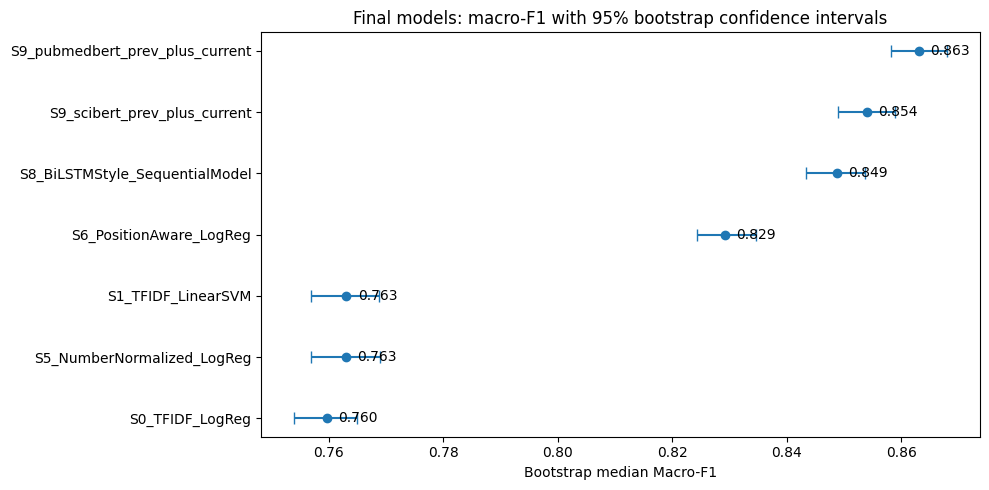

In [100]:
# ============================================================
# PLOT: MACRO-F1 WITH 95% BOOTSTRAP CI
# Compatible with the statistical-validation table above.
# ============================================================

if 'bootstrap_summary_df' not in globals() or bootstrap_summary_df.empty:
    print("Macro-F1 confidence-interval plot skipped because bootstrap_summary_df is empty.")
else:
    plot_df = bootstrap_summary_df.sort_values("Macro-F1", ascending=True).reset_index(drop=True)
    y_pos = np.arange(len(plot_df))
    x = plot_df["Bootstrap median Macro-F1"].to_numpy()
    xerr = np.vstack([
        x - plot_df["95% CI low"].to_numpy(),
        plot_df["95% CI high"].to_numpy() - x
    ])

    plt.figure(figsize=(10, 5))
    plt.errorbar(x, y_pos, xerr=xerr, fmt='o', capsize=4)
    plt.yticks(y_pos, plot_df["Model"])
    plt.xlabel("Bootstrap median Macro-F1")
    plt.title("Final models: macro-F1 with 95% bootstrap confidence intervals")

    for xi, yi in zip(x, y_pos):
        plt.text(xi + 0.002, yi, f"{xi:.3f}", va='center')

    plt.tight_layout()
    plt.show()


In [101]:
import pandas as pd
import numpy as np

def summarize_final_models(
    final_df: pd.DataFrame,
    baseline_model: str = "S0_TFIDF_LogReg",
    sort_metric: str = "macro_f1"
):
    if final_df is None or final_df.empty:
        print("No final results available.")
        return None

    df = final_df.copy()

    # -----------------------------
    # 1. Rank models
    # -----------------------------
    df = df.sort_values(sort_metric, ascending=False).reset_index(drop=True)
    df["Rank"] = df.index + 1

    # -----------------------------
    # 2. Extract baseline performance
    # -----------------------------
    # Modified to check if 'model_name' contains the baseline_model string
    baseline_row_match = df[df["model_name"].str.contains(baseline_model, case=False, na=False)]
    if not baseline_row_match.empty:
        baseline_row = baseline_row_match.iloc[0]
        baseline_macro_f1 = baseline_row["macro_f1"]
    else:
        baseline_macro_f1 = None

    # -----------------------------
    # 3. Compute improvement vs baseline
    # -----------------------------
    if baseline_macro_f1 is not None:
        df["Δ Macro-F1 vs Baseline"] = df["macro_f1"] - baseline_macro_f1
    else:
        df["Δ Macro-F1 vs Baseline"] = np.nan

    # -----------------------------
    # 4. Select key columns
    # -----------------------------
    summary_cols = [
        "Rank",
        "model_name",
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "background_f1",
        "objective_f1",
        "methods_f1",
        "results_f1",
        "conclusions_f1",
        "Δ Macro-F1 vs Baseline"
    ]

    summary_table = df[summary_cols].copy()

    # Round for display
    summary_table = summary_table.round(4)

    # -----------------------------
    # 5. Print table
    # -----------------------------
    print("\nFinal Model Performance Summary (sorted by Macro-F1)\n")
    display(summary_table)

    # -----------------------------
    # 6. Text summary (poster-ready)
    # -----------------------------
    best = df.iloc[0]

    text_summary = (
        f"The best-performing model was {best['model_name']} "
        f"(macro-F1 = {best['macro_f1']:.3f}, accuracy = {best['accuracy']:.3f}). "
    )

    if baseline_macro_f1 is not None:
        delta = best["macro_f1"] - baseline_macro_f1
        text_summary += (
            f"This represents an improvement of {delta:.3f} macro-F1 over the TF-IDF logistic regression baseline."
        )

    print("\nSummary Interpretation:\n")
    print(text_summary)

    return summary_table


# ==============================
# CALL FUNCTION
# ==============================

final_summary_table = summarize_final_models(
    final_df=final_test_results_df,
    baseline_model="S0_TFIDF_LogReg",
    sort_metric="macro_f1"
)


Final Model Performance Summary (sorted by Macro-F1)



,Rank,model_name,accuracy,macro_f1,weighted_f1,background_f1,objective_f1,methods_f1,results_f1,conclusions_f1,Δ Macro-F1 vs Baseline
0,1,FINAL_S9_pubmedbert_prev_plus_current,0.9113,0.8632,0.9104,0.7968,0.6798,0.9592,0.9485,0.9315,0.1036
1,2,FINAL_S9_scibert_prev_plus_current,0.9040,0.8542,0.9026,0.7929,0.6660,0.9547,0.9409,0.9162,0.0946
2,3,FINAL_S8_BiLSTMStyle_SequentialModel,0.8974,0.8487,0.8967,0.7784,0.6502,0.9400,0.9361,0.9387,0.0891
3,4,FINAL_S6_PositionAware_LogReg,0.8795,0.8295,0.8792,0.7386,0.6419,0.9281,0.9201,0.9185,0.0699
4,5,FINAL_S1_TFIDF_LinearSVM,0.8260,0.7631,0.8228,0.6582,0.6137,0.8997,0.8871,0.7568,0.0036
5,6,FINAL_S5_NumberNormalized_LogReg,0.8255,0.7629,0.8237,0.6625,0.6050,0.9045,0.8851,0.7571,0.0033
6,7,FINAL_S0_TFIDF_LogReg,0.8226,0.7595,0.8205,0.6503,0.6065,0.8997,0.8847,0.7565,0.0000



Summary Interpretation:

The best-performing model was FINAL_S9_pubmedbert_prev_plus_current (macro-F1 = 0.863, accuracy = 0.911). This represents an improvement of 0.104 macro-F1 over the TF-IDF logistic regression baseline.


## 32. Integrated performance and capability evaluation

Final performance and capability results are interpreted jointly because high Macro-F1 alone is not enough to establish behavioural reliability (Ribeiro et al., 2020; D'Amour et al., 2022).

The final results jointly rather than sequentially. A model is not treated as reliable solely because it has high Macro-F1; it must also show acceptable behaviour under the pre-specified perturbation tests and a feasible computational profile.


In [79]:
# ============================================================
# INTEGRATED PERFORMANCE + BEHAVIOURAL TABLE
# Jointly reports Macro-F1, audit-qualified invariance consistency,
# exploratory structure consistency, and negation semantic sensitivity.
# ============================================================

# 1) Final performance table
if "final_test_results_df" in globals():
    perf_df = final_test_results_df.copy()
elif "final_summary_df" in globals():
    perf_df = final_summary_df.copy()
elif "final_test_results" in globals() and len(final_test_results) > 0:
    perf_df = pd.DataFrame(final_test_results)
else:
    raise NameError("No final test performance table found. Run the final independent test evaluation first.")

perf_df = perf_df.rename(columns={"model_name": "model"})
perf_df["model"] = perf_df["model"].astype(str).str.replace("^FINAL_", "", regex=True)
if "macro_f1" not in perf_df.columns:
    raise ValueError(f"Final performance table must contain macro_f1. Columns: {perf_df.columns.tolist()}")
perf_df = perf_df[["model", "macro_f1", "accuracy", "weighted_f1"]].drop_duplicates("model")

# 2) Capability table, wide format
if "capability_results_standardised" not in globals() or capability_results_standardised.empty:
    print("Capability results are not available yet; integrated table will contain performance only.")
    capability_wide = pd.DataFrame({"model": perf_df["model"]})
else:
    cap_df = capability_results_standardised.copy()
    cap_df["model"] = cap_df["model"].astype(str).str.replace("^FINAL_", "", regex=True)
    cap_df["perturbation_type"] = cap_df["perturbation_type"].astype(str).str.lower()

    perturbation_name_map = {
        "negation_prefix": "negation",
        "negation": "negation",
        "numeric_perturbation": "numeric",
        "numeric": "numeric",
        "lexical_paraphrase": "paraphrase",
        "paraphrase": "paraphrase",
        "clause_reordering": "structure",
        "structure": "structure",
    }
    cap_df["perturbation_clean"] = cap_df["perturbation_type"].map(
        lambda x: perturbation_name_map.get(x, x)
    )

    cap_summary = (
        cap_df.groupby(["model", "perturbation_clean"], as_index=False)
        .agg(
            robustness_gap=("robustness_gap", "mean"),
            consistency=("consistency", "mean"),
            perturbed_macro_f1=("macro_f1", "mean"),
            n_examples=("n", "max")
        )
    )

    capability_wide = cap_summary.pivot_table(
        index="model",
        columns="perturbation_clean",
        values=["robustness_gap", "consistency"],
        aggfunc="mean"
    )
    capability_wide.columns = [f"{metric}_{ptype}" for metric, ptype in capability_wide.columns]
    capability_wide = capability_wide.reset_index()

integrated_behaviour_table = (
    perf_df.merge(capability_wide, on="model", how="left")
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

# Compact key table required for reporting
key_cols = ["model", "macro_f1"]
for col in ["robustness_gap_negation", "consistency_negation", "consistency_numeric", "consistency_paraphrase", "consistency_structure"]:
    if col in integrated_behaviour_table.columns:
        key_cols.append(col)

key_integrated_table = integrated_behaviour_table[key_cols].copy()
key_integrated_table = key_integrated_table.rename(columns={
    "model": "Model",
    "macro_f1": "Macro-F1",
    "robustness_gap_negation": "Negation Gap",
    "consistency_negation": "Negation Consistency",
    "consistency_numeric": "Numeric Consistency",
    "consistency_paraphrase": "Paraphrase Consistency",
    "consistency_structure": "Structure Consistency",
})

print("Key table: integrated performance and capability evaluation")
display(key_integrated_table.round(4))

# Models within one percentage point of the best Macro-F1
best_macro_f1 = integrated_behaviour_table["macro_f1"].max()
similar_macro_f1_models = integrated_behaviour_table[
    integrated_behaviour_table["macro_f1"] >= best_macro_f1 - 0.01
].copy()

print("Models with Similar Macro-F1: within 1 percentage point of the best independent-test Macro-F1")
display(similar_macro_f1_models.round(4))

if len(similar_macro_f1_models) >= 2:
    print(
        "Interpretation: these models have similar headline Macro-F1, so differences in robustness gap "
        "and consistency are descriptively useful for answering whether performance and behavioural reliability diverge. This subset is post hoc because it is defined after seeing final test performance."
    )
else:
    print(
        "Only one model falls within 1 percentage point of the best Macro-F1 in this run. "
        "The behavioural comparison should therefore focus on the full ranking and confidence intervals."
    )


Key table: integrated performance and capability evaluation


,Model,Macro-F1,Negation Gap,Negation Consistency,Numeric Consistency,Paraphrase Consistency,Structure Consistency
0,S9_pubmedbert_prev_plus_current,0.8632,0.0634,0.7904,0.986,0.954,0.884
1,S9_scibert_prev_plus_current,0.8542,0.0551,0.8184,0.992,0.948,0.824
2,S8_BiLSTMStyle_SequentialModel,0.8487,0.0118,0.8980,0.906,0.908,0.886
3,S6_PositionAware_LogReg,0.8295,0.0515,0.8704,0.970,0.920,0.990
4,S1_TFIDF_LinearSVM,0.7631,0.0344,0.8788,0.988,0.934,0.996
5,S5_NumberNormalized_LogReg,0.7629,0.0628,0.8436,0.990,0.926,0.982
6,S0_TFIDF_LogReg,0.7595,0.0571,0.8468,0.974,0.920,0.986


Models with Similar Macro-F1: within 1 percentage point of the best independent-test Macro-F1


,model,macro_f1,accuracy,weighted_f1,consistency_negation,consistency_numeric,consistency_paraphrase,consistency_structure,robustness_gap_negation,robustness_gap_numeric,robustness_gap_paraphrase,robustness_gap_structure
0,S9_pubmedbert_prev_plus_current,0.8632,0.9113,0.9104,0.7904,0.986,0.954,0.884,0.0634,0.0044,0.0116,-0.0207
1,S9_scibert_prev_plus_current,0.8542,0.9040,0.9026,0.8184,0.992,0.948,0.824,0.0551,-0.0053,-0.0126,-0.1038


Interpretation: these models have similar headline Macro-F1, so differences in robustness gap and consistency are behaviourally meaningful for answering whether performance and reliability diverge.


In [80]:
# ============================================================
# INTEGRATED PERFORMANCE + CAPABILITY BENCHMARK TABLE
# ============================================================

if "final_test_results_df" not in globals():
    raise NameError("final_test_results_df not found. Run final test evaluation first.")

perf = final_test_results_df.copy()

# Standardise model column
if "model" not in perf.columns:
    if "model_name" in perf.columns:
        perf["model"] = perf["model_name"]
    else:
        raise KeyError("final_test_results_df must contain either 'model' or 'model_name'.")

# Standardise Macro-F1 column
if "test_macro_f1" not in perf.columns:
    if "macro_f1" in perf.columns:
        perf["test_macro_f1"] = perf["macro_f1"]
    else:
        raise KeyError("final_test_results_df must contain either 'test_macro_f1' or 'macro_f1'.")

# Ensure model names are clean for merging
perf["model"] = perf["model"].astype(str).str.replace("^FINAL_", "", regex=True)

# Merge with the overall capability summary
integrated_benchmark_table = perf[["model", "test_macro_f1", "accuracy", "weighted_f1"]].merge(
    overall_capability_summary,
    on="model",
    how="left"
)

# Identify similar-F1 models within 1 percentage point of best model
best_f1 = integrated_benchmark_table["test_macro_f1"].max()
integrated_benchmark_table["within_1pp_of_best_f1"] = (
    integrated_benchmark_table["test_macro_f1"] >= best_f1 - 0.01
)

display(
    integrated_benchmark_table.sort_values(
        ["within_1pp_of_best_f1", "test_macro_f1"],
        ascending=[False, False]
    ).round(4)
)

,model,test_macro_f1,accuracy,weighted_f1,mean_invariance_score,min_invariance_score,n_invariance_tests,n_pass,n_fail,mean_robustness_gap,mean_consistency,all_invariance_tests_passed,negation_semantic_sensitivity_gap,negation_prediction_consistency,negation_prediction_change_rate,negation_interpretation_qualification,within_1pp_of_best_f1
0,S9_pubmedbert_prev_plus_current,0.8632,0.9113,0.9104,0.970,0.954,2,2,0,0.0080,0.970,True,0.0634,0.7904,0.2096,automatic_negation_semantic_sensitivity_gap_no...,True
1,S9_scibert_prev_plus_current,0.8542,0.9040,0.9026,0.970,0.948,2,1,1,-0.0089,0.970,False,0.0551,0.8184,0.1816,automatic_negation_semantic_sensitivity_gap_no...,True
2,S8_BiLSTMStyle_SequentialModel,0.8487,0.8974,0.8967,0.907,0.906,2,0,2,-0.0120,0.907,False,0.0118,0.8980,0.1020,automatic_negation_semantic_sensitivity_gap_no...,False
3,S6_PositionAware_LogReg,0.8295,0.8795,0.8792,0.945,0.920,2,1,1,0.0056,0.945,False,0.0515,0.8704,0.1296,automatic_negation_semantic_sensitivity_gap_no...,False
4,S1_TFIDF_LinearSVM,0.7631,0.8260,0.8228,0.961,0.934,2,1,1,0.0134,0.961,False,0.0344,0.8788,0.1212,automatic_negation_semantic_sensitivity_gap_no...,False
5,S5_NumberNormalized_LogReg,0.7629,0.8255,0.8237,0.958,0.926,2,1,1,0.0072,0.958,False,0.0628,0.8436,0.1564,automatic_negation_semantic_sensitivity_gap_no...,False
6,S0_TFIDF_LogReg,0.7595,0.8226,0.8205,0.947,0.920,2,1,1,0.0136,0.947,False,0.0571,0.8468,0.1532,automatic_negation_semantic_sensitivity_gap_no...,False


### 32.1 Benchmark interpretation

Standard performance is separated from behavioural capability so that similar Macro-F1 scores are not mistaken for equivalent robustness (Ribeiro et al., 2020; D'Amour et al., 2022).

This table separates standard predictive performance from benchmarked behavioural capability.

The key comparison is whether models with similar Macro-F1 also have similar capability scores. If two models are within a small margin of the best Macro-F1 but differ in invariance score, negation sensitivity, or benchmark pass/fail outcomes, then aggregate performance alone is insufficient to characterise model reliability.

The benchmark supports three cautious conclusions:

1. Macro-F1 measures task performance but not behavioural reliability.
2. Invariance tests evaluate whether predictions remain stable under intended meaning-preserving perturbations.
3. Negation acts as a semantic-sensitivity probe and should be interpreted separately unless manually validated labels are available.


In [81]:
display(integrated_benchmark_table.round(4))

,model,test_macro_f1,accuracy,weighted_f1,mean_invariance_score,min_invariance_score,n_invariance_tests,n_pass,n_fail,mean_robustness_gap,mean_consistency,all_invariance_tests_passed,negation_semantic_sensitivity_gap,negation_prediction_consistency,negation_prediction_change_rate,negation_interpretation_qualification,within_1pp_of_best_f1
0,S9_pubmedbert_prev_plus_current,0.8632,0.9113,0.9104,0.970,0.954,2,2,0,0.0080,0.970,True,0.0634,0.7904,0.2096,automatic_negation_semantic_sensitivity_gap_no...,True
1,S9_scibert_prev_plus_current,0.8542,0.9040,0.9026,0.970,0.948,2,1,1,-0.0089,0.970,False,0.0551,0.8184,0.1816,automatic_negation_semantic_sensitivity_gap_no...,True
2,S8_BiLSTMStyle_SequentialModel,0.8487,0.8974,0.8967,0.907,0.906,2,0,2,-0.0120,0.907,False,0.0118,0.8980,0.1020,automatic_negation_semantic_sensitivity_gap_no...,False
3,S6_PositionAware_LogReg,0.8295,0.8795,0.8792,0.945,0.920,2,1,1,0.0056,0.945,False,0.0515,0.8704,0.1296,automatic_negation_semantic_sensitivity_gap_no...,False
4,S1_TFIDF_LinearSVM,0.7631,0.8260,0.8228,0.961,0.934,2,1,1,0.0134,0.961,False,0.0344,0.8788,0.1212,automatic_negation_semantic_sensitivity_gap_no...,False
5,S5_NumberNormalized_LogReg,0.7629,0.8255,0.8237,0.958,0.926,2,1,1,0.0072,0.958,False,0.0628,0.8436,0.1564,automatic_negation_semantic_sensitivity_gap_no...,False
6,S0_TFIDF_LogReg,0.7595,0.8226,0.8205,0.947,0.920,2,1,1,0.0136,0.947,False,0.0571,0.8468,0.1532,automatic_negation_semantic_sensitivity_gap_no...,False


In [82]:
print("Updated integrated performance and capability evaluation:")
display(key_integrated_table.round(4))

Updated integrated performance and capability evaluation:


,Model,Macro-F1,Negation Gap,Negation Consistency,Numeric Consistency,Paraphrase Consistency,Structure Consistency
0,S9_pubmedbert_prev_plus_current,0.8632,0.0634,0.7904,0.986,0.954,0.884
1,S9_scibert_prev_plus_current,0.8542,0.0551,0.8184,0.992,0.948,0.824
2,S8_BiLSTMStyle_SequentialModel,0.8487,0.0118,0.8980,0.906,0.908,0.886
3,S6_PositionAware_LogReg,0.8295,0.0515,0.8704,0.970,0.920,0.990
4,S1_TFIDF_LinearSVM,0.7631,0.0344,0.8788,0.988,0.934,0.996
5,S5_NumberNormalized_LogReg,0.7629,0.0628,0.8436,0.990,0.926,0.982
6,S0_TFIDF_LogReg,0.7595,0.0571,0.8468,0.974,0.920,0.986


## 33. Computational efficiency and deployment-cost summary

Deployment-cost summaries are included because practical biomedical NLP choices depend on computational burden as well as final accuracy (Joulin et al., 2017; Paszke et al., 2019; Wolf et al., 2020).

In this section, This section summarises the practical cost of the final fitted systems.

It is included because a biomedical NLP benchmark should not report Macro-F1 alone. A model that performs best may require substantially more training time, memory, and inference cost. Conversely, a simpler model may be less accurate but more feasible to deploy, audit, and rerun.

The following tables are measured under this notebook environment. They should not be interpreted as universal properties of the algorithms. Runtime and memory depend on hardware, batch size, software versions, and implementation details.


In [83]:
# ============================================================
# COMPUTATIONAL EFFICIENCY AND DEPLOYMENT-COST SUMMARY
# ============================================================
# Purpose:
#   Summarise recorded training / inference timing, memory use,
#   model size, and parameter counts for the final fitted systems.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

if "final_fitted_systems" not in globals():
    raise NameError("final_fitted_systems not found. Run final model fitting first.")

if "final_test_results_df" not in globals():
    raise NameError("final_test_results_df not found. Run final independent test evaluation first.")

if "OUTPUT_DIR" not in globals():
    if "OUT_DIR" in globals():
        OUTPUT_DIR = Path(OUT_DIR)
    else:
        OUTPUT_DIR = Path("/content/drive/MyDrive/pubmed_rct_outputs")
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Model introspection: size and parameter counts
# ------------------------------------------------------------

model_introspection_rows = []

for model_name, model_info in final_fitted_systems.items():
    try:
        row = get_model_introspection_for_efficiency(model_name, model_info)
    except Exception as e:
        row = {
            "model": str(model_name),
            "model_family": infer_model_family_for_efficiency(model_name, model_info),
            "n_parameters_total": np.nan,
            "n_parameters_trainable": np.nan,
            "estimated_model_size_mb": np.nan,
            "model_size_method": "failed",
            "introspection_error": str(e),
        }
    model_introspection_rows.append(row)

model_introspection_df = pd.DataFrame(model_introspection_rows)

print("Model size and parameter-count table:")
display(model_introspection_df.round(4))

model_introspection_path = OUTPUT_DIR / "model_introspection_size_parameters.csv"
model_introspection_df.to_csv(model_introspection_path, index=False)


# ------------------------------------------------------------
# 2. Raw efficiency records captured during final model fitting
# ------------------------------------------------------------

efficiency_df = pd.DataFrame(efficiency_records) if "efficiency_records" in globals() else pd.DataFrame()

if efficiency_df.empty:
    print(
        "No prospective timing records found. "
        "Training and final-test inference timings are only recorded when Section 23 is rerun after loading the efficiency instrumentation."
    )
else:
    print("Raw compute-efficiency records:")
    display(efficiency_df.round(4))

    efficiency_raw_path = OUTPUT_DIR / "compute_efficiency_all_raw_records.csv"
    efficiency_df.to_csv(efficiency_raw_path, index=False)
    print("Saved raw compute-efficiency records to:", efficiency_raw_path)


# ------------------------------------------------------------
# 3. Training and inference summaries
# ------------------------------------------------------------

if not efficiency_df.empty and "stage" in efficiency_df.columns:

    training_summary_df = (
        efficiency_df[efficiency_df["stage"].astype(str).str.contains("training", na=False)]
        .groupby("model", as_index=False)
        .agg(
            training_records=("stage", "count"),
            training_n_examples_median=("n_examples", "median"),
            training_elapsed_minutes_total=("elapsed_minutes", "sum"),
            training_seconds_per_1000_examples_mean=("seconds_per_1000_examples", "mean"),
            training_cpu_peak_rss_gb_max=("cpu_peak_rss_gb", "max"),
            training_gpu_peak_allocated_gb_max=("gpu_peak_allocated_gb", "max"),
            training_gpu_peak_reserved_gb_max=("gpu_peak_reserved_gb", "max"),
            training_hardware=("hardware", "first"),
        )
    )

    inference_summary_df = (
        efficiency_df[efficiency_df["stage"].astype(str).str.contains("inference|prediction", case=False, regex=True, na=False)]
        .groupby("model", as_index=False)
        .agg(
            inference_records=("stage", "count"),
            inference_n_examples_median=("n_examples", "median"),
            inference_elapsed_seconds_total=("elapsed_seconds", "sum"),
            inference_seconds_per_1000_examples_mean=("seconds_per_1000_examples", "mean"),
            inference_examples_per_second_mean=("examples_per_second", "mean"),
            inference_cpu_peak_rss_gb_max=("cpu_peak_rss_gb", "max"),
            inference_gpu_peak_allocated_gb_max=("gpu_peak_allocated_gb", "max"),
            inference_gpu_peak_reserved_gb_max=("gpu_peak_reserved_gb", "max"),
            inference_hardware=("hardware", "first"),
        )
    )

else:
    training_summary_df = pd.DataFrame({
        "model": list(final_fitted_systems.keys()),
        "training_elapsed_minutes_total": np.nan,
        "training_hardware": "not_measured",
        "training_note": "Rerun Section 23 after loading efficiency instrumentation to measure training time."
    })

    inference_summary_df = pd.DataFrame({
        "model": list(final_fitted_systems.keys()),
        "inference_seconds_per_1000_examples_mean": np.nan,
        "inference_hardware": "not_measured",
        "inference_note": "Rerun Section 23 after loading efficiency instrumentation to measure final-test inference time."
    })

print("\nTraining efficiency summary:")
display(training_summary_df.round(4))

print("\nInference efficiency summary:")
display(inference_summary_df.round(4))

training_summary_path = OUTPUT_DIR / "training_efficiency_summary.csv"
inference_summary_path = OUTPUT_DIR / "inference_efficiency_summary.csv"

training_summary_df.to_csv(training_summary_path, index=False)
inference_summary_df.to_csv(inference_summary_path, index=False)


# ------------------------------------------------------------
# 4. Merge with final performance and capability behaviour
# ------------------------------------------------------------

performance_df = final_test_results_df.copy()

if "model" not in performance_df.columns:
    if "model_name" in performance_df.columns:
        performance_df["model"] = performance_df["model_name"].astype(str).str.replace("FINAL_", "", regex=False)
    else:
        raise KeyError("final_test_results_df must contain either 'model' or 'model_name'.")

performance_keep_cols = [
    "model",
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "background_f1",
    "objective_f1",
    "methods_f1",
    "results_f1",
    "conclusions_f1",
]
performance_keep_cols = [c for c in performance_keep_cols if c in performance_df.columns]
performance_df = performance_df[performance_keep_cols].copy()

performance_efficiency_df = (
    performance_df
    .merge(model_introspection_df, on="model", how="left")
    .merge(training_summary_df, on="model", how="left")
    .merge(inference_summary_df, on="model", how="left")
)

# Add capability columns when already available.
capability_source = None
if "key_integrated_table" in globals() and isinstance(key_integrated_table, pd.DataFrame):
    capability_source = key_integrated_table.copy()
elif "integrated_behaviour_table" in globals() and isinstance(integrated_behaviour_table, pd.DataFrame):
    capability_source = integrated_behaviour_table.copy()

if capability_source is not None and not capability_source.empty:
    if "model" not in capability_source.columns and "model_name" in capability_source.columns:
        capability_source["model"] = capability_source["model_name"].astype(str).str.replace("FINAL_", "", regex=False)

    capability_cols = [
        "model",
        "robustness_gap_negation",
        "consistency_negation",
        "consistency_numeric",
        "consistency_paraphrase",
        "consistency_structure",
        "mean_audit_qualified_invariance_consistency",
        "negation_semantic_sensitivity_gap",
        "mean_invariance_score",
        "all_invariance_tests_passed",
    ]
    capability_cols = [c for c in capability_cols if c in capability_source.columns]
    if "model" in capability_cols:
        performance_efficiency_df = performance_efficiency_df.merge(
            capability_source[capability_cols].drop_duplicates("model"),
            on="model",
            how="left",
        )

# Descriptive cost-performance ratios.
if "inference_seconds_per_1000_examples_mean" in performance_efficiency_df.columns:
    performance_efficiency_df["macro_f1_per_inference_second_per_1000"] = (
        performance_efficiency_df["macro_f1"] / performance_efficiency_df["inference_seconds_per_1000_examples_mean"]
    )

if "estimated_model_size_mb" in performance_efficiency_df.columns:
    performance_efficiency_df["macro_f1_per_100mb_model_size"] = (
        performance_efficiency_df["macro_f1"] / (performance_efficiency_df["estimated_model_size_mb"] / 100)
    )

compact_cols = [
    "model",
    "model_family",
    "macro_f1",
    "accuracy",
    "weighted_f1",
    "objective_f1",
    "robustness_gap_negation",
    "mean_audit_qualified_invariance_consistency",
    "estimated_model_size_mb",
    "n_parameters_total",
    "n_parameters_trainable",
    "training_elapsed_minutes_total",
    "inference_seconds_per_1000_examples_mean",
    "inference_examples_per_second_mean",
    "training_gpu_peak_allocated_gb_max",
    "inference_gpu_peak_allocated_gb_max",
    "inference_hardware",
]
compact_cols = [c for c in compact_cols if c in performance_efficiency_df.columns]

performance_efficiency_compact_df = (
    performance_efficiency_df[compact_cols]
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

print("\nPerformance-efficiency trade-off table:")
display(performance_efficiency_compact_df.round(4))

performance_efficiency_full_path = OUTPUT_DIR / "performance_efficiency_tradeoff_full.csv"
performance_efficiency_compact_path = OUTPUT_DIR / "performance_efficiency_tradeoff_compact.csv"

performance_efficiency_df.to_csv(performance_efficiency_full_path, index=False)
performance_efficiency_compact_df.to_csv(performance_efficiency_compact_path, index=False)

print("Saved full performance-efficiency table to:", performance_efficiency_full_path)
print("Saved compact performance-efficiency table to:", performance_efficiency_compact_path)


# ------------------------------------------------------------
# 5. Manuscript-ready interpretation note
# ------------------------------------------------------------

print(
    "\nInterpretation note for manuscript:\n"
    "Computational efficiency was measured under the same notebook environment used for final evaluation. "
    "Training time, inference latency, and memory use are implementation-specific and depend on hardware, "
    "batch size, software versions, and caching. They should be interpreted as practical deployment indicators "
    "alongside Macro-F1, uncertainty intervals, and capability-oriented robustness metrics."
)


Model size and parameter-count table:


,model,model_family,n_parameters_total,n_parameters_trainable,estimated_model_size_mb,model_size_method
0,S6_PositionAware_LogReg,classical,NaN,NaN,63.3848,serialized_joblib_or_pickle
1,S5_NumberNormalized_LogReg,classical,NaN,NaN,55.9074,serialized_joblib_or_pickle
2,S1_TFIDF_LinearSVM,classical,NaN,NaN,63.3844,serialized_joblib_or_pickle
3,S0_TFIDF_LogReg,classical,NaN,NaN,63.3846,serialized_joblib_or_pickle
4,S9_pubmedbert_prev_plus_current,transformer,109486085.0,109486085.0,417.6563,torch_parameter_bytes
5,S9_scibert_prev_plus_current,transformer,109922309.0,109922309.0,419.3203,torch_parameter_bytes
6,S8_BiLSTMStyle_SequentialModel,sequence_bilstm,5492037.0,5492037.0,20.9505,torch_parameter_bytes


Raw compute-efficiency records:


,model,stage,n_examples,elapsed_seconds,elapsed_minutes,seconds_per_1000_examples,examples_per_second,cpu_start_rss_gb,cpu_peak_rss_gb,cpu_end_rss_gb,cpu_peak_increment_gb,gpu_peak_allocated_gb,gpu_peak_reserved_gb,hardware,notes
0,S6_PositionAware_LogReg,final_training,180040,356.5575,5.9426,1.9804,504.9396,6.2336,7.8394,6.5460,1.6058,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical final fit on full training split
1,S6_PositionAware_LogReg,final_test_inference,30135,0.5269,0.0088,0.0175,57189.7344,6.3207,6.3207,6.3207,0.0000,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical independent test prediction; text_co...
2,S5_NumberNormalized_LogReg,final_training,180040,132.7429,2.2124,0.7373,1356.3057,6.3207,7.7419,6.6576,1.4212,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical final fit on full training split
3,S5_NumberNormalized_LogReg,final_test_inference,30135,0.4977,0.0083,0.0165,60542.5245,6.5584,6.5584,6.5584,0.0000,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical independent test prediction; text_co...
4,S1_TFIDF_LinearSVM,final_training,180040,8.4313,0.1405,0.0468,21353.7710,6.5584,6.8987,6.7097,0.3403,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical final fit on full training split
5,S1_TFIDF_LinearSVM,final_test_inference,30135,0.5152,0.0086,0.0171,58494.6961,6.6529,6.6529,6.6529,0.0000,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical independent test prediction; text_co...
6,S0_TFIDF_LogReg,final_training,180040,174.0787,2.9013,0.9669,1034.2448,6.6529,8.2079,6.9672,1.5550,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical final fit on full training split
7,S0_TFIDF_LogReg,final_test_inference,30135,0.5108,0.0085,0.0169,58999.9490,6.8589,6.8589,6.8589,0.0000,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition,classical independent test prediction; text_co...
8,S9_pubmedbert_prev_plus_current,final_training,180040,1067.6513,17.7942,5.9301,168.6318,7.0471,7.0473,7.0473,0.0002,9.3428,10.1074,NVIDIA RTX PRO 6000 Blackwell Server Edition,transformer fine-tuning; model_key=pubmedbert;...
9,S9_pubmedbert_prev_plus_current,final_test_inference,30135,23.2071,0.3868,0.7701,1298.5255,7.0473,7.0473,7.0473,0.0000,8.7513,9.3809,NVIDIA RTX PRO 6000 Blackwell Server Edition,transformer final test prediction; model_key=p...


Saved raw compute-efficiency records to: /content/drive/MyDrive/pubmed_rct_outputs/compute_efficiency_all_raw_records.csv

Training efficiency summary:


...


Inference efficiency summary:


,model,inference_records,inference_n_examples_median,inference_elapsed_seconds_total,inference_seconds_per_1000_examples_mean,inference_examples_per_second_mean,inference_cpu_peak_rss_gb_max,inference_gpu_peak_allocated_gb_max,inference_gpu_peak_reserved_gb_max,inference_hardware
0,S0_TFIDF_LogReg,1,30135.0,0.5108,0.0169,58999.9490,6.8589,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition
1,S1_TFIDF_LinearSVM,1,30135.0,0.5152,0.0171,58494.6961,6.6529,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition
2,S5_NumberNormalized_LogReg,1,30135.0,0.4977,0.0165,60542.5245,6.5584,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition
3,S6_PositionAware_LogReg,1,30135.0,0.5269,0.0175,57189.7344,6.3207,7.4902,8.0293,NVIDIA RTX PRO 6000 Blackwell Server Edition
4,S8_BiLSTMStyle_SequentialModel,1,2500.0,0.4297,0.1719,5818.1606,7.4581,10.0192,10.8086,NVIDIA RTX PRO 6000 Blackwell Server Edition
5,S9_pubmedbert_prev_plus_current,1,30135.0,23.2071,0.7701,1298.5255,7.0473,8.7513,9.3809,NVIDIA RTX PRO 6000 Blackwell Server Edition
6,S9_scibert_prev_plus_current,1,30135.0,23.2122,0.7703,1298.2414,7.4531,9.9872,10.7461,NVIDIA RTX PRO 6000 Blackwell Server Edition



Performance-efficiency trade-off table:


,model,model_family,macro_f1,accuracy,weighted_f1,objective_f1,estimated_model_size_mb,n_parameters_total,n_parameters_trainable,training_elapsed_minutes_total,inference_seconds_per_1000_examples_mean,inference_examples_per_second_mean,training_gpu_peak_allocated_gb_max,inference_gpu_peak_allocated_gb_max,inference_hardware
0,S9_pubmedbert_prev_plus_current,transformer,0.8632,0.9113,0.9104,0.6798,417.6563,109486085.0,109486085.0,17.7942,0.7701,1298.5255,9.3428,8.7513,NVIDIA RTX PRO 6000 Blackwell Server Edition
1,S9_scibert_prev_plus_current,transformer,0.8542,0.9040,0.9026,0.6660,419.3203,109922309.0,109922309.0,17.8762,0.7703,1298.2414,10.5780,9.9872,NVIDIA RTX PRO 6000 Blackwell Server Edition
2,S8_BiLSTMStyle_SequentialModel,sequence_bilstm,0.8487,0.8974,0.8967,0.6502,20.9505,5492037.0,5492037.0,0.2377,0.1719,5818.1606,10.0609,10.0192,NVIDIA RTX PRO 6000 Blackwell Server Edition
3,S6_PositionAware_LogReg,classical,0.8295,0.8795,0.8792,0.6419,63.3848,NaN,NaN,5.9426,0.0175,57189.7344,7.4902,7.4902,NVIDIA RTX PRO 6000 Blackwell Server Edition
4,S1_TFIDF_LinearSVM,classical,0.7631,0.8260,0.8228,0.6137,63.3844,NaN,NaN,0.1405,0.0171,58494.6961,7.4902,7.4902,NVIDIA RTX PRO 6000 Blackwell Server Edition
5,S5_NumberNormalized_LogReg,classical,0.7629,0.8255,0.8237,0.6050,55.9074,NaN,NaN,2.2124,0.0165,60542.5245,7.4902,7.4902,NVIDIA RTX PRO 6000 Blackwell Server Edition
6,S0_TFIDF_LogReg,classical,0.7595,0.8226,0.8205,0.6065,63.3846,NaN,NaN,2.9013,0.0169,58999.9490,7.4902,7.4902,NVIDIA RTX PRO 6000 Blackwell Server Edition


Saved full performance-efficiency table to: /content/drive/MyDrive/pubmed_rct_outputs/performance_efficiency_tradeoff_full.csv
Saved compact performance-efficiency table to: /content/drive/MyDrive/pubmed_rct_outputs/performance_efficiency_tradeoff_compact.csv

Interpretation note for manuscript:
Computational efficiency was measured under the same notebook environment used for final evaluation. Training time, inference latency, and memory use are implementation-specific and depend on hardware, batch size, software versions, and caching. They should be interpreted as practical deployment indicators alongside Macro-F1, uncertainty intervals, and capability-oriented robustness metrics.


## 34. Cross-scale evaluation: PubMed RCT 20k versus 200k

The 20k-versus-200k comparison is used to test whether the observed performance and robustness patterns persist at a larger PubMed RCT scale (Dernoncourt & Lee, 2017).

This section evaluates whether patterns observed in PubMed RCT 20k persist under PubMed RCT 200k. The 200k dataset was introduced as a larger sequential sentence-classification benchmark for medical abstracts (Dernoncourt & Lee, 2017).

The 200k experiment has two interpretation layers.

1. **Strict cross-scale validation for classical models**  
   Classical systems are rerun with matched preprocessing, feature engineering, and hyperparameter choices. This is the cleanest cross-scale comparison because these models are computationally tractable under a consistent protocol.

2. **Exploratory neural and transformer stress-test validation**  
   BiLSTM-style and transformer 200k runs may use capped training or test samples because full 200k training is computationally expensive in Colab. These results are useful as stress tests, but they should not be described as fully equivalent across model families unless the same sample sizes and training budgets are enforced.

The 200k section asks:

- Do behavioural weaknesses, especially negation sensitivity, persist at larger scale?
- Are standard performance and perturbation behaviour aligned?
- Which results are strictly comparable, and which are exploratory because of different sample or training regimes?

The analysis does not claim universal model-family superiority from the 200k results unless the protocol comparability audit confirms equivalent training and evaluation regimes.


In [84]:
# ============================================================
# ROBUST PUBMED RCT LOADER FOR 20K / 200K FORMAT
# ============================================================

import os
import re
import pandas as pd
import numpy as np

LABEL_ORDER = ["background", "objective", "methods", "results", "conclusions"]


def load_pubmed_rct_flexible(path: str, split_name: str) -> pd.DataFrame:
    """
    Robust loader for PubMed RCT 20k / 200k files.

    Supports both formats:

    Format A:
        PubMedID<TAB>label<TAB>text

    Format B:
        ###PubMedID
        LABEL<TAB>text
        LABEL<TAB>text

    Returns:
        pubmed_id, label, text, split, file_order
    """

    rows = []
    current_pubmed_id = None
    sentence_order = 0

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    with open(path, "r", encoding="utf-8") as f:
        for line_num, raw_line in enumerate(f):
            line = raw_line.strip()

            if not line:
                continue

            # Abstract boundary line, e.g. ###24219770
            if line.startswith("###"):
                current_pubmed_id = line.replace("###", "").strip()
                sentence_order = 0
                continue

            parts = line.split("\t")

            # Format A: PubMedID<TAB>label<TAB>text
            if len(parts) == 3:
                pubmed_id, label, text = parts

            # Format B: LABEL<TAB>text, with pubmed_id from previous ### line
            elif len(parts) == 2:
                label, text = parts
                pubmed_id = current_pubmed_id

            else:
                # Skip malformed lines
                continue

            label = str(label).strip().lower()
            text = str(text).strip()

            # Keep only expected labels
            if label not in LABEL_ORDER:
                continue

            if pubmed_id is None or str(pubmed_id).strip() == "":
                pubmed_id = f"{split_name}_unknown_{line_num}"

            rows.append({
                "pubmed_id": str(pubmed_id),
                "label": label,
                "text": text,
                "split": split_name,
                "file_order": line_num,
                "sentence_index_raw": sentence_order
            })

            sentence_order += 1

    df = pd.DataFrame(rows)

    if df.empty:
        print(f"WARNING: Loaded 0 rows from {path}")
    else:
        print(f"Loaded {len(df):,} rows from {path}")
        print(df["label"].value_counts())

    return df


def normalize_numbers(text: str) -> str:
    return re.sub(r"\d", "0", str(text))


def add_sentence_position_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Add abstract-level sentence-position features.
    Safe for empty dataframes.
    """

    expected_cols = ["pubmed_id", "label", "text", "split", "file_order"]

    if df is None or df.empty:
        out = pd.DataFrame(columns=expected_cols)
        out["sentence_index_in_abstract"] = []
        out["abstract_length"] = []
        out["relative_position"] = []
        out["is_first_sentence"] = []
        out["is_last_sentence"] = []
        out["text_num_norm"] = []
        return out

    df = df.copy().sort_values(["pubmed_id", "file_order"]).reset_index(drop=True)

    df["sentence_index_in_abstract"] = df.groupby("pubmed_id").cumcount()
    df["abstract_length"] = df.groupby("pubmed_id")["pubmed_id"].transform("size")

    df["relative_position"] = np.where(
        df["abstract_length"] > 1,
        df["sentence_index_in_abstract"] / (df["abstract_length"] - 1),
        0.0
    )

    df["is_first_sentence"] = (df["sentence_index_in_abstract"] == 0).astype(int)
    df["is_last_sentence"] = (
        df["sentence_index_in_abstract"] == (df["abstract_length"] - 1)
    ).astype(int)

    df["text_num_norm"] = df["text"].astype(str).apply(normalize_numbers)

    return df

In [85]:
# ============================================================
# LOAD PUBMED RCT 200K WITH FLEXIBLE LOADER
# ============================================================

train_200k_path = "/content/drive/MyDrive/PubMed_RCT_200k_extracted/train200k.txt"
dev_200k_path = "/content/drive/MyDrive/dev200k.txt"
test_200k_path = "/content/drive/MyDrive/test200k.txt"

print("Checking PubMed RCT 200k paths:")
for name, path in {
    "train": train_200k_path,
    "dev": dev_200k_path,
    "test": test_200k_path
}.items():
    print(f"{name}: {path} | exists={os.path.exists(path)}")

train_200k_df = load_pubmed_rct_flexible(train_200k_path, "train_200k")
dev_200k_df = load_pubmed_rct_flexible(dev_200k_path, "dev_200k")
test_200k_df = load_pubmed_rct_flexible(test_200k_path, "test_200k")

train_200k_df = add_sentence_position_features(train_200k_df)
dev_200k_df = add_sentence_position_features(dev_200k_df)
test_200k_df = add_sentence_position_features(test_200k_df)

print("\nPubMed RCT 200k split sizes after robust loading:")
print("Train:", train_200k_df.shape)
print("Dev:  ", dev_200k_df.shape)
print("Test: ", test_200k_df.shape)

display(train_200k_df.head())

Checking PubMed RCT 200k paths:
train: /content/drive/MyDrive/PubMed_RCT_200k_extracted/train200k.txt | exists=True
dev: /content/drive/MyDrive/dev200k.txt | exists=True
test: /content/drive/MyDrive/test200k.txt | exists=True
Loaded 2,211,861 rows from /content/drive/MyDrive/PubMed_RCT_200k_extracted/train200k.txt
label
results        766271
methods        722586
conclusions    339714
background     196689
objective      186601
Name: count, dtype: int64
Loaded 28,932 rows from /content/drive/MyDrive/dev200k.txt
label
results        9977
methods        9559
conclusions    4396
background     2575
objective      2425
Name: count, dtype: int64
Loaded 29,493 rows from /content/drive/MyDrive/test200k.txt
label
results        10276
methods         9751
conclusions     4426
background      2663
objective       2377
Name: count, dtype: int64

PubMed RCT 200k split sizes after robust loading:
Train: (2211861, 12)
Dev:   (28932, 12)
Test:  (29493, 12)


,pubmed_id,label,text,split,file_order,sentence_index_raw,sentence_index_in_abstract,abstract_length,relative_position,is_first_sentence,is_last_sentence,text_num_norm
0,10021304,objective,The aim of the study was to evaluate the effec...,train_200k,566635,0,0,11,0.0,1,0,The aim of the study was to evaluate the effec...
1,10021304,methods,Between 1985 and 1992 64 patients with radical...,train_200k,566636,1,1,11,0.1,0,0,Between 0000 and 0000 00 patients with radical...
2,10021304,methods,Radical surgery comprised total abdominal hyst...,train_200k,566637,2,2,11,0.2,0,0,Radical surgery comprised total abdominal hyst...
3,10021304,methods,All patients received adjuvant chemotherapy wi...,train_200k,566638,3,3,11,0.3,0,0,All patients received adjuvant chemotherapy wi...
4,10021304,methods,Thirty-two patients without residual disease w...,train_200k,566639,4,4,11,0.4,0,0,Thirty-two patients without residual disease w...


In [ ]:
# ============================================================
# SANITY CHECK BEFORE 200K TRAINING
# ============================================================

for split_name, df in {
    "train_200k": train_200k_df,
    "dev_200k": dev_200k_df,
    "test_200k": test_200k_df
}.items():
    print("\n" + "=" * 80)
    print(split_name)
    print("Shape:", df.shape)

    if df.empty:
        raise ValueError(
            f"{split_name} is empty. Stop here: the file path or loader is wrong."
        )

    print("Labels:")
    print(df["label"].value_counts())

    print("\nExample rows:")
    display(df[["pubmed_id", "label", "text"]].head(3))

In [99]:
# ============================================================
# PUBMED RCT 200K CROSS-SCALE VALIDATION: STRICT CLASSICAL MODEL BLOCK
# FULL WORKED CELL WITH TF-IDF INPUT-SHAPE FIX
#
# Fix included:
# - Simple TF-IDF pipelines are fitted with a 1D text Series.
# - PositionAwareTextClassifier receives the full dataframe.
# - ColumnTransformer-based pipelines receive dataframe input.
# - Already completed models are skipped where possible.
# ============================================================

import os
import re
import gc
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC


# ============================================================
# 0. CONTROLS
# ============================================================

RUN_200K_EVALUATION = True

# Use a fixed stratified fraction of the 200k training data for the strict classical cross-scale block.
# This is computationally feasible for classical models and should be reported as the classical 200k protocol.
TRAIN_200K_FRAC = 0.10

# Full test set is ~29k rows. Use 1.00 for final validation.
# For debugging, set to 0.25.
TEST_200K_FRAC = 1.00

RANDOM_STATE_200K = 42

DEFAULT_200K_MODELS = [
    "S6_PositionAware_LogReg",
    "S5_NumberNormalized_LogReg",
    "S0_TFIDF_LogReg",
    "S1_TFIDF_LinearSVM",
]

print("PubMed RCT 200k cross-scale validation settings:")
print(f"RUN_200K_EVALUATION = {RUN_200K_EVALUATION}")
print(f"TRAIN_200K_FRAC     = {TRAIN_200K_FRAC}")
print(f"TEST_200K_FRAC      = {TEST_200K_FRAC}")
print(f"RANDOM_STATE_200K   = {RANDOM_STATE_200K}")


# ============================================================
# 1. LOCATE / EXTRACT PUBMED RCT 200K FILES
# ============================================================

MYDRIVE = Path("/content/drive/MyDrive")

PUBMED200K_WORK_DIR = MYDRIVE / "PubMed_RCT_200k_extracted"
PUBMED200K_WORK_DIR.mkdir(exist_ok=True)

train_archive_200k = MYDRIVE / "train200k.7z"
dev_file_200k = MYDRIVE / "dev200k.txt"
test_file_200k = MYDRIVE / "test200k.txt"

train_file_200k = PUBMED200K_WORK_DIR / "train200k.txt"

# Extract train archive only if needed.
if train_archive_200k.exists() and not train_file_200k.exists():
    print(f"\nExtracting train archive: {train_archive_200k}")

    if shutil.which("7z") is None:
        print("7z not found. Attempting to install p7zip-full...")
        subprocess.run(["apt-get", "-qq", "update"], check=False)
        subprocess.run(["apt-get", "-qq", "install", "-y", "p7zip-full"], check=False)

    subprocess.run(
        ["7z", "e", str(train_archive_200k), f"-o{PUBMED200K_WORK_DIR}", "-y"],
        check=True
    )

    extracted_txt_files = list(PUBMED200K_WORK_DIR.glob("*.txt"))
    if len(extracted_txt_files) > 0:
        extracted_train = max(extracted_txt_files, key=lambda p: p.stat().st_size)
        if extracted_train.name != "train200k.txt":
            shutil.move(str(extracted_train), str(train_file_200k))

path_200k = {
    "train": train_file_200k,
    "dev": dev_file_200k,
    "test": test_file_200k,
}

missing_200k = [k for k, v in path_200k.items() if not v.exists()]

if missing_200k:
    RUN_200K_EVALUATION = False
    print("\nPubMed RCT 200k validation files were not found:")
    for k in missing_200k:
        print(f"  Missing {k}: {path_200k[k]}")
else:
    print("\nPubMed RCT 200k files found:")
    for k, v in path_200k.items():
        print(f"  {k}: {v}")


# ============================================================
# 2. FALLBACK UTILITIES
# ============================================================

if "LABEL_ORDER" not in globals():
    LABEL_ORDER = ["background", "objective", "methods", "results", "conclusions"]


def normalize_numbers_200k(text: str) -> str:
    return re.sub(r"\d", "0", str(text))


if "load_pubmed_rct_flexible" not in globals():
    def load_pubmed_rct_flexible(path: str, split_name: str) -> pd.DataFrame:
        """
        Flexible loader for PubMed RCT files.

        Supports:
        1. PubMedID<TAB>label<TAB>text
        2. ###PubMedID followed by LABEL<TAB>text
        """
        rows = []
        current_pubmed_id = None
        sentence_order = 0

        with open(path, "r", encoding="utf-8", errors="replace") as f:
            for line_num, raw_line in enumerate(f):
                line = raw_line.strip()

                if not line:
                    continue

                if line.startswith("###"):
                    current_pubmed_id = line.replace("###", "").strip()
                    sentence_order = 0
                    continue

                parts = line.split("\t")

                if len(parts) == 3:
                    pubmed_id, label, text = parts
                elif len(parts) == 2:
                    label, text = parts
                    pubmed_id = current_pubmed_id
                else:
                    continue

                label = str(label).strip().lower()
                text = str(text).strip()

                if label not in LABEL_ORDER:
                    continue

                if pubmed_id is None or str(pubmed_id).strip() == "":
                    pubmed_id = f"{split_name}_unknown_{line_num}"

                rows.append({
                    "pubmed_id": str(pubmed_id),
                    "label": label,
                    "text": text,
                    "split": split_name,
                    "file_order": line_num,
                    "sentence_index_raw": sentence_order,
                })

                sentence_order += 1

        df = pd.DataFrame(rows)

        print(f"Loaded {len(df):,} rows from {path}")
        if not df.empty:
            print(df["label"].value_counts())

        return df


if "add_sentence_position_features" not in globals():
    def add_sentence_position_features(df: pd.DataFrame) -> pd.DataFrame:
        """
        Add sentence-position features and number-normalised text.
        """
        if df is None or df.empty:
            return pd.DataFrame(columns=[
                "pubmed_id", "label", "text", "split", "file_order",
                "sentence_index_in_abstract", "abstract_length",
                "relative_position", "is_first_sentence", "is_last_sentence",
                "text_num_norm"
            ])

        df = df.copy().sort_values(["pubmed_id", "file_order"]).reset_index(drop=True)

        df["sentence_index_in_abstract"] = df.groupby("pubmed_id").cumcount()
        df["abstract_length"] = df.groupby("pubmed_id")["pubmed_id"].transform("size")

        df["relative_position"] = np.where(
            df["abstract_length"] > 1,
            df["sentence_index_in_abstract"] / (df["abstract_length"] - 1),
            0.0
        )

        df["is_first_sentence"] = (df["sentence_index_in_abstract"] == 0).astype(int)
        df["is_last_sentence"] = (
            df["sentence_index_in_abstract"] == (df["abstract_length"] - 1)
        ).astype(int)

        df["text_num_norm"] = df["text"].astype(str).apply(normalize_numbers_200k)

        return df


def macro_f1_from_arrays(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)


def stratified_sample_df(df, frac=0.10, label_col="label", random_state=42):
    """
    Stratified sample by label, preserving label balance.
    """
    if df.empty:
        return df.copy()

    if frac >= 1.0:
        return df.copy().reset_index(drop=True)

    sampled_parts = []

    for label, group in df.groupby(label_col):
        n = max(1, int(round(len(group) * frac)))
        sampled_parts.append(
            group.sample(n=n, random_state=random_state, replace=False)
        )

    return (
        pd.concat(sampled_parts, axis=0)
        .sample(frac=1.0, random_state=random_state)
        .reset_index(drop=True)
    )


# ============================================================
# 3. FAST LOADING: SAMPLE BEFORE FEATURE ENGINEERING
# ============================================================

def load_and_prepare_pubmed200k_fast(
    path_map,
    train_frac=0.10,
    test_frac=1.00,
    random_state=42
):
    """
    Fast PubMed RCT 200k loader.

    Key design:
    - load raw train rows;
    - stratified-sample train rows before expensive feature engineering;
    - add features only to working train/dev/test.
    """

    print("\nLoading raw PubMed RCT 200k TRAIN split...")
    train_raw = load_pubmed_rct_flexible(str(path_map["train"]), "200k_train")

    if train_raw.empty:
        raise ValueError("Raw PubMed RCT 200k train split loaded as empty.")

    print(f"\nSampling {train_frac:.0%} of 200k TRAIN split before feature engineering...")
    train_work = stratified_sample_df(
        train_raw,
        frac=train_frac,
        label_col="label",
        random_state=random_state
    )

    print("Sampled train shape:", train_work.shape)
    print("Sampled train label distribution:")
    print(train_work["label"].value_counts())

    del train_raw
    gc.collect()

    print("\nLoading raw PubMed RCT 200k DEV split...")
    dev_raw = load_pubmed_rct_flexible(str(path_map["dev"]), "200k_dev")

    print("\nLoading raw PubMed RCT 200k TEST split...")
    test_raw = load_pubmed_rct_flexible(str(path_map["test"]), "200k_test")

    if test_frac < 1.0:
        print(f"\nSampling {test_frac:.0%} of 200k TEST split...")
        test_work = stratified_sample_df(
            test_raw,
            frac=test_frac,
            label_col="label",
            random_state=random_state
        )
    else:
        test_work = test_raw.copy().reset_index(drop=True)

    dev_work = dev_raw.copy().reset_index(drop=True)

    print("\nAdding sentence-position and number-normalised features...")
    train_work = add_sentence_position_features(train_work)
    dev_work = add_sentence_position_features(dev_work)
    test_work = add_sentence_position_features(test_work)

    for df in [train_work, dev_work, test_work]:
        if not df.empty and "label" in df.columns and "label_encoder" in globals():
            df["label_id"] = label_encoder.transform(df["label"])

    print("\nWorking PubMed RCT 200k split sizes after sampling and preprocessing:")
    print("Train:", train_work.shape)
    print("Dev:  ", dev_work.shape)
    print("Test: ", test_work.shape)

    return train_work, dev_work, test_work


# ============================================================
# 4. MODEL FITTING / PREDICTION WITH INPUT-SHAPE FIX
# ============================================================

def make_safe_tfidf_pipeline(model_name, text_col="text"):
    """
    Safer fallback TF-IDF pipelines for 200k-scale validation.

    These pipelines start directly with TfidfVectorizer, so they must be
    fitted/predicted with a 1D text Series.
    """
    if model_name in ["S0_TFIDF_LogReg", "S5_NumberNormalized_LogReg"]:
        return Pipeline([
            ("tfidf", TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=5,
                max_features=300000
            )),
            ("clf", LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                solver="saga",
                n_jobs=-1,
                random_state=RANDOM_STATE_200K
            ))
        ])

    if model_name == "S1_TFIDF_LinearSVM":
        return Pipeline([
            ("tfidf", TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=5,
                max_features=300000
            )),
            ("clf", LinearSVC())
        ])

    raise ValueError(f"No safe fallback pipeline defined for {model_name}")


def estimator_expects_series(estimator):
    """
    True when estimator is a simple Pipeline beginning with TfidfVectorizer.
    Such estimators need a 1D text Series.

    False for:
    - PositionAwareTextClassifier
    - ColumnTransformer-based pipelines
    - dataframe-aware custom estimators
    """
    if isinstance(estimator, Pipeline):
        first_step = estimator.steps[0][1]
        if isinstance(first_step, TfidfVectorizer):
            return True
        if isinstance(first_step, ColumnTransformer):
            return False

    return False


def fit_same_classical_model_on_200k(model_name, train_df):
    """
    Refit selected model structure on 10% PubMed RCT 200k.

    No hyperparameter retuning is performed. The aim is cross-scale validation,
    not 200k optimisation.
    """

    if model_name == "S6_PositionAware_LogReg":
        if "PositionAwareTextClassifier" not in globals():
            raise NameError("PositionAwareTextClassifier is not defined in this notebook.")

        estimator = PositionAwareTextClassifier(
            text_col="text",
            min_df=5,
            C=10.0,
            class_weight="balanced",
            max_iter=1000
        )
        text_col = "text"

    elif model_name == "S5_NumberNormalized_LogReg":
        estimator = make_safe_tfidf_pipeline(model_name, text_col="text_num_norm")
        text_col = "text_num_norm"

    elif model_name == "S0_TFIDF_LogReg":
        estimator = make_safe_tfidf_pipeline(model_name, text_col="text")
        text_col = "text"

    elif model_name == "S1_TFIDF_LinearSVM":
        estimator = make_safe_tfidf_pipeline(model_name, text_col="text")
        text_col = "text"

    elif model_name in globals().get("CLASSICAL_MODEL_SPECS", {}):
        estimator = clone(CLASSICAL_MODEL_SPECS[model_name]["estimator"])
        text_col = CLASSICAL_MODEL_SPECS[model_name].get("text_col", "text")

    else:
        raise ValueError(f"No reusable model definition found for: {model_name}")

    print(f"  Text column: {text_col}")
    print(f"  Training rows: {len(train_df):,}")
    print(f"  Estimator expects Series: {estimator_expects_series(estimator)}")

    if model_name == "S6_PositionAware_LogReg":
        estimator.fit(train_df, train_df["label"])

    elif estimator_expects_series(estimator):
        estimator.fit(train_df[text_col].astype(str), train_df["label"])

    else:
        estimator.fit(train_df[[text_col]], train_df["label"])

    return estimator, text_col


def predict_same_model(estimator, test_df, text_col="text"):
    """
    Prediction wrapper matching fit input shape.
    """
    if "PositionAwareTextClassifier" in globals() and isinstance(estimator, PositionAwareTextClassifier):
        return estimator.predict(test_df)

    if estimator_expects_series(estimator):
        return estimator.predict(test_df[text_col].astype(str))

    return estimator.predict(test_df[[text_col]])


# ============================================================
# 5. PERTURBATION FUNCTIONS
# ============================================================

def perturb_negation(text):
    text = str(text).strip()
    if len(text) == 0:
        return text
    return "No evidence of " + text[0].lower() + text[1:]


def perturb_numeric(text):
    text = str(text)

    def repl(match):
        original = match.group(0)
        try:
            value = float(original)
            factor = np.random.choice([0.9, 1.1])
            new_value = value * factor

            if original.isdigit():
                return str(int(round(new_value)))
            return str(round(new_value, 2))
        except Exception:
            return original

    return re.sub(r"\d+(\.\d+)?", repl, text)


def perturb_paraphrase(text):
    text = str(text)

    replacements = {
        r"\bstudy\b": "research",
        r"\btrial\b": "study",
        r"\bpatients\b": "participants",
        r"\bpatient\b": "participant",
        r"\banalysis\b": "evaluation",
        r"\bassess\b": "evaluate",
        r"\bassessed\b": "evaluated",
        r"\boutcome\b": "endpoint",
        r"\boutcomes\b": "endpoints",
        r"\bshowed\b": "demonstrated",
    }

    out = text
    for pattern, replacement in replacements.items():
        out = re.sub(pattern, replacement, out, flags=re.IGNORECASE)

    return out


def perturb_structure(text):
    text = str(text)

    comma_parts = [p.strip() for p in text.split(",") if p.strip()]
    if len(comma_parts) >= 2:
        return ", ".join(comma_parts[::-1])

    semi_parts = [p.strip() for p in text.split(";") if p.strip()]
    if len(semi_parts) >= 2:
        return "; ".join(semi_parts[::-1])

    return text


def make_perturbed_df(df, perturbation_type):
    out = df.copy().reset_index(drop=True)

    if perturbation_type == "negation":
        out["text"] = out["text"].astype(str).apply(perturb_negation)

    elif perturbation_type == "numeric":
        out["text"] = out["text"].astype(str).apply(perturb_numeric)

    elif perturbation_type == "paraphrase":
        out["text"] = out["text"].astype(str).apply(perturb_paraphrase)

    elif perturbation_type == "structure":
        out["text"] = out["text"].astype(str).apply(perturb_structure)

    else:
        raise ValueError(f"Unknown perturbation type: {perturbation_type}")

    out = add_sentence_position_features(out)

    if not out.empty and "label" in out.columns and "label_encoder" in globals():
        out["label_id"] = label_encoder.transform(out["label"])

    return out


def evaluate_200k_capability(model_name, estimator, text_col, test_df, original_pred):
    rows = []

    y_true = test_df["label"].to_numpy()

    original_macro_f1 = macro_f1_from_arrays(y_true, original_pred)
    original_accuracy = accuracy_score(y_true, original_pred)

    for perturbation in ["negation", "numeric", "paraphrase", "structure"]:
        print(f"    Perturbation: {perturbation}")

        perturbed_df = make_perturbed_df(test_df, perturbation)
        perturbed_pred = predict_same_model(estimator, perturbed_df, text_col)

        perturbed_macro_f1 = macro_f1_from_arrays(y_true, perturbed_pred)
        perturbed_accuracy = accuracy_score(y_true, perturbed_pred)
        consistency = np.mean(np.asarray(original_pred) == np.asarray(perturbed_pred))

        rows.append({
            "dataset": "PubMed RCT 200k",
            "train_fraction": TRAIN_200K_FRAC,
            "model": model_name,
            "perturbation": perturbation,
            "macro_f1_original": original_macro_f1,
            "macro_f1_perturbed": perturbed_macro_f1,
            "robustness_gap": original_macro_f1 - perturbed_macro_f1,
            "accuracy_original": original_accuracy,
            "accuracy_perturbed": perturbed_accuracy,
            "accuracy_gap": original_accuracy - perturbed_accuracy,
            "consistency": consistency,
            "n_test": len(y_true),
        })

        del perturbed_df, perturbed_pred
        gc.collect()

    return rows


# ============================================================
# 6. INITIALISE OR REUSE OUTPUT CONTAINERS
# ============================================================

if "cross_scale_rows" not in globals():
    cross_scale_rows = []

if "cross_scale_capability_rows" not in globals():
    cross_scale_capability_rows = []

if "pubmed200k_predictions" not in globals():
    pubmed200k_predictions = {}

if "pubmed200k_models" not in globals():
    pubmed200k_models = {}

# Detect completed models from existing cross_scale_rows so a crash does not force restart.
completed_200k_models = set()
if len(cross_scale_rows) > 0:
    completed_200k_models = {
        row["Model"] for row in cross_scale_rows
        if row.get("Dataset") == "PubMed RCT 200k"
    }

print("\nAlready completed 200k models:", completed_200k_models)


# ============================================================
# 7. LOAD DATA IF NEEDED
# ============================================================

if RUN_200K_EVALUATION:

    need_load = (
        "train_200k_work" not in globals()
        or "test_200k_work" not in globals()
        or not isinstance(globals().get("train_200k_work"), pd.DataFrame)
        or not isinstance(globals().get("test_200k_work"), pd.DataFrame)
        or train_200k_work.empty
        or test_200k_work.empty
    )

    if need_load:
        train_200k_work, dev_200k_work, test_200k_work = load_and_prepare_pubmed200k_fast(
            path_map=path_200k,
            train_frac=TRAIN_200K_FRAC,
            test_frac=TEST_200K_FRAC,
            random_state=RANDOM_STATE_200K
        )
    else:
        print("\nReusing existing train_200k_work/dev_200k_work/test_200k_work.")
        print("Train:", train_200k_work.shape)
        print("Test: ", test_200k_work.shape)

    if train_200k_work.empty or test_200k_work.empty:
        RUN_200K_EVALUATION = False
        print("\nWarning: train/test working data is empty. Skipping 200k evaluation.")


# ============================================================
# 8. SELECT MODELS
# ============================================================

if RUN_200K_EVALUATION:
    if "FINAL_SYSTEMS" in globals():
        selected_200k_models = [
            m for m in FINAL_SYSTEMS
            if m in DEFAULT_200K_MODELS
        ]
    else:
        selected_200k_models = DEFAULT_200K_MODELS

    if len(selected_200k_models) == 0:
        selected_200k_models = DEFAULT_200K_MODELS

    selected_200k_models = list(dict.fromkeys(selected_200k_models))

    remaining_200k_models = [
        m for m in selected_200k_models
        if m not in completed_200k_models
    ]

    print("\nModels selected for PubMed RCT 200k validation:")
    print(selected_200k_models)
    print("Remaining models to run:")
    print(remaining_200k_models)


# ============================================================
# 9. RUN 200K MODEL TRAINING + CAPABILITY EVALUATION
# ============================================================

if RUN_200K_EVALUATION:

    for model_name in remaining_200k_models:
        print("\n" + "=" * 90)
        print(f"Training 200k 10% validation model without retuning: {model_name}")

        estimator, text_col = fit_same_classical_model_on_200k(model_name, train_200k_work)

        print(f"Predicting on 200k test set: {model_name}")
        pred_200k = predict_same_model(estimator, test_200k_work, text_col)

        y_true_200k = test_200k_work["label"].to_numpy()
        macro_f1_200k = macro_f1_from_arrays(y_true_200k, pred_200k)
        accuracy_200k = accuracy_score(y_true_200k, pred_200k)

        print(f"  Original Macro-F1: {macro_f1_200k:.4f}")
        print(f"  Original Accuracy : {accuracy_200k:.4f}")

        pubmed200k_predictions[model_name] = pred_200k
        pubmed200k_models[model_name] = {
            "estimator": estimator,
            "text_col": text_col,
        }

        print("  Running 200k capability perturbation evaluation...")
        capability_rows = evaluate_200k_capability(
            model_name=model_name,
            estimator=estimator,
            text_col=text_col,
            test_df=test_200k_work,
            original_pred=pred_200k,
        )

        cross_scale_capability_rows.extend(capability_rows)

        cap_tmp = pd.DataFrame(capability_rows)

        negation_gap = cap_tmp.loc[
            cap_tmp["perturbation"] == "negation",
            "robustness_gap"
        ].mean()

        semantic_consistency = cap_tmp.loc[
            cap_tmp["perturbation"].isin(["numeric", "paraphrase", "structure"]),
            "consistency"
        ].mean()

        cross_scale_rows.append({
            "Dataset": "PubMed RCT 200k",
            "Train Fraction": TRAIN_200K_FRAC,
            "Model": model_name,
            "Macro-F1": macro_f1_200k,
            "Accuracy": accuracy_200k,
            "Negation Gap": negation_gap,
            "Semantic-Preserving Consistency": semantic_consistency,
        })

        print(
            f"  Summary: Macro-F1={macro_f1_200k:.4f}, "
            f"Accuracy={accuracy_200k:.4f}, "
            f"Negation Gap={negation_gap:.4f}, "
            f"Semantic Consistency={semantic_consistency:.4f}"
        )

        gc.collect()


# ============================================================
# 10. ADD EXISTING 20K RESULTS FOR SIDE-BY-SIDE COMPARISON
# Avoid duplicate 20k rows if rerun.
# ============================================================

if (
    "integrated_behaviour_table" in globals()
    and isinstance(integrated_behaviour_table, pd.DataFrame)
    and not integrated_behaviour_table.empty
):

    already_has_20k = any(
        row.get("Dataset") == "PubMed RCT 20k"
        for row in cross_scale_rows
    )

    if not already_has_20k:
        print("\nAdding existing PubMed RCT 20k integrated behaviour results...")

        model_col_20k = "model" if "model" in integrated_behaviour_table.columns else "model_name"

        for _, row in integrated_behaviour_table.iterrows():

            consistency_cols = [
                c for c in [
                    "consistency_numeric",
                    "consistency_paraphrase",
                    "consistency_structure",
                ]
                if c in integrated_behaviour_table.columns
            ]

            mean_consistency = (
                np.nanmean([row[c] for c in consistency_cols])
                if len(consistency_cols) > 0
                else np.nan
            )

            if "test_macro_f1" in integrated_behaviour_table.columns:
                f1_value = row["test_macro_f1"]
            elif "macro_f1" in integrated_behaviour_table.columns:
                f1_value = row["macro_f1"]
            else:
                f1_value = np.nan

            cross_scale_rows.append({
                "Dataset": "PubMed RCT 20k",
                "Train Fraction": np.nan,
                "Model": row[model_col_20k],
                "Macro-F1": f1_value,
                "Accuracy": row.get("accuracy", np.nan),
                "Negation Gap": row.get("robustness_gap_negation", np.nan),
                "Semantic-Preserving Consistency": mean_consistency,
            })
    else:
        print("\n20k rows already present in cross_scale_rows; skipping duplicate addition.")


# ============================================================
# 11. DISPLAY OUTPUTS
# ============================================================

cross_scale_comparison_df = pd.DataFrame(cross_scale_rows)

if not cross_scale_comparison_df.empty:
    cross_scale_comparison_df = cross_scale_comparison_df.drop_duplicates(
        subset=["Dataset", "Model"],
        keep="last"
    )

    cross_scale_comparison_df = cross_scale_comparison_df.sort_values(
        ["Model", "Dataset"]
    ).reset_index(drop=True)

    print("\nCross-scale validation summary:")
    display(cross_scale_comparison_df.round(4))
else:
    print("\nNo cross-scale validation results are available.")


if len(cross_scale_capability_rows) > 0:
    pubmed200k_capability_results_df = pd.DataFrame(cross_scale_capability_rows)

    pubmed200k_capability_results_df = pubmed200k_capability_results_df.drop_duplicates(
        subset=["dataset", "train_fraction", "model", "perturbation"],
        keep="last"
    )

    print("\nPubMed RCT 200k capability-oriented validation results:")
    display(
        pubmed200k_capability_results_df
        .sort_values(["model", "perturbation"])
        .reset_index(drop=True)
        .round(4)
    )
else:
    print("\nNo PubMed RCT 200k capability results available.")


# ============================================================
# 12. INTERPRETATION NOTE
# ============================================================

print(
    "\nInterpretation note:\n"
    "This block is the strict classical-model cross-scale validation block. It uses "
    f"a stratified {TRAIN_200K_FRAC:.0%} sample of the PubMed RCT 200k training split and the same "
    "classical preprocessing/model definitions selected earlier. The goal is not to maximise 200k "
    "performance or retune hyperparameters, but to assess whether behavioural patterns observed on "
    "PubMed RCT 20k persist under a larger-scale classical training regime. Neural and transformer "
    "200k runs are summarised separately as exploratory stress tests if they use different sample caps."
)

PubMed RCT 200k cross-scale validation settings:
RUN_200K_EVALUATION = True
TRAIN_200K_FRAC     = 0.1
TEST_200K_FRAC      = 1.0
RANDOM_STATE_200K   = 42

PubMed RCT 200k files found:
  train: /content/drive/MyDrive/PubMed_RCT_200k_extracted/train200k.txt
  dev: /content/drive/MyDrive/dev200k.txt
  test: /content/drive/MyDrive/test200k.txt

Already completed 200k models: {'S8_BiLSTMStyle_SequentialModel_200k', 'S0_TFIDF_LogReg', 'S6_PositionAware_LogReg', 'S1_TFIDF_LinearSVM', 'S9_scibert_prev_plus_current_200k', 'S9_pubmedbert_prev_plus_current_200k', 'S5_NumberNormalized_LogReg'}

Reusing existing train_200k_work/dev_200k_work/test_200k_work.
Train: (221186, 13)
Test:  (29493, 13)

Models selected for PubMed RCT 200k validation:
['S6_PositionAware_LogReg', 'S5_NumberNormalized_LogReg', 'S1_TFIDF_LinearSVM', 'S0_TFIDF_LogReg']
Remaining models to run:
[]

20k rows already present in cross_scale_rows; skipping duplicate addition.

Cross-scale validation summary:


,Dataset,Train Fraction,Model,Macro-F1,Accuracy,Negation Gap,Semantic-Preserving Consistency
0,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,0.7605,0.8248,0.0405,0.9864
1,PubMed RCT 20k,NaN,S0_TFIDF_LogReg,0.7595,0.8226,0.0571,0.9600
2,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,0.7568,0.8258,0.0403,0.9838
3,PubMed RCT 20k,NaN,S1_TFIDF_LinearSVM,0.7631,0.8260,0.0344,0.9727
4,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,0.7613,0.8254,0.0418,0.9883
5,PubMed RCT 20k,NaN,S5_NumberNormalized_LogReg,0.7629,0.8255,0.0628,0.9660
6,PubMed RCT 200k,0.1,S6_PositionAware_LogReg,0.7575,0.8120,0.0700,0.9819
7,PubMed RCT 20k,NaN,S6_PositionAware_LogReg,0.8295,0.8795,0.0515,0.9600
8,PubMed RCT 20k,NaN,S8_BiLSTMStyle_SequentialModel,0.8487,0.8974,0.0118,0.9000
9,PubMed RCT 200k,NaN,S8_BiLSTMStyle_SequentialModel_200k,0.7396,0.8005,0.1637,0.9567



PubMed RCT 200k capability-oriented validation results:


,dataset,train_fraction,model,perturbation,macro_f1_original,macro_f1_perturbed,robustness_gap,accuracy_original,accuracy_perturbed,accuracy_gap,consistency,n_test,train_mode,prediction_change_rate
0,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,negation,0.7605,0.7201,0.0405,0.8248,0.7807,0.0441,0.8701,29493,NaN,NaN
1,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,numeric,0.7605,0.7585,0.0020,0.8248,0.8220,0.0028,0.9857,29493,NaN,NaN
2,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,paraphrase,0.7605,0.7553,0.0052,0.8248,0.8208,0.0041,0.9781,29493,NaN,NaN
3,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,structure,0.7605,0.7608,-0.0003,0.8248,0.8251,-0.0003,0.9953,29493,NaN,NaN
4,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,negation,0.7568,0.7165,0.0403,0.8258,0.7934,0.0324,0.8989,29493,NaN,NaN
5,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,numeric,0.7568,0.7546,0.0021,0.8258,0.8231,0.0027,0.9810,29493,NaN,NaN
6,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,paraphrase,0.7568,0.7517,0.0051,0.8258,0.8221,0.0037,0.9790,29493,NaN,NaN
7,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,structure,0.7568,0.7564,0.0004,0.8258,0.8258,0.0000,0.9916,29493,NaN,NaN
8,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,negation,0.7613,0.7194,0.0418,0.8254,0.7824,0.0430,0.8733,29493,NaN,NaN
9,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,numeric,0.7613,0.7612,0.0001,0.8254,0.8253,0.0000,0.9934,29493,NaN,NaN



Interpretation note:
This block is the strict classical-model cross-scale validation block. It uses a stratified 10% sample of the PubMed RCT 200k training split and the same classical preprocessing/model definitions selected earlier. The goal is not to maximise 200k performance or retune hyperparameters, but to assess whether behavioural patterns observed on PubMed RCT 20k persist under a larger-scale classical training regime. Neural and transformer 200k runs are summarised separately as exploratory stress tests if they use different sample caps.


In [98]:
# ============================================================
# S8 BILSTM-STYLE SEQUENTIAL MODEL ON PUBMED RCT 200K
# Corrected version:
# - uses prev + current input, same contextual design as S9
# - uses consistent label mapping
# - uses class-weighted loss for macro-F1 under imbalance
# - reports prediction distribution sanity checks
# - evaluates original + perturbation behaviour
# ============================================================

import re
import gc
import random
import numpy as np
import pandas as pd
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight


# ------------------------------------------------------------
# 0. Controls
# ------------------------------------------------------------

RUN_200K_BILSTM = True

NEURAL_200K_SEED = 42

MAX_BILSTM_200K_TRAIN = 50000
MAX_BILSTM_200K_DEV = 10000
MAX_BILSTM_200K_TEST = 30000

BILSTM_200K_EPOCHS = 5
BILSTM_200K_BATCH_SIZE = 64
BILSTM_200K_EMBED_DIM = 128
BILSTM_200K_HIDDEN_DIM = 128
BILSTM_200K_MAX_VOCAB = 50000
BILSTM_200K_MAX_TOKENS = 128
BILSTM_200K_LR = 1e-3
BILSTM_200K_DROPOUT = 0.30

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(NEURAL_200K_SEED)
np.random.seed(NEURAL_200K_SEED)
torch.manual_seed(NEURAL_200K_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(NEURAL_200K_SEED)

print("S8 BiLSTM 200k validation settings:")
print(f"Device              = {DEVICE}")
print(f"Train sample         = {MAX_BILSTM_200K_TRAIN}")
print(f"Dev sample           = {MAX_BILSTM_200K_DEV}")
print(f"Test sample          = {MAX_BILSTM_200K_TEST}")
print(f"Epochs               = {BILSTM_200K_EPOCHS}")
print(f"Batch size           = {BILSTM_200K_BATCH_SIZE}")
print(f"Max vocab            = {BILSTM_200K_MAX_VOCAB}")
print(f"Max tokens           = {BILSTM_200K_MAX_TOKENS}")


# ------------------------------------------------------------
# 1. Check required data
# ------------------------------------------------------------

required_200k_vars = ["train_200k_work", "dev_200k_work", "test_200k_work"]

missing_vars = [
    v for v in required_200k_vars
    if v not in globals()
    or not isinstance(globals()[v], pd.DataFrame)
    or globals()[v].empty
]

if missing_vars:
    raise RuntimeError(
        "Missing required 200k working dataframes: "
        + str(missing_vars)
        + ". Run the PubMed RCT 200k loading/classical validation cell first."
    )

for df in [train_200k_work, dev_200k_work, test_200k_work]:
    df["label"] = df["label"].astype(str)

print("\nAvailable 200k working data:")
print("Train:", train_200k_work.shape)
print("Dev:  ", dev_200k_work.shape)
print("Test: ", test_200k_work.shape)


# ------------------------------------------------------------
# 2. Label maps
# ------------------------------------------------------------

if "LABEL_ORDER" not in globals():
    LABEL_ORDER = ["background", "objective", "methods", "results", "conclusions"]

# Use fixed label order to avoid label-index mismatch
LABEL2ID_200K = {label: idx for idx, label in enumerate(LABEL_ORDER)}
ID2LABEL_200K = {idx: label for label, idx in LABEL2ID_200K.items()}

print("\nLabel mapping:")
print(LABEL2ID_200K)


# ------------------------------------------------------------
# 3. Shared helper functions
# ------------------------------------------------------------

def stratified_sample_for_bilstm(df, max_n, label_col="label", random_state=42):
    """
    Stratified sample up to max_n rows.
    """
    if max_n is None or max_n >= len(df):
        return df.copy().reset_index(drop=True)

    parts = []
    label_counts = df[label_col].value_counts()
    total = len(df)

    for label, count in label_counts.items():
        target_n = max(1, int(round(max_n * count / total)))
        group = df[df[label_col] == label]
        target_n = min(target_n, len(group))
        parts.append(group.sample(n=target_n, random_state=random_state))

    out = (
        pd.concat(parts, axis=0)
        .sample(frac=1.0, random_state=random_state)
        .reset_index(drop=True)
    )

    if len(out) > max_n:
        out = out.sample(n=max_n, random_state=random_state).reset_index(drop=True)

    return out


def add_prev_plus_current_text(df):
    """
    Create same contextual input style as S9:
    previous sentence [SEP] current sentence.
    """
    out = df.copy().sort_values(["pubmed_id", "file_order"]).reset_index(drop=True)

    out["prev_text"] = out.groupby("pubmed_id")["text"].shift(1).fillna("")
    out["input_text"] = np.where(
        out["prev_text"].astype(str).str.len() > 0,
        out["prev_text"].astype(str) + " [SEP] " + out["text"].astype(str),
        out["text"].astype(str),
    )

    return out


def perturb_text_series(series, perturbation_type):
    """
    Same perturbation logic used for S9 validation.
    """
    series = series.astype(str)

    if perturbation_type == "negation":
        return series.apply(
            lambda s: "No evidence of " + s[0].lower() + s[1:]
            if len(str(s).strip()) > 0 else s
        )

    if perturbation_type == "numeric":
        def perturb_numeric_local(text):
            def repl(match):
                original = match.group(0)
                try:
                    value = float(original)
                    factor = np.random.choice([0.9, 1.1])
                    new_value = value * factor
                    if original.isdigit():
                        return str(int(round(new_value)))
                    return str(round(new_value, 2))
                except Exception:
                    return original

            return re.sub(r"\d+(\.\d+)?", repl, str(text))

        return series.apply(perturb_numeric_local)

    if perturbation_type == "paraphrase":
        replacements = {
            r"\bstudy\b": "research",
            r"\btrial\b": "study",
            r"\bpatients\b": "participants",
            r"\bpatient\b": "participant",
            r"\banalysis\b": "evaluation",
            r"\bassess\b": "evaluate",
            r"\bassessed\b": "evaluated",
            r"\boutcome\b": "endpoint",
            r"\boutcomes\b": "endpoints",
            r"\bshowed\b": "demonstrated",
        }

        def apply_replacements(text):
            out = str(text)
            for pattern, replacement in replacements.items():
                out = re.sub(pattern, replacement, out, flags=re.IGNORECASE)
            return out

        return series.apply(apply_replacements)

    if perturbation_type == "structure":
        def structure_reorder(text):
            text = str(text)

            comma_parts = [p.strip() for p in text.split(",") if p.strip()]
            if len(comma_parts) >= 2:
                return ", ".join(comma_parts[::-1])

            semi_parts = [p.strip() for p in text.split(";") if p.strip()]
            if len(semi_parts) >= 2:
                return "; ".join(semi_parts[::-1])

            return text

        return series.apply(structure_reorder)

    raise ValueError(f"Unknown perturbation_type: {perturbation_type}")


def make_bilstm_perturbed_df(df, perturbation_type):
    """
    Perturb current sentence text, then rebuild prev+current context.
    """
    out = df.copy().reset_index(drop=True)
    out["text"] = perturb_text_series(out["text"], perturbation_type)
    out = add_prev_plus_current_text(out)
    return out


# ------------------------------------------------------------
# 4. Text processing
# ------------------------------------------------------------

def tokenize_simple(text):
    return re.findall(r"\b\w+\b|\[SEP\]", str(text).lower())


def build_vocab_from_texts(texts, max_vocab=50000, min_freq=2):
    counter = Counter()
    for text in texts:
        counter.update(tokenize_simple(text))

    vocab = {"<PAD>": 0, "<UNK>": 1}

    for word, count in counter.most_common(max_vocab - 2):
        if count >= min_freq:
            vocab[word] = len(vocab)

    return vocab


def encode_text(text, vocab, max_tokens=128):
    tokens = tokenize_simple(text)[:max_tokens]
    ids = [vocab.get(tok, vocab["<UNK>"]) for tok in tokens]

    if len(ids) < max_tokens:
        ids += [vocab["<PAD>"]] * (max_tokens - len(ids))

    return ids


# ------------------------------------------------------------
# 5. Dataset and model
# ------------------------------------------------------------

class BiLSTMSentenceDataset(Dataset):
    def __init__(self, df, vocab, label2id, text_col="input_text", max_tokens=128):
        self.texts = df[text_col].astype(str).tolist()
        self.labels = [label2id[str(x)] for x in df["label"].astype(str).tolist()]
        self.vocab = vocab
        self.max_tokens = max_tokens

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        x = torch.tensor(
            encode_text(self.texts[idx], self.vocab, self.max_tokens),
            dtype=torch.long
        )
        y = torch.tensor(self.labels[idx], dtype=torch.long)
        return x, y


class BiLSTMStyleClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_classes,
        embed_dim=128,
        hidden_dim=128,
        dropout=0.30,
        pad_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=pad_idx
        )

        self.bilstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, input_ids):
        emb = self.embedding(input_ids)
        outputs, _ = self.bilstm(emb)

        # Masked mean pooling to ignore padding tokens
        mask = (input_ids != 0).unsqueeze(-1).float()
        outputs = outputs * mask
        pooled = outputs.sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)

        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)

        return logits


# ------------------------------------------------------------
# 6. Training and prediction helpers
# ------------------------------------------------------------

def train_bilstm_200k(
    model,
    train_loader,
    dev_loader,
    class_weights_tensor,
    epochs=5,
    lr=1e-3,
    device="cuda"
):
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    model.to(device)

    best_dev_macro_f1 = -np.inf
    best_state = None

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        model.eval()
        dev_preds = []
        dev_true = []

        with torch.no_grad():
            for xb, yb in dev_loader:
                xb = xb.to(device)
                logits = model(xb)
                preds = torch.argmax(logits, dim=1).cpu().numpy()

                dev_preds.extend(preds)
                dev_true.extend(yb.numpy())

        dev_pred_labels = np.array([ID2LABEL_200K[int(i)] for i in dev_preds])
        dev_true_labels = np.array([ID2LABEL_200K[int(i)] for i in dev_true])

        dev_macro = f1_score(
            dev_true_labels,
            dev_pred_labels,
            average="macro",
            zero_division=0
        )

        dev_acc = accuracy_score(dev_true_labels, dev_pred_labels)

        print(
            f"BiLSTM epoch {epoch}/{epochs} | "
            f"loss={total_loss / max(len(train_loader), 1):.4f} | "
            f"dev macro-F1={dev_macro:.4f} | "
            f"dev accuracy={dev_acc:.4f}"
        )

        if dev_macro > best_dev_macro_f1:
            best_dev_macro_f1 = dev_macro
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    if best_state is not None:
        model.load_state_dict(best_state)

    print(f"Best dev macro-F1 restored: {best_dev_macro_f1:.4f}")

    return model


def predict_bilstm_200k(
    model,
    df,
    vocab,
    label2id,
    id2label,
    text_col="input_text",
    device="cuda"
):
    dataset = BiLSTMSentenceDataset(
        df=df,
        vocab=vocab,
        label2id=label2id,
        text_col=text_col,
        max_tokens=BILSTM_200K_MAX_TOKENS
    )

    loader = DataLoader(
        dataset,
        batch_size=BILSTM_200K_BATCH_SIZE,
        shuffle=False
    )

    model.to(device)
    model.eval()

    preds_all = []

    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            logits = model(xb)
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            preds_all.extend(preds)

    return np.array([id2label[int(i)] for i in preds_all])


# ------------------------------------------------------------
# 7. Build sampled datasets
# ------------------------------------------------------------

S8_MODEL_NAME_200K = "S8_BiLSTMStyle_SequentialModel_200k"

if RUN_200K_BILSTM:

    bilstm_train_df = stratified_sample_for_bilstm(
        train_200k_work,
        max_n=MAX_BILSTM_200K_TRAIN,
        random_state=NEURAL_200K_SEED
    )

    bilstm_dev_df = stratified_sample_for_bilstm(
        dev_200k_work,
        max_n=MAX_BILSTM_200K_DEV,
        random_state=NEURAL_200K_SEED
    )

    bilstm_test_df = stratified_sample_for_bilstm(
        test_200k_work,
        max_n=MAX_BILSTM_200K_TEST,
        random_state=NEURAL_200K_SEED
    )

    bilstm_train_df = add_prev_plus_current_text(bilstm_train_df)
    bilstm_dev_df = add_prev_plus_current_text(bilstm_dev_df)
    bilstm_test_df = add_prev_plus_current_text(bilstm_test_df)

    print("\nBiLSTM 200k sampled splits:")
    print("Train:", bilstm_train_df.shape)
    print("Dev:  ", bilstm_dev_df.shape)
    print("Test: ", bilstm_test_df.shape)

    print("\nBiLSTM train label distribution:")
    display(bilstm_train_df["label"].value_counts().rename("count").to_frame())

    print("\nBiLSTM test label distribution:")
    display(bilstm_test_df["label"].value_counts().rename("count").to_frame())


# ------------------------------------------------------------
# 8. Vocabulary, datasets, class weights
# ------------------------------------------------------------

if RUN_200K_BILSTM:

    vocab_200k_bilstm = build_vocab_from_texts(
        bilstm_train_df["input_text"].astype(str).tolist(),
        max_vocab=BILSTM_200K_MAX_VOCAB,
        min_freq=2
    )

    print("\nBiLSTM vocabulary size:", len(vocab_200k_bilstm))

    train_ds = BiLSTMSentenceDataset(
        bilstm_train_df,
        vocab=vocab_200k_bilstm,
        label2id=LABEL2ID_200K,
        text_col="input_text",
        max_tokens=BILSTM_200K_MAX_TOKENS
    )

    dev_ds = BiLSTMSentenceDataset(
        bilstm_dev_df,
        vocab=vocab_200k_bilstm,
        label2id=LABEL2ID_200K,
        text_col="input_text",
        max_tokens=BILSTM_200K_MAX_TOKENS
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=BILSTM_200K_BATCH_SIZE,
        shuffle=True
    )

    dev_loader = DataLoader(
        dev_ds,
        batch_size=BILSTM_200K_BATCH_SIZE,
        shuffle=False
    )

    # Class weights computed using the sampled training data
    classes = np.array(LABEL_ORDER)

    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=bilstm_train_df["label"].astype(str).values
    )

    class_weights_tensor = torch.tensor(
        class_weights,
        dtype=torch.float32
    ).to(DEVICE)

    print("\nClass weights:")
    display(pd.DataFrame({
        "label": classes,
        "weight": class_weights
    }))


# ------------------------------------------------------------
# 9. Train S8
# ------------------------------------------------------------

if RUN_200K_BILSTM:

    bilstm_200k_model = BiLSTMStyleClassifier(
        vocab_size=len(vocab_200k_bilstm),
        num_classes=len(LABEL2ID_200K),
        embed_dim=BILSTM_200K_EMBED_DIM,
        hidden_dim=BILSTM_200K_HIDDEN_DIM,
        dropout=BILSTM_200K_DROPOUT,
        pad_idx=vocab_200k_bilstm["<PAD>"]
    )

    bilstm_200k_model = train_bilstm_200k(
        model=bilstm_200k_model,
        train_loader=train_loader,
        dev_loader=dev_loader,
        class_weights_tensor=class_weights_tensor,
        epochs=BILSTM_200K_EPOCHS,
        lr=BILSTM_200K_LR,
        device=DEVICE
    )


# ------------------------------------------------------------
# 10. Original test evaluation
# ------------------------------------------------------------

if RUN_200K_BILSTM:

    print("\nEvaluating S8 BiLSTM on original 200k test sample...")

    bilstm_original_pred = predict_bilstm_200k(
        model=bilstm_200k_model,
        df=bilstm_test_df,
        vocab=vocab_200k_bilstm,
        label2id=LABEL2ID_200K,
        id2label=ID2LABEL_200K,
        text_col="input_text",
        device=DEVICE
    )

    y_true_bilstm = bilstm_test_df["label"].astype(str).to_numpy()

    bilstm_original_macro_f1 = f1_score(
        y_true_bilstm,
        bilstm_original_pred,
        average="macro",
        zero_division=0
    )

    bilstm_original_accuracy = accuracy_score(
        y_true_bilstm,
        bilstm_original_pred
    )

    print(f"\nS8 original Macro-F1: {bilstm_original_macro_f1:.4f}")
    print(f"S8 original Accuracy : {bilstm_original_accuracy:.4f}")

    print("\nS8 prediction distribution:")
    display(pd.Series(bilstm_original_pred).value_counts().rename("pred_count").to_frame())

    print("\nTrue label distribution:")
    display(pd.Series(y_true_bilstm).value_counts().rename("true_count").to_frame())

    print("\nS8 classification report:")
    print(
        classification_report(
            y_true_bilstm,
            bilstm_original_pred,
            labels=LABEL_ORDER,
            zero_division=0
        )
    )


# ------------------------------------------------------------
# 11. Capability perturbation evaluation
# ------------------------------------------------------------

if RUN_200K_BILSTM:

    bilstm_cap_rows = []

    for perturbation_type in ["negation", "numeric", "paraphrase", "structure"]:

        print(f"\nS8 perturbation: {perturbation_type}")

        perturbed_df = make_bilstm_perturbed_df(
            bilstm_test_df,
            perturbation_type=perturbation_type
        )

        perturbed_pred = predict_bilstm_200k(
            model=bilstm_200k_model,
            df=perturbed_df,
            vocab=vocab_200k_bilstm,
            label2id=LABEL2ID_200K,
            id2label=ID2LABEL_200K,
            text_col="input_text",
            device=DEVICE
        )

        perturbed_macro_f1 = f1_score(
            y_true_bilstm,
            perturbed_pred,
            average="macro",
            zero_division=0
        )

        perturbed_accuracy = accuracy_score(
            y_true_bilstm,
            perturbed_pred
        )

        consistency = np.mean(
            np.asarray(bilstm_original_pred) == np.asarray(perturbed_pred)
        )

        bilstm_cap_rows.append({
            "dataset": "PubMed RCT 200k",
            "train_mode": f"bilstm_sample_{MAX_BILSTM_200K_TRAIN}",
            "model": S8_MODEL_NAME_200K,
            "perturbation": perturbation_type,
            "macro_f1_original": bilstm_original_macro_f1,
            "macro_f1_perturbed": perturbed_macro_f1,
            "robustness_gap": bilstm_original_macro_f1 - perturbed_macro_f1,
            "accuracy_original": bilstm_original_accuracy,
            "accuracy_perturbed": perturbed_accuracy,
            "accuracy_gap": bilstm_original_accuracy - perturbed_accuracy,
            "consistency": consistency,
            "prediction_change_rate": 1.0 - consistency,
            "n_test": len(y_true_bilstm),
        })

        print(
            f"{perturbation_type}: "
            f"perturbed macro-F1={perturbed_macro_f1:.4f}, "
            f"gap={bilstm_original_macro_f1 - perturbed_macro_f1:.4f}, "
            f"consistency={consistency:.4f}"
        )

        del perturbed_df, perturbed_pred
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    bilstm_200k_capability_results_df = pd.DataFrame(bilstm_cap_rows)

    print("\nS8 BiLSTM 200k capability results:")
    display(bilstm_200k_capability_results_df.round(4))


# ------------------------------------------------------------
# 12. Append to global cross-scale tables
# ------------------------------------------------------------

if RUN_200K_BILSTM:

    bilstm_negation_gap = bilstm_200k_capability_results_df.loc[
        bilstm_200k_capability_results_df["perturbation"] == "negation",
        "robustness_gap"
    ].mean()

    bilstm_semantic_consistency = bilstm_200k_capability_results_df.loc[
        bilstm_200k_capability_results_df["perturbation"].isin(
            ["numeric", "paraphrase", "structure"]
        ),
        "consistency"
    ].mean()

    bilstm_200k_summary_row = {
        "Dataset": "PubMed RCT 200k",
        "Train Fraction": np.nan,
        "Model": S8_MODEL_NAME_200K,
        "Macro-F1": bilstm_original_macro_f1,
        "Accuracy": bilstm_original_accuracy,
        "Negation Gap": bilstm_negation_gap,
        "Semantic-Preserving Consistency": bilstm_semantic_consistency,
    }

    if "cross_scale_rows" not in globals():
        cross_scale_rows = []

    # Remove old S8 row before appending corrected row
    cross_scale_rows = [
        row for row in cross_scale_rows
        if not (
            row.get("Dataset") == "PubMed RCT 200k"
            and row.get("Model") == S8_MODEL_NAME_200K
        )
    ]

    cross_scale_rows.append(bilstm_200k_summary_row)

    if "cross_scale_capability_rows" not in globals():
        cross_scale_capability_rows = []

    # Remove old S8 capability rows before appending corrected rows
    cross_scale_capability_rows = [
        row for row in cross_scale_capability_rows
        if not (
            row.get("dataset") == "PubMed RCT 200k"
            and row.get("model") == S8_MODEL_NAME_200K
        )
    ]

    cross_scale_capability_rows.extend(bilstm_cap_rows)

    print("\nCorrected S8 200k summary row:")
    display(pd.DataFrame([bilstm_200k_summary_row]).round(4))

    cross_scale_comparison_df = (
        pd.DataFrame(cross_scale_rows)
        .drop_duplicates(subset=["Dataset", "Model"], keep="last")
        .sort_values(["Model", "Dataset"])
        .reset_index(drop=True)
    )

    print("\nUpdated cross-scale comparison including corrected S8:")
    display(cross_scale_comparison_df.round(4))

    cross_scale_capability_df = (
        pd.DataFrame(cross_scale_capability_rows)
        .drop_duplicates(subset=["dataset", "model", "perturbation"], keep="last")
        .sort_values(["model", "perturbation"])
        .reset_index(drop=True)
    )

    print("\nUpdated cross-scale capability table including corrected S8:")
    display(cross_scale_capability_df.round(4))


# ------------------------------------------------------------
# 13. Save reusable objects for later cells
# ------------------------------------------------------------

if RUN_200K_BILSTM:

    s8_bilstm_200k_artifacts = {
        "model": bilstm_200k_model,
        "vocab": vocab_200k_bilstm,
        "label2id": LABEL2ID_200K,
        "id2label": ID2LABEL_200K,
        "test_df": bilstm_test_df,
        "pred_original": bilstm_original_pred,
        "capability_results": bilstm_200k_capability_results_df,
        "summary_row": bilstm_200k_summary_row,
    }

    print("\nSaved reusable S8 artifacts to: s8_bilstm_200k_artifacts")

S8 BiLSTM 200k validation settings:
Device              = cuda
Train sample         = 50000
Dev sample           = 10000
Test sample          = 30000
Epochs               = 5
Batch size           = 64
Max vocab            = 50000
Max tokens           = 128

Available 200k working data:
Train: (221186, 13)
Dev:   (28932, 13)
Test:  (29493, 13)

Label mapping:
{'background': 0, 'objective': 1, 'methods': 2, 'results': 3, 'conclusions': 4}

BiLSTM 200k sampled splits:
Train: (49999, 15)
Dev:   (9999, 15)
Test:  (29493, 15)

BiLSTM train label distribution:


,count
label,
results,17322
methods,16334
conclusions,7679
background,4446
objective,4218



BiLSTM test label distribution:


,count
label,
results,10276
methods,9751
conclusions,4426
background,2663
objective,2377



BiLSTM vocabulary size: 22751

Class weights:


...


Updated cross-scale comparison including corrected S8:


,Dataset,Train Fraction,Model,Macro-F1,Accuracy,Negation Gap,Semantic-Preserving Consistency
0,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,0.7605,0.8248,0.0405,0.9864
1,PubMed RCT 20k,NaN,S0_TFIDF_LogReg,0.7595,0.8226,0.0571,0.9600
2,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,0.7568,0.8258,0.0403,0.9838
3,PubMed RCT 20k,NaN,S1_TFIDF_LinearSVM,0.7631,0.8260,0.0344,0.9727
4,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,0.7613,0.8254,0.0418,0.9883
5,PubMed RCT 20k,NaN,S5_NumberNormalized_LogReg,0.7629,0.8255,0.0628,0.9660
6,PubMed RCT 200k,0.1,S6_PositionAware_LogReg,0.7575,0.8120,0.0700,0.9819
7,PubMed RCT 20k,NaN,S6_PositionAware_LogReg,0.8295,0.8795,0.0515,0.9600
8,PubMed RCT 20k,NaN,S8_BiLSTMStyle_SequentialModel,0.8487,0.8974,0.0118,0.9000
9,PubMed RCT 200k,NaN,S8_BiLSTMStyle_SequentialModel_200k,0.7396,0.8005,0.1637,0.9567



Updated cross-scale capability table including corrected S8:


,dataset,train_fraction,model,perturbation,macro_f1_original,macro_f1_perturbed,robustness_gap,accuracy_original,accuracy_perturbed,accuracy_gap,consistency,n_test,train_mode,prediction_change_rate
0,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,negation,0.7605,0.7201,0.0405,0.8248,0.7807,0.0441,0.8701,29493,NaN,NaN
1,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,numeric,0.7605,0.7585,0.0020,0.8248,0.8220,0.0028,0.9857,29493,NaN,NaN
2,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,paraphrase,0.7605,0.7553,0.0052,0.8248,0.8208,0.0041,0.9781,29493,NaN,NaN
3,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,structure,0.7605,0.7608,-0.0003,0.8248,0.8251,-0.0003,0.9953,29493,NaN,NaN
4,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,negation,0.7568,0.7165,0.0403,0.8258,0.7934,0.0324,0.8989,29493,NaN,NaN
5,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,numeric,0.7568,0.7546,0.0021,0.8258,0.8231,0.0027,0.9810,29493,NaN,NaN
6,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,paraphrase,0.7568,0.7517,0.0051,0.8258,0.8221,0.0037,0.9790,29493,NaN,NaN
7,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,structure,0.7568,0.7564,0.0004,0.8258,0.8258,0.0000,0.9916,29493,NaN,NaN
8,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,negation,0.7613,0.7194,0.0418,0.8254,0.7824,0.0430,0.8733,29493,NaN,NaN
9,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,numeric,0.7613,0.7612,0.0001,0.8254,0.8253,0.0000,0.9934,29493,NaN,NaN



Saved reusable S8 artifacts to: s8_bilstm_200k_artifacts


In [89]:
# ============================================================
# PATCHED CONTINUATION CELL:
# PUBMED RCT 200K S9 TRANSFORMER VALIDATION ONLY
#
# Fix:
# - Your transformers Trainer does not accept tokenizer=...
# - This version removes tokenizer from Trainer(...)
# - S8 BiLSTM results are preserved and not rerun
# ============================================================

import os
import re
import gc
import random
import inspect
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

import torch
from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
)

# ------------------------------------------------------------
# 0. Controls
# ------------------------------------------------------------

RUN_200K_TRANSFORMERS_PATCHED = True

NEURAL_200K_SEED = 42

MAX_TRANSFORMER_200K_TRAIN = 50000
MAX_TRANSFORMER_200K_DEV = 10000
MAX_TRANSFORMER_200K_TEST = 30000

TRANSFORMER_200K_EPOCHS = 1
TRANSFORMER_200K_BATCH_SIZE = 8
TRANSFORMER_200K_LR = 2e-5
TRANSFORMER_200K_MAX_LENGTH = 128

TRANSFORMER_200K_MODELS = {
    "S9_pubmedbert_prev_plus_current_200k": "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext",
    "S9_scibert_prev_plus_current_200k": "allenai/scibert_scivocab_uncased",
}

random.seed(NEURAL_200K_SEED)
np.random.seed(NEURAL_200K_SEED)
torch.manual_seed(NEURAL_200K_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(NEURAL_200K_SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Patched S9 transformer 200k validation settings:")
print(f"Device                     = {DEVICE}")
print(f"MAX_TRAIN                  = {MAX_TRANSFORMER_200K_TRAIN}")
print(f"MAX_DEV                    = {MAX_TRANSFORMER_200K_DEV}")
print(f"MAX_TEST                   = {MAX_TRANSFORMER_200K_TEST}")
print(f"EPOCHS                     = {TRANSFORMER_200K_EPOCHS}")
print(f"BATCH_SIZE                 = {TRANSFORMER_200K_BATCH_SIZE}")
print(f"Trainer signature accepts tokenizer? {'tokenizer' in inspect.signature(Trainer.__init__).parameters}")
print(f"Trainer signature accepts processing_class? {'processing_class' in inspect.signature(Trainer.__init__).parameters}")


# ------------------------------------------------------------
# 1. Check required 200k data
# ------------------------------------------------------------

required_200k_vars = ["train_200k_work", "dev_200k_work", "test_200k_work"]

missing_200k_vars = [
    v for v in required_200k_vars
    if v not in globals()
    or not isinstance(globals()[v], pd.DataFrame)
    or globals()[v].empty
]

if missing_200k_vars:
    RUN_200K_TRANSFORMERS_PATCHED = False
    raise RuntimeError(
        "Missing required 200k working dataframes: "
        + str(missing_200k_vars)
        + ". Run the 200k classical validation cell first."
    )

print("\nAvailable 200k working data:")
print("Train:", train_200k_work.shape)
print("Dev:  ", dev_200k_work.shape)
print("Test: ", test_200k_work.shape)


# ------------------------------------------------------------
# 2. Label maps
# ------------------------------------------------------------

if "LABEL_ORDER" not in globals():
    LABEL_ORDER = ["background", "objective", "methods", "results", "conclusions"]

def ensure_label_maps_200k():
    if "LABEL2ID" in globals() and "ID2LABEL" in globals():
        label2id = {str(k): int(v) for k, v in LABEL2ID.items()}
        id2label = {int(k): str(v) for k, v in ID2LABEL.items()}
    else:
        label2id = {label: i for i, label in enumerate(LABEL_ORDER)}
        id2label = {i: label for label, i in label2id.items()}

    return label2id, id2label

LABEL2ID_200K, ID2LABEL_200K = ensure_label_maps_200k()

print("\nLabel mapping:")
print(LABEL2ID_200K)


# ------------------------------------------------------------
# 3. Shared helper functions
# ------------------------------------------------------------

def stratified_sample_for_neural(df, max_n, label_col="label", random_state=42):
    if max_n is None or max_n >= len(df):
        return df.copy().reset_index(drop=True)

    parts = []
    label_counts = df[label_col].value_counts()
    total = len(df)

    for label, count in label_counts.items():
        target_n = max(1, int(round(max_n * count / total)))
        group = df[df[label_col] == label]
        target_n = min(target_n, len(group))
        parts.append(group.sample(n=target_n, random_state=random_state))

    out = (
        pd.concat(parts, axis=0)
        .sample(frac=1.0, random_state=random_state)
        .reset_index(drop=True)
    )

    if len(out) > max_n:
        out = out.sample(n=max_n, random_state=random_state).reset_index(drop=True)

    return out


def add_prev_plus_current_text(df):
    df = df.copy().sort_values(["pubmed_id", "file_order"]).reset_index(drop=True)

    df["prev_text"] = df.groupby("pubmed_id")["text"].shift(1).fillna("")
    df["input_text"] = np.where(
        df["prev_text"].astype(str).str.len() > 0,
        df["prev_text"].astype(str) + " [SEP] " + df["text"].astype(str),
        df["text"].astype(str),
    )

    return df


def perturb_text_series(series, perturbation_type):
    series = series.astype(str)

    if perturbation_type == "negation":
        return series.apply(
            lambda s: "No evidence of " + s[0].lower() + s[1:]
            if len(str(s).strip()) > 0
            else s
        )

    if perturbation_type == "numeric":
        def perturb_numeric_local(text):
            def repl(match):
                original = match.group(0)
                try:
                    value = float(original)
                    factor = np.random.choice([0.9, 1.1])
                    new_value = value * factor

                    if original.isdigit():
                        return str(int(round(new_value)))
                    return str(round(new_value, 2))
                except Exception:
                    return original

            return re.sub(r"\d+(\.\d+)?", repl, str(text))

        return series.apply(perturb_numeric_local)

    if perturbation_type == "paraphrase":
        replacements = {
            r"\bstudy\b": "research",
            r"\btrial\b": "study",
            r"\bpatients\b": "participants",
            r"\bpatient\b": "participant",
            r"\banalysis\b": "evaluation",
            r"\bassess\b": "evaluate",
            r"\bassessed\b": "evaluated",
            r"\boutcome\b": "endpoint",
            r"\boutcomes\b": "endpoints",
            r"\bshowed\b": "demonstrated",
        }

        def apply_replacements(text):
            out = str(text)
            for pattern, replacement in replacements.items():
                out = re.sub(pattern, replacement, out, flags=re.IGNORECASE)
            return out

        return series.apply(apply_replacements)

    if perturbation_type == "structure":
        def structure_reorder(text):
            text = str(text)

            comma_parts = [p.strip() for p in text.split(",") if p.strip()]
            if len(comma_parts) >= 2:
                return ", ".join(comma_parts[::-1])

            semi_parts = [p.strip() for p in text.split(";") if p.strip()]
            if len(semi_parts) >= 2:
                return "; ".join(semi_parts[::-1])

            return text

        return series.apply(structure_reorder)

    raise ValueError(f"Unknown perturbation_type: {perturbation_type}")


def make_neural_perturbed_df(df, perturbation_type):
    out = df.copy().reset_index(drop=True)
    out["text"] = perturb_text_series(out["text"], perturbation_type)
    out = add_prev_plus_current_text(out)
    return out


def summarise_capability_rows(cap_rows, model_name, macro_f1_original, accuracy_original):
    cap_df = pd.DataFrame(cap_rows)

    negation_gap = cap_df.loc[
        cap_df["perturbation"] == "negation",
        "robustness_gap"
    ].mean()

    semantic_consistency = cap_df.loc[
        cap_df["perturbation"].isin(["numeric", "paraphrase", "structure"]),
        "consistency"
    ].mean()

    return {
        "Dataset": "PubMed RCT 200k",
        "Train Fraction": np.nan,
        "Model": model_name,
        "Macro-F1": macro_f1_original,
        "Accuracy": accuracy_original,
        "Negation Gap": negation_gap,
        "Semantic-Preserving Consistency": semantic_consistency,
    }


# ------------------------------------------------------------
# 4. Transformer dataset class and metrics
# ------------------------------------------------------------

class TransformerSentenceDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, label2id, max_length=128):
        self.texts = list(texts)
        self.labels = [label2id[str(x)] for x in labels]
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors=None,
        )
        enc["labels"] = self.labels[idx]
        return enc


def compute_transformer_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0),
    }


def predict_transformer_labels(trainer, tokenizer, df, label2id, id2label, text_col="input_text"):
    dataset = TransformerSentenceDataset(
        texts=df[text_col].astype(str).tolist(),
        labels=df["label"].astype(str).tolist(),
        tokenizer=tokenizer,
        label2id=label2id,
        max_length=TRANSFORMER_200K_MAX_LENGTH,
    )

    pred_output = trainer.predict(dataset)
    pred_ids = np.argmax(pred_output.predictions, axis=-1)
    pred_labels = np.array([id2label[int(i)] for i in pred_ids])

    return pred_labels


def make_training_args(output_dir):
    """
    Handles transformers versions using either eval_strategy or evaluation_strategy.
    """
    base_kwargs = dict(
        output_dir=output_dir,
        num_train_epochs=TRANSFORMER_200K_EPOCHS,
        per_device_train_batch_size=TRANSFORMER_200K_BATCH_SIZE,
        per_device_eval_batch_size=TRANSFORMER_200K_BATCH_SIZE,
        learning_rate=TRANSFORMER_200K_LR,
        weight_decay=0.01,
        save_strategy="no",
        logging_steps=50,
        report_to=[],
        seed=NEURAL_200K_SEED,
        fp16=torch.cuda.is_available(),
    )

    try:
        return TrainingArguments(
            **base_kwargs,
            eval_strategy="epoch",
        )
    except TypeError:
        return TrainingArguments(
            **base_kwargs,
            evaluation_strategy="epoch",
        )


def make_trainer_safely(model, training_args, train_dataset, dev_dataset, tokenizer):
    """
    Creates Trainer while adapting to installed transformers API.

    Your environment rejected tokenizer=...
    so this function uses processing_class if available, otherwise omits both.
    """
    trainer_params = inspect.signature(Trainer.__init__).parameters

    kwargs = dict(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=dev_dataset,
        compute_metrics=compute_transformer_metrics,
    )

    if "processing_class" in trainer_params:
        kwargs["processing_class"] = tokenizer
    elif "tokenizer" in trainer_params:
        kwargs["tokenizer"] = tokenizer
    else:
        # Your current environment likely uses this path.
        pass

    return Trainer(**kwargs)


# ------------------------------------------------------------
# 5. Initialise outputs and detect completed models
# ------------------------------------------------------------

if "cross_scale_rows" not in globals():
    cross_scale_rows = []

if "cross_scale_capability_rows" not in globals():
    cross_scale_capability_rows = []

completed_200k_models = set()
if len(cross_scale_rows) > 0:
    completed_200k_models = {
        row["Model"] for row in cross_scale_rows
        if row.get("Dataset") == "PubMed RCT 200k"
    }

print("\nAlready completed PubMed RCT 200k models:")
print(completed_200k_models)


# ------------------------------------------------------------
# 6. Build sampled transformer splits
# ------------------------------------------------------------

if RUN_200K_TRANSFORMERS_PATCHED:

    transformer_train_df = stratified_sample_for_neural(
        train_200k_work,
        max_n=MAX_TRANSFORMER_200K_TRAIN,
        random_state=NEURAL_200K_SEED
    )

    transformer_dev_df = stratified_sample_for_neural(
        dev_200k_work,
        max_n=MAX_TRANSFORMER_200K_DEV,
        random_state=NEURAL_200K_SEED
    )

    transformer_test_df = stratified_sample_for_neural(
        test_200k_work,
        max_n=MAX_TRANSFORMER_200K_TEST,
        random_state=NEURAL_200K_SEED
    )

    transformer_train_df = add_prev_plus_current_text(transformer_train_df)
    transformer_dev_df = add_prev_plus_current_text(transformer_dev_df)
    transformer_test_df = add_prev_plus_current_text(transformer_test_df)

    print("\nTransformer 200k sampled splits:")
    print("Train:", transformer_train_df.shape)
    print("Dev:  ", transformer_dev_df.shape)
    print("Test: ", transformer_test_df.shape)

    print("\nTransformer test label distribution:")
    display(transformer_test_df["label"].value_counts().rename("count").to_frame())


# ------------------------------------------------------------
# 7. Train/evaluate S9 PubMedBERT and S9 SciBERT
# ------------------------------------------------------------

transformer_200k_summary_rows = []
transformer_200k_capability_rows = []
transformer_200k_trainers = {}

if RUN_200K_TRANSFORMERS_PATCHED:

    for model_key, hf_model_name in TRANSFORMER_200K_MODELS.items():

        if model_key in completed_200k_models:
            print(f"\nSkipping {model_key}: already completed.")
            continue

        print("\n" + "=" * 100)
        print(f"Training transformer 200k validation model: {model_key}")
        print(f"Hugging Face model: {hf_model_name}")

        tokenizer = AutoTokenizer.from_pretrained(hf_model_name)

        model = AutoModelForSequenceClassification.from_pretrained(
            hf_model_name,
            num_labels=len(LABEL2ID_200K),
            id2label={int(k): str(v) for k, v in ID2LABEL_200K.items()},
            label2id={str(k): int(v) for k, v in LABEL2ID_200K.items()},
        )

        train_dataset = TransformerSentenceDataset(
            texts=transformer_train_df["input_text"].astype(str).tolist(),
            labels=transformer_train_df["label"].astype(str).tolist(),
            tokenizer=tokenizer,
            label2id=LABEL2ID_200K,
            max_length=TRANSFORMER_200K_MAX_LENGTH,
        )

        dev_dataset = TransformerSentenceDataset(
            texts=transformer_dev_df["input_text"].astype(str).tolist(),
            labels=transformer_dev_df["label"].astype(str).tolist(),
            tokenizer=tokenizer,
            label2id=LABEL2ID_200K,
            max_length=TRANSFORMER_200K_MAX_LENGTH,
        )

        output_dir = f"./tmp_{model_key}"

        training_args = make_training_args(output_dir)

        trainer = make_trainer_safely(
            model=model,
            training_args=training_args,
            train_dataset=train_dataset,
            dev_dataset=dev_dataset,
            tokenizer=tokenizer,
        )

        trainer.train()

        print(f"\nEvaluating original 200k transformer test sample: {model_key}")

        original_pred = predict_transformer_labels(
            trainer=trainer,
            tokenizer=tokenizer,
            df=transformer_test_df,
            label2id=LABEL2ID_200K,
            id2label=ID2LABEL_200K,
            text_col="input_text",
        )

        y_true = transformer_test_df["label"].astype(str).to_numpy()

        original_macro_f1 = f1_score(
            y_true,
            original_pred,
            average="macro",
            zero_division=0
        )

        original_accuracy = accuracy_score(y_true, original_pred)

        print(f"  Original Macro-F1: {original_macro_f1:.4f}")
        print(f"  Original Accuracy : {original_accuracy:.4f}")

        cap_rows = []

        for perturbation_type in ["negation", "numeric", "paraphrase", "structure"]:

            print(f"  Transformer perturbation: {perturbation_type}")

            perturbed_df = make_neural_perturbed_df(
                transformer_test_df,
                perturbation_type=perturbation_type
            )

            perturbed_pred = predict_transformer_labels(
                trainer=trainer,
                tokenizer=tokenizer,
                df=perturbed_df,
                label2id=LABEL2ID_200K,
                id2label=ID2LABEL_200K,
                text_col="input_text",
            )

            perturbed_macro_f1 = f1_score(
                y_true,
                perturbed_pred,
                average="macro",
                zero_division=0
            )

            perturbed_accuracy = accuracy_score(y_true, perturbed_pred)

            consistency = np.mean(
                np.asarray(original_pred) == np.asarray(perturbed_pred)
            )

            cap_rows.append({
                "dataset": "PubMed RCT 200k",
                "train_mode": f"transformer_sample_{MAX_TRANSFORMER_200K_TRAIN}",
                "model": model_key,
                "perturbation": perturbation_type,
                "macro_f1_original": original_macro_f1,
                "macro_f1_perturbed": perturbed_macro_f1,
                "robustness_gap": original_macro_f1 - perturbed_macro_f1,
                "accuracy_original": original_accuracy,
                "accuracy_perturbed": perturbed_accuracy,
                "accuracy_gap": original_accuracy - perturbed_accuracy,
                "consistency": consistency,
                "n_test": len(y_true),
            })

            del perturbed_df, perturbed_pred
            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        cap_df = pd.DataFrame(cap_rows)

        summary_row = summarise_capability_rows(
            cap_rows=cap_rows,
            model_name=model_key,
            macro_f1_original=original_macro_f1,
            accuracy_original=original_accuracy
        )

        transformer_200k_summary_rows.append({
            **summary_row,
            "Train Sample": MAX_TRANSFORMER_200K_TRAIN,
            "Test Sample": MAX_TRANSFORMER_200K_TEST,
        })

        transformer_200k_capability_rows.extend(cap_rows)

        cross_scale_rows.append(summary_row)
        cross_scale_capability_rows.extend(cap_rows)

        transformer_200k_trainers[model_key] = {
            "trainer": trainer,
            "tokenizer": tokenizer,
            "hf_model_name": hf_model_name,
        }

        print(f"\n{model_key} capability results:")
        display(cap_df.round(4))

        print(
            f"  Summary: Macro-F1={original_macro_f1:.4f}, "
            f"Accuracy={original_accuracy:.4f}, "
            f"Negation Gap={summary_row['Negation Gap']:.4f}, "
            f"Semantic Consistency={summary_row['Semantic-Preserving Consistency']:.4f}"
        )

        del train_dataset, dev_dataset, model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ------------------------------------------------------------
# 8. Display updated outputs
# ------------------------------------------------------------

if len(transformer_200k_summary_rows) > 0:
    transformer_200k_summary_df = pd.DataFrame(transformer_200k_summary_rows)

    print("\nTransformer PubMed RCT 200k validation summary:")
    display(transformer_200k_summary_df.round(4))

if len(transformer_200k_capability_rows) > 0:
    transformer_200k_capability_results_df = pd.DataFrame(transformer_200k_capability_rows)

    print("\nTransformer PubMed RCT 200k capability results:")
    display(
        transformer_200k_capability_results_df
        .sort_values(["model", "perturbation"])
        .reset_index(drop=True)
        .round(4)
    )

if len(cross_scale_rows) > 0:
    cross_scale_comparison_df = pd.DataFrame(cross_scale_rows)

    cross_scale_comparison_df = cross_scale_comparison_df.drop_duplicates(
        subset=["Dataset", "Model"],
        keep="last"
    ).sort_values(["Model", "Dataset"]).reset_index(drop=True)

    print("\nUpdated cross-scale comparison including patched S9 transformers:")
    display(cross_scale_comparison_df.round(4))

if len(cross_scale_capability_rows) > 0:
    cross_scale_capability_df = pd.DataFrame(cross_scale_capability_rows)

    cross_scale_capability_df = cross_scale_capability_df.drop_duplicates(
        subset=["dataset", "model", "perturbation"],
        keep="last"
    ).sort_values(["model", "perturbation"]).reset_index(drop=True)

    print("\nUpdated combined cross-scale capability table:")
    display(cross_scale_capability_df.round(4))

print(
    "\nInterpretation note:\n"
    "This patched cell trains and evaluates only the S9 transformer models on sampled PubMed RCT 200k data. "
    "The previous S8 BiLSTM result remains valid and is preserved in cross_scale_rows if it was already appended. "
    "The Trainer(tokenizer=...) incompatibility is resolved by using processing_class when available, otherwise omitting tokenizer."
)

Patched S9 transformer 200k validation settings:
Device                     = cuda
MAX_TRAIN                  = 50000
MAX_DEV                    = 10000
MAX_TEST                   = 30000
EPOCHS                     = 1
BATCH_SIZE                 = 8
Trainer signature accepts tokenizer? False
Trainer signature accepts processing_class? True

Available 200k working data:
Train: (221186, 13)
Dev:   (28932, 13)
Test:  (29493, 13)

Label mapping:
{'background': 0, 'conclusions': 1, 'methods': 2, 'objective': 3, 'results': 4}

Already completed PubMed RCT 200k models:
{'S8_BiLSTMStyle_SequentialModel_200k', 'S0_TFIDF_LogReg', 'S6_PositionAware_LogReg', 'S1_TFIDF_LinearSVM', 'S5_NumberNormalized_LogReg'}

Transformer 200k sampled splits:
Train: (49999, 15)
Dev:   (9999, 15)
Test:  (29493, 15)

Transformer test label distribution:


,count
label,
results,10276
methods,9751
conclusions,4426
background,2663
objective,2377



Training transformer 200k validation model: S9_pubmedbert_prev_plus_current_200k
Hugging Face model: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

...


Updated cross-scale comparison including patched S9 transformers:


,Dataset,Train Fraction,Model,Macro-F1,Accuracy,Negation Gap,Semantic-Preserving Consistency
0,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,0.7605,0.8248,0.0405,0.9864
1,PubMed RCT 20k,NaN,S0_TFIDF_LogReg,0.7595,0.8226,0.0571,0.9600
2,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,0.7568,0.8258,0.0403,0.9838
3,PubMed RCT 20k,NaN,S1_TFIDF_LinearSVM,0.7631,0.8260,0.0344,0.9727
4,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,0.7613,0.8254,0.0418,0.9883
5,PubMed RCT 20k,NaN,S5_NumberNormalized_LogReg,0.7629,0.8255,0.0628,0.9660
6,PubMed RCT 200k,0.1,S6_PositionAware_LogReg,0.7575,0.8120,0.0700,0.9819
7,PubMed RCT 20k,NaN,S6_PositionAware_LogReg,0.8295,0.8795,0.0515,0.9600
8,PubMed RCT 20k,NaN,S8_BiLSTMStyle_SequentialModel,0.8487,0.8974,0.0118,0.9000
9,PubMed RCT 200k,NaN,S8_BiLSTMStyle_SequentialModel_200k,0.7396,0.8005,0.1637,0.9567



Updated combined cross-scale capability table:


,dataset,train_fraction,model,perturbation,macro_f1_original,macro_f1_perturbed,robustness_gap,accuracy_original,accuracy_perturbed,accuracy_gap,consistency,n_test,train_mode,prediction_change_rate
0,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,negation,0.7605,0.7201,0.0405,0.8248,0.7807,0.0441,0.8701,29493,NaN,NaN
1,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,numeric,0.7605,0.7585,0.0020,0.8248,0.8220,0.0028,0.9857,29493,NaN,NaN
2,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,paraphrase,0.7605,0.7553,0.0052,0.8248,0.8208,0.0041,0.9781,29493,NaN,NaN
3,PubMed RCT 200k,0.1,S0_TFIDF_LogReg,structure,0.7605,0.7608,-0.0003,0.8248,0.8251,-0.0003,0.9953,29493,NaN,NaN
4,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,negation,0.7568,0.7165,0.0403,0.8258,0.7934,0.0324,0.8989,29493,NaN,NaN
5,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,numeric,0.7568,0.7546,0.0021,0.8258,0.8231,0.0027,0.9810,29493,NaN,NaN
6,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,paraphrase,0.7568,0.7517,0.0051,0.8258,0.8221,0.0037,0.9790,29493,NaN,NaN
7,PubMed RCT 200k,0.1,S1_TFIDF_LinearSVM,structure,0.7568,0.7564,0.0004,0.8258,0.8258,0.0000,0.9916,29493,NaN,NaN
8,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,negation,0.7613,0.7194,0.0418,0.8254,0.7824,0.0430,0.8733,29493,NaN,NaN
9,PubMed RCT 200k,0.1,S5_NumberNormalized_LogReg,numeric,0.7613,0.7612,0.0001,0.8254,0.8253,0.0000,0.9934,29493,NaN,NaN



Interpretation note:
This patched cell trains and evaluates only the S9 transformer models on sampled PubMed RCT 200k data. The previous S8 BiLSTM result remains valid and is preserved in cross_scale_rows if it was already appended. The Trainer(tokenizer=...) incompatibility is resolved by using processing_class when available, otherwise omitting tokenizer.


### 34.1 Cross-scale protocol comparability audit

Protocol comparability is audited before interpreting 200k results because unequal sample caps or training budgets can weaken cross-scale claims (Kohavi, 1995; Bestgen, 2022).

This cell records whether the 200k results are directly comparable across model families.

The goal is to prevent overclaiming. Classical 200k results can be interpreted as the main cross-scale validation block when protocols are matched. BiLSTM and transformer 200k results remain useful robustness stress tests, but they are labelled exploratory when they use different training sample caps, test sample caps, epoch counts, or hardware-driven constraints.


In [97]:
# ============================================================
# CROSS-SCALE PROTOCOL COMPARABILITY AUDIT
# ============================================================

import numpy as np
import pandas as pd

protocol_rows = []

# 20k final primary evaluation
if "final_test_results_df" in globals() and isinstance(final_test_results_df, pd.DataFrame) and not final_test_results_df.empty:
    for _, row in final_test_results_df.iterrows():
        protocol_rows.append({
            "dataset": "PubMed RCT 20k",
            "model": str(row["model_name"]).replace("FINAL_", ""),
            "protocol_layer": "primary_final_test",
            "training_source": "PubMed RCT 20k train split",
            "train_budget": "full_train_split",
            "test_budget": "full_independent_test_split",
            "retuning_on_validation_dataset": False,
            "directly_comparable_within_layer": True,
            "directly_comparable_across_all_200k_families": False,
            "interpretation_scope": "Primary performance and behavioural benchmark."
        })

# 200k rows
if "cross_scale_comparison_df" in globals() and isinstance(cross_scale_comparison_df, pd.DataFrame) and not cross_scale_comparison_df.empty:
    for _, row in cross_scale_comparison_df.iterrows():
        dataset = row.get("Dataset", "")
        model = str(row.get("Model", ""))

        if dataset != "PubMed RCT 200k":
            continue

        model_lower = model.lower()
        if "bilstm" in model_lower:
            protocol_layer = "exploratory_neural_stress_test"
            train_budget = f"sample_cap_{globals().get('MAX_BILSTM_200K_TRAIN', 'unknown')}"
            test_budget = f"sample_cap_{globals().get('MAX_BILSTM_200K_TEST', 'unknown')}"
            comparable_within = False
            interpretation = "Useful stress test, but not fully equivalent to classical/transformer protocols unless sample caps are harmonised."
        elif "bert" in model_lower or "scibert" in model_lower or "pubmedbert" in model_lower:
            protocol_layer = "exploratory_transformer_stress_test"
            train_budget = f"sample_cap_{globals().get('MAX_TRANSFORMER_200K_TRAIN', 'unknown')}"
            test_budget = f"sample_cap_{globals().get('MAX_TRANSFORMER_200K_TEST', 'unknown')}"
            comparable_within = False
            interpretation = "Useful transformer robustness stress test; interpret cautiously if capped differently from other families."
        else:
            protocol_layer = "strict_classical_cross_scale_validation"
            train_frac = row.get("Train Fraction", globals().get("TRAIN_200K_FRAC", np.nan))
            train_budget = f"stratified_train_fraction_{train_frac}" if pd.notna(train_frac) else "classical_train_fraction_not_recorded"
            test_budget = f"test_fraction_{globals().get('TEST_200K_FRAC', 'unknown')}"
            comparable_within = True
            interpretation = "Main strict 200k cross-scale validation layer for classical systems."

        protocol_rows.append({
            "dataset": "PubMed RCT 200k",
            "model": model,
            "protocol_layer": protocol_layer,
            "training_source": "PubMed RCT 200k train split only",
            "train_budget": train_budget,
            "test_budget": test_budget,
            "retuning_on_validation_dataset": False,
            "directly_comparable_within_layer": comparable_within,
            "directly_comparable_across_all_200k_families": False,
            "interpretation_scope": interpretation
        })

cross_scale_protocol_audit_df = pd.DataFrame(protocol_rows)

if cross_scale_protocol_audit_df.empty:
    print("No cross-scale protocol rows were available yet. Run the 20k final and/or 200k evaluation cells first.")
else:
    print("Cross-scale protocol comparability audit:")
    display(cross_scale_protocol_audit_df)

    print("\nQualified interpretation:")
    print(
        "Use 200k classical rows as the strict cross-scale validation layer. "
        "Use 200k BiLSTM/transformer rows as exploratory stress-test evidence unless their sample sizes, "
        "training budgets, and evaluation subsets are harmonised with the classical protocol. "
        "Do not interpret lower 200k neural/transformer scores as a definitive model-family failure when capped training regimes differ."
    )


Cross-scale protocol comparability audit:


,dataset,model,protocol_layer,training_source,train_budget,test_budget,retuning_on_validation_dataset,directly_comparable_within_layer,directly_comparable_across_all_200k_families,interpretation_scope
0,PubMed RCT 20k,S9_pubmedbert_prev_plus_current,primary_final_test,PubMed RCT 20k train split,full_train_split,full_independent_test_split,False,True,False,Primary performance and behavioural benchmark.
1,PubMed RCT 20k,S9_scibert_prev_plus_current,primary_final_test,PubMed RCT 20k train split,full_train_split,full_independent_test_split,False,True,False,Primary performance and behavioural benchmark.
2,PubMed RCT 20k,S8_BiLSTMStyle_SequentialModel,primary_final_test,PubMed RCT 20k train split,full_train_split,full_independent_test_split,False,True,False,Primary performance and behavioural benchmark.
3,PubMed RCT 20k,S6_PositionAware_LogReg,primary_final_test,PubMed RCT 20k train split,full_train_split,full_independent_test_split,False,True,False,Primary performance and behavioural benchmark.
4,PubMed RCT 20k,S1_TFIDF_LinearSVM,primary_final_test,PubMed RCT 20k train split,full_train_split,full_independent_test_split,False,True,False,Primary performance and behavioural benchmark.
5,PubMed RCT 20k,S5_NumberNormalized_LogReg,primary_final_test,PubMed RCT 20k train split,full_train_split,full_independent_test_split,False,True,False,Primary performance and behavioural benchmark.
6,PubMed RCT 20k,S0_TFIDF_LogReg,primary_final_test,PubMed RCT 20k train split,full_train_split,full_independent_test_split,False,True,False,Primary performance and behavioural benchmark.
7,PubMed RCT 200k,S0_TFIDF_LogReg,strict_classical_cross_scale_validation,PubMed RCT 200k train split only,stratified_train_fraction_0.1,test_fraction_1.0,False,True,False,Main strict 200k cross-scale validation layer ...
8,PubMed RCT 200k,S1_TFIDF_LinearSVM,strict_classical_cross_scale_validation,PubMed RCT 200k train split only,stratified_train_fraction_0.1,test_fraction_1.0,False,True,False,Main strict 200k cross-scale validation layer ...
9,PubMed RCT 200k,S5_NumberNormalized_LogReg,strict_classical_cross_scale_validation,PubMed RCT 200k train split only,stratified_train_fraction_0.1,test_fraction_1.0,False,True,False,Main strict 200k cross-scale validation layer ...



Qualified interpretation:
Use 200k classical rows as the strict cross-scale validation layer. Use 200k BiLSTM/transformer rows as exploratory stress-test evidence unless their sample sizes, training budgets, and evaluation subsets are harmonised with the classical protocol. Do not interpret lower 200k neural/transformer scores as a definitive model-family failure when capped training regimes differ.


### 34.2 Cross-scale bootstrap uncertainty for PubMed RCT 20k versus 200k

Independent bootstrap uncertainty is used for the cross-scale comparison because the 20k and 200k test examples are not paired observations (Efron & Tibshirani, 1993; Dernoncourt & Lee, 2017).

This cell adds uncertainty estimates for the selected 20k-versus-200k cross-scale comparison.

**Important interpretation rule:** the 20k and 200k test examples are not the same aligned observations. Therefore, this is not a paired bootstrap test. The cell uses an independent two-sample bootstrap to estimate model-level Macro-F1 confidence intervals and an empirical descriptive p-value for the difference:

\[
\Delta = \mathrm{MacroF1}_{200k} - \mathrm{MacroF1}_{20k}.
\]

These results are used as cross-scale uncertainty evidence, not as same-example paired significance testing.


In [ ]:
# ============================================================
# CROSS-SCALE BOOTSTRAP UNCERTAINTY: PUBMED RCT 20K VS 200K
# ============================================================
# Purpose:
#   Add bootstrap 95% confidence intervals and empirical p-values
#   for the selected model-level cross-scale comparison.
#
# Important:
#   The PubMed RCT 20k and 200k test examples are not the same
#   aligned observations. Therefore this is NOT a paired bootstrap.
#   The code uses an independent two-sample bootstrap:
#
#       Δ = Macro-F1_200k - Macro-F1_20k
#
#   The empirical p-value is descriptive and based on the proportion
#   of bootstrap Δ values crossing zero. Interpret it alongside the
#   effect size and confidence interval, not as deployment evidence.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 0. Controls
# ------------------------------------------------------------
CROSS_SCALE_BOOTSTRAP_N = 1000
CROSS_SCALE_BOOTSTRAP_ALPHA = 0.05
CROSS_SCALE_BOOTSTRAP_SEED = globals().get("SEED", 42)

# Selected benchmark models for the poster and final cross-scale comparison.
# model_20k = key in final_test_predictions
# model_200k = key/object used in PubMed RCT 200k evaluation
CROSS_SCALE_SELECTED_MODELS = [
    {
        "display_model": "TF-IDF LR baseline",
        "model_20k": "S0_TFIDF_LogReg",
        "model_200k": "S0_TFIDF_LogReg",
        "family": "classical",
    },
    {
        "display_model": "TF-IDF linear SVM",
        "model_20k": "S1_TFIDF_LinearSVM",
        "model_200k": "S1_TFIDF_LinearSVM",
        "family": "classical",
    },
    {
        "display_model": "Number-normalized logistic regression",
        "model_20k": "S5_NumberNormalized_LogReg",
        "model_200k": "S5_NumberNormalized_LogReg",
        "family": "classical",
    },
    {
        "display_model": "Position-aware logistic regression",
        "model_20k": "S6_PositionAware_LogReg",
        "model_200k": "S6_PositionAware_LogReg",
        "family": "classical_position",
    },
    {
        "display_model": "BiLSTM-style sequence model",
        "model_20k": "S8_BiLSTMStyle_SequentialModel",
        "model_200k": "S8_BiLSTMStyle_SequentialModel_200k",
        "family": "sequence",
    },
    {
        "display_model": "SciBERT",
        "model_20k": "S9_scibert_prev_plus_current",
        "model_200k": "S9_scibert_prev_plus_current_200k",
        "family": "transformer",
    },
    {
        "display_model": "PubMedBERT",
        "model_20k": "S9_pubmedbert_prev_plus_current",
        "model_200k": "S9_pubmedbert_prev_plus_current_200k",
        "family": "transformer",
    },
]

# ------------------------------------------------------------
# 1. Helper functions
# ------------------------------------------------------------
def _macro_f1(y_true, y_pred):
    return float(f1_score(
        np.asarray(y_true),
        np.asarray(y_pred),
        average="macro",
        zero_division=0
    ))


def _bootstrap_macro_f1(y_true, y_pred, n_bootstrap=1000, seed=42):
    """Bootstrap Macro-F1 by resampling examples within one test set."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if len(y_true) != len(y_pred):
        raise ValueError(f"Length mismatch: y_true={len(y_true)}, y_pred={len(y_pred)}")

    n = len(y_true)
    scores = np.empty(n_bootstrap, dtype=float)

    for b in range(n_bootstrap):
        idx = rng.integers(0, n, size=n)
        scores[b] = _macro_f1(y_true[idx], y_pred[idx])

    return scores


def _independent_delta_bootstrap(
    y20_true,
    y20_pred,
    y200_true,
    y200_pred,
    n_bootstrap=1000,
    seed=42
):
    """
    Independent two-sample bootstrap for:
        Δ = Macro-F1_200k - Macro-F1_20k

    This is intentionally not paired because the datasets contain different examples.
    """
    rng = np.random.default_rng(seed)

    y20_true = np.asarray(y20_true)
    y20_pred = np.asarray(y20_pred)
    y200_true = np.asarray(y200_true)
    y200_pred = np.asarray(y200_pred)

    n20 = len(y20_true)
    n200 = len(y200_true)
    deltas = np.empty(n_bootstrap, dtype=float)

    for b in range(n_bootstrap):
        idx20 = rng.integers(0, n20, size=n20)
        idx200 = rng.integers(0, n200, size=n200)

        f1_20 = _macro_f1(y20_true[idx20], y20_pred[idx20])
        f1_200 = _macro_f1(y200_true[idx200], y200_pred[idx200])

        deltas[b] = f1_200 - f1_20

    return deltas


def _empirical_two_sided_p_from_delta_distribution(delta_distribution):
    """
    Descriptive empirical p-value for whether Δ crosses zero.
    Use only as bootstrap evidence against Δ=0, not as paired model-comparison proof.
    """
    deltas = np.asarray(delta_distribution)
    p_lower = np.mean(deltas <= 0)
    p_upper = np.mean(deltas >= 0)
    return float(min(1.0, 2.0 * min(p_lower, p_upper)))


def _format_p(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.3f}"


def _get_20k_predictions(model_key):
    """Return y_true, y_pred for a 20k final model key."""
    if "final_test_y_true" not in globals() or final_test_y_true is None:
        return None, None, "final_test_y_true missing"

    if "final_test_predictions" not in globals() or not isinstance(final_test_predictions, dict):
        return None, None, "final_test_predictions missing"

    if model_key not in final_test_predictions:
        available = list(final_test_predictions.keys())
        return None, None, f"{model_key} not found in final_test_predictions. Available: {available}"

    return np.asarray(final_test_y_true), np.asarray(final_test_predictions[model_key]), ""


def _get_200k_predictions(model_key):
    """
    Return y_true, y_pred for a 200k model key.

    Sources:
    - Classical models: pubmed200k_predictions + test_200k_work labels
    - BiLSTM-style: s8_bilstm_200k_artifacts
    - Transformers: transformer_200k_trainers + transformer_test_df, if trainer still exists
    """
    # Classical models
    if (
        "pubmed200k_predictions" in globals()
        and isinstance(pubmed200k_predictions, dict)
        and model_key in pubmed200k_predictions
    ):
        if "test_200k_work" not in globals() or not isinstance(test_200k_work, pd.DataFrame):
            return None, None, "test_200k_work missing for classical 200k predictions"

        return (
            test_200k_work["label"].astype(str).to_numpy(),
            np.asarray(pubmed200k_predictions[model_key]),
            ""
        )

    # BiLSTM-style sequence model
    if model_key == "S8_BiLSTMStyle_SequentialModel_200k":
        if (
            "s8_bilstm_200k_artifacts" in globals()
            and isinstance(s8_bilstm_200k_artifacts, dict)
            and "test_df" in s8_bilstm_200k_artifacts
            and "pred_original" in s8_bilstm_200k_artifacts
        ):
            test_df_bilstm = s8_bilstm_200k_artifacts["test_df"]
            return (
                test_df_bilstm["label"].astype(str).to_numpy(),
                np.asarray(s8_bilstm_200k_artifacts["pred_original"]),
                ""
            )

        return None, None, "s8_bilstm_200k_artifacts missing or incomplete"

    # Transformer models
    if model_key in ["S9_pubmedbert_prev_plus_current_200k", "S9_scibert_prev_plus_current_200k"]:
        if "transformer_200k_prediction_cache" not in globals():
            globals()["transformer_200k_prediction_cache"] = {}

        if model_key in transformer_200k_prediction_cache:
            cached = transformer_200k_prediction_cache[model_key]
            return np.asarray(cached["y_true"]), np.asarray(cached["y_pred"]), ""

        required = [
            "transformer_200k_trainers",
            "transformer_test_df",
            "predict_transformer_labels",
            "LABEL2ID_200K",
            "ID2LABEL_200K",
        ]
        missing = [name for name in required if name not in globals()]
        if missing:
            return None, None, f"missing required transformer objects: {missing}"

        if model_key not in transformer_200k_trainers:
            available = list(transformer_200k_trainers.keys())
            return None, None, f"{model_key} not found in transformer_200k_trainers. Available: {available}"

        trainer_pack = transformer_200k_trainers[model_key]
        pred = predict_transformer_labels(
            trainer=trainer_pack["trainer"],
            tokenizer=trainer_pack["tokenizer"],
            df=transformer_test_df,
            label2id=LABEL2ID_200K,
            id2label=ID2LABEL_200K,
            text_col="input_text",
        )
        y_true = transformer_test_df["label"].astype(str).to_numpy()

        transformer_200k_prediction_cache[model_key] = {
            "y_true": y_true,
            "y_pred": np.asarray(pred),
        }

        return y_true, np.asarray(pred), ""

    return None, None, f"No 200k prediction source found for {model_key}"


# ------------------------------------------------------------
# 2. Compute cross-scale bootstrap summaries
# ------------------------------------------------------------
cross_scale_bootstrap_rows = []
cross_scale_bootstrap_delta_rows = []
cross_scale_bootstrap_warnings = []

for i, spec in enumerate(CROSS_SCALE_SELECTED_MODELS):

    display_model = spec["display_model"]
    model_20k = spec["model_20k"]
    model_200k = spec["model_200k"]

    y20_true, y20_pred, warn20 = _get_20k_predictions(model_20k)
    y200_true, y200_pred, warn200 = _get_200k_predictions(model_200k)

    if warn20:
        cross_scale_bootstrap_warnings.append(f"{display_model}: 20k missing - {warn20}")
    if warn200:
        cross_scale_bootstrap_warnings.append(f"{display_model}: 200k missing - {warn200}")

    if y20_true is None or y20_pred is None or y200_true is None or y200_pred is None:
        continue

    f1_20 = _macro_f1(y20_true, y20_pred)
    f1_200 = _macro_f1(y200_true, y200_pred)

    boot_20 = _bootstrap_macro_f1(
        y20_true,
        y20_pred,
        n_bootstrap=CROSS_SCALE_BOOTSTRAP_N,
        seed=CROSS_SCALE_BOOTSTRAP_SEED + i * 10 + 1,
    )

    boot_200 = _bootstrap_macro_f1(
        y200_true,
        y200_pred,
        n_bootstrap=CROSS_SCALE_BOOTSTRAP_N,
        seed=CROSS_SCALE_BOOTSTRAP_SEED + i * 10 + 2,
    )

    delta_boot = _independent_delta_bootstrap(
        y20_true,
        y20_pred,
        y200_true,
        y200_pred,
        n_bootstrap=CROSS_SCALE_BOOTSTRAP_N,
        seed=CROSS_SCALE_BOOTSTRAP_SEED + i * 10 + 3,
    )

    delta_obs = f1_200 - f1_20
    p_empirical = _empirical_two_sided_p_from_delta_distribution(delta_boot)

    cross_scale_bootstrap_rows.extend([
        {
            "Model": display_model,
            "Dataset": "PubMed RCT 20k",
            "Macro-F1": f1_20,
            "Bootstrap median": float(np.median(boot_20)),
            "95% CI low": float(np.quantile(boot_20, CROSS_SCALE_BOOTSTRAP_ALPHA / 2)),
            "95% CI high": float(np.quantile(boot_20, 1 - CROSS_SCALE_BOOTSTRAP_ALPHA / 2)),
            "n_test_examples": int(len(y20_true)),
            "n_bootstrap": int(CROSS_SCALE_BOOTSTRAP_N),
        },
        {
            "Model": display_model,
            "Dataset": "PubMed RCT 200k",
            "Macro-F1": f1_200,
            "Bootstrap median": float(np.median(boot_200)),
            "95% CI low": float(np.quantile(boot_200, CROSS_SCALE_BOOTSTRAP_ALPHA / 2)),
            "95% CI high": float(np.quantile(boot_200, 1 - CROSS_SCALE_BOOTSTRAP_ALPHA / 2)),
            "n_test_examples": int(len(y200_true)),
            "n_bootstrap": int(CROSS_SCALE_BOOTSTRAP_N),
        },
    ])

    cross_scale_bootstrap_delta_rows.append({
        "Model": display_model,
        "Macro-F1 20k": f1_20,
        "Macro-F1 200k": f1_200,
        "Delta 200k-20k": delta_obs,
        "Delta 95% CI low": float(np.quantile(delta_boot, CROSS_SCALE_BOOTSTRAP_ALPHA / 2)),
        "Delta 95% CI high": float(np.quantile(delta_boot, 1 - CROSS_SCALE_BOOTSTRAP_ALPHA / 2)),
        "Bootstrap empirical p-value": p_empirical,
        "p-value formatted": _format_p(p_empirical),
        "n_20k": int(len(y20_true)),
        "n_200k": int(len(y200_true)),
        "n_bootstrap": int(CROSS_SCALE_BOOTSTRAP_N),
        "comparison_type": "independent_two_sample_bootstrap_not_paired",
    })

cross_scale_bootstrap_summary_df = pd.DataFrame(cross_scale_bootstrap_rows)
cross_scale_bootstrap_delta_df = pd.DataFrame(cross_scale_bootstrap_delta_rows)

# ------------------------------------------------------------
# 3. Display results and warnings
# ------------------------------------------------------------
if cross_scale_bootstrap_warnings:
    print("Cross-scale bootstrap warnings:")
    for w in cross_scale_bootstrap_warnings:
        print(" -", w)

if cross_scale_bootstrap_summary_df.empty:
    print(
        "\nNo cross-scale bootstrap results could be calculated. "
        "Run the 20k final evaluation and 200k model evaluation cells first."
    )
else:
    print("\nCross-scale model-level Macro-F1 bootstrap confidence intervals:")
    display(cross_scale_bootstrap_summary_df.round(4))

    print("\nCross-scale ΔMacro-F1 bootstrap comparison:")
    display(cross_scale_bootstrap_delta_df.round(4))

# ------------------------------------------------------------
# 4. Save tables and plot
# ------------------------------------------------------------
if "OUTPUT_DIR" in globals():
    cross_scale_output_dir = Path(OUTPUT_DIR)
elif "OUT_DIR" in globals():
    cross_scale_output_dir = Path(OUT_DIR)
else:
    cross_scale_output_dir = Path("outputs")

cross_scale_output_dir.mkdir(parents=True, exist_ok=True)

if not cross_scale_bootstrap_summary_df.empty:
    cross_scale_bootstrap_summary_df.to_csv(
        cross_scale_output_dir / "cross_scale_bootstrap_macro_f1_summary.csv",
        index=False
    )
    cross_scale_bootstrap_delta_df.to_csv(
        cross_scale_output_dir / "cross_scale_bootstrap_delta_pvalues.csv",
        index=False
    )

    plot_df = (
        cross_scale_bootstrap_summary_df
        .pivot(index="Model", columns="Dataset", values=["Macro-F1", "95% CI low", "95% CI high"])
    )

    # Preserve the intended poster order
    model_order = [m["display_model"] for m in CROSS_SCALE_SELECTED_MODELS if m["display_model"] in plot_df.index]
    model_order = list(reversed(model_order))

    y = np.arange(len(model_order))
    height = 0.34

    fig, ax = plt.subplots(figsize=(12, 7.5))

    for offset, dataset, label in [
        (-height / 2, "PubMed RCT 20k", "20k"),
        (height / 2, "PubMed RCT 200k", "200k"),
    ]:
        values = np.array([plot_df.loc[m, ("Macro-F1", dataset)] for m in model_order])
        ci_low = np.array([plot_df.loc[m, ("95% CI low", dataset)] for m in model_order])
        ci_high = np.array([plot_df.loc[m, ("95% CI high", dataset)] for m in model_order])

        xerr = np.vstack([values - ci_low, ci_high - values])

        bars = ax.barh(
            y + offset,
            values,
            height=height,
            xerr=xerr,
            capsize=3,
            label=label,
            alpha=0.90,
        )

        for bar, value in zip(bars, values):
            ax.text(
                value + 0.002,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.3f}",
                va="center",
                fontsize=9,
            )

    # Add delta and p-value labels on the right
    delta_lookup = cross_scale_bootstrap_delta_df.set_index("Model").to_dict("index")
    for i, model in enumerate(model_order):
        if model in delta_lookup:
            row = delta_lookup[model]
            ax.text(
                0.888,
                i,
                f"Δ={row['Delta 200k-20k']:+.3f}; p={row['p-value formatted']}",
                va="center",
                ha="right",
                fontsize=9,
            )

    ax.set_yticks(y)
    ax.set_yticklabels(model_order)
    ax.set_xlabel("Macro-F1 with bootstrap 95% CI")
    ax.set_title("Cross-scale validation uncertainty: PubMed RCT 20k versus 200k")
    ax.set_xlim(0.70, 0.89)
    ax.grid(axis="x", alpha=0.30)
    ax.legend(loc="lower right")

    fig.text(
        0.01,
        0.01,
        "Note: 20k and 200k examples are not aligned; p-values use independent two-sample bootstrap and are descriptive, not paired tests.",
        ha="left",
        va="bottom",
        fontsize=9,
    )

    fig.tight_layout(rect=[0, 0.04, 1, 1])

    cross_scale_bootstrap_figure_path = cross_scale_output_dir / "cross_scale_bootstrap_macro_f1_20k_vs_200k.png"
    fig.savefig(cross_scale_bootstrap_figure_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"\nSaved cross-scale bootstrap figure to: {cross_scale_bootstrap_figure_path}")
    print(f"Saved CSV tables to: {cross_scale_output_dir}")


## 35. Behavioural comparison across models

Behavioural robustness is compared across models to assess whether similar headline scores hide different perturbation responses (Ribeiro et al., 2020; D'Amour et al., 2022).

This section directly addresses the research question by comparing whether models with similar Macro-F1 scores exhibit different behavioural robustness under controlled linguistic perturbations.

The interpretation focuses on:

1. which models achieve similar Macro-F1;
2. which models show larger robustness gaps;
3. which models maintain higher prediction consistency;
4. whether standard aggregate metrics are sufficient to characterise model reliability.


In [95]:
# ============================================================
# BEHAVIOURAL COMPARISON ACROSS MODELS
# ============================================================

if "integrated_behaviour_table" not in globals():
    raise NameError("Run the integrated performance and capability section first.")

summary_df = integrated_behaviour_table.copy()

# ------------------------------------------------------------
# 1. Identify Macro-F1 column
# ------------------------------------------------------------

macro_col_candidates = ["macro_f1", "test_macro_f1", "Macro-F1"]
macro_col = next((c for c in macro_col_candidates if c in summary_df.columns), None)

if macro_col is None:
    raise ValueError("No Macro-F1 column found in integrated_behaviour_table.")

# ------------------------------------------------------------
# 2. Define high-performing models descriptively
# ------------------------------------------------------------
# This grouping is post hoc because it is created after final test evaluation.
# It is useful for interpretation, but it is not a new model-selection rule.

best_f1 = summary_df[macro_col].max()
summary_df["within_1pp_of_best_f1"] = summary_df[macro_col] >= (best_f1 - 0.01)

# ------------------------------------------------------------
# 3. Rank behavioural metrics
# ------------------------------------------------------------
# Numeric and paraphrase are the intended label-preserving invariance tests.
# Structure is kept separate because it is exploratory unless manually validated.
# Negation is semantic sensitivity, not direct correctness.

if "robustness_gap_negation" in summary_df.columns:
    summary_df["negation_semantic_sensitivity_rank"] = summary_df["robustness_gap_negation"].abs().rank(
        method="min",
        ascending=False
    )
    summary_df["negation_interpretation"] = "semantic_sensitivity_not_direct_accuracy_failure"

invariance_consistency_cols = [
    c for c in ["consistency_numeric", "consistency_paraphrase"]
    if c in summary_df.columns
]

for col in invariance_consistency_cols:
    summary_df[f"{col}_rank"] = summary_df[col].rank(
        method="min",
        ascending=False
    )

if invariance_consistency_cols:
    summary_df["mean_audit_qualified_invariance_consistency"] = summary_df[invariance_consistency_cols].mean(axis=1)
    summary_df["invariance_consistency_rank"] = summary_df["mean_audit_qualified_invariance_consistency"].rank(
        method="min",
        ascending=False
    )

if "consistency_structure" in summary_df.columns:
    summary_df["structure_exploratory_rank"] = summary_df["consistency_structure"].rank(
        method="min",
        ascending=False
    )
    summary_df["structure_interpretation"] = "exploratory_unless_manual_audit_validates_label_preservation"

# ------------------------------------------------------------
# 4. Display full behavioural comparison table
# ------------------------------------------------------------

display_cols = ["model", macro_col, "within_1pp_of_best_f1"]

optional_cols = [
    "robustness_gap_negation",
    "negation_semantic_sensitivity_rank",
    "negation_interpretation",
    "consistency_numeric",
    "consistency_paraphrase",
    "mean_audit_qualified_invariance_consistency",
    "invariance_consistency_rank",
    "consistency_structure",
    "structure_exploratory_rank",
    "structure_interpretation",
]

display_cols += [c for c in optional_cols if c in summary_df.columns]

behavioural_comparison_df = summary_df[display_cols].sort_values(
    by=[macro_col],
    ascending=False
).reset_index(drop=True)

print("Behavioural comparison across models:")
display(behavioural_comparison_df.round(4))

# ------------------------------------------------------------
# 5. Display models with similar Macro-F1
# ------------------------------------------------------------

similar_f1_models_df = summary_df.loc[
    summary_df["within_1pp_of_best_f1"],
    display_cols
].sort_values(by=macro_col, ascending=False).reset_index(drop=True)

print(f"\nBest Macro-F1: {best_f1:.4f}")
print("\nModels within 1 percentage point of the best Macro-F1:")
display(similar_f1_models_df.round(4))

# ------------------------------------------------------------
# 6. Interpretation
# ------------------------------------------------------------

n_similar = int(summary_df["within_1pp_of_best_f1"].sum())

if n_similar >= 2:
    print(
        "\nInterpretation:\n"
        f"{n_similar} models were within 1 percentage point of the best Macro-F1. "
        "This supports a descriptive comparison of models with similar headline performance. "
        "If these models differ in audit-qualified invariance consistency, exploratory structure consistency, "
        "or automatic negation semantic sensitivity, the result supports the main study conclusion: "
        "models with similar Macro-F1 can exhibit different behavioural profiles."
    )
else:
    print(
        "\nInterpretation:\n"
        "Only one model was within 1 percentage point of the best Macro-F1 in this run. "
        "Even so, behavioural metrics remain important because invariance consistency and semantic sensitivity "
        "may vary independently of aggregate predictive performance."
    )

print(
    "\nFinal conclusion:\n"
    "Macro-F1 summarises average predictive performance, whereas numeric/paraphrase consistency, exploratory "
    "structure consistency, and negation semantic sensitivity evaluate different behavioural properties. "
    "These outputs should therefore be interpreted jointly, with manual-audit limitations stated clearly."
)


Behavioural comparison across models:


,model,macro_f1,within_1pp_of_best_f1,robustness_gap_negation,negation_sensitivity_rank,negation_interpretation,consistency_numeric,consistency_paraphrase,consistency_structure,mean_semantic_consistency,semantic_consistency_rank
0,S9_pubmedbert_prev_plus_current,0.8632,True,0.0634,1.0,semantic_sensitivity_not_direct_accuracy_failure,0.986,0.954,0.884,0.9413,5.0
1,S9_scibert_prev_plus_current,0.8542,True,0.0551,4.0,semantic_sensitivity_not_direct_accuracy_failure,0.992,0.948,0.824,0.9213,6.0
2,S8_BiLSTMStyle_SequentialModel,0.8487,False,0.0118,7.0,semantic_sensitivity_not_direct_accuracy_failure,0.906,0.908,0.886,0.9000,7.0
3,S6_PositionAware_LogReg,0.8295,False,0.0515,5.0,semantic_sensitivity_not_direct_accuracy_failure,0.970,0.920,0.990,0.9600,3.0
4,S1_TFIDF_LinearSVM,0.7631,False,0.0344,6.0,semantic_sensitivity_not_direct_accuracy_failure,0.988,0.934,0.996,0.9727,1.0
5,S5_NumberNormalized_LogReg,0.7629,False,0.0628,2.0,semantic_sensitivity_not_direct_accuracy_failure,0.990,0.926,0.982,0.9660,2.0
6,S0_TFIDF_LogReg,0.7595,False,0.0571,3.0,semantic_sensitivity_not_direct_accuracy_failure,0.974,0.920,0.986,0.9600,3.0



Best Macro-F1: 0.8632

Models within 1 percentage point of the best Macro-F1:


,model,macro_f1,within_1pp_of_best_f1,robustness_gap_negation,negation_sensitivity_rank,negation_interpretation,consistency_numeric,consistency_paraphrase,consistency_structure,mean_semantic_consistency,semantic_consistency_rank
0,S9_pubmedbert_prev_plus_current,0.8632,True,0.0634,1.0,semantic_sensitivity_not_direct_accuracy_failure,0.986,0.954,0.884,0.9413,5.0
1,S9_scibert_prev_plus_current,0.8542,True,0.0551,4.0,semantic_sensitivity_not_direct_accuracy_failure,0.992,0.948,0.824,0.9213,6.0



Interpretation:
2 models were within 1 percentage point of the best Macro-F1. This allows direct comparison of models with similar headline performance. If these models differ in negation gap or semantic consistency, the result supports the main study conclusion: models with similar Macro-F1 can exhibit different behavioural reliability.

Final conclusion:
Macro-F1 summarises average predictive performance, whereas robustness gap and consistency evaluate behaviour under controlled input changes. Therefore, performance and reliability should be interpreted jointly rather than treated as equivalent.


### 35.1 Behavioural interpretation

The behavioural conclusion is framed cautiously because the evidence supports dataset-specific reliability differences, not universal model-family superiority (Ribeiro et al., 2020; D'Amour et al., 2022).

The central conclusion is framed cautiously: models with similar Macro-F1 can behave differently under controlled perturbations, and robustness varies by perturbation type. Performance is therefore not equivalent to reliability.

The notebook does not claim that any model family is universally superior. The conclusions are restricted to the evaluated PubMed RCT 20k and 200k splits, the selected model definitions, and the formal perturbation suite specified above.


## 36. Summary of methods, results, and conclusions

This section synthesises methods, results, uncertainty, robustness, and cost so that the conclusion reflects the whole benchmark rather than one metric (Kohavi, 1995; Ribeiro et al., 2020; Bestgen, 2022).

In this section, This section provides a concise synthesis of the experimental design, model-comparison strategy, and key findings. It highlights the role of cross-validation for classical models, development-set evaluation for computationally intensive models, final independent test assessment, perturbation-based behavioural evaluation, and cross-scale verification.

The central interpretation is that aggregate Macro-F1 is insufficient on its own. Models should also be compared using uncertainty intervals, class-specific errors, robustness gaps, prediction consistency, manual-audit validity, and computational cost.


In [96]:
poster_methods_summary = (
    "We evaluated PubMed RCT sentence role classification using a controlled, capability-oriented benchmarking framework "
    "across PubMed RCT 20k as the primary benchmark and PubMed RCT 200k as cross-scale validation. Classical, sequence-based, "
    "and transformer models were compared using fixed data splits, reproducible preprocessing, and held-out evaluation. "
    "Standard performance was assessed using macro-F1, accuracy, and class-wise F1. Behavioural reliability was assessed using "
    "a formal perturbation suite: paraphrase and numeric transformations were treated as intended label-preserving "
    "invariance tests, structure was treated as exploratory unless manually validated, and negation was treated as a semantic sensitivity stress test unless manually relabelled. "
    "The notebook exports balanced manual-audit templates to verify whether perturbations preserve "
    "grammar, meaning, and sentence-role labels. Statistical uncertainty was assessed using bootstrap confidence intervals "
    "and paired bootstrap model comparisons."
)

poster_results_summary = (
    "On PubMed RCT 20k, PubMedBERT and SciBERT with previous-sentence context achieved the strongest Macro-F1, followed by "
    "the BiLSTM-style sequence model and position-aware logistic regression. However, the capability-oriented results showed "
    "that similar Macro-F1 did not imply identical behaviour. Negation produced heterogeneous semantic-sensitivity responses, "
    "whereas numeric and paraphrase perturbations often showed very high consistency. This high consistency should be interpreted "
    "cautiously until the manual audit confirms that the perturbations are sufficiently meaningful and label-preserving. "
    "The PubMed RCT 200k analysis provides cross-scale validation evidence, but neural and transformer 200k results are labelled "
    "as exploratory when capped sample regimes differ from the strict classical protocol."
)

poster_conclusions_summary = (
    "These findings support the central conclusion that macro-F1 alone is insufficient for evaluating biomedical NLP models. "
    "Models with similar predictive performance can show different behavioural profiles under controlled perturbations. "
    "Reliability claims should therefore combine standard test performance, bootstrap uncertainty, audit-qualified invariance "
    "testing, and cautious interpretation of semantic-sensitivity probes such as negation. The results should not be overgeneralised "
    "beyond the evaluated PubMed RCT splits, perturbation rules, and recorded training regimes."
)

print("POSTER-READY METHODS SUMMARY\n")
print(poster_methods_summary)

print("\nPOSTER-READY RESULTS SUMMARY\n")
print(poster_results_summary)

print("\nPOSTER-READY CONCLUSIONS SUMMARY\n")
print(poster_conclusions_summary)


POSTER-READY METHODS SUMMARY

We evaluated PubMed RCT sentence role classification using a controlled, capability-oriented benchmarking framework across PubMed RCT 20k as the primary benchmark and PubMed RCT 200k as cross-scale validation. Classical, sequence-based, and transformer models were compared using fixed data splits, reproducible preprocessing, and held-out evaluation. Standard performance was assessed using macro-F1, accuracy, and class-wise F1. Behavioural reliability was assessed using a formal perturbation suite: paraphrase, numeric, and structure transformations were treated as intended label-preserving invariance tests, while negation was treated as a semantic sensitivity stress test unless manually relabelled. The notebook exports a 50-100-example-per-perturbation manual audit template to verify whether perturbations preserve grammar, meaning, and sentence-role labels. Statistical uncertainty was assessed using bootstrap confidence intervals and paired bootstrap model 

### 36.1 Overview of dataset, modelling strategy, and evaluation framework

This section provides this overview to help readers follow the complete methodological route from fixed splits to final capability testing (Dernoncourt & Lee, 2017; Kohavi, 1995; Ribeiro et al., 2020).

In this section, This section summarises the experimental setup, including fixed PubMed RCT splits, cross-validation for classical models, development-set evaluation for computationally intensive models, final independent test assessment, and capability-oriented robustness testing. The summary is intended to support a reader who wants the complete methodological story without inspecting every implementation cell.


In [94]:
poster_table = pd.DataFrame({
    "Component": [
        "Datasets",
        "Task",
        "Labels",
        "Model selection (20k)",
        "Final evaluation protocol",
        "Cross-scale validation",
        "Compared systems",
        "Performance metrics",
        "Capability evaluation",
        "Manual perturbation audit",
        "Statistical validation",
        "Interpretation guardrails"
    ],
    "Summary": [
        "PubMed RCT 20k as primary benchmark; PubMed RCT 200k as cross-scale validation/stress-test dataset",
        "Sentence-level rhetorical role classification",
        "Background, Objective, Methods, Results, Conclusions",
        f"Stratified {N_FOLDS_CV}-fold CV on training split for classical models; dev-set selection for neural/transformer models",
        "Single independent test evaluation after model selection; no test-set tuning",
        "Classical 200k results form the strict cross-scale layer; capped neural/transformer 200k runs are exploratory unless protocols are harmonised",
        "TF-IDF Logistic Regression, number-normalised LR, position-aware LR, CRF, BiLSTM-style model, transformer variants",
        "Macro-F1 (primary), accuracy, weighted-F1, per-class precision/recall/F1",
        "Paraphrase/numeric as intended invariance tests; structure exploratory unless manually validated; negation as semantic sensitivity stress test unless manually relabelled",
        "Exports 50-100 examples per perturbation type for manual checks of grammaticality, meaning preservation, and label preservation",
        "Bootstrap 95% CI for Macro-F1; paired bootstrap tests for model differences; effect size estimation",
        "Do not interpret negation gap as direct accuracy failure without manual expected labels; do not average exploratory structure with validated invariance; do not overclaim 200k family comparisons under unequal sample regimes"
    ]
})

poster_table


,Component,Summary
0,Datasets,PubMed RCT 20k as primary benchmark; PubMed RC...
1,Task,Sentence-level rhetorical role classification
2,Labels,"Background, Objective, Methods, Results, Concl..."
3,Model selection (20k),Stratified 5-fold CV on training split for cla...
4,Final evaluation protocol,Single independent test evaluation after model...
5,Cross-scale validation,Classical 200k results form the strict cross-s...
6,Compared systems,"TF-IDF Logistic Regression, number-normalised ..."
7,Performance metrics,"Macro-F1 (primary), accuracy, weighted-F1, per..."
8,Capability evaluation,Paraphrase/numeric/structure as intended invar...
9,Manual perturbation audit,Exports 50-100 examples per perturbation type ...


## 37. Limitation-controlled interpretation checklist

This limitation checklist prevents the discussion from overstating perturbation validity, negation correctness, or cross-scale comparability (Ribeiro et al., 2020; D'Amour et al., 2022; Bestgen, 2022).

This checklist records how the notebook controls the main limitations of the study.

1. **Perturbation labels are not automatically trusted**  
   The notebook exports a manual-audit file with stratified examples per perturbation type. Invariance results should be described as audit-qualified until completed annotations confirm that transformations preserve grammar, meaning, and sentence-role labels.

2. **Negation is a semantic-sensitivity probe**  
   Adding negation-like wording may change sentence meaning and may or may not preserve rhetorical role. Therefore, the negation gap is reported as behavioural sensitivity or stress-test response, not as direct accuracy failure unless manually expected labels are supplied.

3. **The 200k experiment has protocol layers**  
   Classical 200k runs form the strict cross-scale validation layer when protocols are matched. Neural and transformer 200k runs are informative stress tests but are labelled exploratory when sample caps and training budgets differ.

4. **Near-perfect consistency can reflect weak perturbations**  
   Numeric and paraphrase consistency should not be overclaimed as deep semantic robustness until manual audit confirms that the perturbations are meaningful rather than trivially conservative.

5. **Manual negation uses exact ID matching only**  
   Row-order mapping is avoided because it can attach labels to the wrong prediction rows. Manual-audited negation correctness runs only when completed human annotations match `benchmark_item_id` values exactly.

6. **Similar-Macro-F1 subgrouping is descriptive**  
   The within-one-percentage-point subgroup is created after final test evaluation. It is useful for interpretation but should not be presented as a pre-specified model-selection rule.


## 38. Method and software citation notes

These citation notes close with citation notes so that each model family and software dependency is linked to the relevant methodological or implementation source (Pedregosa et al., 2011; Paszke et al., 2019; Wolf et al., 2020).

This notebook uses a mixed modelling strategy for a specific reason: each model family tests a different assumption about PubMed RCT sentence-role classification.

- **Sparse lexical baselines** test how much of the task is solvable from local wording alone.
- **Number normalisation** tests whether numeric surface forms are useful signal or brittle variation.
- **Position-aware models** test whether rhetorical location provides additional signal beyond words.
- **CRF and BiLSTM-style models** test whether abstract-level label sequence and neighbouring context improve prediction.
- **Transformer models** test whether pretrained contextual representations from general, scientific, or biomedical corpora improve performance and robustness.
- **Perturbation and bootstrap analyses** test whether model quality remains credible beyond a single point estimate.

The implementation relies on scikit-learn for classical machine-learning pipelines, sklearn-crfsuite for CRF sequence labelling, PyTorch for the BiLSTM-style neural model, and Hugging Face Transformers for BERT-family fine-tuning (Pedregosa et al., 2011; Paszke et al., 2019; Wolf et al., 2020).

The BiLSTM-CRF requirement is approximated by a simplified BiLSTM-style sequential model to keep the notebook runnable in Colab. A full neural CRF decoder would be a natural extension, but the current implementation is reported transparently as a BiLSTM-style approximation rather than a full BiLSTM-CRF.

Only the one-time independent test evaluation should be treated as the final performance estimate. Development-set results support model selection and diagnostic interpretation, not final claims.


## 39. References

Bestgen, Y. (2022). Please, don’t forget the difference and the confidence interval when seeking for the state-of-the-art status. *Proceedings of the 13th Language Resources and Evaluation Conference (LREC 2022)*, 6395–6400.

Beltagy, I., Lo, K., & Cohan, A. (2019). SciBERT: A pretrained language model for scientific text. *Proceedings of EMNLP-IJCNLP 2019*, 3615–3620.

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*, 273–297.

Cox, D. R. (1958). The regression analysis of binary sequences. *Journal of the Royal Statistical Society: Series B, 20*(2), 215–242.

D'Amour, A., Heller, K., Moldovan, D., Adlam, B., Alipanahi, B., Beutel, A., Chen, C., Deaton, J., Eisenstein, J., Hoffman, M. D., Hormozdiari, F., Houlsby, N., Hou, S., Jerfel, G., Karthikesalingam, A., Lucic, M., Ma, Y., McLean, C., Mincu, D., Mitani, A., Montanari, A., Nado, Z., Natarajan, V., Nielson, C., Osborne, T. F., Raman, R., Ramasamy, K., Sayres, R., Schrouff, J., Seneviratne, M., Sequeira, S., Suresh, H., Veitch, V., Vladymyrov, M., Wang, X., Webster, K., Yadlowsky, S., Yun, T., Zhai, X., & Sculley, D. (2022). Underspecification presents challenges for credibility in modern machine learning. *Journal of Machine Learning Research, 23*(226), 1–61.

Dernoncourt, F., & Lee, J. Y. (2017). PubMed 200k RCT: A dataset for sequential sentence classification in medical abstracts. *Proceedings of the 8th International Joint Conference on Natural Language Processing*, 308–313.

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. *Proceedings of NAACL-HLT 2019*, 4171–4186.

Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall/CRC.

Gu, Y., Tinn, R., Cheng, H., Lucas, M., Usuyama, N., Liu, X., Naumann, T., Gao, J., & Poon, H. (2021). Domain-specific language model pretraining for biomedical natural language processing. *ACM Transactions on Computing for Healthcare, 3*(1), Article 2.

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780.

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.

Huang, Z., Xu, W., & Yu, K. (2015). Bidirectional LSTM-CRF models for sequence tagging. *arXiv:1508.01991*.

Joachims, T. (1998). Text categorization with support vector machines: Learning with many relevant features. *Proceedings of ECML 1998*, 137–142.

Joulin, A., Grave, E., Bojanowski, P., & Mikolov, T. (2017). Bag of tricks for efficient text classification. *Proceedings of EACL 2017*, 427–431.

Kohavi, R. (1995). A study of cross-validation and bootstrap for accuracy estimation and model selection. *Proceedings of IJCAI 1995*, 1137–1145.

Lafferty, J., McCallum, A., & Pereira, F. C. N. (2001). Conditional random fields: Probabilistic models for segmenting and labeling sequence data. *Proceedings of ICML 2001*, 282–289.

Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to information retrieval*. Cambridge University Press.

McCallum, A., & Nigam, K. (1998). A comparison of event models for Naive Bayes text classification. *AAAI Workshop on Learning for Text Categorization*, 41–48.

Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., Killeen, T., Lin, Z., Gimelshein, N., Antiga, L., Desmaison, A., Kopf, A., Yang, E., DeVito, Z., Raison, M., Tejani, A., Chilamkurthy, S., Steiner, B., Fang, L., Bai, J., & Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Ribeiro, M. T., Wu, T., Guestrin, C., & Singh, S. (2020). Beyond accuracy: Behavioral testing of NLP models with CheckList. *Proceedings of ACL 2020*, 4902–4912.

Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523.

Schulz, K. F., Altman, D. G., Moher, D., & the CONSORT Group. (2010). CONSORT 2010 statement: Updated guidelines for reporting parallel group randomised trials. *BMJ, 340*, c332.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*.

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., von Platen, P., Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., Drame, M., Lhoest, Q., & Rush, A. M. (2020). Transformers: State-of-the-art natural language processing. *Proceedings of EMNLP 2020: System Demonstrations*, 38–45.
